# Formula 1 Podium Prediction Companion — Milestone 1

**Goal:** for every driver in a race, predict whether they finish in the top 3 (podium), using only what is known after qualifying and before the race starts.

This notebook runs the whole project top to bottom in one kernel. Each task writes files that the next task reads (`clean/`, `results/`), so the tasks can also be run as separate notebooks.

| Task | Content | Main output |
|---|---|---|
| 1 | Data cleaning: types, keys, Indy 500, non-starters, one row per driver-race | `clean/*.parquet`, leakage dictionary |
| 2 | Data engineering questions Q1-Q3 (front-row conversion, home podium rate, mechanical retirements) | written answers with Wilson intervals |
| 3 | Feature engineering, leakage tests, chronological split (train <= 2019, val 2020-21, test >= 2022), preprocessing | `clean/modeling_table.parquet`, `feature_config.json` |
| 4a | Logistic regression (baseline), random forest, XGBoost: walk-forward tuning, thresholds from validation | `results/logreg|rf|xgb` |
| 4b | Shallow neural network, comparison of all models, final model choice, test evaluation, **inference function** | `results/nn`, `results/final_model.json` |
| 5 | Experiments: feature-group ablation, two preprocessing-order experiments | `results_exp/`, `figures_exp/` |
| 6 | Explainability: permutation importance, SHAP, local SHAP and LIME | `figures_xai/`, `xai_outputs/` |

**How to run on Kaggle:** attach the Formula 1 World Championship (1950-2024) dataset as input, turn on Internet (for `shap`/`lime` if missing), then *Run All*. Section numbers below are `Task.Part` (for example 4b.7 is Part 7 of Task 4b); a reference to "Part 3" inside a task means that task's own Part 3.

**Final model:** logistic regression (chosen on validation; test PR-AUC 0.722 vs 0.647 for the grid-only baseline and 0.151 for no skill).


# Task 1: Data Cleaning

## 1.1 Setup and shared helpers

In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

def find_base():
    # Kaggle input folder or local folder
    hits = glob.glob("/kaggle/input/**/results.csv", recursive=True)
    if hits:
        return os.path.dirname(hits[0]) + "/"
    for cand in [os.environ.get("F1_DATA_DIR", ""), "original_data", "../original_data", "data"]:
        if cand and os.path.exists(os.path.join(cand, "results.csv")):
            return cand.rstrip("/\\") + "/"
    raise FileNotFoundError("results.csv not found: attach the F1 dataset or set F1_DATA_DIR")

BASE = find_base()
TABLE_NAMES = ["circuits", "constructors", "constructor_results", "constructor_standings",
               "drivers", "driver_standings", "races", "results", "qualifying",
               "lap_times", "pit_stops", "sprint_results", "seasons", "status"]

# load as text, convert explicitly later
raw_tables = {t: pd.read_csv(BASE + f"{t}.csv", dtype=str, keep_default_na=False)
              for t in TABLE_NAMES}          # raw copy, not modified

print("Dataset folder:", BASE)
pd.DataFrame({t: [len(df), df.shape[1]] for t, df in raw_tables.items()}, index=["rows", "cols"]).T

Dataset folder: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/


,rows,cols
circuits,77,9
constructors,212,5
constructor_results,12625,5
constructor_standings,13391,7
drivers,861,9
driver_standings,34863,7
races,1125,18
results,26759,18
qualifying,10494,9
lap_times,589081,6


### Shared helpers

In [2]:
SENTINELS = ["\\N", ""]

def is_text(col):
    # pandas 2 / pandas 3 text dtypes
    return col.dtype == object or pd.api.types.is_string_dtype(col.dtype)
cleaning_log, pk_reports, fk_reports = [], [], []
validation_reports, missing_notes, leakage_rows = [], [], []
SHARED = {}

def reset_reports():
    for lst in (cleaning_log, pk_reports, fk_reports, validation_reports, missing_notes, leakage_rows):
        lst.clear()
    SHARED.clear()

# sentinels
def replace_sentinels(df, table):
    # strip whitespace
    stripped = df.apply(lambda col: col.str.strip() if is_text(col) else col)
    n_ws = int((stripped != df).sum().sum())
    if n_ws:
        print(f"Whitespace trimmed in {table}: {n_ws} cells")
    df = stripped
    counts = df.isin(SENTINELS).sum()
    counts = counts[counts > 0]
    print(f"Sentinels replaced in {table}:", counts.to_dict() if len(counts) else "none")
    return df.replace(SENTINELS, np.nan), counts

def note_missing(table, column, kind, reason):
    missing_notes.append(dict(table=table, column=column, kind=kind, reason=reason))

# types
def to_numeric_cols(df, cols, table, kind="Int64"):
    for c in cols:
        conv = pd.to_numeric(df[c], errors="coerce")
        lost = int(df[c].notna().sum() - conv.notna().sum())
        if lost:
            print(f"  WARNING {table}.{c}: {lost} non-numeric values became NaN")
        df[c] = conv.astype("Int64") if kind == "Int64" else conv.astype(float)
    return df

def to_seconds(s):
    # 'm:ss.sss' -> seconds
    if pd.isna(s):
        return np.nan
    try:
        parts = [float(p) for p in str(s).strip().split(":")]
    except ValueError:
        return np.nan
    total = 0.0
    for p in parts:
        total = total * 60 + p
    return total

def parse_duration(series, label):
    parsed = series.map(to_seconds).astype(float)
    failed = series.notna() & parsed.isna()
    if failed.any():
        print(f"  WARNING {label}: {failed.sum()} unparseable values, e.g. {series[failed].unique()[:5]}")
    return parsed

# key checks
def check_pk(df, keys, table, kind="primary key"):
    pk_reports.append(dict(table=table, key=" + ".join(keys), kind=kind, rows=len(df),
                           null_keys=int(df[keys].isna().any(axis=1).sum()),
                           duplicate_keys=int(df.duplicated(keys).sum())))

def check_fk(tbls, child_table, col, parent_table, parent_col=None, report=None):
    parent_col = parent_col or col
    child = pd.to_numeric(tbls[child_table][col], errors="coerce")
    parent = pd.to_numeric(tbls[parent_table][parent_col], errors="coerce")
    orphans = child.notna() & ~child.isin(parent)
    (fk_reports if report is None else report).append(
        dict(child=f"{child_table}.{col}", parent=f"{parent_table}.{parent_col}",
             orphans=int(orphans.sum()), null_refs=int(child.isna().sum())))
    return orphans

# logs
def add_checks(table, checks):
    s = pd.Series({k: int(v) for k, v in checks.items()}, name="violations")
    for k, v in s.items():
        validation_reports.append(dict(table=table, check=k, violations=v))
    print(s.to_string())

def tag(table, availability, columns, note):
    for c in columns:
        leakage_rows.append(dict(table=table, column=c, availability=availability, note=note))

def log_step(step, table, before, after, reason):
    cleaning_log.append(dict(step=step, table=table, rows_before=before, rows_after=after,
                             removed=before - after, reason=reason))

def drop_races(tbls, race_ids, step, reason):
    # drop from all tables with raceId
    ids = set(pd.to_numeric(pd.Series(list(race_ids)), errors="coerce").dropna().astype(int))
    for name, df in tbls.items():
        if "raceId" in df.columns:
            before = len(df)
            tbls[name] = df[~pd.to_numeric(df["raceId"], errors="coerce").isin(ids)].reset_index(drop=True)
            if before != len(tbls[name]):
                log_step(step, name, before, len(tbls[name]), reason)
    return tbls

# eras
ERA_STARTS = {1958: "Rear-engine", 1966: "3L & wings", 1977: "Turbo", 1989: "Post-turbo",
              1995: "V10", 2009: "Late V8", 2014: "Hybrid", 2022: "Ground effect"}
ERA_BINS = [1949, 1957, 1965, 1976, 1988, 1994, 2008, 2013, 2021, 2100]
ERA_LABELS = ["1950–57", "1958–65", "1966–76", "1977–88", "1989–94",
              "1995–2008", "2009–13", "2014–21", "2022–24"]

def add_eras(ax):
    top = ax.get_ylim()[1]
    for y, label in ERA_STARTS.items():
        ax.axvline(y, color="grey", ls="--", lw=0.8, alpha=0.6)
        ax.text(y + 0.4, top * 0.97, label, rotation=90, va="top", fontsize=7, color="grey")

def race_year(tbls):
    r = tbls["races"]
    return pd.Series(pd.to_numeric(r["year"]).astype(int).values, index=pd.to_numeric(r["raceId"]).astype(int))

## 1.2 Before-cleaning EDA

### 1.2.1 Placeholder values per table

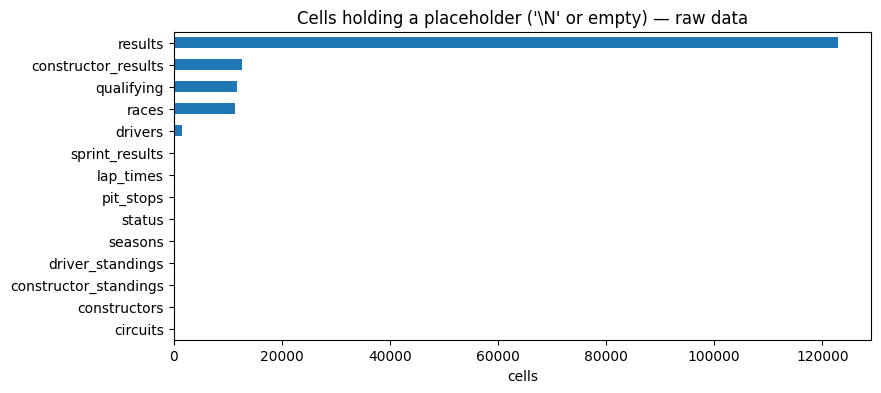

,placeholder cells per column
constructor_results,{'status': 12608}
drivers,"{'number': 802, 'code': 757}"
races,"{'time': 731, 'fp1_date': 1035, 'fp1_time': 10..."
results,"{'number': 6, 'position': 10953, 'time': 19079..."
qualifying,"{'q1': 156, 'q2': 4647, 'q3': 6865}"
sprint_results,"{'position': 15, 'time': 20, 'milliseconds': 2..."


In [3]:
sentinel_before = pd.Series({t: int(df.isin(SENTINELS).sum().sum()) for t, df in raw_tables.items()})
ax = sentinel_before.sort_values().plot(kind="barh", figsize=(9, 4), logx=False)
ax.set(title="Cells holding a placeholder ('\\N' or empty) — raw data", xlabel="cells")
plt.show()

per_col = {t: df.isin(SENTINELS).sum()[lambda s: s > 0].to_dict() for t, df in raw_tables.items()}
pd.Series({t: v for t, v in per_col.items() if v}, name="placeholder cells per column").to_frame()

### 1.2.2 Era profile: season length, field size, podium rate, qualifying coverage

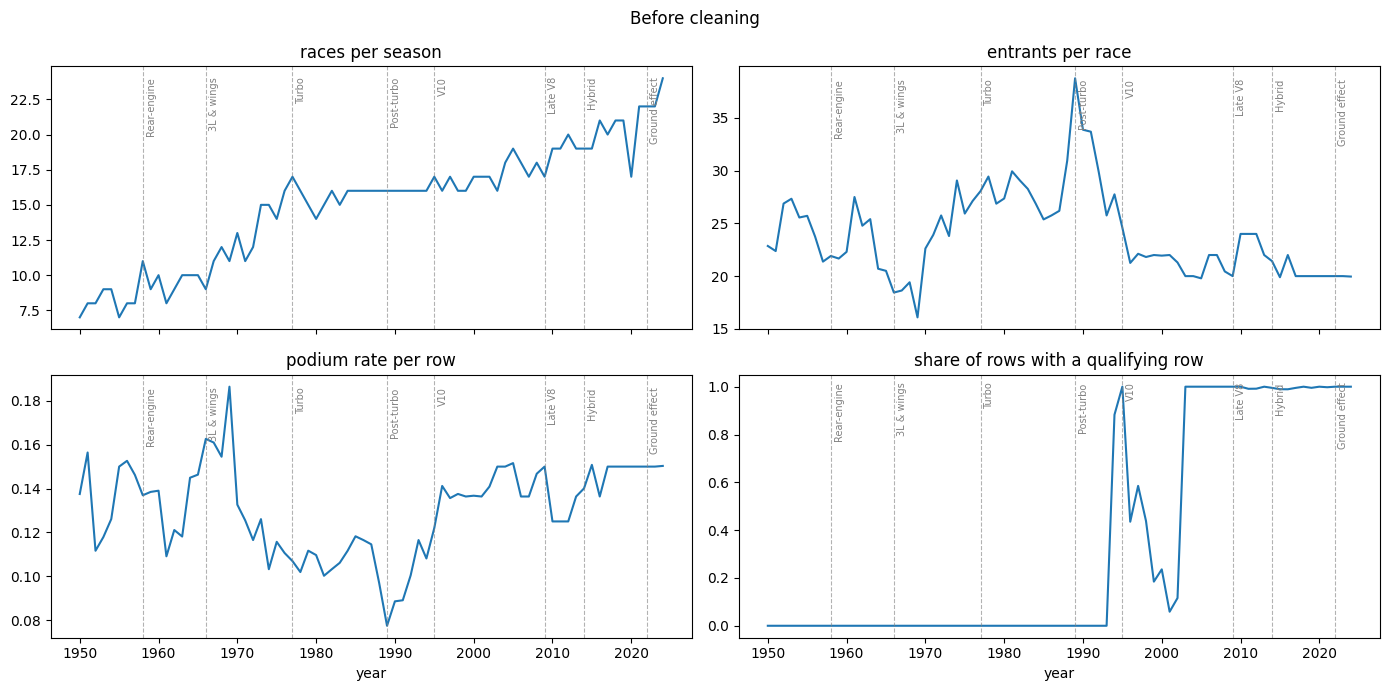

Overall podium rate (raw): 0.130 (mean of seasons)


,races,rows,podium_rate,quali_coverage,rows_per_race
era,,,,,
1950–57,64,1571,0.136,0.000,24.547
1958–65,77,1768,0.131,0.000,22.961
1966–76,139,3237,0.129,0.000,23.288
1977–88,188,5234,0.108,0.000,27.840
1989–94,96,3035,0.095,0.129,31.615
1995–2008,239,5138,0.140,0.652,21.498
2009–13,94,2150,0.131,0.996,22.872
2014–21,160,3267,0.147,0.995,20.419
2022–24,68,1359,0.150,1.000,19.985


In [4]:
def era_profile(tbls, title):
    res = pd.DataFrame({"raceId": pd.to_numeric(tbls["results"]["raceId"]),
                        "driverId": pd.to_numeric(tbls["results"]["driverId"]),
                        "positionOrder": pd.to_numeric(tbls["results"]["positionOrder"])})
    res["year"] = res["raceId"].map(race_year(tbls))
    res["podium"] = (res["positionOrder"] <= 3).astype(int)
    q = pd.DataFrame({"raceId": pd.to_numeric(tbls["qualifying"]["raceId"]),
                      "driverId": pd.to_numeric(tbls["qualifying"]["driverId"])}).drop_duplicates()
    res = res.merge(q.assign(has_quali=1), on=["raceId", "driverId"], how="left")
    res["has_quali"] = res["has_quali"].fillna(0)

    per_race = res.groupby("raceId").agg(year=("year", "first"), n=("driverId", "size"))
    by_year = pd.DataFrame({
        "races per season": per_race.groupby("year").size(),
        "entrants per race": per_race.groupby("year")["n"].mean(),
        "podium rate per row": res.groupby("year")["podium"].mean(),
        "share of rows with a qualifying row": res.groupby("year")["has_quali"].mean(),
    })
    fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
    for ax, col in zip(axes.ravel(), by_year.columns):
        by_year[col].plot(ax=ax); ax.set_title(col); add_eras(ax)
    fig.suptitle(title); plt.tight_layout(); plt.show()

    res["era"] = pd.cut(res["year"], bins=ERA_BINS, labels=ERA_LABELS)
    era = res.groupby("era", observed=True).agg(
        races=("raceId", "nunique"), rows=("raceId", "size"),
        podium_rate=("podium", "mean"), quali_coverage=("has_quali", "mean"))
    era["rows_per_race"] = era["rows"] / era["races"]
    return by_year, era.round(3)

before_year, before_era = era_profile(raw_tables, "Before cleaning")
print(f"Overall podium rate (raw): {before_year['podium rate per row'].mean():.3f} (mean of seasons)")
before_era

### 1.2.3 Duplicate driver–race rows in the raw results

176 rows in 85 duplicated (raceId, driverId) pairs


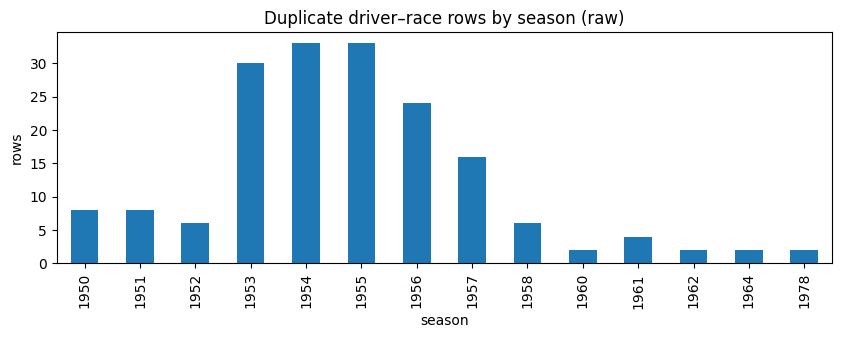

In [5]:
r_raw = raw_tables["results"]
dup_raw = r_raw[r_raw.duplicated(["raceId", "driverId"], keep=False)]
yr = race_year(raw_tables)
print(f"{len(dup_raw)} rows in {dup_raw[['raceId','driverId']].drop_duplicates().shape[0]} duplicated "
      f"(raceId, driverId) pairs")
ax = dup_raw["raceId"].astype(int).map(yr).value_counts().sort_index().plot(kind="bar", figsize=(10, 3))
ax.set(title="Duplicate driver–race rows by season (raw)", xlabel="season", ylabel="rows"); plt.show()

## 1.3 Value cleaning
### 1.3a Races and timing tables

In [6]:
def clean_races(tbls):
    t = "races"; print(f"\n=== {t} ===")
    df, _ = replace_sentinels(tbls[t], t)
    session_cols = [c for c in df.columns if c.split("_")[0] in ("fp1", "fp2", "fp3", "quali", "sprint")]
    note_missing(t, "time", "unknown", "race start time not recorded before 2005")
    note_missing(t, "fp*/quali*/sprint* date & time", "structural",
                 "session schedule only recorded from 2021; empty sprint_* = no sprint that weekend")

    df = to_numeric_cols(df, ["raceId", "year", "round", "circuitId"], t)
    for c in ["date"] + [c for c in session_cols if c.endswith("_date")]:
        df[c] = pd.to_datetime(df[c], errors="coerce")
    for c in ["time"] + [c for c in session_cols if c.endswith("_time")]:
        df[c] = pd.to_timedelta(df[c], errors="coerce")
    tbls[t] = df

    check_pk(df, ["raceId"], t)
    check_pk(df, ["year", "round"], t, kind="natural key")
    check_fk(tbls, t, "circuitId", "circuits")
    check_fk(tbls, t, "year", "seasons")

    rounds = df.groupby("year")["round"].agg(["min", "max", "count", "nunique"])
    date_order = df.sort_values(["year", "round"]).groupby("year")["date"].apply(lambda s: s.is_monotonic_increasing)
    result_ids = pd.to_numeric(tbls["results"]["raceId"], errors="coerce")
    add_checks(t, {
        "date year differs from year column": (df["date"].dt.year != df["year"]).sum(),
        "seasons with gaps/repeats in round numbers":
            ((rounds["min"] != 1) | (rounds["max"] != rounds["count"]) | (rounds["nunique"] != rounds["count"])).sum(),
        "seasons where round order differs from date order": (~date_order).sum(),
        "races with no result rows": (~df["raceId"].isin(result_ids)).sum(),
    })
    # match exact name, not circuit
    print(df[df["name"].str.contains("Indianapolis", case=False, na=False)]
            .groupby("name")["year"].agg(["min", "max", "count"]))
    SHARED["INDY_IDS"] = df.loc[df["name"] == "Indianapolis 500", "raceId"].tolist()

    tag(t, "identifier", ["raceId"], "key")
    tag(t, "pre-race", ["year", "round", "circuitId", "name", "date", "time"] + session_cols,
        "race calendar is known in advance")
    tag(t, "not used", ["url"], "reference link")
    return tbls

def clean_qualifying(tbls):
    t = "qualifying"; print(f"\n=== {t} ===")
    df, _ = replace_sentinels(tbls[t], t)
    df = to_numeric_cols(df, ["qualifyId", "raceId", "driverId", "constructorId", "number", "position"], t)
    for c in ["q1", "q2", "q3"]:
        df[c] = parse_duration(df[c], f"{t}.{c}")
    tbls[t] = df

    year = df["raceId"].map(race_year(tbls))
    era = np.where(year >= 2006, "knockout (2006+)", "before 2006")
    print("Share of missing times by qualifying format:")
    print(df[["q1", "q2", "q3"]].isna().groupby(era).mean().round(3))
    note_missing(t, "q2/q3", "structural",
                 "before 2006 the session did not exist (Q2 only in the 2005 two-session format); "
                 "from 2006 the driver was eliminated earlier")
    note_missing(t, "q3 (top 10, 2006+)", "unknown", "reached Q3 (or Q3 not held) but no lap time")
    note_missing(t, "q1", "unknown", "no time set / not recorded (drivers start from the back)")

    check_pk(df, ["qualifyId"], t)
    check_pk(df, ["raceId", "driverId"], t, kind="grain")
    for col, parent in [("raceId", "races"), ("driverId", "drivers"), ("constructorId", "constructors")]:
        check_fk(tbls, t, col, parent)

    pos = df.groupby("raceId")["position"].agg(["min", "max", "count", "nunique"])
    gap_to_best = df["q1"] / df.groupby("raceId")["q1"].transform("min")
    add_checks(t, {
        "knockout-era top-10 without Q3 time": ((year >= 2006) & (df["position"] <= 10) & df["q3"].isna()).sum(),
        "races with gaps/repeats in qualifying position":
            ((pos["min"] != 1) | (pos["max"] != pos["count"]) | (pos["nunique"] != pos["count"])).sum(),
        "q1 outside 50-200 s": ((df["q1"] < 50) | (df["q1"] > 200)).sum(),
        "q1 more than 50% slower than session best": (gap_to_best > 1.5).sum(),
    })
    ax = gap_to_best.clip(upper=1.15).hist(bins=60, figsize=(9, 3))
    ax.set(title="Q1 time relative to the session's best (1.0 = fastest), clipped at 1.15"); plt.show()

    tag(t, "identifier", ["qualifyId"], "key")
    tag(t, "pre-race", ["raceId", "driverId", "constructorId", "number", "position", "q1", "q2", "q3"],
        "qualifying ends before the prediction cutoff")
    return tbls

def clean_lap_times(tbls):
    t = "lap_times"; print(f"\n=== {t} ===")
    df, _ = replace_sentinels(tbls[t], t)
    note_missing(t, "(whole table)", "structural", "lap-by-lap timing only exists from 1996")
    df = to_numeric_cols(df, ["raceId", "driverId", "lap", "position", "milliseconds"], t)
    df["time"] = parse_duration(df["time"], f"{t}.time")
    tbls[t] = df

    check_pk(df, ["raceId", "driverId", "lap"], t)
    check_fk(tbls, t, "raceId", "races"); check_fk(tbls, t, "driverId", "drivers")
    laps = df.groupby(["raceId", "driverId"])["lap"].agg(["min", "max", "count"])
    race_median = df.groupby("raceId")["time"].transform("median")
    add_checks(t, {
        "parsed time differs from milliseconds by > 0.01 s": ((df["time"] - df["milliseconds"] / 1000).abs() > 0.01).sum(),
        "lap number < 1": (df["lap"] < 1).sum(),
        "driver-races with missing laps": ((laps["min"] != 1) | (laps["max"] != laps["count"])).sum(),
        "non-positive lap time": (df["time"] <= 0).sum(),
        "laps > 3x race median (safety car / red flag, kept)": (df["time"] > 3 * race_median).sum(),
    })
    tag(t, "post-race", list(df.columns), "recorded during the race; usable only from PREVIOUS races")
    return tbls

def clean_pit_stops(tbls):
    t = "pit_stops"; print(f"\n=== {t} ===")
    df, _ = replace_sentinels(tbls[t], t)
    note_missing(t, "(whole table)", "structural", "pit-stop data only exists from 2011")
    df = to_numeric_cols(df, ["raceId", "driverId", "stop", "lap", "milliseconds"], t)
    df["time"] = pd.to_timedelta(df["time"], errors="coerce")
    df["duration"] = parse_duration(df["duration"], f"{t}.duration")
    tbls[t] = df

    check_pk(df, ["raceId", "driverId", "stop"], t)
    check_fk(tbls, t, "raceId", "races"); check_fk(tbls, t, "driverId", "drivers")
    stops = df.groupby(["raceId", "driverId"])["stop"].agg(["min", "max", "count"])
    add_checks(t, {
        "duration differs from milliseconds by > 0.01 s": ((df["duration"] - df["milliseconds"] / 1000).abs() > 0.01).sum(),
        "driver-races with gaps in stop numbers": ((stops["min"] != 1) | (stops["max"] != stops["count"])).sum(),
        "lap < 1": (df["lap"] < 1).sum(),
        "stops longer than 60 s (red flag / repairs, kept)": (df["duration"] > 60).sum(),
    })
    ax = df["duration"].clip(upper=60).hist(bins=60, figsize=(9, 3))
    ax.set(title="Pit-stop duration (s), clipped at 60"); plt.show()
    tag(t, "post-race", list(df.columns), "recorded during the race; usable only from PREVIOUS races")
    return tbls

STANDING_PARENT = {"driverId": "drivers", "constructorId": "constructors"}

def clean_standings(tbls, t, entity, pk):
    print(f"\n=== {t} ===")
    df, _ = replace_sentinels(tbls[t], t)
    df = to_numeric_cols(df, [pk, "raceId", entity, "position", "wins"], t)
    df = to_numeric_cols(df, ["points"], t, kind="float")
    tbls[t] = df

    check_pk(df, [pk], t)
    check_pk(df, ["raceId", entity], t, kind="grain")
    check_fk(tbls, t, "raceId", "races"); check_fk(tbls, t, entity, STANDING_PARENT[entity])

    meta = tbls["races"].set_index("raceId")[["year", "round"]]
    s = df.join(meta, on="raceId").sort_values([entity, "year", "round"])
    g = s.groupby([entity, "year"])
    add_checks(t, {
        "points decrease within a season": (g["points"].diff() < 0).sum(),
        "wins decrease within a season": (g["wins"].diff() < 0).sum(),
        "wins greater than round number": (s["wins"] > s["round"]).sum(),
        "negative points": (s["points"] < 0).sum(),
    })
    odd = s.loc[~s["positionText"].astype(str).str.fullmatch(r"\d+"), "positionText"]
    print("Non-numeric positionText codes:", odd.value_counts().to_dict())

    tag(t, "identifier", [pk], "key")
    tag(t, "post-race", ["points", "position", "positionText", "wins"],
        "standings AFTER this race: shift to the previous round before using as a feature")
    return tbls

def clean_constructor_results(tbls):
    t = "constructor_results"; print(f"\n=== {t} ===")
    df, _ = replace_sentinels(tbls[t], t)
    note_missing(t, "status", "structural", "only filled ('D') when the constructor was disqualified")
    print("status values:", df["status"].value_counts(dropna=False).to_dict())
    df = to_numeric_cols(df, ["constructorResultsId", "raceId", "constructorId"], t)
    df = to_numeric_cols(df, ["points"], t, kind="float")
    tbls[t] = df

    check_pk(df, ["constructorResultsId"], t)
    check_pk(df, ["raceId", "constructorId"], t, kind="grain")
    check_fk(tbls, t, "raceId", "races"); check_fk(tbls, t, "constructorId", "constructors")
    add_checks(t, {"negative points": (df["points"] < 0).sum()})
    tag(t, "identifier", ["constructorResultsId"], "key")
    tag(t, "post-race", ["points", "status"], "this race's constructor points: usable only from PREVIOUS races")
    return tbls

def clean_race_family(tbls):
    tbls = clean_races(tbls)
    tbls = clean_qualifying(tbls)
    tbls = clean_lap_times(tbls)
    tbls = clean_pit_stops(tbls)
    tbls = clean_standings(tbls, "driver_standings", "driverId", "driverStandingsId")
    tbls = clean_standings(tbls, "constructor_standings", "constructorId", "constructorStandingsId")
    tbls = clean_constructor_results(tbls)
    return tbls

### 1.3b Results family and lookup tables

In [7]:
RESULT_INT = ["resultId", "raceId", "driverId", "constructorId", "number", "grid", "position",
              "positionOrder", "laps", "milliseconds", "fastestLap", "rank", "statusId"]

def clean_result_table(tbls, t):
    # results + sprint_results
    print(f"\n=== {t} ===")
    df, _ = replace_sentinels(tbls[t], t)
    df = to_numeric_cols(df, [c for c in RESULT_INT if c in df.columns], t)
    df = to_numeric_cols(df, [c for c in ["points", "fastestLapSpeed"] if c in df.columns], t, kind="float")
    df["fastestLapTime"] = parse_duration(df["fastestLapTime"], f"{t}.fastestLapTime")
    # time kept as text
    tbls[t] = df

    note_missing(t, "position", "structural", "empty when the driver was not classified (positionText is a letter)")
    note_missing(t, "time / milliseconds", "structural", "only recorded for drivers who finished on the lead lap")
    note_missing(t, "fastestLap* / rank", "structural", "fastest-lap data only recorded from 2004")
    if t == "results":
        note_missing(t, "number", "unknown", "car number not recorded for a handful of old entries")

    check_pk(df, ["resultId"], t)
    check_pk(df, ["raceId", "driverId"], t, kind="grain (fixed in Part 4.3)")
    for col, parent in [("raceId", "races"), ("driverId", "drivers"),
                        ("constructorId", "constructors"), ("statusId", "status")]:
        check_fk(tbls, t, col, parent)

    num_text = df["positionText"].str.fullmatch(r"\d+")
    pos_from_text = pd.to_numeric(df["positionText"].where(num_text), errors="coerce")
    per_race = df.groupby("raceId")["positionOrder"].agg(["min", "max", "count", "nunique"])
    add_checks(t, {
        "grid < 0": (df["grid"] < 0).sum(),
        "laps < 0": (df["laps"] < 0).sum(),
        "points < 0": (df["points"] < 0).sum(),
        "positionOrder < 1": (df["positionOrder"] < 1).sum(),
        "races with gaps/repeats in positionOrder (raw)":
            ((per_race["min"] != 1) | (per_race["max"] != per_race["count"]) | (per_race["nunique"] != per_race["count"])).sum(),
        "position null but positionText numeric": (df["position"].isna() & num_text).sum(),
        "position filled but positionText a letter": (df["position"].notna() & ~num_text).sum(),
        "position differs from positionText": (df["position"].notna() & num_text & (df["position"] != pos_from_text)).sum(),
        "classified position differs from positionOrder": (df["position"].notna() & (df["position"] != df["positionOrder"])).sum(),
    })

    tag(t, "identifier", ["resultId", "raceId", "driverId"], "keys")
    if t == "results":
        tag(t, "pre-race", ["constructorId", "number", "grid"], "known once the starting grid is set")
        tag(t, "target", ["positionOrder"], "podium label = positionOrder <= 3; never a feature")
        tag(t, "post-race", ["position", "positionText", "points", "laps", "time", "milliseconds",
                             "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed", "statusId"],
            "outcome of this race: LEAKAGE if used for the same race")
    else:
        tag(t, "pre-race (team decision)", [c for c in df.columns if c not in ("resultId", "raceId", "driverId")],
            "the sprint (2021+) runs BEFORE the main race, so its result is known at the cutoff")
    return tbls

def clean_drivers(tbls):
    t = "drivers"; print(f"\n=== {t} ===")
    df, _ = replace_sentinels(tbls[t], t)
    df = to_numeric_cols(df, ["driverId", "number"], t)
    df["dob"] = pd.to_datetime(df["dob"], errors="coerce")
    tbls[t] = df
    note_missing(t, "number / code", "structural", "permanent numbers (2014) and 3-letter codes only exist for modern drivers")
    check_pk(df, ["driverId"], t)
    add_checks(t, {
        "dob missing or unparseable": df["dob"].isna().sum(),
        "duplicate driverRef": df["driverRef"].duplicated().sum(),
        "same forename + surname + dob under two ids": df.duplicated(["forename", "surname", "dob"]).sum(),
        "nationality missing": df["nationality"].isna().sum(),
    })
    tag(t, "identifier", ["driverId", "driverRef"], "keys")
    tag(t, "pre-race", ["dob", "nationality"], "static driver facts")
    tag(t, "not used", ["number", "code", "forename", "surname", "url"], "labels / links")
    return tbls

def clean_circuits(tbls):
    t = "circuits"; print(f"\n=== {t} ===")
    df, _ = replace_sentinels(tbls[t], t)
    df = to_numeric_cols(df, ["circuitId"], t)
    df = to_numeric_cols(df, ["lat", "lng", "alt"], t, kind="float")
    tbls[t] = df
    check_pk(df, ["circuitId"], t)
    add_checks(t, {
        "duplicate circuitRef": df["circuitRef"].duplicated().sum(),
        "latitude outside [-90, 90]": (~df["lat"].between(-90, 90)).sum(),
        "longitude outside [-180, 180]": (~df["lng"].between(-180, 180)).sum(),
        "country missing": df["country"].isna().sum(),
    })
    tag(t, "identifier", ["circuitId", "circuitRef"], "keys")
    tag(t, "pre-race", ["name", "location", "country", "lat", "lng", "alt"], "static circuit facts")
    tag(t, "not used", ["url"], "reference link")
    return tbls

def clean_constructors(tbls):
    t = "constructors"; print(f"\n=== {t} ===")
    df, _ = replace_sentinels(tbls[t], t)
    df = to_numeric_cols(df, ["constructorId"], t)
    tbls[t] = df
    check_pk(df, ["constructorId"], t)
    add_checks(t, {"duplicate constructorRef": df["constructorRef"].duplicated().sum(),
                   "duplicate name": df["name"].duplicated().sum()})
    tag(t, "identifier", ["constructorId", "constructorRef"], "keys (renamed teams get new ids)")
    tag(t, "pre-race", ["name", "nationality"], "static team facts")
    tag(t, "not used", ["url"], "reference link")
    return tbls

def clean_seasons(tbls):
    t = "seasons"; print(f"\n=== {t} ===")
    df, _ = replace_sentinels(tbls[t], t)
    df = to_numeric_cols(df, ["year"], t)
    tbls[t] = df
    check_pk(df, ["year"], t)
    tag(t, "identifier", ["year"], "key"); tag(t, "not used", ["url"], "reference link")
    return tbls

def clean_status(tbls):
    t = "status"; print(f"\n=== {t} ===")
    df, _ = replace_sentinels(tbls[t], t)
    df = to_numeric_cols(df, ["statusId"], t)
    tbls[t] = df
    check_pk(df, ["statusId"], t)
    add_checks(t, {"duplicate status text": df["status"].duplicated().sum()})
    tag(t, "post-race", ["status"], "why a race ended: post-race (used only for data-engineering Q3)")
    return tbls

def clean_results_family(tbls):
    for f in (clean_drivers, clean_circuits, clean_constructors, clean_seasons, clean_status):
        tbls = f(tbls)
    tbls = clean_result_table(tbls, "results")
    tbls = clean_result_table(tbls, "sprint_results")
    return tbls

### 1.3c Running the value cleaning


=== races ===
Sentinels replaced in races: {'time': 731, 'fp1_date': 1035, 'fp1_time': 1057, 'fp2_date': 1035, 'fp2_time': 1057, 'fp3_date': 1053, 'fp3_time': 1072, 'quali_date': 1035, 'quali_time': 1057, 'sprint_date': 1107, 'sprint_time': 1110}
date year differs from year column                   0
seasons with gaps/repeats in round numbers           0
seasons where round order differs from date order    0
races with no result rows                            0
                   min   max  count
name                               
Indianapolis 500  1950  1960     11

=== qualifying ===
Sentinels replaced in qualifying: {'q1': 156, 'q2': 4647, 'q3': 6865}
Share of missing times by qualifying format:
                     q1     q2    q3
before 2006       0.031  0.959  1.00
knockout (2006+)  0.010  0.272  0.54
knockout-era top-10 without Q3 time               123
races with gaps/repeats in qualifying position      0
q1 outside 50-200 s                                 1
q1 more than 50%

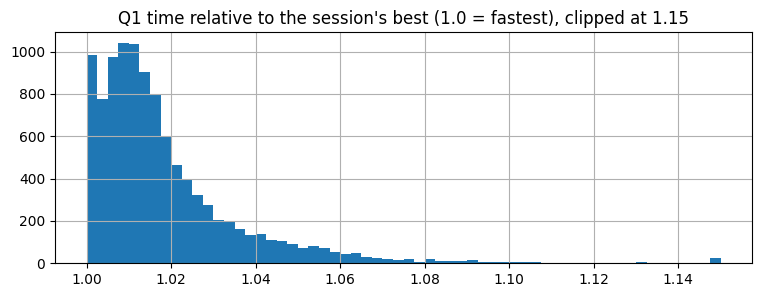


=== lap_times ===
Sentinels replaced in lap_times: none
parsed time differs from milliseconds by > 0.01 s        0
lap number < 1                                           0
driver-races with missing laps                           0
non-positive lap time                                    0
laps > 3x race median (safety car / red flag, kept)    723

=== pit_stops ===
Sentinels replaced in pit_stops: none
duration differs from milliseconds by > 0.01 s         0
driver-races with gaps in stop numbers                 8
lap < 1                                                0
stops longer than 60 s (red flag / repairs, kept)    517


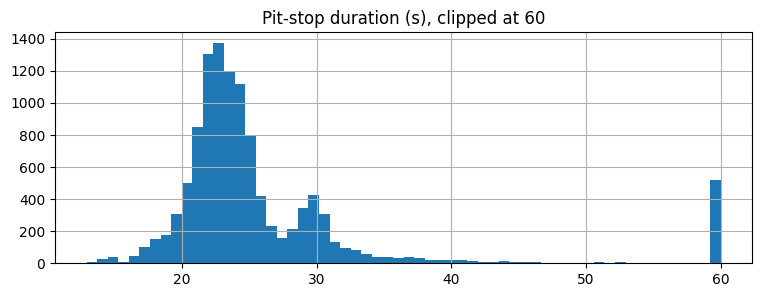


=== driver_standings ===
Sentinels replaced in driver_standings: none
points decrease within a season    0
wins decrease within a season      0
wins greater than round number     0
negative points                    0
Non-numeric positionText codes: {'D': 1}

=== constructor_standings ===
Sentinels replaced in constructor_standings: none
points decrease within a season    2
wins decrease within a season      0
wins greater than round number     0
negative points                    0
Non-numeric positionText codes: {'E': 17}

=== constructor_results ===
Sentinels replaced in constructor_results: {'status': 12608}
status values: {nan: 12608, 'D': 17}
negative points    0

=== drivers ===
Whitespace trimmed in drivers: 1 cells
Sentinels replaced in drivers: {'number': 802, 'code': 757}
dob missing or unparseable                     0
duplicate driverRef                            0
same forename + surname + dob under two ids    0
nationality missing                            0

=== circ

,table,key,kind,rows,null_keys,duplicate_keys
0,races,raceId,primary key,1125,0,0
1,races,year + round,natural key,1125,0,0
2,qualifying,qualifyId,primary key,10494,0,0
3,qualifying,raceId + driverId,grain,10494,0,0
4,lap_times,raceId + driverId + lap,primary key,589081,0,0
5,pit_stops,raceId + driverId + stop,primary key,11371,0,0
6,driver_standings,driverStandingsId,primary key,34863,0,0
7,driver_standings,raceId + driverId,grain,34863,0,0
8,constructor_standings,constructorStandingsId,primary key,13391,0,0
9,constructor_standings,raceId + constructorId,grain,13391,0,0


,child,parent,orphans,null_refs
0,races.circuitId,circuits.circuitId,0,0
1,races.year,seasons.year,0,0
2,qualifying.raceId,races.raceId,0,0
3,qualifying.driverId,drivers.driverId,0,0
4,qualifying.constructorId,constructors.constructorId,0,0
5,lap_times.raceId,races.raceId,0,0
6,lap_times.driverId,drivers.driverId,0,0
7,pit_stops.raceId,races.raceId,0,0
8,pit_stops.driverId,drivers.driverId,0,0
9,driver_standings.raceId,races.raceId,0,0


In [8]:
reset_reports()
tables = {t: df.copy() for t, df in raw_tables.items()}
tables = clean_race_family(tables)
tables = clean_results_family(tables)

value_clean = {t: df.copy() for t, df in tables.items()}   # snapshot before row removal

# exact duplicates and repeated keys
for t in TABLE_NAMES:
    before = len(tables[t])
    tables[t] = tables[t].drop_duplicates().reset_index(drop=True)
    if len(tables[t]) != before:
        log_step("0_exact_duplicates", t, before, len(tables[t]), "fully identical rows")
for t, key in {"lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"]}.items():
    before = len(tables[t])
    tables[t] = tables[t].drop_duplicates(key, keep="first").reset_index(drop=True)
    if len(tables[t]) != before:
        log_step("0_key_duplicates", t, before, len(tables[t]), f"repeated {' + '.join(key)}: first record kept")
print("Duplicate records removed:", pd.DataFrame(cleaning_log).to_dict("records") if cleaning_log else "none")

pk_df, fk_df = pd.DataFrame(pk_reports), pd.DataFrame(fk_reports)
print(f"\nPrimary keys checked: {len(pk_df)} | foreign keys checked: {len(fk_df)} | "
      f"orphans found: {int(fk_df['orphans'].sum())}")
display(pk_df)
display(fk_df)

## 1.4 Row cleaning

### 1.4.1 Exclude the Indianapolis 500 from every table

In [9]:
tables = drop_races(tables, SHARED["INDY_IDS"], "1_indy500", "Indianapolis 500 excluded")
print("Indianapolis 500 races removed:", len(SHARED["INDY_IDS"]))
display(pd.DataFrame(cleaning_log))

Indianapolis 500 races removed: 11


,step,table,rows_before,rows_after,removed,reason
0,1_indy500,constructor_results,12625,12604,21,Indianapolis 500 excluded
1,1_indy500,constructor_standings,13391,13365,26,Indianapolis 500 excluded
2,1_indy500,driver_standings,34863,34194,669,Indianapolis 500 excluded
3,1_indy500,races,1125,1114,11,Indianapolis 500 excluded
4,1_indy500,results,26759,26354,405,Indianapolis 500 excluded


### 1.4.2 Remove non-starters (did not qualify / pre-qualify / withdrew)

In [10]:
res = tables["results"]
status_name = res["statusId"].map(tables["status"].set_index("statusId")["status"])
year = res["raceId"].map(race_year(tables))
grid0 = res["grid"] == 0

print("Share of rows with grid = 0 by decade:")
print(grid0.groupby((year // 10) * 10).mean().mul(100).round(1).rename("% grid 0").to_frame().T)
print("\nStatus of grid = 0 rows:"); print(status_name[grid0].value_counts().head(12))
print("\npositionText of grid = 0 rows:"); print(res.loc[grid0, "positionText"].value_counts().head(8))

cand = tables["status"][tables["status"]["status"].str.contains("qualif|withdr|107", case=False)]
print("\nCandidate non-starter statuses (searched in the data, not typed by hand):")
print(cand.assign(rows=cand["statusId"].map(res["statusId"].value_counts()).fillna(0).astype(int)))

Share of rows with grid = 0 by decade:
raceId    1950  1960  1970  1980  1990  2000  2010  2020
% grid 0   4.2   9.5   9.2  12.7   8.4   0.2   0.7   2.7

Status of grid = 0 rows:
statusId
Did not qualify       1013
Did not prequalify     331
Withdrew               164
+1 Lap                  27
Finished                22
Accident                20
Injury                   8
+2 Laps                  7
Engine                   6
Excluded                 6
Disqualified             6
Retired                  3
Name: count, dtype: int64

positionText of grid = 0 rows:
positionText
F     1348
W      203
R       14
17       9
13       7
E        7
10       7
D        6
Name: count, dtype: int64

Candidate non-starter statuses (searched in the data, not typed by hand):
    statusId              status  rows
1          2        Disqualified   146
53        54            Withdrew   248
76        77           107% Rule     9
80        81     Did not qualify  1025
96        97  Did not prequalify 

In [11]:
NON_START_STATUSES = ["Did not qualify", "Did not prequalify", "Withdrew", "107% Rule"]
NON_START_CODES = ["F", "W"]          # F = failed to qualify, W = withdrawn

def drop_non_starters(tbls):
    r = tbls["results"]
    ids = tbls["status"].loc[tbls["status"]["status"].isin(NON_START_STATUSES), "statusId"]
    mask = r["statusId"].isin(ids) | r["positionText"].isin(NON_START_CODES)
    print("Non-starter rows by grid value (teammate's rule also required grid = 0):")
    print(pd.crosstab(mask.rename("non-starter"), (r["grid"] == 0).rename("grid = 0")))
    before, rate_before = len(r), (r["positionOrder"] <= 3).mean()
    tbls["results"] = r[~mask].reset_index(drop=True)
    log_step("2_non_starters", "results", before, len(tbls["results"]),
             "did not qualify / did not pre-qualify / 107% rule / withdrew")
    print(f"\nRemoved {int(mask.sum())} rows | podium rate per row {rate_before:.4f} -> "
          f"{(tbls['results']['positionOrder'] <= 3).mean():.4f}")
    return tbls

tables = drop_non_starters(tables)

Non-starter rows by grid value (teammate's rule also required grid = 0):
grid = 0     False  True 
non-starter              
False        24543     87
True           173   1551

Removed 1724 rows | podium rate per row 0.1275 -> 0.1365


### 1.4.3 Fix the grain: exactly one row per (raceId, driverId)

In [12]:
r = tables["results"]
dups = r[r.duplicated(["raceId", "driverId"], keep=False)].copy()
dups["year"] = dups["raceId"].map(race_year(tables))
print(f"{len(dups)} rows in {dups[['raceId','driverId']].drop_duplicates().shape[0]} pairs; "
      f"seasons {dups['year'].min()}–{dups['year'].max()}")
print("rows per pair:", dups.groupby(["raceId", "driverId"]).size().value_counts().to_dict())

# compare both rules
def keep_started_car(df):
    # started car first, then grid, then resultId
    s = df.assign(_no_grid=df["grid"].eq(0)).sort_values(["raceId", "driverId", "_no_grid", "grid", "resultId"])
    return s.drop_duplicates(["raceId", "driverId"], keep="first").drop(columns="_no_grid")

def keep_best_finish(df):
    s = df.sort_values(["raceId", "driverId", "positionOrder", "resultId"])
    return s.drop_duplicates(["raceId", "driverId"], keep="first")

a = keep_started_car(dups).set_index(["raceId", "driverId"])
b = keep_best_finish(dups).set_index(["raceId", "driverId"])
conflict = dups.assign(p=dups["positionOrder"] <= 3).groupby(["raceId", "driverId"])["p"].nunique() > 1
print(f"pairs where the two rules keep different rows: {(a['resultId'] != b['resultId']).sum()}")
print(f"pairs where the podium label depends on the rule: {int(conflict.sum())}")
print(f"podium rate among kept rows: started-car rule {(a['positionOrder'] <= 3).mean():.3f} | "
      f"best-finish rule {(b['positionOrder'] <= 3).mean():.3f}")
dups.sort_values(["raceId", "driverId"])[["year", "raceId", "driverId", "constructorId", "number",
                                           "grid", "positionOrder", "points", "laps", "statusId"]].head(12)

125 rows in 61 pairs; seasons 1950–1964
rows per pair: {2: 58, 3: 3}
pairs where the two rules keep different rows: 44
pairs where the podium label depends on the rule: 20
podium rate among kept rows: started-car rule 0.066 | best-finish rule 0.344


,year,raceId,driverId,constructorId,number,grid,positionOrder,points,laps,statusId
15928,1964,717,373,172,1,1,7,0.0,102,60
22184,1964,717,373,172,2,1,12,0.0,54,98
16409,1961,742,475,102,26,20,19,0.0,56,2
16411,1961,742,475,172,28,5,21,0.0,44,23
16495,1961,745,418,172,22,11,17,0.0,23,6
22183,1961,745,418,172,21,15,11,0.0,92,18
16514,1960,746,475,170,36,1,17,0.0,40,22
18214,1960,746,475,170,38,8,3,0.0,80,1
16893,1958,770,479,118,10,5,18,0.0,16,5
18212,1958,770,479,118,12,10,14,0.0,35,5


In [13]:
def fix_grain(tbls):
    r = tbls["results"]
    before = len(r)
    kept = keep_started_car(r).sort_values("resultId").reset_index(drop=True)
    SHARED["dropped_duplicates"] = r[~r["resultId"].isin(kept["resultId"])]
    tbls["results"] = kept
    log_step("3_grain", "results", before, len(kept), "duplicate (raceId, driverId): keep the started car")
    assert not kept.duplicated(["raceId", "driverId"]).any(), "grain still broken"
    for t in ["qualifying", "sprint_results", "driver_standings"]:
        assert not tbls[t].duplicated(["raceId", "driverId"]).any(), f"{t} grain broken"
    print(f"Removed {before - len(kept)} duplicate rows; (raceId, driverId) is now unique in results, "
          "qualifying, sprint_results and driver_standings.")
    return tbls

tables = fix_grain(tables)

Removed 64 duplicate rows; (raceId, driverId) is now unique in results, qualifying, sprint_results and driver_standings.


### 1.4.4 Fix the `position` / `positionText` inconsistency

In [14]:
for t in ["results", "sprint_results"]:
    df = tables[t]
    num_text = df["positionText"].str.fullmatch(r"\d+")
    fix = df["position"].isna() & num_text
    if fix.any():
        display(df.loc[fix, ["raceId", "driverId", "grid", "position", "positionText", "positionOrder", "statusId"]])
    df.loc[fix, "position"] = pd.to_numeric(df.loc[fix, "positionText"]).astype("Int64")
    print(f"{t}: filled position from positionText in {int(fix.sum())} rows")
    assert ((df["position"].isna()) == (~num_text)).all(), f"{t}: position/positionText still inconsistent"

,raceId,driverId,grid,position,positionText,positionOrder,statusId
1148,71,18,8,<NA>,11,11,11
1151,71,11,20,<NA>,14,14,12


results: filled position from positionText in 2 rows
sprint_results: filled position from positionText in 0 rows


### 1.4.5 Nationality → country mapping

In [15]:
print("Driver nationalities:", sorted(tables["drivers"]["nationality"].dropna().unique()))
print("\nCircuit countries:", sorted(tables["circuits"]["country"].dropna().unique()))

Driver nationalities: ['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Argentinian', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Uruguayan', 'Venezuelan']

Circuit countries: ['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA', 'United States']


In [16]:
US, UK = ["USA", "United States"], ["UK", "United Kingdom"]
NAT_TO_COUNTRY = {
    "American": US, "American-Italian": US + ["Italy"], "Argentine": ["Argentina"],
    "Argentine-Italian": ["Argentina", "Italy"], "Argentinian": ["Argentina"], "Australian": ["Australia"],
    "Austrian": ["Austria"], "Belgian": ["Belgium"], "Brazilian": ["Brazil"], "British": UK,
    "Canadian": ["Canada"], "Chilean": ["Chile"], "Chinese": ["China"], "Colombian": ["Colombia"],
    "Czech": ["Czech Republic"], "Danish": ["Denmark"], "Dutch": ["Netherlands"],
    "East German": ["Germany"], "Finnish": ["Finland"], "French": ["France"], "German": ["Germany"],
    "Hungarian": ["Hungary"], "Indian": ["India"], "Indonesian": ["Indonesia"], "Irish": ["Ireland"],
    "Italian": ["Italy"], "Japanese": ["Japan"], "Liechtensteiner": ["Liechtenstein"],
    "Malaysian": ["Malaysia"], "Mexican": ["Mexico"], "Monegasque": ["Monaco"],
    "New Zealander": ["New Zealand"], "Polish": ["Poland"], "Portuguese": ["Portugal"],
    "Rhodesian": ["Rhodesia"], "Russian": ["Russia"], "South African": ["South Africa"],
    "Spanish": ["Spain"], "Swedish": ["Sweden"], "Swiss": ["Switzerland"], "Thai": ["Thailand"],
    "Uruguayan": ["Uruguay"], "Venezuelan": ["Venezuela"], "Chinese Taipei": ["Taiwan"],
}

def build_nationality_map(tbls):
    m = pd.Series(NAT_TO_COUNTRY, name="country").explode().rename_axis("nationality").reset_index()
    nats = set(tbls["drivers"]["nationality"].dropna())
    countries = set(tbls["circuits"]["country"].dropna())
    m = m[m["nationality"].isin(nats)]
    m["hosted_a_race"] = m["country"].isin(countries)
    unmapped = sorted(nats - set(m["nationality"]))
    if unmapped:
        print("WARNING: nationalities with no mapping (add them to NAT_TO_COUNTRY):", unmapped)
    else:
        print("Every driver nationality is mapped.")
    never = sorted(set(m.loc[~m["hosted_a_race"], "country"]))
    print("Mapped countries that never hosted a race (no home race possible):", never)
    hosts_without_nat = sorted(countries - set(m["country"]))
    print("Host countries with no driver nationality mapped to them:", hosts_without_nat)
    return m.reset_index(drop=True)

tables["nationality_country"] = build_nationality_map(tables)
tables["nationality_country"].head(10)

Every driver nationality is mapped.
Mapped countries that never hosted a race (no home race possible): ['Chile', 'Colombia', 'Czech Republic', 'Denmark', 'Finland', 'Indonesia', 'Ireland', 'Liechtenstein', 'New Zealand', 'Poland', 'Rhodesia', 'Thailand', 'United Kingdom', 'Uruguay', 'Venezuela']
Host countries with no driver nationality mapped to them: ['Azerbaijan', 'Bahrain', 'Korea', 'Morocco', 'Qatar', 'Saudi Arabia', 'Singapore', 'Turkey', 'UAE']


,nationality,country,hosted_a_race
0,American,USA,True
1,American,United States,True
2,American-Italian,USA,True
3,American-Italian,United States,True
4,American-Italian,Italy,True
5,Argentine,Argentina,True
6,Argentine-Italian,Argentina,True
7,Argentine-Italian,Italy,True
8,Argentinian,Argentina,True
9,Australian,Australia,True


## 1.5 Post-cleaning validation and investigation

### 1.5.1 Target integrity: podium rows per race

In [17]:
r = tables["results"]
pod = (r["positionOrder"] <= 3).groupby(r["raceId"]).sum()
bad = pod[pod != 3].rename("podium_rows").to_frame().join(race_year(tables).rename("year"))
print(f"Races without exactly 3 podium rows: {len(bad)} of {r['raceId'].nunique()}")
if len(bad):
    print(bad["podium_rows"].value_counts().to_dict(), "| seasons:", sorted(bad["year"].unique()))
bad.head(10)

Races without exactly 3 podium rows: 5 of 1114
{np.int64(2): 3, np.int64(5): 1, np.int64(4): 1} | seasons: [np.int64(1951), np.int64(1955), np.int64(1956), np.int64(1957)]


,podium_rows,year
raceId,,
780,2,1957
789,2,1956
792,5,1955
793,4,1955
828,2,1951


### 1.5.2 Grid vs qualifying position

Rows with both values: 10340 | grid differs from qualifying: 23.3% | further back: 5.1% | further forward: 18.2%


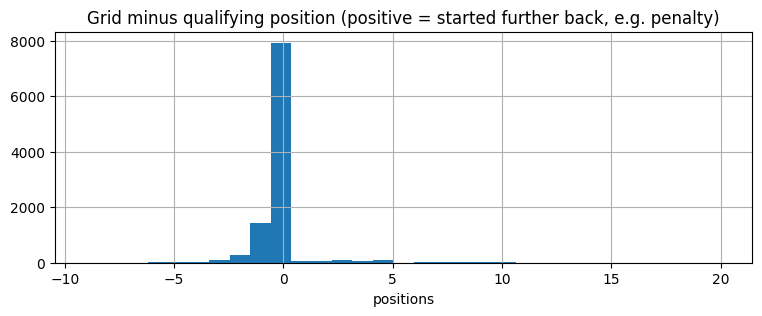

In [18]:
q = tables["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "quali_pos"})
qg = tables["results"].merge(q, on=["raceId", "driverId"], how="inner")
qg = qg[qg["grid"] > 0]
diff = (qg["grid"] - qg["quali_pos"]).astype(float)
print(f"Rows with both values: {len(qg)} | grid differs from qualifying: {(diff != 0).mean():.1%} "
      f"| further back: {(diff > 0).mean():.1%} | further forward: {(diff < 0).mean():.1%}")
ax = diff.clip(-10, 20).hist(bins=31, figsize=(9, 3))
ax.set(title="Grid minus qualifying position (positive = started further back, e.g. penalty)", xlabel="positions")
plt.show()

### 1.5.3 Remaining grid = 0 rows and driver age

In [19]:
r = tables["results"]
g0 = r[r["grid"] == 0]
st = g0["statusId"].map(tables["status"].set_index("statusId")["status"])
yr = g0["raceId"].map(race_year(tables))
print(f"grid = 0 rows kept: {len(g0)} | from 2000 onward: {(yr >= 2000).sum()}")
print("Most common statuses:", st.value_counts().head(6).to_dict())

age = (r[["raceId", "driverId"]]
       .merge(tables["races"][["raceId", "date"]], on="raceId")
       .merge(tables["drivers"][["driverId", "dob"]], on="driverId"))
age = (age["date"] - age["dob"]).dt.days / 365.25
add_checks("results (final)", {"driver age < 17": (age < 17).sum(), "driver age > 60": (age > 60).sum(),
                               "driver age missing": age.isna().sum()})
print(f"Age range: {age.min():.1f}–{age.max():.1f} years")

grid = 0 rows kept: 87 | from 2000 onward: 73
Most common statuses: {'+1 Lap': 27, 'Finished': 22, '+2 Laps': 7, 'Excluded': 6, 'Disqualified': 6, 'Collision damage': 3}
driver age < 17       0
driver age > 60       0
driver age missing    0
Age range: 17.5–55.8 years


### 1.5.4 Qualifying findings

In [20]:
q = tables["qualifying"].merge(tables["races"][["raceId", "year", "name"]], on="raceId")
print("Seasons before 2006 with a Q2 time:", q.loc[(q["year"] < 2006) & q["q2"].notna(), "year"].value_counts().sort_index().to_dict())

miss_q3 = q[(q["year"] >= 2006) & (q["position"] <= 10) & q["q3"].isna()]
per_race = miss_q3.groupby(["year", "name"]).size()
print(f"Top-10 qualifiers without a Q3 time: {len(miss_q3)} | in races where Q3 had (almost) no times: "
      f"{int(per_race[per_race >= 8].sum())} rows in {int((per_race >= 8).sum())} races")

# extreme Q1 times
quali = tables["qualifying"]
best = quali.groupby("raceId")["q1"].transform("min")
bad_q1 = (quali["q1"] / best > 1.5) | (quali["q1"] < 50) | (quali["q1"] > 200)
print("\nExtreme Q1 times (before the fix):")
display(q.loc[bad_q1.values, ["year", "name", "driverId", "position", "q1"]])

quali.loc[bad_q1, "q1"] = np.nan
tables["qualifying"] = quali
log_step("4_bad_q1", "qualifying", len(quali), len(quali),
         f"{int(bad_q1.sum())} impossible Q1 time(s) set to NaN (row kept)")

best = tables["qualifying"].groupby("raceId")["q1"].transform("min")
print("Extreme Q1 times left after the fix:", int((tables["qualifying"]["q1"] / best > 1.5).sum()))

Seasons before 2006 with a Q2 time: {np.int64(2005): 107}
Top-10 qualifiers without a Q3 time: 123 | in races where Q3 had (almost) no times: 10 rows in 1 races

Extreme Q1 times (before the fix):


,year,name,driverId,position,q1
2567,1995,Japanese Grand Prix,87,24,1002.64


Extreme Q1 times left after the fix: 0


### 1.5.5 Pit-stop gaps and standings codes

In [21]:
ps = tables["pit_stops"].copy()
g = ps.groupby(["raceId", "driverId"])["stop"].agg(["min", "max", "count"])
gaps = g[(g["min"] != 1) | (g["max"] != g["count"])].join(race_year(tables).rename("year"), on="raceId")
print(f"Driver-races with gaps in stop numbers (before the fix): {len(gaps)}")
display(gaps)

# renumber stops by lap
grp = ps.groupby(["raceId", "driverId"])["stop"]
wrong = (grp.transform("min") == 1) & (grp.transform("max") > grp.transform("count"))
new_stop = ps[wrong].sort_values(["raceId", "driverId", "lap"]).groupby(["raceId", "driverId"]).cumcount() + 1
ps.loc[new_stop.index, "stop"] = new_stop.astype("Int64")
tables["pit_stops"] = ps
assert not ps.duplicated(["raceId", "driverId", "stop"]).any(), "renumbering created duplicate keys"
n_fixed = ps.loc[wrong, ["raceId", "driverId"]].drop_duplicates().shape[0]
log_step("4_pit_stop_numbers", "pit_stops", len(ps), len(ps),
         f"stop numbers renumbered by lap order in {n_fixed} driver-races (row count unchanged)")

g2 = ps.groupby(["raceId", "driverId"])["stop"].agg(["min", "max", "count"])
left = g2[(g2["min"] != 1) | (g2["max"] != g2["count"])].join(race_year(tables).rename("year"), on="raceId")
print(f"Renumbered: {n_fixed} driver-races | gaps left (first stop missing, kept): {len(left)}")
display(left)

# standings codes
cons = tables["constructors"].set_index("constructorId")["name"]
drv = tables["drivers"].set_index("driverId")[["forename", "surname"]].agg(" ".join, axis=1)
ry = race_year(tables)
cs, cr, ds = tables["constructor_standings"], tables["constructor_results"], tables["driver_standings"]
print("Constructor standings with code E:",
      cs.loc[cs["positionText"] == "E"].assign(team=lambda d: d["constructorId"].map(cons), year=lambda d: d["raceId"].map(ry))
        [["year", "team"]].value_counts().to_dict())
print("Constructor results with status D:",
      cr.loc[cr["status"] == "D"].assign(team=lambda d: d["constructorId"].map(cons), year=lambda d: d["raceId"].map(ry))
        [["year", "team"]].value_counts().to_dict())
print("Driver standings with code D:",
      ds.loc[ds["positionText"] == "D"].assign(driver=lambda d: d["driverId"].map(drv), year=lambda d: d["raceId"].map(ry))
        [["year", "driver"]].value_counts().to_dict())

Driver-races with gaps in stop numbers (before the fix): 8


min  max  count  year
raceId driverId                       
908    820         2    3      2  2014
1024   832         2    2      1  2019
1128   1           1   51      2  2024
       822         1   15      2  2024
       830         1   52      2  2024
       840         1   48      3  2024
       855         1   70      2  2024
       858         1   57      2  2024

Renumbered: 6 driver-races | gaps left (first stop missing, kept): 2


,,min,max,count,year
raceId,driverId,,,,
908,820,2,3,2,2014
1024,832,2,2,1,2019


Constructor standings with code E: {(2007, 'McLaren'): 17}
Constructor results with status D: {(2007, 'McLaren'): 17}
Driver standings with code D: {(1997, 'Michael Schumacher'): 1}


## 1.6 After-cleaning EDA

### 1.6.1 Cleaning funnel

,step,table,rows_before,rows_after,removed,reason
0,1_indy500,constructor_results,12625,12604,21,Indianapolis 500 excluded
1,1_indy500,constructor_standings,13391,13365,26,Indianapolis 500 excluded
2,1_indy500,driver_standings,34863,34194,669,Indianapolis 500 excluded
3,1_indy500,races,1125,1114,11,Indianapolis 500 excluded
4,1_indy500,results,26759,26354,405,Indianapolis 500 excluded
5,2_non_starters,results,26354,24630,1724,did not qualify / did not pre-qualify / 107% r...
6,3_grain,results,24630,24566,64,"duplicate (raceId, driverId): keep the started..."
7,4_bad_q1,qualifying,10494,10494,0,1 impossible Q1 time(s) set to NaN (row kept)
8,4_pit_stop_numbers,pit_stops,11371,11371,0,stop numbers renumbered by lap order in 6 driv...


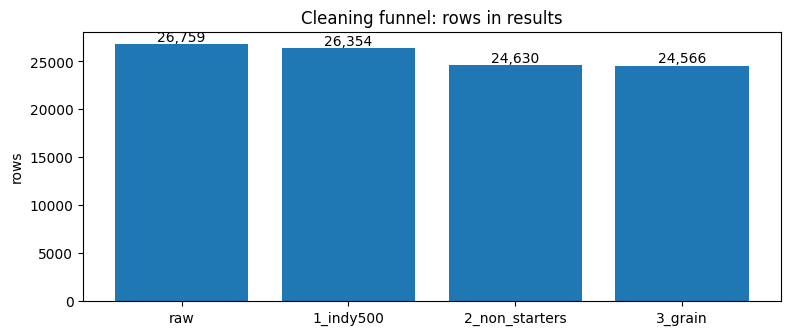

In [22]:
funnel = pd.DataFrame(cleaning_log)
display(funnel)
res_steps = funnel[funnel["table"] == "results"]
counts = [len(raw_tables["results"])] + res_steps["rows_after"].tolist()
labels = ["raw"] + res_steps["step"].tolist()
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(labels, counts)
for i, c in enumerate(counts):
    ax.text(i, c, f"{c:,}", ha="center", va="bottom")
ax.set(title="Cleaning funnel: rows in results", ylabel="rows"); plt.show()

### 1.6.2 Era profile before vs after

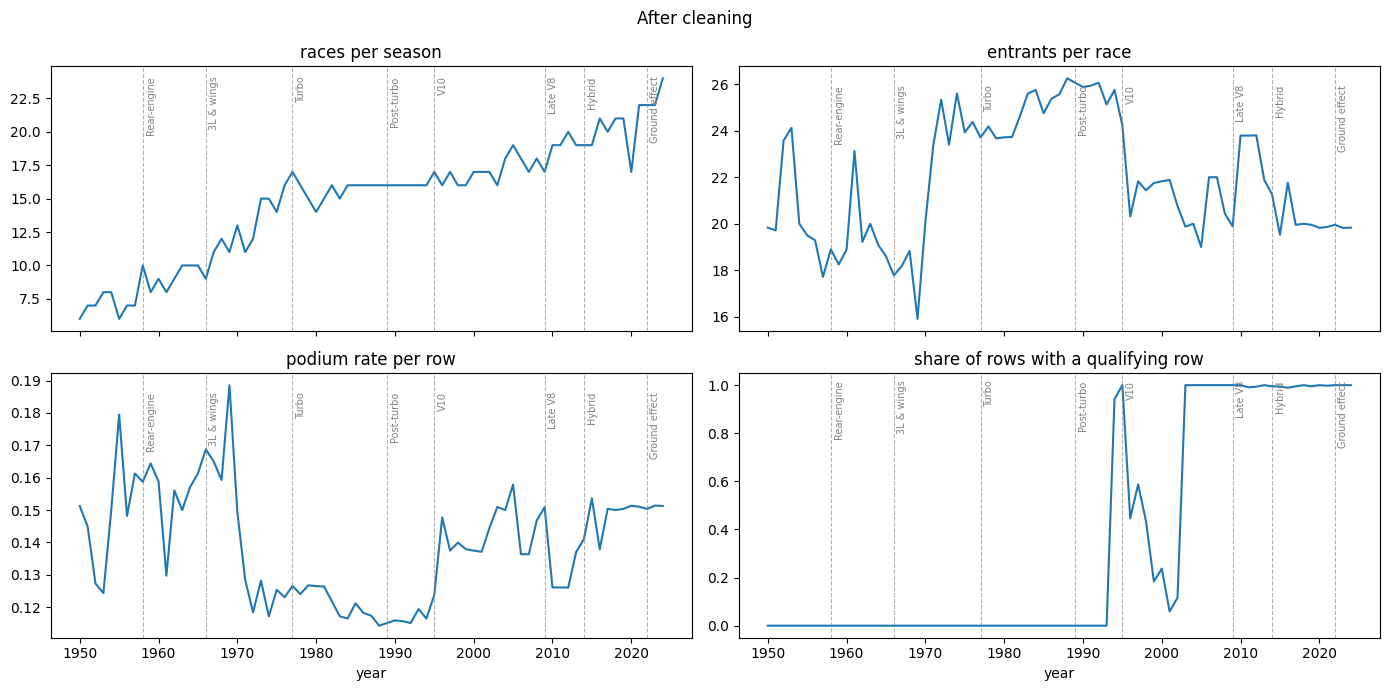

,races_before,rows_before,podium_rate_before,quali_coverage_before,rows_per_race_before,races_after,rows_after,podium_rate_after,quali_coverage_after,rows_per_race_after
era,,,,,,,,,,
1950–57,64,1571,0.136,0.000,24.547,56,1151,0.146,0.000,20.554
1958–65,77,1768,0.131,0.000,22.961,74,1440,0.154,0.000,19.459
1966–76,139,3237,0.129,0.000,23.288,139,3043,0.137,0.000,21.892
1977–88,188,5234,0.108,0.000,27.840,188,4654,0.121,0.000,24.755
1989–94,96,3035,0.095,0.129,31.615,96,2477,0.116,0.157,25.802
1995–2008,239,5138,0.140,0.652,21.498,239,5072,0.141,0.654,21.222
2009–13,94,2150,0.131,0.996,22.872,94,2134,0.132,0.997,22.702
2014–21,160,3267,0.147,0.995,20.419,160,3244,0.148,0.996,20.275
2022–24,68,1359,0.150,1.000,19.985,68,1351,0.151,1.000,19.868


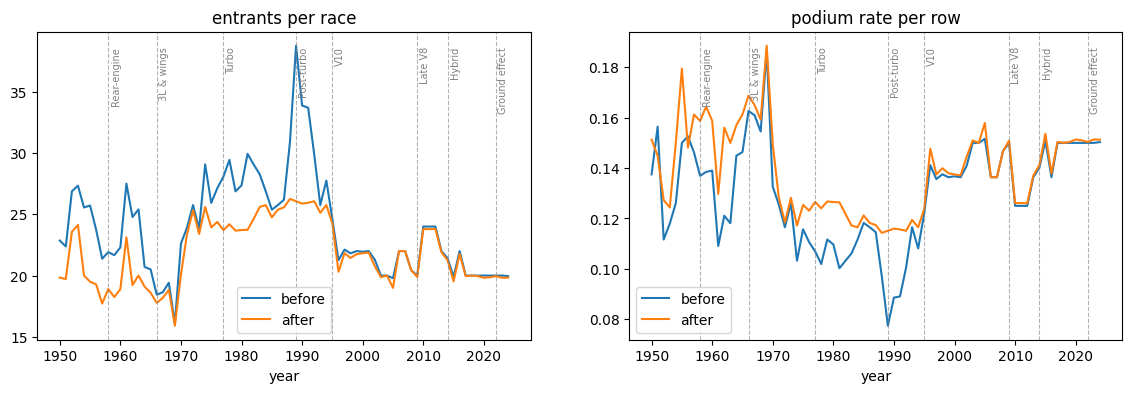

In [23]:
after_year, after_era = era_profile(tables, "After cleaning")
display(before_era.join(after_era, lsuffix="_before", rsuffix="_after"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ["entrants per race", "podium rate per row"]):
    before_year[col].plot(ax=ax, label="before"); after_year[col].plot(ax=ax, label="after")
    ax.set_title(col); ax.legend(); add_eras(ax)
plt.show()

### 1.6.3 Data coverage by table and season

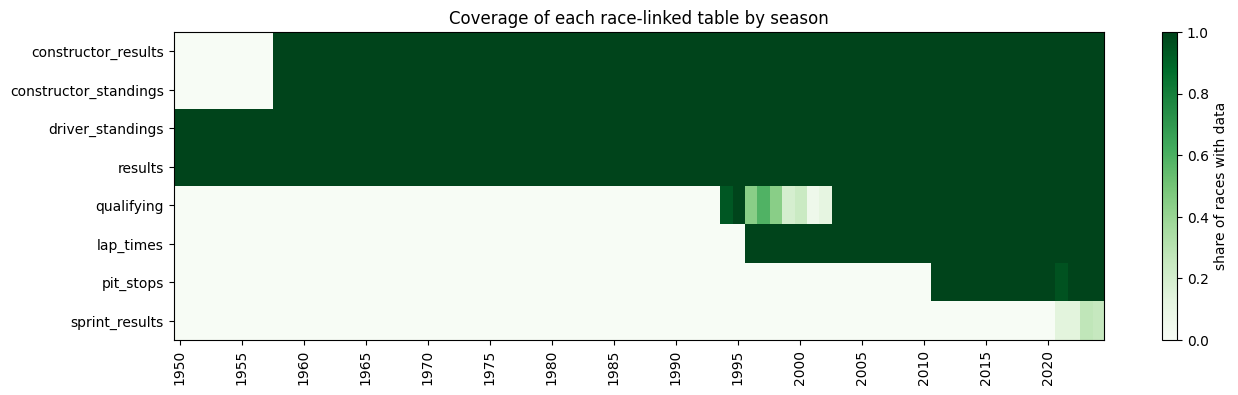

,first season,first season >= 90%
results,1950,1950.0
driver_standings,1950,1950.0
constructor_standings,1958,1958.0
constructor_results,1958,1958.0
qualifying,1994,1994.0
lap_times,1996,1996.0
pit_stops,2011,2011.0
sprint_results,2021,NaN


In [24]:
def coverage_by_season(tbls):
    ry = tbls["races"][["raceId", "year"]]
    cov = {}
    for name, df in tbls.items():
        if "raceId" in df.columns and name != "races":
            has = ry["raceId"].isin(df["raceId"].dropna().unique()).astype(float)
            cov[name] = has.groupby(ry["year"].astype(int)).mean()
    return pd.DataFrame(cov).T.astype(float)

cov = coverage_by_season(tables)
fig, ax = plt.subplots(figsize=(15, 4))
im = ax.imshow(cov.to_numpy(dtype=float), aspect="auto", cmap="Greens", vmin=0, vmax=1)
ax.set_yticks(range(len(cov))); ax.set_yticklabels(cov.index)
xt = list(range(0, cov.shape[1], 5))
ax.set_xticks(xt); ax.set_xticklabels(cov.columns[xt], rotation=90)
plt.colorbar(im, label="share of races with data"); ax.set_title("Coverage of each race-linked table by season")
plt.show()

first = pd.Series({t: cov.columns[cov.loc[t] > 0].min() for t in cov.index}, name="first season").sort_values()
full = pd.Series({t: cov.columns[cov.loc[t] >= 0.9].min() for t in cov.index}, name="first season >= 90%")
pd.concat([first, full], axis=1)

### 1.6.4 Before vs after, per table

,rows_raw,rows_clean,placeholders_raw,nan_after_typing,text_cols_raw,text_cols_clean
table,,,,,,
circuits,77,77,0,0,9,5
constructors,212,212,0,0,5,4
constructor_results,12625,12604,12608,12608,5,1
constructor_standings,13391,13365,0,0,7,1
drivers,861,861,1559,1559,9,6
driver_standings,34863,34194,0,0,7,1
races,1125,1114,11349,11349,18,2
results,26759,24566,122887,122887,18,2
qualifying,10494,10494,11668,11668,9,0


Tables where NaN after typing != placeholders before: none


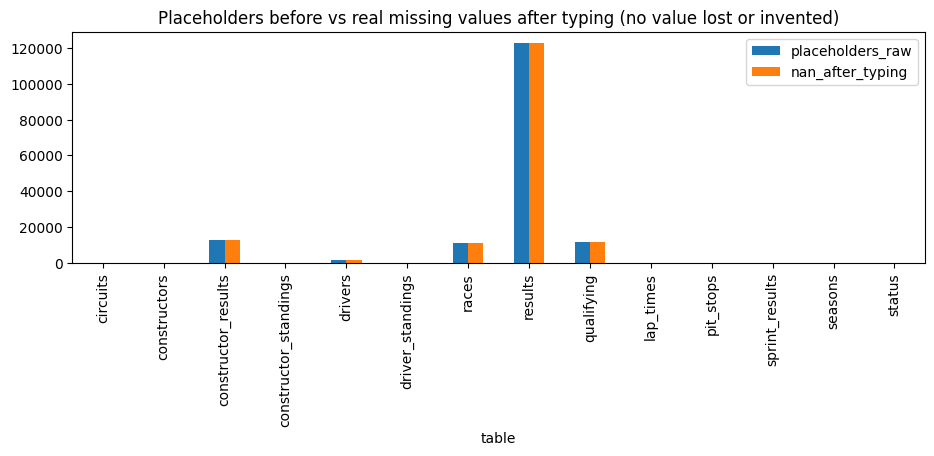

In [25]:
rows = []
for t in TABLE_NAMES:
    r, v, c = raw_tables[t], value_clean[t], tables[t]
    rows.append(dict(table=t, rows_raw=len(r), rows_clean=len(c),
                     placeholders_raw=int(r.isin(SENTINELS).sum().sum()),
                     nan_after_typing=int(v.isna().sum().sum()),
                     text_cols_raw=int(sum(is_text(r[col]) for col in r.columns)),
                     text_cols_clean=int(sum(is_text(c[col]) for col in c.columns))))
summary = pd.DataFrame(rows).set_index("table")
display(summary)

mism = summary[summary["placeholders_raw"] != summary["nan_after_typing"]]
print("Tables where NaN after typing != placeholders before:", list(mism.index) or "none")
summary[["placeholders_raw", "nan_after_typing"]].plot(kind="bar", figsize=(11, 3),
        title="Placeholders before vs real missing values after typing (no value lost or invented)")
plt.show()

## 1.7 Data dictionary, final checks and saving

### 1.7.1 Missing values: kept as NaN, with the reason

In [26]:
pd.DataFrame(missing_notes)

,table,column,kind,reason
0,races,time,unknown,race start time not recorded before 2005
1,races,fp*/quali*/sprint* date & time,structural,session schedule only recorded from 2021; empt...
2,qualifying,q2/q3,structural,before 2006 the session did not exist (Q2 only...
3,qualifying,"q3 (top 10, 2006+)",unknown,reached Q3 (or Q3 not held) but no lap time
4,qualifying,q1,unknown,no time set / not recorded (drivers start from...
5,lap_times,(whole table),structural,lap-by-lap timing only exists from 1996
6,pit_stops,(whole table),structural,pit-stop data only exists from 2011
7,constructor_results,status,structural,only filled ('D') when the constructor was dis...
8,drivers,number / code,structural,permanent numbers (2014) and 3-letter codes on...
9,results,position,structural,empty when the driver was not classified (posi...


### 1.7.2 Leakage dictionary

In [27]:
leak = pd.DataFrame(leakage_rows).drop_duplicates(["table", "column"])
print(leak["availability"].value_counts().to_dict())
leak

{'pre-race': 37, 'post-race': 35, 'identifier': 18, 'pre-race (team decision)': 13, 'not used': 9, 'target': 1}


,table,column,availability,note
0,races,raceId,identifier,key
1,races,year,pre-race,race calendar is known in advance
2,races,round,pre-race,race calendar is known in advance
3,races,circuitId,pre-race,race calendar is known in advance
4,races,name,pre-race,race calendar is known in advance
...,...,...,...,...
108,sprint_results,time,pre-race (team decision),"the sprint (2021+) runs BEFORE the main race, ..."
109,sprint_results,milliseconds,pre-race (team decision),"the sprint (2021+) runs BEFORE the main race, ..."
110,sprint_results,fastestLap,pre-race (team decision),"the sprint (2021+) runs BEFORE the main race, ..."
111,sprint_results,fastestLapTime,pre-race (team decision),"the sprint (2021+) runs BEFORE the main race, ..."


In [28]:
pd.DataFrame(validation_reports)

,table,check,violations
0,races,date year differs from year column,0
1,races,seasons with gaps/repeats in round numbers,0
2,races,seasons where round order differs from date order,0
3,races,races with no result rows,0
4,qualifying,knockout-era top-10 without Q3 time,123
5,qualifying,races with gaps/repeats in qualifying position,0
6,qualifying,q1 outside 50-200 s,1
7,qualifying,q1 more than 50% slower than session best,1
8,lap_times,parsed time differs from milliseconds by > 0.01 s,0
9,lap_times,lap number < 1,0


### 1.7.3 Final assertions

In [29]:
final_fk = []
for child, col, parent in [
        ("races", "circuitId", "circuits"), ("races", "year", "seasons"),
        ("results", "raceId", "races"), ("results", "driverId", "drivers"),
        ("results", "constructorId", "constructors"), ("results", "statusId", "status"),
        ("sprint_results", "raceId", "races"), ("sprint_results", "driverId", "drivers"),
        ("sprint_results", "statusId", "status"),
        ("qualifying", "raceId", "races"), ("qualifying", "driverId", "drivers"),
        ("qualifying", "constructorId", "constructors"),
        ("lap_times", "raceId", "races"), ("lap_times", "driverId", "drivers"),
        ("pit_stops", "raceId", "races"), ("pit_stops", "driverId", "drivers"),
        ("driver_standings", "raceId", "races"), ("driver_standings", "driverId", "drivers"),
        ("constructor_standings", "raceId", "races"), ("constructor_standings", "constructorId", "constructors"),
        ("constructor_results", "raceId", "races"), ("constructor_results", "constructorId", "constructors")]:
    check_fk(tables, child, col, parent, report=final_fk)
final_fk = pd.DataFrame(final_fk)
assert final_fk["orphans"].sum() == 0, final_fk[final_fk["orphans"] > 0]

PK = {"circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"],
      "races": ["raceId"], "seasons": ["year"], "status": ["statusId"], "results": ["resultId"],
      "sprint_results": ["resultId"], "qualifying": ["qualifyId"], "lap_times": ["raceId", "driverId", "lap"],
      "pit_stops": ["raceId", "driverId", "stop"], "driver_standings": ["driverStandingsId"],
      "constructor_standings": ["constructorStandingsId"], "constructor_results": ["constructorResultsId"]}
for t, k in PK.items():
    assert tables[t][k].notna().all().all() and not tables[t].duplicated(k).any(), f"{t}: primary key problem"

r = tables["results"]
assert not r.duplicated(["raceId", "driverId"]).any(), "grain broken"
assert not r["raceId"].isin(SHARED["INDY_IDS"]).any(), "Indianapolis 500 still present"
assert not r["positionText"].isin(NON_START_CODES).any(), "non-starters still present"
assert r[["raceId", "driverId", "constructorId", "grid", "positionOrder", "statusId"]].notna().all().all()
assert str(tables["races"]["date"].dtype).startswith("datetime64")
assert tables["lap_times"]["time"].dtype == float and tables["qualifying"]["q1"].dtype == float
print(f"All checks passed: {len(PK)} primary keys, {len(final_fk)} foreign keys, grain unique "
      f"({len(r):,} driver–race rows), {r['raceId'].nunique():,} races.")

All checks passed: 14 primary keys, 22 foreign keys, grain unique (24,566 driver–race rows), 1,114 races.


### 1.7.4 Save the clean tables

In [30]:
OUT = "/kaggle/working/clean/" if os.path.exists("/kaggle/working") else "clean/"
os.makedirs(OUT, exist_ok=True)
try:
    for name, df in tables.items():
        df.to_parquet(OUT + f"{name}.parquet", index=False)
    fmt = "parquet"
except Exception as e:                                 # fallback to CSV
    for name, df in tables.items():
        df.to_csv(OUT + f"{name}.csv", index=False)
    fmt = f"csv ({type(e).__name__})"
leak.to_csv(OUT + "leakage_dictionary.csv", index=False)       # read by the leakage name test in Task 3
print(f"Saved {len(tables)} clean tables to {OUT} as {fmt}, plus leakage_dictionary.csv")

Saved 15 clean tables to /kaggle/working/clean/ as parquet, plus leakage_dictionary.csv


# Task 2: Data Engineering Questions

This notebook starts from the cleaned parquet tables in `clean/`. It does not re-clean raw data and treats `tables` as read-only.


**Clean data guard.**

This notebook reads cleaned parquet tables from `clean/`. Run `clean_data.ipynb` first if those files are missing.


In [31]:
from pathlib import Path
if not Path("clean/results.parquet").exists():
    raise FileNotFoundError("clean/results.parquet not found. Run clean_data.ipynb first to create the cleaned parquet tables in clean/.")


In [32]:
from pathlib import Path
import re, hashlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr, kendalltau
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from IPython.display import display
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 140)

de_clean_dir = Path("clean")
de_fig_dir = Path("figures_de")
de_fig_dir.mkdir(exist_ok=True)
de_table_names = ["circuits","constructors","constructor_results","constructor_standings","drivers","driver_standings","races","results","qualifying","lap_times","pit_stops","sprint_results","seasons","status","nationality_country"]
tables = {de_name: pd.read_parquet(de_clean_dir / f"{de_name}.parquet") for de_name in de_table_names}
de_results_check = tables["results"]
print("results rows:", len(de_results_check))
de_results_duplicate_keys = int(de_results_check[["raceId","driverId"]].duplicated().sum())
assert de_results_duplicate_keys == 0, f"results has {de_results_duplicate_keys} duplicate (raceId, driverId) keys"

def de_table_hash(de_table):
    de_obj = de_table.copy(deep=True).reindex(sorted(de_table.columns), axis=1)
    return hashlib.sha256(pd.util.hash_pandas_object(de_obj, index=True).values.tobytes()).hexdigest()
de_table_hash_snapshot = {de_name: de_table_hash(de_table) for de_name, de_table in tables.items()}
print("Loaded tables:", len(tables))
print("Hash snapshot stored")


results rows: 24566
Loaded tables: 15
Hash snapshot stored


## 2.0 Shared helpers

All analysis starts from `tables["results"].copy()`. Every join prints shapes and asserts unchanged row count. Wilson intervals are used for proportions.

In [33]:
de_pre_hybrid_end_year = 2013
de_hybrid_start_year = 2014
de_q3_old_end_year = 2021
de_q3_new_start_year = 2022
de_q3_new_end_year = 2024
de_matched_pre_start_year = 2006
de_matched_pre_end_year = 2013
de_matched_post_start_year = 2014
de_matched_post_end_year = 2024
de_min_n = 10
de_min_n_q1_headline = 25
de_min_n_headline = 100
de_quali_coverage_threshold = 0.90
de_merge_lineages = True

def de_checked_merge(de_left, de_right, **de_kwargs):
    de_name = de_kwargs.pop("name", "join")
    de_before = de_left.shape
    de_out = de_left.merge(de_right, **de_kwargs)
    print(f"{de_name}: before={de_before}, after={de_out.shape}")
    assert len(de_out) == de_before[0], f"{de_name} changed row count"
    return de_out

def de_add_wilson(de_df, de_success_col, de_total_col, de_prefix):
    de_out = de_df.copy()
    de_success = de_out[de_success_col].to_numpy(float)
    de_total = de_out[de_total_col].to_numpy(float)
    de_low = np.full(len(de_out), np.nan)
    de_high = np.full(len(de_out), np.nan)
    de_mask = de_total > 0
    de_low[de_mask], de_high[de_mask] = proportion_confint(de_success[de_mask], de_total[de_mask], method="wilson")
    de_out[f"{de_prefix}_ci_low"] = de_low
    de_out[f"{de_prefix}_ci_high"] = de_high
    return de_out

def de_era_pre_2014(de_year):
    return np.where(de_year <= de_pre_hybrid_end_year, "pre-2014", "2014+")

def de_era_q3(de_year):
    return np.select([(de_year >= 2014) & (de_year <= 2021), (de_year >= 2022) & (de_year <= 2024)], ["2014-2021", "2022-2024"], default=None)

def de_rank_conversion(de_df, de_front_col, de_era_col, de_min_starts=de_min_n):
    de_out = (de_df.loc[de_df[de_front_col]].groupby([de_era_col,"circuitId","circuit_name","circuit_country"], dropna=False).agg(starts=("podium","size"), podiums=("podium","sum")).reset_index())
    de_out["conversion"] = de_out["podiums"] / de_out["starts"]
    de_out = de_add_wilson(de_out, "podiums", "starts", "conversion")
    de_out = de_out.loc[de_out["starts"] >= de_min_starts].copy()
    de_out["rank"] = de_out.groupby(de_era_col)["conversion"].rank(ascending=False, method="min")
    return de_out.sort_values([de_era_col,"rank","starts"], ascending=[True,True,False])

def de_save_show(de_fig, de_name):
    de_path = de_fig_dir / de_name
    de_fig.savefig(de_path, dpi=160, bbox_inches="tight")
    print("Saved figure:", de_path.as_posix())
    plt.show()

def de_grouped_bar_ci(de_df, de_x, de_y, de_lo, de_hi, de_hue, de_order, de_hue_order, de_title, de_ylabel, de_rotation=45, de_figsize=(12,6)):
    de_fig, de_ax = plt.subplots(figsize=de_figsize)
    de_ax.grid(axis="x", visible=False)
    de_xpos = np.arange(len(de_order))
    de_width = 0.8 / len(de_hue_order)
    de_palette = sns.color_palette(n_colors=len(de_hue_order))
    for de_i, de_hue_value in enumerate(de_hue_order):
        de_sub = de_df.loc[de_df[de_hue].eq(de_hue_value)].set_index(de_x).reindex(de_order)
        de_offsets = de_xpos - 0.4 + de_width / 2 + de_i * de_width
        de_height = pd.to_numeric(de_sub[de_y], errors="coerce")
        de_low = pd.to_numeric(de_sub[de_lo], errors="coerce")
        de_high = pd.to_numeric(de_sub[de_hi], errors="coerce")
        de_valid = de_height.notna()
        de_ax.bar(de_offsets[de_valid], de_height.loc[de_valid], width=de_width, label=str(de_hue_value), color=de_palette[de_i])
        de_ax.errorbar(de_offsets[de_valid], de_height.loc[de_valid], yerr=[de_height.loc[de_valid]-de_low.loc[de_valid], de_high.loc[de_valid]-de_height.loc[de_valid]], fmt="none", color="black", capsize=3)
    de_ax.set_xticks(de_xpos)
    de_ax.set_xticklabels(de_order, rotation=de_rotation, ha="right" if de_rotation else "center")
    de_ax.set_title(de_title); de_ax.set_ylabel(de_ylabel); de_ax.set_xlabel(""); de_ax.legend(title=de_hue)
    de_fig.tight_layout()
    return de_fig, de_ax


## 2.1 Q1. Front-row conversion by circuit

Grain is one cleaned result row per driver-race start. Grid and qualifying position are distinguished because grid reflects penalties and pit-lane starts.

Q1 results -> races: before=(24566, 6), after=(24566, 11)
Q1 -> circuits: before=(24566, 11), after=(24566, 13)
Q1 -> qualifying: before=(24566, 13), after=(24566, 14)
Q1 grid=0 pit-lane starts: 87 (never in the front row, so not counted)
Q1 grid != qualifying rows, including grid=0: 2482
Q1 grid != qualifying share among qualifying rows, including grid=0: 0.2384
Q1 grid != qualifying rows, excluding grid=0: 2410
Q1 grid != qualifying share among qualifying rows, excluding grid=0: 0.2331
Q1 >=90% qualifying coverage ranges: 1994-1995 and 2003-2024; gap 1996-2002
Q1 pre-2014 same-rows means the covered seasons only.


,year,rows,qualifying_rows,coverage
0,1950,119,0,0.0
1,1951,138,0,0.0
2,1952,165,0,0.0
3,1953,193,0,0.0
4,1954,160,0,0.0
...,...,...,...,...
70,2020,337,337,1.0
71,2021,437,436,0.997712
72,2022,439,439,1.0
73,2023,436,436,1.0


Saved figure: figures_de/q1_qualifying_coverage.png


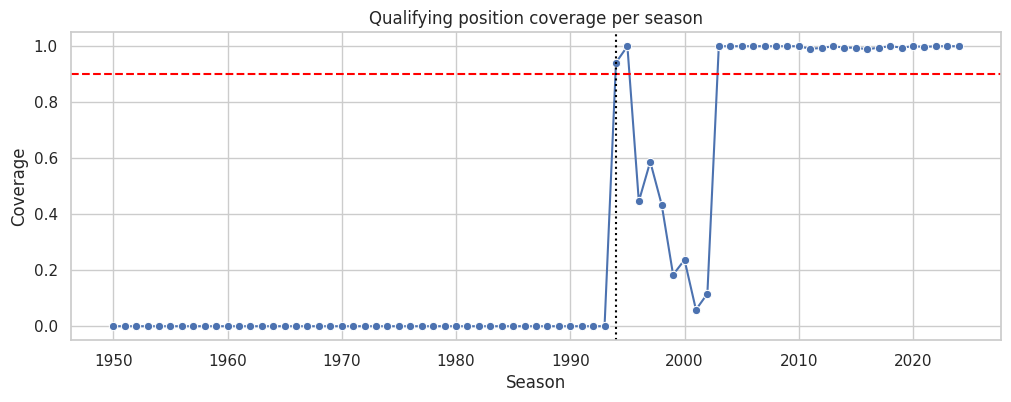

Q1 full-history grid conversion sensitivity table (n>=10; small samples included): (64, 10)


,era_pre_2014,circuitId,circuit_name,circuit_country,starts,podiums,conversion,conversion_ci_low,conversion_ci_high,rank
5,2014+,6,Circuit de Monaco,Monaco,19,17,0.894737,0.686059,0.970641,1.0
17,2014+,22,Suzuka Circuit,Japan,18,16,0.888889,0.672002,0.968980,2.0
18,2014+,24,Yas Marina Circuit,UAE,22,19,0.863636,0.666650,0.952510,3.0
3,2014+,4,Circuit de Barcelona-Catalunya,Spain,22,18,0.818182,0.614834,0.926931,4.0
10,2014+,13,Circuit de Spa-Francorchamps,Belgium,22,18,0.818182,0.614834,0.926931,4.0
...,...,...,...,...,...,...,...,...,...,...
60,pre-2014,30,Kyalami,South Africa,40,17,0.425,0.285094,0.578049,41.0
77,pre-2014,47,Scandinavian Raceway,Sweden,12,5,0.416667,0.193260,0.680489,42.0
68,pre-2014,38,Brands Hatch,UK,28,11,0.392857,0.235657,0.575910,43.0
66,pre-2014,36,Autódromo Internacional Nelson Piquet,Brazil,20,7,0.35,0.181192,0.567146,44.0


Q1 same-rows grid conversion sensitivity table (n>=10; covered seasons only): (40, 10)


,era_pre_2014,circuitId,circuit_name,circuit_country,starts,podiums,conversion,conversion_ci_low,conversion_ci_high,rank
5,2014+,6,Circuit de Monaco,Monaco,19,17,0.894737,0.686059,0.970641,1.0
17,2014+,22,Suzuka Circuit,Japan,18,16,0.888889,0.672002,0.968980,2.0
18,2014+,24,Yas Marina Circuit,UAE,22,19,0.863636,0.666650,0.952510,3.0
3,2014+,4,Circuit de Barcelona-Catalunya,Spain,22,18,0.818182,0.614834,0.926931,4.0
10,2014+,13,Circuit de Spa-Francorchamps,Belgium,22,18,0.818182,0.614834,0.926931,4.0
24,2014+,71,Sochi Autodrom,Russia,16,13,0.8125,0.569911,0.934084,6.0
22,2014+,69,Circuit of the Americas,USA,20,16,0.8,0.583983,0.919342,7.0
14,2014+,18,Autódromo José Carlos Pace,Brazil,19,15,0.789474,0.566657,0.914923,8.0
13,2014+,17,Shanghai International Circuit,China,14,11,0.785714,0.524108,0.924286,9.0
6,2014+,7,Circuit Gilles Villeneuve,Canada,18,14,0.777778,0.547854,0.909991,10.0


Q1 same-rows qualifying conversion sensitivity table (n>=10; covered seasons only): (40, 10)


,era_pre_2014,circuitId,circuit_name,circuit_country,starts,podiums,conversion,conversion_ci_low,conversion_ci_high,rank
5,2014+,6,Circuit de Monaco,Monaco,19,17,0.894737,0.686059,0.970641,1.0
17,2014+,22,Suzuka Circuit,Japan,18,16,0.888889,0.672002,0.968980,2.0
3,2014+,4,Circuit de Barcelona-Catalunya,Spain,22,18,0.818182,0.614834,0.926931,3.0
10,2014+,13,Circuit de Spa-Francorchamps,Belgium,22,18,0.818182,0.614834,0.926931,3.0
18,2014+,24,Yas Marina Circuit,UAE,22,18,0.818182,0.614834,0.926931,3.0
24,2014+,71,Sochi Autodrom,Russia,16,13,0.8125,0.569911,0.934084,6.0
13,2014+,17,Shanghai International Circuit,China,14,11,0.785714,0.524108,0.924286,7.0
7,2014+,9,Silverstone Circuit,UK,24,18,0.75,0.551006,0.880006,8.0
22,2014+,69,Circuit of the Americas,USA,20,15,0.75,0.531299,0.888138,8.0
11,2014+,14,Autodromo Nazionale di Monza,Italy,22,16,0.727273,0.518483,0.868492,10.0


Q1 same-rows grid rank -> qualifying rank: before=(40, 5), after=(40, 7)
Q1 same-rows grid/quali ranking changed count: 25
Q1 same-rows qualifying rank missing count: 0


,era_pre_2014,circuitId,circuit_name,grid_rank,grid_conversion,quali_rank,quali_conversion,rank_delta_quali_minus_grid
0,2014+,6,Circuit de Monaco,1.0,0.894737,1.0,0.894737,0.0
1,2014+,22,Suzuka Circuit,2.0,0.888889,2.0,0.888889,0.0
2,2014+,24,Yas Marina Circuit,3.0,0.863636,3.0,0.818182,0.0
3,2014+,4,Circuit de Barcelona-Catalunya,4.0,0.818182,3.0,0.818182,-1.0
4,2014+,13,Circuit de Spa-Francorchamps,4.0,0.818182,3.0,0.818182,-1.0
5,2014+,71,Sochi Autodrom,6.0,0.8125,6.0,0.8125,0.0
6,2014+,69,Circuit of the Americas,7.0,0.8,8.0,0.75,1.0
7,2014+,18,Autódromo José Carlos Pace,8.0,0.789474,16.0,0.684211,8.0
8,2014+,17,Shanghai International Circuit,9.0,0.785714,7.0,0.785714,-2.0
9,2014+,7,Circuit Gilles Villeneuve,10.0,0.777778,11.0,0.722222,1.0


In [34]:
de_df = tables["results"].copy()
de_q1 = de_df[["resultId","raceId","driverId","grid","positionOrder"]].copy()
de_q1["podium"] = de_q1["positionOrder"].le(3)
de_q1 = de_checked_merge(de_q1, tables["races"][["raceId","year","round","circuitId","name","date"]].copy().rename(columns={"name":"race_name"}), on="raceId", how="left", validate="many_to_one", name="Q1 results -> races")
de_q1 = de_checked_merge(de_q1, tables["circuits"][["circuitId","name","country"]].copy().rename(columns={"name":"circuit_name","country":"circuit_country"}), on="circuitId", how="left", validate="many_to_one", name="Q1 -> circuits")
de_q1_quali_join = tables["qualifying"][["raceId","driverId","position"]].copy().rename(columns={"position":"quali_position"})
assert de_q1_quali_join[["raceId","driverId"]].duplicated().sum() == 0
de_q1 = de_checked_merge(de_q1, de_q1_quali_join, on=["raceId","driverId"], how="left", validate="one_to_one", name="Q1 -> qualifying")
de_q1["era_pre_2014"] = de_era_pre_2014(de_q1["year"])
de_q1["front_row_grid"] = de_q1["grid"].isin([1,2])
de_q1["front_row_quali"] = de_q1["quali_position"].isin([1,2])
de_q1_grid_zero_count = int(de_q1["grid"].eq(0).sum())
de_q1_quali_rows = int(de_q1["quali_position"].notna().sum())
de_q1_mismatch = de_q1["quali_position"].notna() & de_q1["grid"].notna() & de_q1["grid"].ne(de_q1["quali_position"])
de_q1_mismatch_ex_grid0 = de_q1_mismatch & de_q1["grid"].ne(0)
de_q1_quali_rows_ex_grid0 = int((de_q1["quali_position"].notna() & de_q1["grid"].ne(0)).sum())
de_q1_grid_quali_mismatch_count = int(de_q1_mismatch.sum())
de_q1_grid_quali_mismatch_count_ex_grid0 = int(de_q1_mismatch_ex_grid0.sum())
de_q1_grid_quali_mismatch_share = de_q1_grid_quali_mismatch_count / de_q1_quali_rows
de_q1_grid_quali_mismatch_share_ex_grid0 = de_q1_grid_quali_mismatch_count_ex_grid0 / de_q1_quali_rows_ex_grid0
print(f"Q1 grid=0 pit-lane starts: {de_q1_grid_zero_count} (never in the front row, so not counted)")
print("Q1 grid != qualifying rows, including grid=0:", de_q1_grid_quali_mismatch_count)
print("Q1 grid != qualifying share among qualifying rows, including grid=0:", round(de_q1_grid_quali_mismatch_share, 4))
print("Q1 grid != qualifying rows, excluding grid=0:", de_q1_grid_quali_mismatch_count_ex_grid0)
print("Q1 grid != qualifying share among qualifying rows, excluding grid=0:", round(de_q1_grid_quali_mismatch_share_ex_grid0, 4))

def de_format_ranges(de_values):
    de_values = sorted(int(de_value) for de_value in de_values)
    if not de_values:
        return "none"
    de_ranges = []
    de_start = de_prev = de_values[0]
    for de_value in de_values[1:]:
        if de_value == de_prev + 1:
            de_prev = de_value
        else:
            de_ranges.append((de_start, de_prev))
            de_start = de_prev = de_value
    de_ranges.append((de_start, de_prev))
    return " and ".join(str(de_start) if de_start == de_end else f"{de_start}-{de_end}" for de_start, de_end in de_ranges)

de_q1_coverage = de_q1.groupby("year").agg(rows=("resultId","size"), qualifying_rows=("quali_position", lambda de_s: de_s.notna().sum())).reset_index()
de_q1_coverage["coverage"] = de_q1_coverage["qualifying_rows"] / de_q1_coverage["rows"]
de_q1_covered_seasons = de_q1_coverage.loc[de_q1_coverage["coverage"].ge(de_quali_coverage_threshold), "year"].tolist()
de_q1_first_covered_season = min(de_q1_covered_seasons)
de_q1_covered_season_range = list(range(min(de_q1_covered_seasons), max(de_q1_covered_seasons) + 1))
de_q1_covered_season_gaps = sorted(set(de_q1_covered_season_range) - set(de_q1_covered_seasons))
de_q1_covered_seasons_contiguous = len(de_q1_covered_season_gaps) == 0
de_q1_coverage_ranges_text = de_format_ranges(de_q1_covered_seasons)
de_q1_coverage_gap_text = de_format_ranges(de_q1_covered_season_gaps) if de_q1_covered_season_gaps else "none"
print(f"Q1 >={de_quali_coverage_threshold:.0%} qualifying coverage ranges: {de_q1_coverage_ranges_text}; gap {de_q1_coverage_gap_text}")
print("Q1 pre-2014 same-rows means the covered seasons only.")
display(de_q1_coverage)
de_fig, de_ax = plt.subplots(figsize=(12,4))
sns.lineplot(data=de_q1_coverage, x="year", y="coverage", marker="o", ax=de_ax)
de_ax.axhline(de_quali_coverage_threshold, color="red", linestyle="--"); de_ax.axvline(de_q1_first_covered_season, color="black", linestyle=":")
de_ax.set_title("Qualifying position coverage per season"); de_ax.set_ylabel("Coverage"); de_ax.set_xlabel("Season")
de_save_show(de_fig, "q1_qualifying_coverage.png")

de_q1_grid_table = de_rank_conversion(de_q1, "front_row_grid", "era_pre_2014", de_min_n)
de_q1_same_rows = de_q1.loc[de_q1["year"].isin(de_q1_covered_seasons) & de_q1["quali_position"].notna()].copy()
de_q1_grid_same_rows_table = de_rank_conversion(de_q1_same_rows, "front_row_grid", "era_pre_2014", de_min_n)
de_q1_quali_table = de_rank_conversion(de_q1_same_rows, "front_row_quali", "era_pre_2014", de_min_n)
print(f"Q1 full-history grid conversion sensitivity table (n>={de_min_n}; small samples included):", de_q1_grid_table.shape); display(de_q1_grid_table)
print(f"Q1 same-rows grid conversion sensitivity table (n>={de_min_n}; covered seasons only):", de_q1_grid_same_rows_table.shape); display(de_q1_grid_same_rows_table)
print(f"Q1 same-rows qualifying conversion sensitivity table (n>={de_min_n}; covered seasons only):", de_q1_quali_table.shape); display(de_q1_quali_table)

de_q1_rank_compare = de_checked_merge(de_q1_grid_same_rows_table[["era_pre_2014","circuitId","circuit_name","rank","conversion"]].rename(columns={"rank":"grid_rank","conversion":"grid_conversion"}), de_q1_quali_table[["era_pre_2014","circuitId","rank","conversion"]].rename(columns={"rank":"quali_rank","conversion":"quali_conversion"}), on=["era_pre_2014","circuitId"], how="left", validate="one_to_one", name="Q1 same-rows grid rank -> qualifying rank")
de_q1_rank_compare["rank_delta_quali_minus_grid"] = de_q1_rank_compare["quali_rank"] - de_q1_rank_compare["grid_rank"]
de_q1_rank_changed_count = int((de_q1_rank_compare["rank_delta_quali_minus_grid"].notna() & de_q1_rank_compare["rank_delta_quali_minus_grid"].ne(0)).sum())
de_q1_rank_missing_count = int(de_q1_rank_compare["rank_delta_quali_minus_grid"].isna().sum())
print("Q1 same-rows grid/quali ranking changed count:", de_q1_rank_changed_count)
print("Q1 same-rows qualifying rank missing count:", de_q1_rank_missing_count); display(de_q1_rank_compare)


Q1 matched-window headline table (n>=25 total front-row starts across matched windows): (29, 10)


,matched_era,circuitId,circuit_name,circuit_country,starts,podiums,conversion,conversion_ci_low,conversion_ci_high,rank
21,2006-2013,22,Suzuka Circuit,Japan,12,10,0.833333,0.551969,0.953035,1.0
5,2006-2013,6,Circuit de Monaco,Monaco,16,13,0.8125,0.569911,0.934084,2.0
12,2006-2013,13,Circuit de Spa-Francorchamps,Belgium,14,11,0.785714,0.524108,0.924286,3.0
8,2006-2013,9,Silverstone Circuit,UK,16,12,0.75,0.505017,0.898179,4.0
13,2006-2013,14,Autodromo Nazionale di Monza,Italy,16,12,0.75,0.505017,0.898179,4.0
3,2006-2013,4,Circuit de Barcelona-Catalunya,Spain,16,11,0.6875,0.444044,0.858354,6.0
2,2006-2013,3,Bahrain International Circuit,Bahrain,14,9,0.642857,0.387644,0.836553,7.0
0,2006-2013,1,Albert Park Grand Prix Circuit,Australia,16,10,0.625,0.386410,0.815188,8.0
10,2006-2013,11,Hungaroring,Hungary,16,10,0.625,0.386410,0.815188,8.0
16,2006-2013,17,Shanghai International Circuit,China,16,10,0.625,0.386410,0.815188,8.0


Q1 matched-window small-sample table (n>=10 front-row starts): (37, 10)


,matched_era,circuitId,circuit_name,circuit_country,starts,podiums,conversion,conversion_ci_low,conversion_ci_high,rank
4,2006-2013,5,Istanbul Park,Turkey,12,10,0.833333,0.551969,0.953035,1.0
21,2006-2013,22,Suzuka Circuit,Japan,12,10,0.833333,0.551969,0.953035,1.0
5,2006-2013,6,Circuit de Monaco,Monaco,16,13,0.8125,0.569911,0.934084,3.0
12,2006-2013,13,Circuit de Spa-Francorchamps,Belgium,14,11,0.785714,0.524108,0.924286,4.0
8,2006-2013,9,Silverstone Circuit,UK,16,12,0.75,0.505017,0.898179,5.0
13,2006-2013,14,Autodromo Nazionale di Monza,Italy,16,12,0.75,0.505017,0.898179,5.0
19,2006-2013,20,Nürburgring,Germany,10,7,0.7,0.396778,0.892209,7.0
3,2006-2013,4,Circuit de Barcelona-Catalunya,Spain,16,11,0.6875,0.444044,0.858354,8.0
2,2006-2013,3,Bahrain International Circuit,Bahrain,14,9,0.642857,0.387644,0.836553,9.0
0,2006-2013,1,Albert Park Grand Prix Circuit,Australia,16,10,0.625,0.386410,0.815188,10.0


Q1 sensitivity note: full-history and same-rows tables can disagree because they use different eras and have qualifying-coverage gaps.
Q1 headline rank stability, matched window 2006-2013 vs 2014-2024, circuits in both windows: 14
Q1 Spearman rho=0.377, p=0.1845
Q1 Kendall tau=0.261, p=0.2035
Q1 sampling-noise benchmark for Spearman (matched-window headline):


,metric,value
0,observed_spearman,0.376525
1,noise_median,0.350008
2,noise_ci_low,-0.185642
3,noise_ci_high,0.729335
4,observed_noise_percentile,0.549500
5,circuits,14.000000


Saved figure: figures_de/q1_rank_slope.png


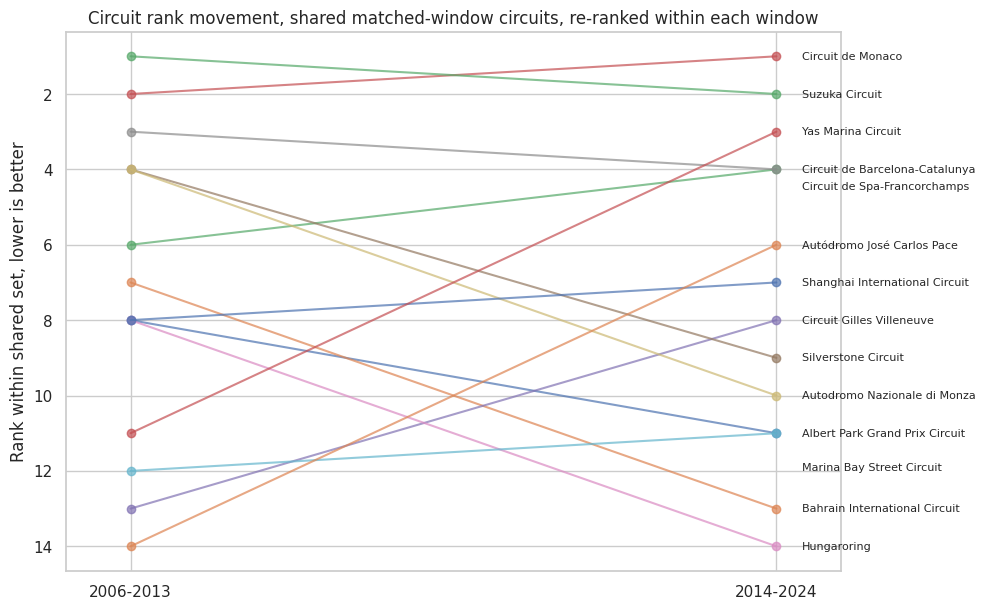

Q1 full-history sensitivity, circuits only pre-2014:


,circuitId,circuit_name,circuit_country
39,8,Circuit de Nevers Magny-Cours,France
36,5,Istanbul Park,Turkey
50,19,Indianapolis Motor Speedway,USA
71,41,Dijon-Prenois,France
33,2,Sepang International Circuit,Malaysia
57,27,Autódromo do Estoril,Portugal
56,26,Circuito de Jerez,Spain
88,58,Aintree,UK
96,66,Circuit Bremgarten,Switzerland
73,43,Long Beach,USA


Q1 full-history sensitivity, circuits only 2014+:


,circuitId,circuit_name,circuit_country
24,71,Sochi Autodrom,Russia
22,69,Circuit of the Americas,USA
25,73,Baku City Circuit,Azerbaijan


Q1 full-history sensitivity rank stability (all seasons, pre-2014 vs 2014+):
Q1 full-history Spearman rho=-0.083, p=0.7590
Q1 full-history Kendall tau=-0.051, p=0.7862
Q1 sampling-noise benchmark for Spearman (full-history sensitivity):


,metric,value
0,observed_spearman,-0.083333
1,noise_median,0.392172
2,noise_ci_low,-0.074740
3,noise_ci_high,0.755209
4,observed_noise_percentile,0.021500
5,circuits,16.000000


Q1 circuits in only one matched window: Red Bull Ring
Saved figure: figures_de/q1_front_row_grid_conversion.png


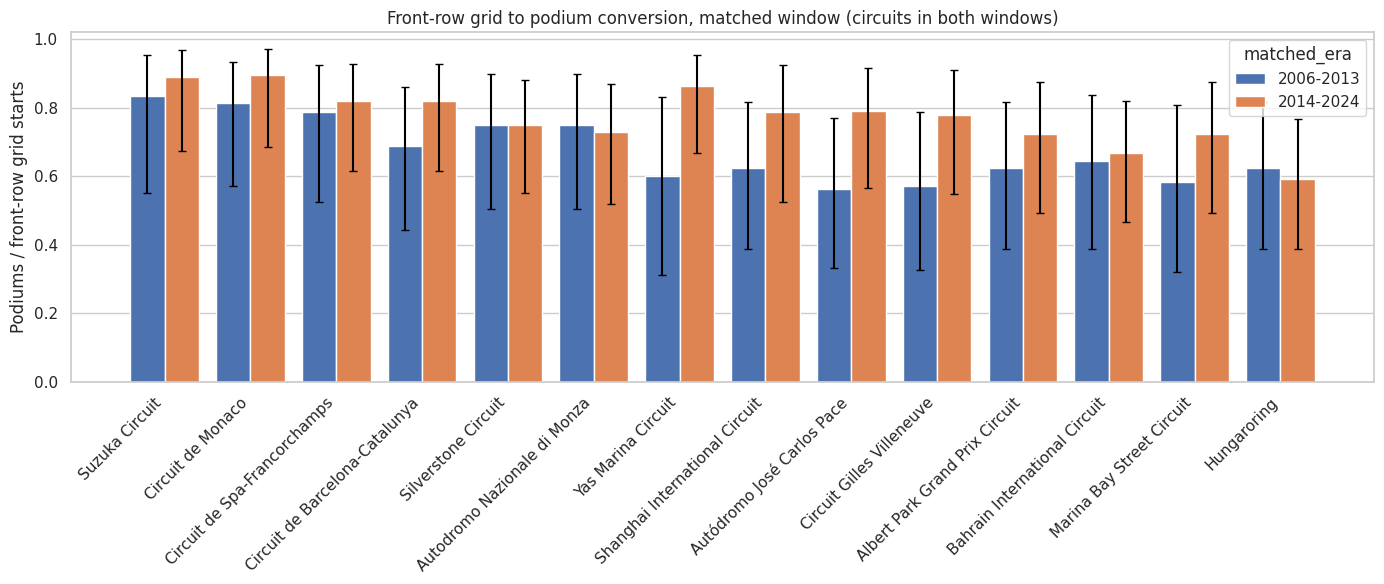

Q1 all-years sensitivity table (n>=10; small samples included): (48, 8)


,circuitId,circuit_name,circuit_country,starts,podiums,conversion,conversion_ci_low,conversion_ci_high
67,69,Circuit of the Americas,USA,24,20,0.833333,0.641469,0.933213
7,8,Circuit de Nevers Magny-Cours,France,35,29,0.828571,0.673177,0.918974
69,71,Sochi Autodrom,Russia,16,13,0.8125,0.569911,0.934084
18,19,Indianapolis Motor Speedway,USA,14,11,0.785714,0.524108,0.924286
22,24,Yas Marina Circuit,UAE,32,25,0.78125,0.612450,0.889762
21,22,Suzuka Circuit,Japan,68,51,0.75,0.635614,0.837650
39,41,Dijon-Prenois,France,12,9,0.75,0.467695,0.911058
1,2,Sepang International Circuit,Malaysia,37,27,0.72973,0.570218,0.846025
4,5,Istanbul Park,Turkey,18,13,0.722222,0.491273,0.875002
3,4,Circuit de Barcelona-Catalunya,Spain,67,48,0.716418,0.599068,0.810297


In [35]:
# Q1 rank stability and matched-window headline: headline statistics use the matched-window table restricted to circuits present in both windows; full-history statistics remain as a labelled sensitivity check.
de_q1_matched_pre_label = f"{de_matched_pre_start_year}-{de_matched_pre_end_year}"
de_q1_matched_post_label = f"{de_matched_post_start_year}-{de_matched_post_end_year}"
de_q1_matched = de_q1.loc[de_q1["year"].between(de_matched_pre_start_year, de_matched_post_end_year)].copy()
de_q1_matched["matched_era"] = np.select([de_q1_matched["year"].between(de_matched_pre_start_year, de_matched_pre_end_year), de_q1_matched["year"].between(de_matched_post_start_year, de_matched_post_end_year)], [de_q1_matched_pre_label, de_q1_matched_post_label], default=None)
de_q1_matched_table = de_rank_conversion(de_q1_matched.dropna(subset=["matched_era"]), "front_row_grid", "matched_era", de_min_n)
de_q1_matched_headline_circuits = de_q1_matched_table.groupby("circuitId")["starts"].sum().loc[lambda de_s: de_s.ge(de_min_n_q1_headline)].index
de_q1_matched_headline_table = de_q1_matched_table.loc[de_q1_matched_table["circuitId"].isin(de_q1_matched_headline_circuits)].copy()
de_q1_matched_headline_table["rank"] = de_q1_matched_headline_table.groupby("matched_era")["conversion"].rank(ascending=False, method="min")
de_q1_matched_headline_table = de_q1_matched_headline_table.sort_values(["matched_era","rank","starts"], ascending=[True,True,False])
print(f"Q1 matched-window headline table (n>={de_min_n_q1_headline} total front-row starts across matched windows):", de_q1_matched_headline_table.shape); display(de_q1_matched_headline_table)
print(f"Q1 matched-window small-sample table (n>={de_min_n} front-row starts):", de_q1_matched_table.shape); display(de_q1_matched_table)
print("Q1 sensitivity note: full-history and same-rows tables can disagree because they use different eras and have qualifying-coverage gaps.")

de_q1_rng = np.random.default_rng(20261008)

def de_rank_stability(de_table, de_era_col, de_era_a, de_era_b):
    de_wide = de_table.pivot(index="circuitId", columns=de_era_col, values="rank").dropna()
    de_spearman = spearmanr(de_wide[de_era_a], de_wide[de_era_b])
    de_kendall = kendalltau(de_wide[de_era_a], de_wide[de_era_b])
    de_counts_wide = de_table.loc[de_table["circuitId"].isin(set(de_wide.index)), [de_era_col,"circuitId","starts","podiums"]].pivot(index="circuitId", columns=de_era_col, values=["starts","podiums"]).dropna()
    de_n = len(de_counts_wide)
    de_true_rate = (de_counts_wide[("podiums",de_era_a)] + de_counts_wide[("podiums",de_era_b)]) / (de_counts_wide[("starts",de_era_a)] + de_counts_wide[("starts",de_era_b)])
    de_boot = []
    for de_i in range(2000):
        de_a_sim = de_q1_rng.binomial(de_counts_wide[("starts",de_era_a)].astype(int).to_numpy(), de_true_rate.to_numpy(dtype=float)) / de_counts_wide[("starts",de_era_a)].to_numpy(dtype=float)
        de_b_sim = de_q1_rng.binomial(de_counts_wide[("starts",de_era_b)].astype(int).to_numpy(), de_true_rate.to_numpy(dtype=float)) / de_counts_wide[("starts",de_era_b)].to_numpy(dtype=float)
        de_boot.append(spearmanr(pd.Series(de_a_sim).rank(ascending=False, method="min"), pd.Series(de_b_sim).rank(ascending=False, method="min")).statistic)
    de_boot = np.array(de_boot, dtype=float)
    de_ci_low = float(np.nanquantile(de_boot, .025))
    de_ci_high = float(np.nanquantile(de_boot, .975))
    de_percentile = float(np.nanmean(de_boot <= de_spearman.statistic))
    de_summary = pd.DataFrame({"metric":["observed_spearman","noise_median","noise_ci_low","noise_ci_high","observed_noise_percentile","circuits"], "value":[de_spearman.statistic, np.nanmedian(de_boot), de_ci_low, de_ci_high, de_percentile, de_n]})
    return de_wide, de_spearman, de_kendall, de_ci_low, de_ci_high, de_percentile, de_n, de_summary

de_q1_wide, de_q1_spearman, de_q1_kendall, de_q1_noise_ci_low, de_q1_noise_ci_high, de_q1_observed_noise_percentile, de_q1_noise_n, de_q1_noise_summary = de_rank_stability(de_q1_matched_headline_table, "matched_era", de_q1_matched_pre_label, de_q1_matched_post_label)
print(f"Q1 headline rank stability, matched window {de_q1_matched_pre_label} vs {de_q1_matched_post_label}, circuits in both windows: {de_q1_noise_n}")
print(f"Q1 Spearman rho={de_q1_spearman.statistic:.3f}, p={de_q1_spearman.pvalue:.4f}")
print(f"Q1 Kendall tau={de_q1_kendall.statistic:.3f}, p={de_q1_kendall.pvalue:.4f}")
print("Q1 sampling-noise benchmark for Spearman (matched-window headline):"); display(de_q1_noise_summary)

de_q1_slope = de_q1_matched_headline_table.loc[de_q1_matched_headline_table["circuitId"].isin(set(de_q1_wide.index)), ["matched_era","circuitId","circuit_name","conversion"]].copy()
de_q1_slope["shared_rank"] = de_q1_slope.groupby("matched_era")["conversion"].rank(ascending=False, method="min")
de_era_to_x = {de_q1_matched_pre_label: 0, de_q1_matched_post_label: 1}
de_fig, de_ax = plt.subplots(figsize=(10,7))
de_label_used_y = []
for de_circuit_id, de_sub in de_q1_slope.groupby("circuitId"):
    de_sub = de_sub.sort_values("matched_era")
    de_ax.plot([de_era_to_x[de_e] for de_e in de_sub["matched_era"]], de_sub["shared_rank"], marker="o", alpha=.7)
    de_post_row = de_sub.loc[de_sub["matched_era"].eq(de_q1_matched_post_label)]
    de_label_y = float(de_post_row["shared_rank"].iloc[0])
    while any(abs(de_label_y - de_used_y) < 0.45 for de_used_y in de_label_used_y):
        de_label_y += 0.45
    de_label_used_y.append(de_label_y)
    de_ax.text(1.04, de_label_y, str(de_post_row["circuit_name"].iloc[0]), fontsize=8, va="center")
de_ax.set_xticks([0,1]); de_ax.set_xticklabels([de_q1_matched_pre_label, de_q1_matched_post_label])
de_ax.set_xlim(-0.1, 1.1)
de_ax.invert_yaxis(); de_ax.set_title("Circuit rank movement, shared matched-window circuits, re-ranked within each window"); de_ax.set_ylabel("Rank within shared set, lower is better"); de_ax.set_xlabel("")
de_save_show(de_fig, "q1_rank_slope.png")

de_q1_pre_set = set(de_q1_grid_table.loc[de_q1_grid_table["era_pre_2014"].eq("pre-2014"), "circuitId"])
de_q1_post_set = set(de_q1_grid_table.loc[de_q1_grid_table["era_pre_2014"].eq("2014+"), "circuitId"])
de_q1_only_pre = de_q1_grid_table.loc[de_q1_grid_table["circuitId"].isin(de_q1_pre_set - de_q1_post_set), ["circuitId","circuit_name","circuit_country"]].drop_duplicates()
de_q1_only_post = de_q1_grid_table.loc[de_q1_grid_table["circuitId"].isin(de_q1_post_set - de_q1_pre_set), ["circuitId","circuit_name","circuit_country"]].drop_duplicates()
print("Q1 full-history sensitivity, circuits only pre-2014:"); display(de_q1_only_pre)
print("Q1 full-history sensitivity, circuits only 2014+:"); display(de_q1_only_post)
de_q1_full_wide, de_q1_full_spearman, de_q1_full_kendall, de_q1_full_noise_ci_low, de_q1_full_noise_ci_high, de_q1_full_observed_noise_percentile, de_q1_full_noise_n, de_q1_full_noise_summary = de_rank_stability(de_q1_grid_table, "era_pre_2014", "pre-2014", "2014+")
print("Q1 full-history sensitivity rank stability (all seasons, pre-2014 vs 2014+):")
print(f"Q1 full-history Spearman rho={de_q1_full_spearman.statistic:.3f}, p={de_q1_full_spearman.pvalue:.4f}")
print(f"Q1 full-history Kendall tau={de_q1_full_kendall.statistic:.3f}, p={de_q1_full_kendall.pvalue:.4f}")
print("Q1 sampling-noise benchmark for Spearman (full-history sensitivity):"); display(de_q1_full_noise_summary)

de_q1_shared_circuits = set(de_q1_wide.index)
de_q1_only_one_window = de_q1_matched_headline_table.loc[~de_q1_matched_headline_table["circuitId"].isin(de_q1_shared_circuits), "circuit_name"].drop_duplicates().sort_values().tolist()
print("Q1 circuits in only one matched window: " + (", ".join(de_q1_only_one_window) if de_q1_only_one_window else "none"))
de_q1_plot = de_q1_matched_headline_table.loc[de_q1_matched_headline_table["circuitId"].isin(de_q1_shared_circuits)].copy()
de_q1_order = de_q1_plot.groupby("circuit_name")["conversion"].mean().sort_values(ascending=False).index.tolist()
de_fig, de_ax = de_grouped_bar_ci(de_q1_plot, "circuit_name", "conversion", "conversion_ci_low", "conversion_ci_high", "matched_era", de_q1_order, [de_q1_matched_pre_label, de_q1_matched_post_label], "Front-row grid to podium conversion, matched window (circuits in both windows)", "Podiums / front-row grid starts", 45, (14,6))
de_save_show(de_fig, "q1_front_row_grid_conversion.png")

de_q1_all_years = de_q1.loc[de_q1["front_row_grid"]].groupby(["circuitId","circuit_name","circuit_country"]).agg(starts=("podium","size"), podiums=("podium","sum")).reset_index()
de_q1_all_years["conversion"] = de_q1_all_years["podiums"] / de_q1_all_years["starts"]
de_q1_all_years = de_add_wilson(de_q1_all_years, "podiums", "starts", "conversion")
de_q1_all_years = de_q1_all_years.loc[de_q1_all_years["starts"] >= de_min_n].sort_values("conversion", ascending=False)
print(f"Q1 all-years sensitivity table (n>={de_min_n}; small samples included):", de_q1_all_years.shape); display(de_q1_all_years)


### 2.1.1 Q1 note on grain, missingness, and pre-race cutoff

The grain is one cleaned `results` row per race-driver start. Missing qualifying positions are not imputed; qualifying front-row analysis is limited to seasons with at least 90% coverage. `positionOrder` creates the retrospective podium outcome and is never a pre-race model feature.

In [36]:
# Q1 printed answer: matched-window headline with tied winners, top/bottom circuits with Wilson CIs, computed CI-overlap statement, softened rank-stability wording, coverage ranges, and grid/qualifying mismatch shares.
def de_q1_top_with_ci_ties(de_table, de_era_col, de_era_value):
    de_sub = de_table.loc[de_table[de_era_col].eq(de_era_value)].sort_values(["rank","starts"], ascending=[True,False]).copy()
    de_top = de_sub.iloc[0]
    de_ties = de_sub.loc[(de_sub["circuitId"].ne(de_top["circuitId"])) & de_sub["conversion_ci_low"].le(de_top["conversion_ci_high"]) & de_sub["conversion_ci_high"].ge(de_top["conversion_ci_low"]), "circuit_name"].tolist()
    de_name = f"{de_top['circuit_name']} (statistically tied with {len(de_ties)} of {len(de_sub) - 1} other circuits, CI overlap)"
    de_detail = ", ".join(de_ties) if de_ties else "none"
    return de_top, de_name, de_detail

de_q1_matched_best_pre, de_q1_matched_best_pre_text, de_q1_matched_best_pre_ties_detail = de_q1_top_with_ci_ties(de_q1_matched_headline_table, "matched_era", de_q1_matched_pre_label)
de_q1_matched_best_post, de_q1_matched_best_post_text, de_q1_matched_best_post_ties_detail = de_q1_top_with_ci_ties(de_q1_matched_headline_table, "matched_era", de_q1_matched_post_label)
print(f"Q1 tied circuits (detail): {de_q1_matched_pre_label}: {de_q1_matched_best_pre_ties_detail}; {de_q1_matched_post_label}: {de_q1_matched_best_post_ties_detail}")
de_q1_same_rows_best_pre = de_q1_quali_table.loc[de_q1_quali_table["era_pre_2014"].eq("pre-2014")].head(1)
de_q1_same_rows_best_post = de_q1_quali_table.loc[de_q1_quali_table["era_pre_2014"].eq("2014+")].head(1)

de_q1_top_bottom_n = 3
def de_q1_top_bottom_text(de_table, de_era_value):
    de_sub = de_table.loc[de_table["matched_era"].eq(de_era_value)].sort_values(["rank","starts"], ascending=[True,False])
    def de_fmt(de_row):
        return f"{de_row.circuit_name} {de_row.conversion:.1%} [{de_row.conversion_ci_low:.1%}, {de_row.conversion_ci_high:.1%}]"
    de_top_text = "; ".join(de_fmt(de_row) for de_row in de_sub.head(de_q1_top_bottom_n).itertuples())
    de_bottom_text = "; ".join(de_fmt(de_row) for de_row in de_sub.tail(de_q1_top_bottom_n).itertuples())
    return de_top_text, de_bottom_text

de_q1_top_pre_text, de_q1_bottom_pre_text = de_q1_top_bottom_text(de_q1_matched_headline_table, de_q1_matched_pre_label)
de_q1_top_post_text, de_q1_bottom_post_text = de_q1_top_bottom_text(de_q1_matched_headline_table, de_q1_matched_post_label)

def de_q1_ci_overlap_share(de_table, de_era_value):
    de_sub = de_table.loc[de_table["matched_era"].eq(de_era_value)].reset_index(drop=True)
    de_pairs = 0
    de_overlap = 0
    for de_i in range(len(de_sub)):
        for de_j in range(de_i + 1, len(de_sub)):
            de_pairs += 1
            de_overlap += int(bool(de_sub.loc[de_i, "conversion_ci_low"] <= de_sub.loc[de_j, "conversion_ci_high"] and de_sub.loc[de_j, "conversion_ci_low"] <= de_sub.loc[de_i, "conversion_ci_high"]))
    return de_overlap / de_pairs if de_pairs else float("nan")

de_q1_overlap_share_pre = de_q1_ci_overlap_share(de_q1_matched_headline_table, de_q1_matched_pre_label)
de_q1_overlap_share_post = de_q1_ci_overlap_share(de_q1_matched_headline_table, de_q1_matched_post_label)
if min(de_q1_overlap_share_pre, de_q1_overlap_share_post) > 0.5:
    de_q1_overlap_text = f"Most circuit Wilson CIs overlap within each window ({de_q1_overlap_share_pre:.0%} of circuit pairs in {de_q1_matched_pre_label} and {de_q1_overlap_share_post:.0%} in {de_q1_matched_post_label}), so the ordering within a window is noisy."
else:
    de_q1_overlap_text = f"Fewer than half of circuit Wilson CI pairs overlap in at least one window ({de_q1_overlap_share_pre:.0%} of circuit pairs in {de_q1_matched_pre_label} and {de_q1_overlap_share_post:.0%} in {de_q1_matched_post_label}), so some ordering differences are clearer."

if de_q1_spearman.statistic < de_q1_noise_ci_low:
    de_q1_bootstrap_interpretation = f"The observed Spearman rho is {de_q1_spearman.statistic:.2f}, below the sampling-noise 95% range [{de_q1_noise_ci_low:.2f}, {de_q1_noise_ci_high:.2f}] with observed percentile {de_q1_observed_noise_percentile:.3f}; this is only weak, suggestive evidence that the circuit ordering may have shifted between the matched windows, especially because most circuit CIs overlap and only {de_q1_noise_n} circuits appear in both windows."
elif de_q1_spearman.statistic <= de_q1_noise_ci_high:
    de_q1_bootstrap_interpretation = f"The observed Spearman rho is {de_q1_spearman.statistic:.2f}, inside the sampling-noise 95% range [{de_q1_noise_ci_low:.2f}, {de_q1_noise_ci_high:.2f}] with observed percentile {de_q1_observed_noise_percentile:.3f}; the rank movement remains compatible with sampling noise, especially with only {de_q1_noise_n} circuits in both windows."
else:
    de_q1_bootstrap_interpretation = f"The observed Spearman rho is {de_q1_spearman.statistic:.2f}, above the sampling-noise 95% range [{de_q1_noise_ci_low:.2f}, {de_q1_noise_ci_high:.2f}] with observed percentile {de_q1_observed_noise_percentile:.3f}; the rank ordering looks broadly stable across the matched windows, though only {de_q1_noise_n} circuits appear in both."

de_q1_matched_inside_noise = de_q1_noise_ci_low <= de_q1_spearman.statistic <= de_q1_noise_ci_high
de_q1_full_inside_noise = de_q1_full_noise_ci_low <= de_q1_full_spearman.statistic <= de_q1_full_noise_ci_high
de_q1_full_history_sensitivity_text = f"Full-history sensitivity has Spearman rho {de_q1_full_spearman.statistic:.2f}, sampling-noise 95% range [{de_q1_full_noise_ci_low:.2f}, {de_q1_full_noise_ci_high:.2f}], observed percentile {de_q1_full_observed_noise_percentile:.3f}, across {de_q1_full_noise_n} circuits."
if de_q1_matched_inside_noise != de_q1_full_inside_noise:
    de_q1_robustness_verdict = "The matched-window and full-history analyses disagree, so the conclusion that circuit ranking changed after 2014 is not robust to the choice of window."
else:
    de_q1_robustness_verdict = "The matched-window and full-history analyses agree on whether the observed rank stability falls inside the sampling-noise range."

de_q1_window_starts = de_q1_matched_headline_table.groupby("matched_era")["starts"].agg(["min", "max"])
de_q1_window_starts_text = f"Per-window front-row starts among headline circuits range from {int(de_q1_window_starts.loc[de_q1_matched_pre_label, 'min'])}-{int(de_q1_window_starts.loc[de_q1_matched_pre_label, 'max'])} in {de_q1_matched_pre_label} and {int(de_q1_window_starts.loc[de_q1_matched_post_label, 'min'])}-{int(de_q1_window_starts.loc[de_q1_matched_post_label, 'max'])} in {de_q1_matched_post_label}; the n>={de_min_n_q1_headline} threshold is on starts summed across both matched windows, so per-window samples are small and wide CIs are expected."

de_q1_answer = (
    f"Q1 answer: The headline matched-window grid comparison uses at least {de_min_n_q1_headline} total front-row starts across the matched windows. "
    f"For {de_q1_matched_pre_label}, the top circuit is {de_q1_matched_best_pre_text} at {de_q1_matched_best_pre['conversion']:.1%} ({int(de_q1_matched_best_pre['podiums'])}/{int(de_q1_matched_best_pre['starts'])}). "
    f"For {de_q1_matched_post_label}, the top circuit is {de_q1_matched_best_post_text} at {de_q1_matched_best_post['conversion']:.1%} ({int(de_q1_matched_best_post['podiums'])}/{int(de_q1_matched_best_post['starts'])}). "
    "Circuits whose Wilson CI overlaps the top circuit's CI are statistically tied. "
    f"Top {de_q1_top_bottom_n} in {de_q1_matched_pre_label}: {de_q1_top_pre_text}. Bottom {de_q1_top_bottom_n} in {de_q1_matched_pre_label}: {de_q1_bottom_pre_text}. "
    f"Top {de_q1_top_bottom_n} in {de_q1_matched_post_label}: {de_q1_top_post_text}. Bottom {de_q1_top_bottom_n} in {de_q1_matched_post_label}: {de_q1_bottom_post_text}. "
    + de_q1_overlap_text + " "
    + de_q1_window_starts_text + " "
    f"The same-rows qualifying sensitivity uses covered seasons only; its top qualifying-position circuits are {de_q1_same_rows_best_pre.iloc[0]['circuit_name']} before 2014 and {de_q1_same_rows_best_post.iloc[0]['circuit_name']} from 2014 onward. "
    f"Rank stability is assessed on the matched-window headline circuits ({de_q1_noise_n} in both windows); full-history statistics are reported as a sensitivity check. "
    + de_q1_bootstrap_interpretation + " "
    + de_q1_full_history_sensitivity_text + " "
    + de_q1_robustness_verdict + " "
    f"Qualifying coverage at the {de_quali_coverage_threshold:.0%} threshold occurs in {de_q1_coverage_ranges_text}; gap {de_q1_coverage_gap_text}. "
    f"Grid differs from qualifying position in {de_q1_grid_quali_mismatch_share:.1%} of qualifying-covered rows including grid=0 and {de_q1_grid_quali_mismatch_share_ex_grid0:.1%} excluding grid=0. "
    "Full-history and same-rows sensitivity checks can disagree with the matched-window headline because they use different eras and have qualifying-coverage gaps."
)
print(de_q1_answer)


Q1 tied circuits (detail): 2006-2013: Circuit de Monaco, Circuit de Spa-Francorchamps, Silverstone Circuit, Autodromo Nazionale di Monza, Circuit de Barcelona-Catalunya, Bahrain International Circuit, Albert Park Grand Prix Circuit, Hungaroring, Shanghai International Circuit, Yas Marina Circuit, Marina Bay Street Circuit, Circuit Gilles Villeneuve, Autódromo José Carlos Pace; 2014-2024: Suzuka Circuit, Yas Marina Circuit, Circuit de Barcelona-Catalunya, Circuit de Spa-Francorchamps, Autódromo José Carlos Pace, Shanghai International Circuit, Circuit Gilles Villeneuve, Silverstone Circuit, Red Bull Ring, Autodromo Nazionale di Monza, Albert Park Grand Prix Circuit, Marina Bay Street Circuit, Bahrain International Circuit, Hungaroring
Q1 answer: The headline matched-window grid comparison uses at least 25 total front-row starts across the matched windows. For 2006-2013, the top circuit is Suzuka Circuit (statistically tied with 13 of 13 other circuits, CI overlap) at 83.3% (10/12). For 

### 2.1.2 Q1 written answer

The headline comparison is `de_q1_matched_headline_table`, which compares the matched windows `de_matched_pre_start_year`-`de_matched_pre_end_year` and `de_matched_post_start_year`-`de_matched_post_end_year` for circuits with at least `de_min_n_q1_headline` total front-row starts across those matched windows. The printed answer reports the top circuit for each matched window and appends tied circuits when their Wilson interval overlaps the top circuit's Wilson interval, then lists the top and bottom `de_q1_top_bottom_n` circuits per window with conversion and Wilson interval. It also states whether most circuit Wilson CIs overlap, computed from the share of circuit pairs with overlapping intervals (`de_q1_overlap_share_pre`, `de_q1_overlap_share_post`).

Rank stability (Spearman, Kendall, and the sampling-noise bootstrap in `de_rank_stability`) is computed on the headline matched-window table, restricted to circuits present in both windows (`de_q1_wide`). The full-history equivalents (`de_q1_full_spearman`, `de_q1_full_kendall`, `de_q1_full_noise_summary`) remain displayed as labelled sensitivity checks, alongside the `n>=10` small-sample tables `de_q1_grid_table`, `de_q1_grid_same_rows_table`, and `de_q1_quali_table`; they can disagree with the matched-window headline because they use different eras and because qualifying coverage has gaps. The slope chart `q1_rank_slope.png` re-ranks only the shared circuits within each window, puts the earlier window on the left, and labels each line with the circuit name.

The bootstrap interpretation in `de_q1_answer` is generated from the matched-window statistics (`de_q1_spearman.statistic`, `de_q1_noise_ci_low`, `de_q1_noise_ci_high`, `de_q1_observed_noise_percentile`, `de_q1_noise_n`). If the observed Spearman is below the noise interval, the wording is deliberately softened: only weak, suggestive evidence that the ordering may have shifted, because most circuit CIs overlap and few circuits appear in both windows.

Grain: one cleaned `results` row per `(raceId, driverId)`, joined to race, circuit, and qualifying rows using checked merges. Missingness: qualifying position coverage is reported by season, and same-rows comparisons use only non-null qualifying rows in covered seasons. Pre-race cutoff: grid and qualifying position are known before the race; podium is the retrospective outcome.


The bar chart `q1_front_row_grid_conversion.png` now plots only circuits that appear in both matched windows (`de_q1_wide.index`), ordered by their mean conversion rate across the two windows. Circuits appearing in only one matched window are printed separately as `Q1 circuits in only one matched window: ...` and are not plotted.

The printed answer now reports CI-overlap ties as counts instead of long parenthetical circuit lists, with the full tied-circuit detail printed separately. It also adds a computed full-history sensitivity sentence, a robustness verdict comparing matched-window and full-history noise-range conclusions, and a computed note that the `de_min_n_q1_headline` threshold is based on starts summed across both windows while per-window samples remain small.


## 2.2 Q2. Home-country podium rate

The home-country flag is built by set membership from `nationality_country`, not by merging that multi-row table into result rows.

Q2 results -> drivers: before=(24566, 7), after=(24566, 8)
Q2 -> races: before=(24566, 8), after=(24566, 10)
Q2 -> circuits: before=(24566, 10), after=(24566, 11)
Q2 home-race row share: 0.0786
Q2 drivers whose nationality can ever have a home race: 640
Q2 mapped hosted home countries: 26
Q2 nationalities mapped to multiple home countries: 4
Q2 raw home vs away comparison:


,home_status,podiums,starts,podium_rate,podium_rate_ci_low,podium_rate_ci_high
0,Away,3118,22634,0.137757,0.133329,0.142309
1,Home,224,1932,0.115942,0.102422,0.130986


Q2 stratified table: (12, 7)


,grid_bucket,is_home,starts,podiums,podium_rate,podium_rate_ci_low,podium_rate_ci_high
0,pit lane,False,83,0,0.0,0.000000,0.044235
1,pit lane,True,4,0,0.0,0.000000,0.489891
2,1-3,False,3105,1725,0.555556,0.538020,0.572954
3,1-3,True,230,128,0.556522,0.491912,0.619274
4,4-6,False,3107,810,0.260702,0.245567,0.276427
5,4-6,True,226,60,0.265487,0.212183,0.326630
6,7-10,False,4090,379,0.092665,0.084157,0.101938
7,7-10,True,335,24,0.071642,0.048613,0.104384
8,11-15,False,5091,151,0.02966,0.025343,0.034687
9,11-15,True,414,10,0.024155,0.013172,0.043886


Saved figure: figures_de/q2_home_away_grid_bucket.png


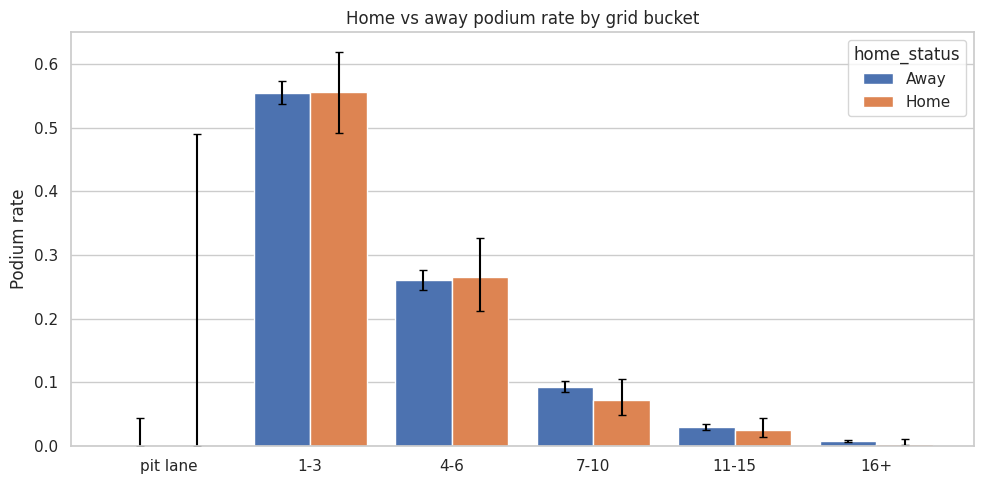

Q2 grid levels excluded from logit because outcome has no variation: ['pit lane']
Q2 constructor levels excluded from constructor logit because outcome has no variation: 42
Q2 controlled model table: (5, 6)


,model,effect_type,estimate,ci_low,ci_high,p_value
0,"Logit: grid position, clustered by race",odds_ratio,0.923082,0.780190,1.092144,0.350948
1,"Logit: grid + era + constructor, separated lev...",odds_ratio,0.978278,0.822711,1.163263,0.803725
2,"LPM: grid + constructor-season FE, clustered b...",coefficient,-0.005454,-0.017982,0.007075,0.393577
3,"LPM: grid + driver FE, clustered by race",coefficient,-0.001173,-0.014733,0.012388,0.865423
4,"Logit: grid position, year >= 2006, clustered ...",odds_ratio,0.877287,0.552662,1.392590,0.578683


Saved figure: figures_de/q2_home_odds_ratio_forest.png


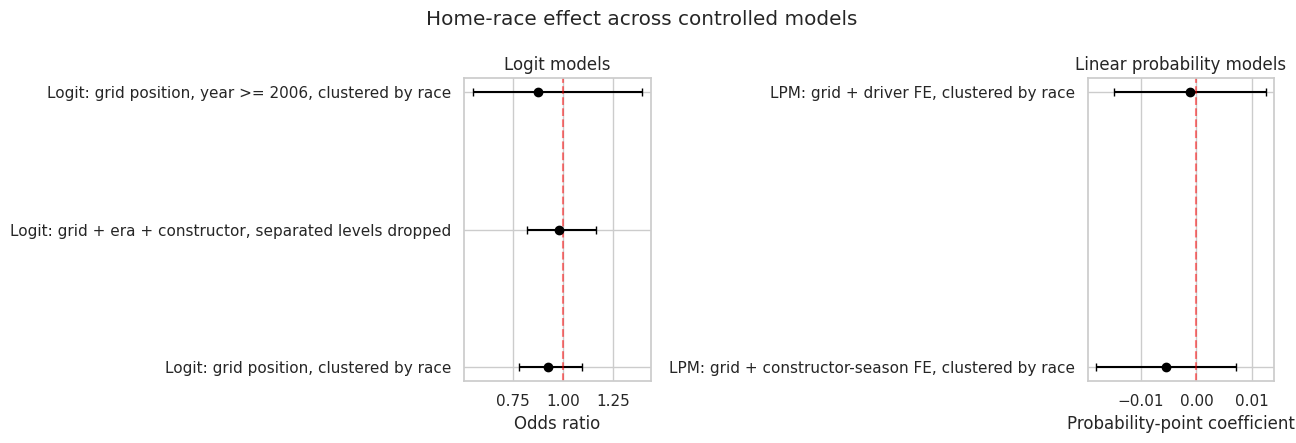

In [37]:
de_df = tables["results"].copy()
de_q2 = de_df[["resultId","raceId","driverId","constructorId","grid","positionOrder"]].copy()
de_q2["podium"] = de_q2["positionOrder"].le(3)
de_q2 = de_checked_merge(de_q2, tables["drivers"][["driverId","nationality"]].copy(), on="driverId", how="left", validate="many_to_one", name="Q2 results -> drivers")
de_q2 = de_checked_merge(de_q2, tables["races"][["raceId","year","circuitId"]].copy(), on="raceId", how="left", validate="many_to_one", name="Q2 -> races")
de_q2 = de_checked_merge(de_q2, tables["circuits"][["circuitId","country"]].copy().rename(columns={"country":"circuit_country"}), on="circuitId", how="left", validate="many_to_one", name="Q2 -> circuits")
de_q2["era_pre_2014"] = de_era_pre_2014(de_q2["year"])
de_nat_country = tables["nationality_country"][["nationality","country","hosted_a_race"]].copy().dropna(subset=["nationality","country"])
de_country_sets = de_nat_country.groupby("nationality")["country"].agg(lambda de_s: set(de_s.dropna())).to_dict()
de_q2_rows_before_home = len(de_q2)
de_q2["is_home"] = [de_country in de_country_sets.get(de_nat, set()) for de_nat, de_country in zip(de_q2["nationality"], de_q2["circuit_country"])]
assert len(de_q2) == de_q2_rows_before_home
de_q2_home_share = float(de_q2["is_home"].mean())
de_q2_hosted_nat = de_nat_country.loc[de_nat_country["hosted_a_race"].astype(bool)]
de_q2_multi_home_nationalities = de_nat_country.groupby("nationality")["country"].nunique().loc[lambda de_s: de_s.gt(1)]
print("Q2 home-race row share:", round(de_q2_home_share, 4))
print("Q2 drivers whose nationality can ever have a home race:", int(de_q2.loc[de_q2["nationality"].isin(set(de_q2_hosted_nat["nationality"])), "driverId"].nunique()))
print("Q2 mapped hosted home countries:", int(de_q2_hosted_nat["country"].nunique()))
print("Q2 nationalities mapped to multiple home countries:", int(len(de_q2_multi_home_nationalities)))

de_q2_raw = de_q2.groupby("is_home").agg(starts=("podium","size"), podiums=("podium","sum")).reset_index()
de_q2_raw["podium_rate"] = de_q2_raw["podiums"] / de_q2_raw["starts"]
de_q2_raw = de_add_wilson(de_q2_raw, "podiums", "starts", "podium_rate")
de_q2_raw["home_status"] = np.where(de_q2_raw["is_home"], "Home", "Away")
print("Q2 raw home vs away comparison:"); display(de_q2_raw[["home_status","podiums","starts","podium_rate","podium_rate_ci_low","podium_rate_ci_high"]])

de_grid_labels = ["pit lane","1-3","4-6","7-10","11-15","16+"]
de_q2["grid_bucket"] = pd.cut(de_q2["grid"], bins=[0,3,6,10,15,np.inf], labels=de_grid_labels[1:], include_lowest=True)
de_q2["grid_bucket"] = de_q2["grid_bucket"].astype(object)
de_q2.loc[de_q2["grid"].eq(0), "grid_bucket"] = "pit lane"
de_q2["grid_bucket"] = pd.Categorical(de_q2["grid_bucket"], categories=de_grid_labels, ordered=True)
de_q2_strata = de_q2.dropna(subset=["grid_bucket"]).groupby(["grid_bucket","is_home"], observed=True).agg(starts=("podium","size"), podiums=("podium","sum")).reset_index()
de_q2_strata["podium_rate"] = de_q2_strata["podiums"] / de_q2_strata["starts"]
de_q2_strata = de_add_wilson(de_q2_strata, "podiums", "starts", "podium_rate")
assert int(de_q2_strata["starts"].sum()) == len(de_q2.dropna(subset=["grid_bucket"]))
print("Q2 stratified table:", de_q2_strata.shape); display(de_q2_strata)
de_q2_plot = de_q2_strata.copy(); de_q2_plot["home_status"] = np.where(de_q2_plot["is_home"], "Home", "Away")
de_fig, de_ax = de_grouped_bar_ci(de_q2_plot, "grid_bucket", "podium_rate", "podium_rate_ci_low", "podium_rate_ci_high", "home_status", de_grid_labels, ["Away","Home"], "Home vs away podium rate by grid bucket", "Podium rate", 0, (10,5))
de_save_show(de_fig, "q2_home_away_grid_bucket.png")

de_q2_model = de_q2.dropna(subset=["grid_bucket","is_home","podium"]).copy()
de_q2_model["is_home_int"] = de_q2_model["is_home"].astype(int)
de_q2_model["podium_int"] = de_q2_model["podium"].astype(int)
de_q2_model["grid_position_model"] = np.select([de_q2_model["grid"].eq(0), de_q2_model["grid"].between(1,20), de_q2_model["grid"].gt(20)], ["pit lane", de_q2_model["grid"].astype("Int64").astype(str), "21+"], default=np.nan)
de_q2_model["era_model"] = de_q2_model["era_pre_2014"].astype(str)
de_q2_grid_variation = de_q2_model.groupby("grid_position_model")["podium_int"].agg(["size","sum"]).reset_index()
de_q2_separated_grid_levels = de_q2_grid_variation.loc[de_q2_grid_variation["sum"].isin([0]) | de_q2_grid_variation["sum"].eq(de_q2_grid_variation["size"]), "grid_position_model"].tolist()
de_q2_logit_model = de_q2_model.loc[~de_q2_model["grid_position_model"].isin(de_q2_separated_grid_levels)].copy()
print("Q2 grid levels excluded from logit because outcome has no variation:", de_q2_separated_grid_levels)

de_q2_logit = smf.logit("podium_int ~ is_home_int + C(grid_position_model)", data=de_q2_logit_model).fit(disp=False, maxiter=500, cov_type="cluster", cov_kwds={"groups": de_q2_logit_model["raceId"]})
de_q2_or = float(np.exp(de_q2_logit.params["is_home_int"]))
de_q2_ci = np.exp(de_q2_logit.conf_int().loc["is_home_int"])
de_q2_logit_2006_model = de_q2_logit_model.loc[de_q2_logit_model["year"].ge(de_matched_pre_start_year)].copy()
de_q2_logit_2006 = smf.logit("podium_int ~ is_home_int + C(grid_position_model)", data=de_q2_logit_2006_model).fit(disp=False, maxiter=500, cov_type="cluster", cov_kwds={"groups": de_q2_logit_2006_model["raceId"]})
de_q2_or_2006 = float(np.exp(de_q2_logit_2006.params["is_home_int"]))
de_q2_ci_2006 = np.exp(de_q2_logit_2006.conf_int().loc["is_home_int"])
de_q2_constructor_counts = de_q2_logit_model["constructorId"].value_counts()
de_q2_logit_model["constructor_model"] = de_q2_logit_model["constructorId"].where(de_q2_logit_model["constructorId"].map(de_q2_constructor_counts).ge(de_min_n), other=-1).astype(int).astype(str)
de_q2_constructor_variation = de_q2_logit_model.groupby("constructor_model")["podium_int"].agg(["size","sum"]).reset_index()
de_q2_separated_constructor_levels = de_q2_constructor_variation.loc[de_q2_constructor_variation["sum"].isin([0]) | de_q2_constructor_variation["sum"].eq(de_q2_constructor_variation["size"]), "constructor_model"].tolist()
de_q2_constructor_logit_model = de_q2_logit_model.loc[~de_q2_logit_model["constructor_model"].isin(de_q2_separated_constructor_levels)].copy()
print("Q2 constructor levels excluded from constructor logit because outcome has no variation:", len(de_q2_separated_constructor_levels))
de_q2_robust_logit = smf.logit("podium_int ~ is_home_int + C(grid_position_model) + C(era_model) + C(constructor_model)", data=de_q2_constructor_logit_model).fit(disp=False, maxiter=500, cov_type="cluster", cov_kwds={"groups": de_q2_constructor_logit_model["raceId"]})
de_q2_robust_or = float(np.exp(de_q2_robust_logit.params["is_home_int"]))
de_q2_robust_ci = np.exp(de_q2_robust_logit.conf_int().loc["is_home_int"])

de_q2_model["constructor_season"] = de_q2_model["constructorId"].astype(str) + "_" + de_q2_model["year"].astype(str)
de_q2_model["driver_model"] = de_q2_model["driverId"].astype(str)

def de_fit_lpm_fe(de_data, de_fe_col):
    de_x = pd.get_dummies(de_data["grid_position_model"], prefix="grid", drop_first=True, dtype=float)
    de_x.insert(0, "is_home_int", de_data["is_home_int"].astype(float).to_numpy())
    de_y = de_data["podium_int"].astype(float)
    de_fe = de_data[de_fe_col]
    de_x_resid = de_x - de_x.groupby(de_fe).transform("mean")
    de_y_resid = de_y - de_y.groupby(de_fe).transform("mean")
    de_keep_cols = de_x_resid.columns[de_x_resid.var().gt(0)]
    return sm.OLS(de_y_resid, de_x_resid[de_keep_cols]).fit(cov_type="cluster", cov_kwds={"groups": de_data["raceId"]})

de_q2_lpm_constructor_season = de_fit_lpm_fe(de_q2_model, "constructor_season")
de_q2_lpm_driver = de_fit_lpm_fe(de_q2_model, "driver_model")

de_q2_year_sensitivity_model_name = f"Logit: grid position, year >= {de_matched_pre_start_year}, clustered by race"
de_q2_or_table = pd.DataFrame({"model":["Logit: grid position, clustered by race","Logit: grid + era + constructor, separated levels dropped","LPM: grid + constructor-season FE, clustered by race","LPM: grid + driver FE, clustered by race",de_q2_year_sensitivity_model_name], "effect_type":["odds_ratio","odds_ratio","coefficient","coefficient","odds_ratio"], "estimate":[de_q2_or,de_q2_robust_or,float(de_q2_lpm_constructor_season.params["is_home_int"]),float(de_q2_lpm_driver.params["is_home_int"]),de_q2_or_2006], "ci_low":[float(de_q2_ci.iloc[0]),float(de_q2_robust_ci.iloc[0]),float(de_q2_lpm_constructor_season.conf_int().loc["is_home_int"].iloc[0]),float(de_q2_lpm_driver.conf_int().loc["is_home_int"].iloc[0]),float(de_q2_ci_2006.iloc[0])], "ci_high":[float(de_q2_ci.iloc[1]),float(de_q2_robust_ci.iloc[1]),float(de_q2_lpm_constructor_season.conf_int().loc["is_home_int"].iloc[1]),float(de_q2_lpm_driver.conf_int().loc["is_home_int"].iloc[1]),float(de_q2_ci_2006.iloc[1])], "p_value":[float(de_q2_logit.pvalues["is_home_int"]),float(de_q2_robust_logit.pvalues["is_home_int"]),float(de_q2_lpm_constructor_season.pvalues["is_home_int"]),float(de_q2_lpm_driver.pvalues["is_home_int"]),float(de_q2_logit_2006.pvalues["is_home_int"])]})
print("Q2 controlled model table:", de_q2_or_table.shape); display(de_q2_or_table)
de_q2_forest = de_q2_or_table.copy()
de_fig, de_axes = plt.subplots(1, 2, figsize=(13,4.5))
for de_ax, de_effect_type, de_reference, de_xlabel in [(de_axes[0], "odds_ratio", 1, "Odds ratio"), (de_axes[1], "coefficient", 0, "Probability-point coefficient")]:
    de_sub = de_q2_forest.loc[de_q2_forest["effect_type"].eq(de_effect_type)]
    de_ax.errorbar(de_sub["estimate"], de_sub["model"], xerr=[de_sub["estimate"]-de_sub["ci_low"], de_sub["ci_high"]-de_sub["estimate"]], fmt="o", color="black", capsize=3)
    de_ax.axvline(de_reference, color="red", linestyle="--", alpha=.5)
    de_ax.set_xlabel(de_xlabel)
de_axes[0].set_title("Logit models")
de_axes[1].set_title("Linear probability models")
de_fig.suptitle("Home-race effect across controlled models")
de_fig.tight_layout()
de_save_show(de_fig, "q2_home_odds_ratio_forest.png")


### 2.2.1 Q2 note on grain, missingness, and pre-race cutoff

The grain is one cleaned `results` row per race-driver start. Missing nationality or circuit country values cannot create a home match. Podium is a post-race outcome used only retrospectively; final position and status are never model features.

In [38]:
de_q2_raw_home = de_q2_raw.loc[de_q2_raw["is_home"]].iloc[0]
de_q2_raw_away = de_q2_raw.loc[~de_q2_raw["is_home"]].iloc[0]
de_q2_or_rows = de_q2_or_table.loc[de_q2_or_table["effect_type"].eq("odds_ratio")]
de_q2_lpm_rows = de_q2_or_table.loc[de_q2_or_table["effect_type"].eq("coefficient")]
de_q2_all_ci_include_null = bool(de_q2_or_rows["ci_low"].le(1).all() and de_q2_or_rows["ci_high"].ge(1).all() and de_q2_lpm_rows["ci_low"].le(0).all() and de_q2_lpm_rows["ci_high"].ge(0).all())
de_q2_model_summary_text = "; ".join(f"{de_row.model}: {de_row.estimate:.2f} [{de_row.ci_low:.2f}, {de_row.ci_high:.2f}]" for de_row in de_q2_or_rows.itertuples())
de_q2_lpm_summary_text = "; ".join(f"{de_row.model}: {de_row.estimate:.3f} [{de_row.ci_low:.3f}, {de_row.ci_high:.3f}]" for de_row in de_q2_lpm_rows.itertuples())
de_q2_year_sensitivity_row_pos = int(de_q2_or_table["model"].tolist().index(de_q2_year_sensitivity_model_name)) + 1
if de_q2_all_ci_include_null:
    de_q2_conclusion = "After controlling for grid position there is no detectable home-race advantage; the raw home<away gap is associated with differences in grid position, car quality, and local one-off entries. These are associations, not evidence of a causal home-race effect."
else:
    de_q2_conclusion = "At least one controlled model has a confidence interval excluding the null, so the controlled results are not uniformly consistent with no home-race effect."
de_q2_answer = (
    f"Q2 answer: Home-race rows are {de_q2_home_share:.1%} of cleaned race-driver starts. "
    f"Raw podium rates are {de_q2_raw_home['podium_rate']:.1%} at home ({int(de_q2_raw_home['podiums'])}/{int(de_q2_raw_home['starts'])}) and {de_q2_raw_away['podium_rate']:.1%} away ({int(de_q2_raw_away['podiums'])}/{int(de_q2_raw_away['starts'])}). "
    f"Odds-ratio models: {de_q2_model_summary_text}. "
    f"LPM sensitivities: {de_q2_lpm_summary_text}. "
    f"The year>={de_matched_pre_start_year} sensitivity is included as row {de_q2_year_sensitivity_row_pos} of de_q2_or_table. {de_q2_conclusion} "
    "Limitations: nationality is only a proxy for home race, dual-nationality mappings can assign more than one home country, home races are few, and association is not causation."
)
print(de_q2_answer)


Q2 answer: Home-race rows are 7.9% of cleaned race-driver starts. Raw podium rates are 11.6% at home (224/1932) and 13.8% away (3118/22634). Odds-ratio models: Logit: grid position, clustered by race: 0.92 [0.78, 1.09]; Logit: grid + era + constructor, separated levels dropped: 0.98 [0.82, 1.16]; Logit: grid position, year >= 2006, clustered by race: 0.88 [0.55, 1.39]. LPM sensitivities: LPM: grid + constructor-season FE, clustered by race: -0.005 [-0.018, 0.007]; LPM: grid + driver FE, clustered by race: -0.001 [-0.015, 0.012]. The year>=2006 sensitivity is included as row 5 of de_q2_or_table. After controlling for grid position there is no detectable home-race advantage; the raw home<away gap is associated with differences in grid position, car quality, and local one-off entries. These are associations, not evidence of a causal home-race effect. Limitations: nationality is only a proxy for home race, dual-nationality mappings can assign more than one home country, home races are few,

### 2.2.2 Q2 written answer

The raw comparison is intentionally shown before controls: `de_q2_raw` reports home vs away podium rates with Wilson intervals. The controlled conclusion is generated in `de_q2_answer` from `de_q2_or_table`: odds-ratio rows are checked against 1 and linear-probability rows are checked against 0.

The controlled models use `grid=0` as its own pit-lane level in the descriptive stratification. For logit models, separated levels with no podium variation are excluded and the standard errors are clustered by `raceId`. The model table reports the base grid-position logit, a year `>=2006` grid-position sensitivity, a grid+era+constructor logit, a constructor-season fixed-effect linear probability model, and a within-driver fixed-effect linear probability model. The forest plot is split into two panels: logit-model odds ratios (reference line at 1) and linear-probability-model probability-point coefficients (reference line at 0), covering all five estimates.

Grain: one cleaned `results` row per `(raceId, driverId)`. Missingness: `grid`, `positionOrder`, race country, and driver nationality are available for the model rows after the checked joins. Pre-race cutoff: home status, circuit country, nationality, constructor, season, and grid are pre-race or entry attributes; podium is the retrospective outcome. Limitations: nationality is a proxy for home race, not birthplace or residence; dual nationalities are mapped to multiple home countries where the lookup table supplies them; and association is not causation.


## 2.3 Q3. Mechanical-retirement rate by constructor

The denominator is starts: all cleaned result rows in 2014-2024, split into 2014-2021 and 2022-2024. Status is post-race and is used only for retrospective classification.

In [39]:
de_df = tables["results"].copy()
de_q3 = de_df[["resultId","raceId","driverId","constructorId","statusId"]].copy()
assert de_q3["statusId"].notna().all()
de_q3 = de_checked_merge(de_q3, tables["status"][["statusId","status"]].copy(), on="statusId", how="left", validate="many_to_one", name="Q3 results -> status")
de_q3 = de_checked_merge(de_q3, tables["races"][["raceId","year"]].copy(), on="raceId", how="left", validate="many_to_one", name="Q3 -> races")
de_q3 = de_checked_merge(de_q3, tables["constructors"][["constructorId","name"]].copy().rename(columns={"name":"constructor_name"}), on="constructorId", how="left", validate="many_to_one", name="Q3 -> constructors")
de_q3 = de_q3.loc[de_q3["year"].between(de_hybrid_start_year, de_q3_new_end_year)].copy()
de_q3["q3_era"] = de_era_q3(de_q3["year"])
de_q3 = de_q3.dropna(subset=["q3_era"]).copy()
assert de_q3["statusId"].notna().all()
print(f"Q3 analysis shape after {de_hybrid_start_year}-{de_q3_new_end_year} filter:", de_q3.shape)
de_q3_status_counts = de_q3["status"].value_counts(dropna=False).rename_axis("status").reset_index(name="count")
print("Q3 full status mapping input table sorted by count:")
with pd.option_context("display.max_rows", None):
    display(de_q3_status_counts)
de_q3_suspicious_statuses = de_q3_status_counts.loc[de_q3_status_counts["status"].astype(str).str.contains(r"Did not qualify|prequal|Withdrew|107%|Failed to qualify|Did not start|DNS", case=False, regex=True, na=False)]
print("Q3 suspicious non-start-like statuses after cleaning:"); display(de_q3_suspicious_statuses)

de_finished_statuses = {"Finished"}
de_mechanical_strict = {"Engine","Gearbox","Transmission","Clutch","Hydraulics","Electrical","Suspension","Brakes","Overheating","Fuel system","Oil leak","Water leak","Wheel","Wheel bearing","Fuel pressure","Fuel pump","Power Unit","ERS","Turbo","Battery","Electronics","Driveshaft","Axle","Radiator","Ignition","Oil pressure","Pneumatics","Power loss","MGU-K","MGU-H","Exhaust","Cooling system","Water pressure","Water pump","Fuel leak","Differential","Mechanical","Technical","Throttle","Steering","Drivetrain","Spark plugs","Brake duct"}
de_accident_driver = {"Accident","Collision","Collision damage","Spun off","Driver Seat","Physical","Injured","Illness","Driver unwell","Eye injury","Front wing","Rear wing","Seat"}
de_regulation = {"Disqualified","Excluded","Did not qualify","Did not prequalify","Withdrew","107% Rule","Not restarted","Safety concerns"}
de_ambiguous_lenient_mechanical = {"Retired","Damage","Puncture","Debris","Wheel nut","Vibrations","Tyre","Tyre puncture","Handling","Undertray","Floor","Bodywork","Out of fuel"}
de_ambiguous_other = set()

def de_status_category(de_status_value, de_lenient=False):
    if pd.isna(de_status_value): return "UNREVIEWED"
    de_text = str(de_status_value)
    if de_text in de_finished_statuses or re.fullmatch(r"\+\d+ Laps?", de_text): return "finished"
    if de_text in de_mechanical_strict: return "mechanical"
    if de_lenient and de_text in de_ambiguous_lenient_mechanical: return "mechanical"
    if de_text in de_accident_driver: return "accident-driver"
    if de_text in de_regulation: return "regulation"
    if de_text in de_ambiguous_lenient_mechanical or de_text in de_ambiguous_other: return "ambiguous-other"
    return "UNREVIEWED"

de_q3_status_mapping = de_q3_status_counts.copy()
de_q3_status_mapping["strict_category"] = de_q3_status_mapping["status"].map(lambda de_x: de_status_category(de_x, False))
de_q3_status_mapping["lenient_category"] = de_q3_status_mapping["status"].map(lambda de_x: de_status_category(de_x, True))
de_q3_status_mapping["ambiguous_note"] = np.where(de_q3_status_mapping["status"].isin(de_ambiguous_lenient_mechanical), "ambiguous; mechanical only in lenient mapping", "")
de_q3_unreviewed = de_q3_status_mapping.loc[de_q3_status_mapping[["strict_category","lenient_category"]].eq("UNREVIEWED").any(axis=1)]
print("Q3 UNREVIEWED statuses:"); display(de_q3_unreviewed)
assert de_q3_unreviewed.empty, "Review and classify all Q3 statuses before continuing"
de_q3_ambiguous_present = de_q3_status_mapping.loc[de_q3_status_mapping["ambiguous_note"].ne(""), ["status","count","strict_category","lenient_category"]].copy()
print("Q3 final documented status mapping table:")
with pd.option_context("display.max_rows", None):
    display(de_q3_status_mapping.sort_values(["strict_category","status"]))
print("Q3 ambiguous statuses present:"); display(de_q3_ambiguous_present)
de_q3["strict_category"] = de_q3["status"].map(lambda de_x: de_status_category(de_x, False))
de_q3["lenient_category"] = de_q3["status"].map(lambda de_x: de_status_category(de_x, True))
assert not de_q3[["strict_category","lenient_category"]].eq("UNREVIEWED").any().any()


Q3 results -> status: before=(24566, 5), after=(24566, 6)
Q3 -> races: before=(24566, 6), after=(24566, 7)
Q3 -> constructors: before=(24566, 7), after=(24566, 8)
Q3 analysis shape after 2014-2024 filter: (4595, 9)
Q3 full status mapping input table sorted by count:


,status,count
0,Finished,2403
1,+1 Lap,1178
2,+2 Laps,208
3,Collision,150
4,Accident,85
5,Engine,79
6,Collision damage,59
7,Retired,49
8,Brakes,48
9,Gearbox,40


Q3 suspicious non-start-like statuses after cleaning:


,status,count


Q3 UNREVIEWED statuses:


,status,count,strict_category,lenient_category,ambiguous_note


Q3 final documented status mapping table:


,status,count,strict_category,lenient_category,ambiguous_note
4,Accident,85,accident-driver,accident-driver,
3,Collision,150,accident-driver,accident-driver,
6,Collision damage,59,accident-driver,accident-driver,
34,Front wing,3,accident-driver,accident-driver,
40,Illness,2,accident-driver,accident-driver,
37,Rear wing,3,accident-driver,accident-driver,
54,Seat,1,accident-driver,accident-driver,
17,Spun off,11,accident-driver,accident-driver,
48,Damage,2,ambiguous-other,mechanical,ambiguous; mechanical only in lenient mapping
56,Debris,1,ambiguous-other,mechanical,ambiguous; mechanical only in lenient mapping


Q3 ambiguous statuses present:


,status,count,strict_category,lenient_category
7,Retired,49,ambiguous-other,mechanical
21,Puncture,7,ambiguous-other,mechanical
32,Tyre,4,ambiguous-other,mechanical
33,Undertray,4,ambiguous-other,mechanical
35,Wheel nut,3,ambiguous-other,mechanical
44,Vibrations,2,ambiguous-other,mechanical
48,Damage,2,ambiguous-other,mechanical
53,Out of fuel,1,ambiguous-other,mechanical
56,Debris,1,ambiguous-other,mechanical


Q3 constructor candidates in 2014-2024:


,constructorId,constructor_name
22028,51,Alfa Romeo
22447,213,AlphaTauri
22790,214,Alpine F1 Team
22787,117,Aston Martin
19986,207,Caterham
19973,6,Ferrari
19975,10,Force India
20750,210,Haas F1 Team
19984,208,Lotus F1
20403,209,Manor Marussia


Q3 constructor lineage table:


,constructorId,constructor_name,constructor_lineage
22028,51,Alfa Romeo,Sauber/Alfa Romeo/Sauber
22447,213,AlphaTauri,Toro Rosso/AlphaTauri/RB
22790,214,Alpine F1 Team,Lotus/Renault/Alpine
22787,117,Aston Martin,Force India/Racing Point/Aston Martin
19986,207,Caterham,Caterham
19973,6,Ferrari,Ferrari
19975,10,Force India,Force India/Racing Point/Aston Martin
20750,210,Haas F1 Team,Haas F1 Team
19984,208,Lotus F1,Lotus/Renault/Alpine
20403,209,Manor Marussia,Marussia/Manor Marussia


Q3 de_merge_lineages: True
Q3 strict by constructor name: (31, 8)


...

Q3 strict constructor era A -> era B: before=(10, 6), after=(10, 11)
Q3 lenient constructor era A -> era B: before=(10, 6), after=(10, 11)
Q3 strict per-constructor era change (full n>=10 table):


,constructor,starts_2014_2021,mechanical_2014_2021,rate_2014_2021,rate_2014_2021_ci_low,rate_2014_2021_ci_high,starts_2022_2024,mechanical_2022_2024,rate_2022_2024,rate_2022_2024_ci_low,rate_2022_2024_ci_high,rate_delta_2022_2024_minus_2014_2021,rate_delta_ci_low,rate_delta_ci_high
5,Sauber/Alfa Romeo/Sauber,319,26,0.081505,0.056226,0.116743,136,12,0.088235,0.051195,0.147898,0.006731,-0.044394,0.071528
9,Mercedes,320,12,0.037500,0.021580,0.064393,136,6,0.044118,0.020374,0.092908,0.006618,-0.029257,0.057939
8,Ferrari,318,18,0.056604,0.036101,0.087691,134,6,0.044776,0.020680,0.094245,-0.011828,-0.051160,0.041721
6,Williams,319,24,0.075235,0.051076,0.109503,134,7,0.052239,0.025532,0.103903,-0.022996,-0.066442,0.034037
7,Force India/Racing Point/Aston Martin,317,18,0.056782,0.036216,0.087962,133,4,0.030075,0.011757,0.074778,-0.026707,-0.062870,0.022499
1,Lotus/Renault/Alpine,318,43,0.135220,0.101962,0.177186,135,14,0.103704,0.062785,0.166552,-0.031516,-0.090130,0.039590
4,Haas F1 Team,240,21,0.087500,0.057942,0.130055,135,6,0.044444,0.020526,0.093571,-0.043056,-0.091872,0.014278
3,Red Bull,318,34,0.106918,0.077526,0.145694,136,5,0.036765,0.015804,0.083176,-0.070154,-0.114232,-0.015218
0,Toro Rosso/AlphaTauri/RB,319,46,0.144201,0.109881,0.186987,136,8,0.058824,0.030105,0.111780,-0.085377,-0.136908,-0.022272
2,McLaren,315,42,0.133333,0.100178,0.175324,136,5,0.036765,0.015804,0.083176,-0.096569,-0.143500,-0.039531


Q3 lenient per-constructor era change (full n>=10 table):


,constructor,starts_2014_2021,mechanical_2014_2021,rate_2014_2021,rate_2014_2021_ci_low,rate_2014_2021_ci_high,starts_2022_2024,mechanical_2022_2024,rate_2022_2024,rate_2022_2024_ci_low,rate_2022_2024_ci_high,rate_delta_2022_2024_minus_2014_2021,rate_delta_ci_low,rate_delta_ci_high
5,Sauber/Alfa Romeo/Sauber,319,31,0.097179,0.069308,0.134636,136,14,0.102941,0.062315,0.165382,0.005762,-0.049496,0.074141
8,Ferrari,318,20,0.062893,0.041079,0.095142,134,9,0.067164,0.035735,0.122719,0.004271,-0.040760,0.063955
9,Mercedes,320,16,0.050000,0.031008,0.079668,136,6,0.044118,0.020374,0.092908,-0.005882,-0.043882,0.046474
7,Force India/Racing Point/Aston Martin,317,20,0.063091,0.041210,0.095435,133,7,0.052632,0.025726,0.104655,-0.010460,-0.052532,0.045978
6,Williams,319,31,0.097179,0.069308,0.134636,134,11,0.082090,0.046454,0.141018,-0.015089,-0.066789,0.050098
1,Lotus/Renault/Alpine,318,51,0.160377,0.124136,0.204726,135,14,0.103704,0.062785,0.166552,-0.056674,-0.117016,0.015875
4,Red Bull,318,37,0.116352,0.085602,0.156261,136,6,0.044118,0.020374,0.092908,-0.072235,-0.118672,-0.014563
0,Toro Rosso/AlphaTauri/RB,319,52,0.163009,0.126528,0.207510,136,12,0.088235,0.051195,0.147898,-0.074774,-0.132674,-0.004841
3,Haas F1 Team,240,29,0.120833,0.085463,0.168150,135,6,0.044444,0.020526,0.093571,-0.076389,-0.129407,-0.015854
2,McLaren,315,48,0.152381,0.116899,0.196239,136,5,0.036765,0.015804,0.083176,-0.115616,-0.164226,-0.057196


Q3 headline exclusion note: constructors with <100 starts, e.g. Caterham (7/33 in 2014-2021), are excluded from the headline.
Q3 highest-rate small-sample constructor in the n>=10 strict table: Caterham in 2014-2021 at 21.2% (7/33).
Saved figure: figures_de/q3_mechanical_rate_constructor.png


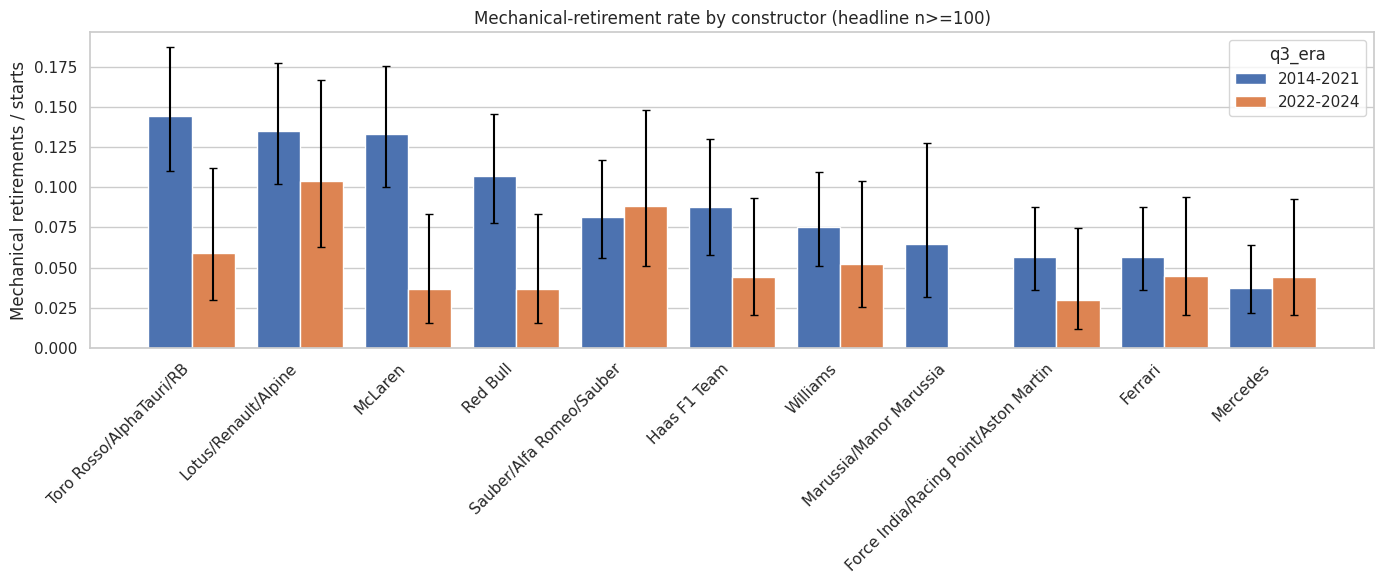

Saved figure: figures_de/q3_mechanical_rate_era_change.png


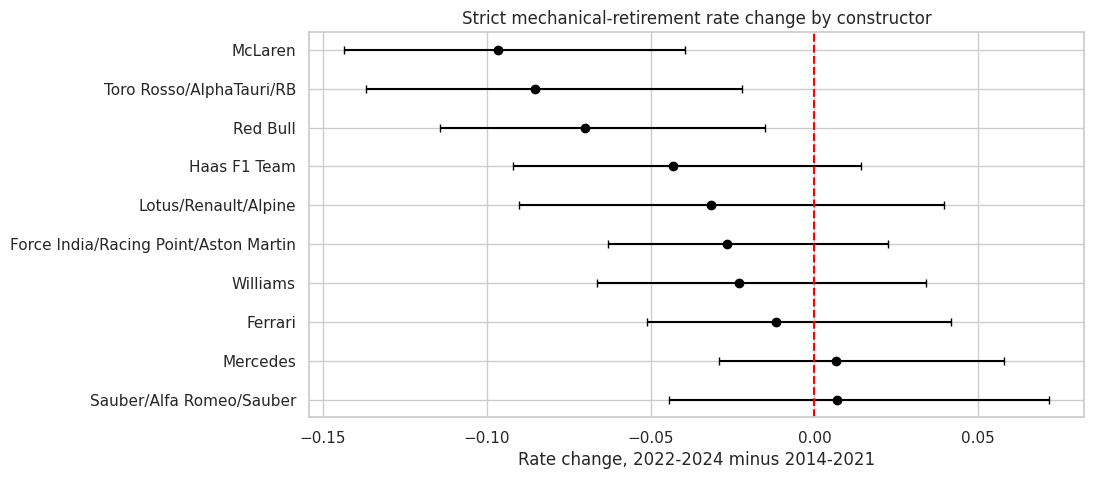

In [40]:
de_q3_constructor_candidates = de_q3[["constructorId","constructor_name"]].drop_duplicates().sort_values(["constructor_name","constructorId"])
print(f"Q3 constructor candidates in {de_hybrid_start_year}-{de_q3_new_end_year}:"); display(de_q3_constructor_candidates)
de_lineage_by_name = {"Force India":"Force India/Racing Point/Aston Martin","Racing Point":"Force India/Racing Point/Aston Martin","Aston Martin":"Force India/Racing Point/Aston Martin","Toro Rosso":"Toro Rosso/AlphaTauri/RB","AlphaTauri":"Toro Rosso/AlphaTauri/RB","RB F1 Team":"Toro Rosso/AlphaTauri/RB","RB":"Toro Rosso/AlphaTauri/RB","Lotus F1":"Lotus/Renault/Alpine","Renault":"Lotus/Renault/Alpine","Alpine F1 Team":"Lotus/Renault/Alpine","Sauber":"Sauber/Alfa Romeo/Sauber","Alfa Romeo":"Sauber/Alfa Romeo/Sauber","Marussia":"Marussia/Manor Marussia","Manor Marussia":"Marussia/Manor Marussia"}
de_q3_lineage_table = de_q3_constructor_candidates.copy()
de_q3_lineage_table["constructor_lineage"] = de_q3_lineage_table["constructor_name"].map(de_lineage_by_name).fillna(de_q3_lineage_table["constructor_name"])
print("Q3 constructor lineage table:"); display(de_q3_lineage_table)
de_q3["constructor_lineage"] = de_q3["constructor_name"].map(de_lineage_by_name).fillna(de_q3["constructor_name"])
de_q3["constructor_group"] = np.where(de_merge_lineages, de_q3["constructor_lineage"], de_q3["constructor_name"])
print("Q3 de_merge_lineages:", de_merge_lineages)

def de_mechanical_rate_table(de_df, de_category_col, de_constructor_col, de_min_starts=de_min_n):
    de_calc = de_df.copy(); de_calc["is_mechanical"] = de_calc[de_category_col].eq("mechanical")
    de_out = de_calc.groupby(["q3_era",de_constructor_col]).agg(starts=("is_mechanical","size"), mechanical_retirements=("is_mechanical","sum")).reset_index().rename(columns={de_constructor_col:"constructor"})
    de_out["mechanical_rate"] = de_out["mechanical_retirements"] / de_out["starts"]
    de_out = de_add_wilson(de_out, "mechanical_retirements", "starts", "mechanical_rate")
    de_out = de_out.loc[de_out["starts"] >= de_min_starts].copy()
    de_out["rank"] = de_out.groupby("q3_era")["mechanical_rate"].rank(ascending=False, method="min")
    return de_out.sort_values(["q3_era","rank","starts"], ascending=[True,True,False])

def de_era_change_table(de_table, de_mapping):
    de_a = de_table.loc[de_table["q3_era"].eq(de_q3_era_a), ["constructor","starts","mechanical_retirements","mechanical_rate","mechanical_rate_ci_low","mechanical_rate_ci_high"]].rename(columns={"starts":"starts_2014_2021","mechanical_retirements":"mechanical_2014_2021","mechanical_rate":"rate_2014_2021","mechanical_rate_ci_low":"rate_2014_2021_ci_low","mechanical_rate_ci_high":"rate_2014_2021_ci_high"})
    de_b = de_table.loc[de_table["q3_era"].eq(de_q3_era_b), ["constructor","starts","mechanical_retirements","mechanical_rate","mechanical_rate_ci_low","mechanical_rate_ci_high"]].rename(columns={"starts":"starts_2022_2024","mechanical_retirements":"mechanical_2022_2024","mechanical_rate":"rate_2022_2024","mechanical_rate_ci_low":"rate_2022_2024_ci_low","mechanical_rate_ci_high":"rate_2022_2024_ci_high"})
    de_common_constructors = sorted(set(de_a["constructor"]) & set(de_b["constructor"]))
    de_a = de_a.loc[de_a["constructor"].isin(de_common_constructors)].copy()
    de_b = de_b.loc[de_b["constructor"].isin(de_common_constructors)].copy()
    de_out = de_checked_merge(de_a, de_b, on="constructor", how="left", validate="one_to_one", name=f"Q3 {de_mapping} constructor era A -> era B")
    de_out["rate_delta_2022_2024_minus_2014_2021"] = de_out["rate_2022_2024"] - de_out["rate_2014_2021"]
    de_out["rate_delta_ci_low"] = de_out["rate_delta_2022_2024_minus_2014_2021"] - np.sqrt((de_out["rate_2022_2024"] - de_out["rate_2022_2024_ci_low"])**2 + (de_out["rate_2014_2021_ci_high"] - de_out["rate_2014_2021"])**2)
    de_out["rate_delta_ci_high"] = de_out["rate_delta_2022_2024_minus_2014_2021"] + np.sqrt((de_out["rate_2022_2024_ci_high"] - de_out["rate_2022_2024"])**2 + (de_out["rate_2014_2021"] - de_out["rate_2014_2021_ci_low"])**2)
    return de_out.sort_values("rate_delta_2022_2024_minus_2014_2021", ascending=False)

de_q3_era_a = "2014-2021"; de_q3_era_b = "2022-2024"
de_q3_strict_by_name = de_mechanical_rate_table(de_q3, "strict_category", "constructor_name")
de_q3_lenient_by_name = de_mechanical_rate_table(de_q3, "lenient_category", "constructor_name")
de_q3_strict_table_full = de_mechanical_rate_table(de_q3, "strict_category", "constructor_group", de_min_n)
de_q3_lenient_table_full = de_mechanical_rate_table(de_q3, "lenient_category", "constructor_group", de_min_n)
de_q3_strict_table = de_mechanical_rate_table(de_q3, "strict_category", "constructor_group", de_min_n_headline)
de_q3_lenient_table = de_mechanical_rate_table(de_q3, "lenient_category", "constructor_group", de_min_n_headline)
print("Q3 strict by constructor name:", de_q3_strict_by_name.shape); display(de_q3_strict_by_name)
print("Q3 lenient by constructor name:", de_q3_lenient_by_name.shape); display(de_q3_lenient_by_name)
print(f"Q3 strict selected lineage headline table (n>={de_min_n_headline}):", de_q3_strict_table.shape); display(de_q3_strict_table)
print(f"Q3 lenient selected lineage headline table (n>={de_min_n_headline}):", de_q3_lenient_table.shape); display(de_q3_lenient_table)
print(f"Q3 strict selected lineage full table (n>={de_min_n}; small samples included):", de_q3_strict_table_full.shape); display(de_q3_strict_table_full)
print(f"Q3 lenient selected lineage full table (n>={de_min_n}; small samples included):", de_q3_lenient_table_full.shape); display(de_q3_lenient_table_full)

de_q3_rank_change = de_checked_merge(de_q3_strict_table[["q3_era","constructor","rank","mechanical_rate"]].rename(columns={"rank":"strict_rank","mechanical_rate":"strict_rate"}), de_q3_lenient_table[["q3_era","constructor","rank","mechanical_rate"]].rename(columns={"rank":"lenient_rank","mechanical_rate":"lenient_rate"}), on=["q3_era","constructor"], how="left", validate="one_to_one", name="Q3 strict rank -> lenient rank")
de_q3_rank_change["rank_delta_lenient_minus_strict"] = de_q3_rank_change["lenient_rank"] - de_q3_rank_change["strict_rank"]
print("Q3 strict vs lenient rank comparison:"); display(de_q3_rank_change)
de_q3_only_a = sorted(set(de_q3_strict_table.loc[de_q3_strict_table["q3_era"].eq(de_q3_era_a), "constructor"]) - set(de_q3_strict_table.loc[de_q3_strict_table["q3_era"].eq(de_q3_era_b), "constructor"]))
de_q3_only_b = sorted(set(de_q3_strict_table.loc[de_q3_strict_table["q3_era"].eq(de_q3_era_b), "constructor"]) - set(de_q3_strict_table.loc[de_q3_strict_table["q3_era"].eq(de_q3_era_a), "constructor"]))
print(f"Q3 constructors only in {de_q3_era_a}:", de_q3_only_a)
print(f"Q3 constructors only in {de_q3_era_b}:", de_q3_only_b)

de_q3_era_level_strict = de_q3.assign(is_mechanical=de_q3["strict_category"].eq("mechanical")).groupby("q3_era").agg(starts=("is_mechanical","size"), mechanical_retirements=("is_mechanical","sum")).reset_index()
de_q3_era_level_strict["mechanical_rate"] = de_q3_era_level_strict["mechanical_retirements"] / de_q3_era_level_strict["starts"]
de_q3_era_level_strict = de_add_wilson(de_q3_era_level_strict, "mechanical_retirements", "starts", "mechanical_rate")
de_q3_era_level_strict["mapping"] = "strict"
de_q3_era_level_lenient = de_q3.assign(is_mechanical=de_q3["lenient_category"].eq("mechanical")).groupby("q3_era").agg(starts=("is_mechanical","size"), mechanical_retirements=("is_mechanical","sum")).reset_index()
de_q3_era_level_lenient["mechanical_rate"] = de_q3_era_level_lenient["mechanical_retirements"] / de_q3_era_level_lenient["starts"]
de_q3_era_level_lenient = de_add_wilson(de_q3_era_level_lenient, "mechanical_retirements", "starts", "mechanical_rate")
de_q3_era_level_lenient["mapping"] = "lenient"
de_q3_era_level = pd.concat([de_q3_era_level_strict, de_q3_era_level_lenient], ignore_index=True)
de_q3_ztest_rows = []
for de_mapping, de_sub in de_q3_era_level.groupby("mapping"):
    de_sub = de_sub.set_index("q3_era").loc[[de_q3_era_a, de_q3_era_b]]
    de_z, de_p = proportions_ztest(de_sub["mechanical_retirements"].to_numpy(), de_sub["starts"].to_numpy())
    de_cluster = de_q3.copy()
    de_cluster["is_new_era_int"] = de_cluster["q3_era"].eq(de_q3_era_b).astype(int)
    de_cluster["is_mechanical_int"] = de_cluster[f"{de_mapping}_category"].eq("mechanical").astype(int)
    de_cluster_logit = smf.logit("is_mechanical_int ~ is_new_era_int", data=de_cluster).fit(disp=False, maxiter=500, cov_type="cluster", cov_kwds={"groups": de_cluster["raceId"]})
    de_q3_ztest_rows.append({"mapping":de_mapping,"z_stat":float(de_z),"p_value":float(de_p),"cluster_logit_p_value":float(de_cluster_logit.pvalues["is_new_era_int"]),"rate_delta_2022_2024_minus_2014_2021":float(de_sub.loc[de_q3_era_b,"mechanical_rate"] - de_sub.loc[de_q3_era_a,"mechanical_rate"])})
de_q3_ztest_table = pd.DataFrame(de_q3_ztest_rows)
print("Q3 era-level mechanical-retirement rates:"); display(de_q3_era_level)
print("Q3 era-level two-proportion z-tests:"); display(de_q3_ztest_table)

de_q3_strict_era_change = de_era_change_table(de_q3_strict_table_full, "strict")
de_q3_lenient_era_change = de_era_change_table(de_q3_lenient_table_full, "lenient")
print(f"Q3 strict per-constructor era change (full n>={de_min_n} table):"); display(de_q3_strict_era_change)
print(f"Q3 lenient per-constructor era change (full n>={de_min_n} table):"); display(de_q3_lenient_era_change)

de_q3_small_sample_strict = de_q3_strict_table_full.loc[de_q3_strict_table_full["starts"].lt(de_min_n_headline)].sort_values("mechanical_rate", ascending=False)
de_q3_highest_small_sample = de_q3_small_sample_strict.head(1)
de_q3_caterham_rows = de_q3_strict_table_full.loc[de_q3_strict_table_full["constructor"].eq("Caterham")]
if not de_q3_caterham_rows.empty:
    de_q3_caterham_example = de_q3_caterham_rows.sort_values("mechanical_rate", ascending=False).iloc[0]
    print(f"Q3 headline exclusion note: constructors with <{de_min_n_headline} starts, e.g. {de_q3_caterham_example['constructor']} ({int(de_q3_caterham_example['mechanical_retirements'])}/{int(de_q3_caterham_example['starts'])} in {de_q3_caterham_example['q3_era']}), are excluded from the headline.")
if not de_q3_highest_small_sample.empty:
    de_q3_small = de_q3_highest_small_sample.iloc[0]
    print(f"Q3 highest-rate small-sample constructor in the n>={de_min_n} strict table: {de_q3_small['constructor']} in {de_q3_small['q3_era']} at {de_q3_small['mechanical_rate']:.1%} ({int(de_q3_small['mechanical_retirements'])}/{int(de_q3_small['starts'])}).")

de_q3_order = de_q3_strict_table.groupby("constructor")["mechanical_rate"].max().sort_values(ascending=False).index.tolist()
de_fig, de_ax = de_grouped_bar_ci(de_q3_strict_table, "constructor", "mechanical_rate", "mechanical_rate_ci_low", "mechanical_rate_ci_high", "q3_era", de_q3_order, [de_q3_era_a,de_q3_era_b], f"Mechanical-retirement rate by constructor (headline n>={de_min_n_headline})", "Mechanical retirements / starts", 45, (14,6))
de_save_show(de_fig, "q3_mechanical_rate_constructor.png")

de_q3_change_plot = de_q3_strict_era_change.copy()
de_fig, de_ax = plt.subplots(figsize=(10,5))
de_ax.errorbar(de_q3_change_plot["rate_delta_2022_2024_minus_2014_2021"], de_q3_change_plot["constructor"], xerr=[de_q3_change_plot["rate_delta_2022_2024_minus_2014_2021"]-de_q3_change_plot["rate_delta_ci_low"], de_q3_change_plot["rate_delta_ci_high"]-de_q3_change_plot["rate_delta_2022_2024_minus_2014_2021"]], fmt="o", color="black", capsize=3)
de_ax.axvline(0, color="red", linestyle="--"); de_ax.set_title("Strict mechanical-retirement rate change by constructor"); de_ax.set_xlabel(f"Rate change, {de_q3_era_b} minus {de_q3_era_a}")
de_save_show(de_fig, "q3_mechanical_rate_era_change.png")


### 2.3.1 Q3 note on grain, missingness, and pre-race cutoff

The denominator is all cleaned starts in each constructor-era group. Status is post-race and is used only to retrospectively classify retirement causes, never as a prediction feature. Ambiguous statuses are separated by strict versus lenient mappings; lineage merging is controlled by `de_merge_lineages`.

In [41]:
de_q3_top5 = de_q3_strict_table.sort_values(["q3_era","rank","starts"], ascending=[True,True,False]).groupby("q3_era").head(5).copy()
print(f"Q3 top 5 constructors per era, strict selected lineage headline table (n>={de_min_n_headline}):")
display(de_q3_top5)
de_q3_best_2014 = de_q3_strict_table.loc[de_q3_strict_table["q3_era"].eq(de_q3_era_a)].head(1)
de_q3_best_2022 = de_q3_strict_table.loc[de_q3_strict_table["q3_era"].eq(de_q3_era_b)].head(1)
de_q3_lenient_best_2014 = de_q3_lenient_table.loc[de_q3_lenient_table["q3_era"].eq(de_q3_era_a)].head(1)
de_q3_lenient_best_2022 = de_q3_lenient_table.loc[de_q3_lenient_table["q3_era"].eq(de_q3_era_b)].head(1)
de_q3_top_changes = (de_q3_best_2014.iloc[0]["constructor"] != de_q3_lenient_best_2014.iloc[0]["constructor"]) or (de_q3_best_2022.iloc[0]["constructor"] != de_q3_lenient_best_2022.iloc[0]["constructor"])

def de_q3_era_rate_text(de_mapping):
    de_rates = de_q3_era_level.loc[de_q3_era_level["mapping"].eq(de_mapping)].set_index("q3_era")
    de_test = de_q3_ztest_table.loc[de_q3_ztest_table["mapping"].eq(de_mapping)].iloc[0]
    return (f"{de_mapping}: {de_q3_era_a} {de_rates.loc[de_q3_era_a,'mechanical_rate']:.1%} "
            f"({int(de_rates.loc[de_q3_era_a,'mechanical_retirements'])}/{int(de_rates.loc[de_q3_era_a,'starts'])}) vs "
            f"{de_q3_era_b} {de_rates.loc[de_q3_era_b,'mechanical_rate']:.1%} "
            f"({int(de_rates.loc[de_q3_era_b,'mechanical_retirements'])}/{int(de_rates.loc[de_q3_era_b,'starts'])}), "
            f"naive z-test p={de_test['p_value']:.3g}, race-clustered logit p={de_test['cluster_logit_p_value']:.3g}")

de_q3_significant_strict_change = de_q3_strict_era_change.loc[de_q3_strict_era_change["rate_delta_ci_high"].lt(0) | de_q3_strict_era_change["rate_delta_ci_low"].gt(0)].copy()
if de_q3_significant_strict_change.empty:
    de_q3_significant_change_text = "No constructor's strict per-constructor delta CI excludes zero"
else:
    de_q3_significant_change_text = "; ".join(f"{de_row.constructor}: {de_row.rate_delta_2022_2024_minus_2014_2021*100:+.1f} pp" for de_row in de_q3_significant_strict_change.itertuples())
de_q3_remaining_constructor_count = int(len(de_q3_strict_era_change) - len(de_q3_significant_strict_change))
de_q3_status_judgment_counts = de_q3.loc[de_q3["status"].isin(["Front wing","Rear wing","Seat","Wheel"]), "status"].value_counts().sort_index()
de_q3_status_judgment_text = ", ".join(f"{de_status}: {int(de_count)}" for de_status, de_count in de_q3_status_judgment_counts.items())
de_q3_answer = (
    f"Q3 answer: Mechanical-retirement rates use starts as the denominator, Wilson intervals for uncertainty, and the headline tables require at least {de_min_n_headline} starts. "
    + f"In {de_q3_era_a}, the highest strict headline rate is {de_q3_best_2014.iloc[0]['constructor']} at {de_q3_best_2014.iloc[0]['mechanical_rate']:.1%} ({int(de_q3_best_2014.iloc[0]['mechanical_retirements'])}/{int(de_q3_best_2014.iloc[0]['starts'])}); the highest lenient rate is {de_q3_lenient_best_2014.iloc[0]['constructor']} at {de_q3_lenient_best_2014.iloc[0]['mechanical_rate']:.1%} ({int(de_q3_lenient_best_2014.iloc[0]['mechanical_retirements'])}/{int(de_q3_lenient_best_2014.iloc[0]['starts'])}). "
    + f"In {de_q3_era_b}, the highest strict headline rate is {de_q3_best_2022.iloc[0]['constructor']} at {de_q3_best_2022.iloc[0]['mechanical_rate']:.1%} ({int(de_q3_best_2022.iloc[0]['mechanical_retirements'])}/{int(de_q3_best_2022.iloc[0]['starts'])}); the highest lenient rate is {de_q3_lenient_best_2022.iloc[0]['constructor']} at {de_q3_lenient_best_2022.iloc[0]['mechanical_rate']:.1%} ({int(de_q3_lenient_best_2022.iloc[0]['mechanical_retirements'])}/{int(de_q3_lenient_best_2022.iloc[0]['starts'])}). "
    + f"League-wide era rates are {de_q3_era_rate_text('strict')}; {de_q3_era_rate_text('lenient')}. "
    + f"Strict per-constructor delta CIs excluding zero: {de_q3_significant_change_text}. The remaining {de_q3_remaining_constructor_count} constructors show no significant change. "
    + f"The top constructor changes between strict and lenient mappings: {de_q3_top_changes}. Status judgment-call counts are {de_q3_status_judgment_text}. "
    + f"Limitations: starts are treated as independent, two cars at one race share conditions, status labels are coarse, {de_q3_era_b} has only {de_q3_new_end_year - de_q3_new_start_year + 1} seasons, no multiple-comparisons adjustment is applied across constructors so some significant deltas are expected by chance, mechanical failures may reflect the engine supplier rather than the named constructor, and lineage merging changes the interpretation."
)
print(de_q3_answer)


Q3 top 5 constructors per era, strict selected lineage headline table (n>=100):


,q3_era,constructor,starts,mechanical_retirements,mechanical_rate,mechanical_rate_ci_low,mechanical_rate_ci_high,rank
10,2014-2021,Toro Rosso/AlphaTauri/RB,319,46,0.144201,0.109881,0.186987,1.0
4,2014-2021,Lotus/Renault/Alpine,318,43,0.135220,0.101962,0.177186,2.0
6,2014-2021,McLaren,315,42,0.133333,0.100178,0.175324,3.0
8,2014-2021,Red Bull,318,34,0.106918,0.077526,0.145694,4.0
3,2014-2021,Haas F1 Team,240,21,0.087500,0.057942,0.130055,5.0
15,2022-2024,Lotus/Renault/Alpine,135,14,0.103704,0.062785,0.166552,1.0
19,2022-2024,Sauber/Alfa Romeo/Sauber,136,12,0.088235,0.051195,0.147898,2.0
20,2022-2024,Toro Rosso/AlphaTauri/RB,136,8,0.058824,0.030105,0.111780,3.0
21,2022-2024,Williams,134,7,0.052239,0.025532,0.103903,4.0
12,2022-2024,Ferrari,134,6,0.044776,0.020680,0.094245,5.0


Q3 answer: Mechanical-retirement rates use starts as the denominator, Wilson intervals for uncertainty, and the headline tables require at least 100 starts. In 2014-2021, the highest strict headline rate is Toro Rosso/AlphaTauri/RB at 14.4% (46/319); the highest lenient rate is Toro Rosso/AlphaTauri/RB at 16.3% (52/319). In 2022-2024, the highest strict headline rate is Lotus/Renault/Alpine at 10.4% (14/135); the highest lenient rate is Lotus/Renault/Alpine at 10.4% (14/135). League-wide era rates are strict: 2014-2021 9.2% (298/3244) vs 2022-2024 5.4% (73/1351), naive z-test p=1.8e-05, race-clustered logit p=0.000165; lenient: 2014-2021 10.9% (354/3244) vs 2022-2024 6.7% (90/1351), naive z-test p=8.86e-06, race-clustered logit p=3.59e-05. Strict per-constructor delta CIs excluding zero: Red Bull: -7.0 pp; Toro Rosso/AlphaTauri/RB: -8.5 pp; McLaren: -9.7 pp. The remaining 7 constructors show no significant change. The top constructor changes between strict and lenient mappings: False. 

### 2.3.2 Q3 written answer

The headline constructor tables use at least `de_min_n_headline = 100` starts, while the full `n>=10` tables remain displayed with a small-sample warning. Strict mechanical retirements include explicit component failures; lenient mechanical retirements additionally include ambiguous labels such as retired, puncture, tyre, undertray, wheel nut, vibrations, damage, and debris. The final status mapping table documents every observed 2014-2024 status, and the notebook asserts if any status is left `UNREVIEWED`.

The era-level table and z-tests compare the league-wide mechanical-retirement rate in 2014-2021 against 2022-2024 under both strict and lenient mappings. `de_q3_ztest_table` reports both the naive two-proportion z-test and the race-clustered logit p-value. The per-constructor era-change tables show `rate_2022-2024 - rate_2014-2021` for constructors present in both eras, with approximate confidence intervals and a strict-mapping change plot. The printed answer lists the constructors whose strict delta confidence interval excludes zero and states that the remaining constructors show no significant change.

Grain: one cleaned `results` row per `(raceId, driverId)` start in 2014-2024. Missingness: `statusId` has no nulls by assertion, every observed status maps to a reviewed category, and no unmapped statuses remain. Pre-race cutoff: Q3 is retrospective by design because retirement cause is only known after the race. Caveats: starts are treated as independent, but two cars at one race share conditions, so the p-values and CIs are somewhat optimistic; wing and seat statuses are classified as accident/driver, while Wheel is classified as mechanical and Out of fuel is ambiguous (mechanical only in the lenient mapping), and these are judgment calls with counts reported in `de_q3_answer`; Disqualified/Excluded rows stay in the denominator because those drivers finished the race. Limitations: status labels are coarse, no multiple-comparisons adjustment is applied across constructors so some significant deltas are expected by chance, mechanical failures may belong to an engine supplier rather than the named constructor, customer teams complicate attribution, 2022-2024 has only three seasons, and lineage merging changes the unit being ranked.


In [42]:
# Verify the loaded tables were not mutated by the analysis.
de_table_hash_current = {de_name: de_table_hash(de_table) for de_name, de_table in tables.items()}
de_table_hash_changed = {de_name: (de_table_hash_snapshot[de_name], de_table_hash_current[de_name]) for de_name in de_table_names if de_table_hash_snapshot[de_name] != de_table_hash_current[de_name]}
print("Tables changed since load:", de_table_hash_changed)
assert not de_table_hash_changed, "tables was mutated after the initial hash snapshot"


Tables changed since load: {}


# Task 3: Feature Engineering
Turns the clean `tables` into a modeling table, chooses features, splits the data and builds the preprocessing pipeline.

**The one rule: predict after qualifying, before the race.** A feature may be
1. a pre-race fact about *this* race (grid, qualifying, calendar, driver age), or
2. a result from an *earlier* race (recent form, standings after the previous round).

Nothing from the race itself (finishing order, points, status, pit stops) is ever a feature.

| Part | What it does |
|---|---|
| 1 | Builds the modeling table (one row per driver per race) and tests that it has no leakage |
| 2 | Splits the data by time into train / validation / test |
| 3 | Chooses features, with plots and experiments as evidence |
| 4 | Preprocessing (missing values, outliers, scaling) and two order experiments |
| 5 | Final checks, saves files, lists what the modeling section receives |

Anything that *learns* from data (medians, scaling, feature choices) is fitted on training rows only, after the split.

> **Load the cleaned data**
>
> **Purpose:** imports the basic libraries and reads the cleaned tables this notebook uses (output of the cleaning notebook) from `clean/*.parquet` into one dictionary, `tables`.
>
> **Why it is needed:** this notebook never touches the raw CSVs (they stay immutable, as the brief requires). Everything downstream, including the modeling-table builder, reads from `tables`.

In [ ]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
names = ["circuits","constructor_standings","drivers","driver_standings","races",
         "results","qualifying","lap_times","pit_stops","sprint_results","status","nationality_country"]
tables = {n: pd.read_parquet(f"clean/{n}.parquet") for n in names}

 **Imports, constants and sanity check**
>
> **Purpose:** imports the scikit-learn tools used later, fixes the random seed, defines the `INCLUDE_STATUS_FORM` switch, and asserts that the tables needed for feature building exist.
>
> **Why it is needed:** a fixed seed makes the run reproducible (Run All must give the same numbers). The switch documents a design decision in one place: retirement-rate features are leakage-safe (built only from earlier races) but are kept out of the model because the brief treats `status` as post-race information. Failing early on a missing table is easier to debug than a `KeyError` deep inside the builder.

In [ ]:
import json, math
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
np.random.seed(SEED)
# The reference document says status is "post-race, used for question 3 only". Retirement-rate form is built from the status of
# PREVIOUS races (leakage-safe by construction) but is kept OUT of the feature set unless this switch is turned on.
INCLUDE_STATUS_FORM = False
for _t in ["results", "status", "races", "circuits", "drivers", "qualifying", "driver_standings",
           "constructor_standings", "nationality_country"]:
    assert _t in tables, f"tables['{_t}'] is missing"

Clean tables found: 15


## 3.1 The modeling table
One row per `(raceId, driverId)`. Target: `podium = positionOrder <= 3`.

Features are built by one function, `build_modeling_table(tables)`, and sorted into groups (the ablation later removes one group at a time):

| Group | Features | Idea |
|---|---|---|
| **grid** | `grid_clean`, `pole`, `pit_lane_start`, `front_row`, `team_best_grid`, `grid_vs_team`, `grid_rel` | Starting slot is the strongest pre-race signal |
| **qualifying** | `quali_pos`, `quali_pos_rel`, `quali_gap_pct`, `q1_gap_pct`, `grid_minus_quali` | Pace gap says more than a rank; grid minus qualifying position flags penalties |
| **driver_form** | podium rate and relative finish over the previous *w* races; career starts and podium rate | Recent driver level |
| **constructor_form** | the team's podium rate and relative finish over its previous *w* races | Car level |
| **standings** | championship position, share of the leader's points, wins after the previous round | Season-long strength |
| **circuit_history** | driver's earlier starts and podiums at this circuit; circuit's front-row→podium rate (last 8 races) | Some tracks reward track position |
| **context** | `field_size`, `season_progress`, `age`, `home_race` | Base rate and home advantage |
| *reliability_status* | driver and team retirement rates over previous races | Candidate only, off by default |

> **Feature builder: `build_modeling_table`**
>
> **Purpose:** the core of the notebook. Defines the constants (rolling windows, feature families, ID columns, target) and one function that turns `tables` into the modeling table, one row per `(raceId, driverId)`, with the target `podium = positionOrder <= 3`. It builds, in order:
> - a strict chronological race order (`race_order`);
> - **grid** features (pit-lane starts mapped to the back row, relative grid, team-best grid);
> - **qualifying** features (position, gap to the fastest time, grid minus qualifying position). Gaps above `MAX_GAP_PCT` are discarded as unrepresentative laps;
> - **form** features via `_roll_past`, which uses `shift(1)` before the rolling mean so the current race never enters its own feature;
> - **standings** after the *previous* round (`merge_asof` with `allow_exact_matches=False`);
> - **circuit history** and **context** (age, home race, season progress).
>
> **Why it is needed:** wrapping everything in one function guarantees that the same code produces training features and inference features, and lets the leakage audit rebuild the table from perturbed inputs. Every feature uses only information available after qualifying and before the start, which is the prediction cutoff in the brief.

In [ ]:
FORM_WINDOWS = [3, 5, 10]
FAMILIES = ["drv_podium_rate", "drv_finish_rel", "team_podium_rate", "team_finish_rel"]   # core form (finishing positions)
STATUS_FAMILIES = ["drv_dnf_rate", "team_dnf_rate"]                                        # status-derived: candidate only
ALL_FAMILIES = FAMILIES + STATUS_FAMILIES
ID_COLS = ["resultId", "raceId", "driverId", "constructorId", "circuitId", "year", "round", "race_order"]
TARGET = "podium"
BINARY_FEATURES = ["pole", "pit_lane_start", "front_row", "home_race"]
MAX_GAP_PCT = 20      # qualifying times slower than this (% off the session's fastest) are treated as not representative
def _is_slow(t, fastest):   # the single definition of that rule (also used to count ignored times in the next cell)
    return t > fastest * (1 + MAX_GAP_PCT / 100)

def _roll_past(df, keys, col, w):
    # mean of the PREVIOUS w values within each group: shift(1) removes the current row.
    # Needs `df` sorted chronologically (it is: sorted by race_order).
    return df.groupby(keys)[col].transform(lambda s: s.shift(1).rolling(w, min_periods=1).mean())

def build_modeling_table(tbls, windows=FORM_WINDOWS):
    # ---- calendar: a strict chronological order of races (year, round) ----------------------
    races = tbls["races"][["raceId", "year", "round", "circuitId", "date"]].copy()
    races = races.sort_values(["year", "round"]).reset_index(drop=True)
    races["race_order"] = np.arange(len(races))
    for c in ["raceId", "year", "round", "circuitId"]:
        races[c] = races[c].astype("int64")
    races["n_rounds"] = races.groupby("year")["round"].transform("max")

    r = tbls["results"][["resultId", "raceId", "driverId", "constructorId", "grid",
                         "positionOrder", "statusId"]].copy()
    for c in ["resultId", "raceId", "driverId", "constructorId", "grid", "positionOrder", "statusId"]:
        r[c] = r[c].astype("int64")
    stt = tbls["status"][["statusId", "status"]].copy(); stt["statusId"] = stt["statusId"].astype("int64")
    r["status_name"] = r["statusId"].map(stt.set_index("statusId")["status"]).fillna("")
    circ = tbls["circuits"][["circuitId", "country"]].rename(columns={"country": "circuit_country"}).copy()
    circ["circuitId"] = circ["circuitId"].astype("int64")
    drv = tbls["drivers"][["driverId", "dob", "nationality"]].copy()
    drv["driverId"] = drv["driverId"].astype("int64")

    df = (r.merge(races, on="raceId", how="left", validate="m:1")
           .merge(circ, on="circuitId", how="left", validate="m:1")
           .merge(drv, on="driverId", how="left", validate="m:1"))
    df = df.sort_values(["race_order", "driverId"]).reset_index(drop=True)

    # ---- target and the outcome helpers (outcomes are only ever used through shift) ------------
    df[TARGET] = (df["positionOrder"] <= 3).astype(int)
    df["field_size"] = df.groupby("raceId")["driverId"].transform("size").astype(float)
    df["_podium"] = df[TARGET].astype(float)
    df["_finish_rel"] = df["positionOrder"] / df["field_size"]     # era-independent finishing position
    # retirement = the car stopped: status other than "Finished" / "+n Laps" / "Lapped" (reference document), DSQ excluded.
    # NOT positionText == "R": a driver who retired after 90% of the distance is classified and has a numeric position.
    _fin = df["status_name"].isin(["Finished", "Lapped"]) | df["status_name"].str.startswith("+")
    df["_dnf"] = (~_fin & (df["status_name"] != "Disqualified")).astype(float)

    # ---- GRID group (known when the grid is set) -----------------------------------------------
    max_grid = df.groupby("raceId")["grid"].transform("max")
    back = max_grid + 1
    df["pit_lane_start"] = (df["grid"] == 0).astype(float)
    df["grid_clean"] = np.where(df["grid"] > 0, df["grid"], np.where(max_grid > 0, back, np.nan)).astype(float)
    df["grid_rel"] = df["grid_clean"] / df["field_size"]
    df["front_row"] = (df["grid_clean"] <= 2).astype(float).where(df["grid_clean"].notna())
    df["pole"] = (df["grid_clean"] == 1).astype(float).where(df["grid_clean"].notna())
    gt = df.groupby(["raceId", "constructorId"])["grid_clean"]
    df["team_best_grid"] = gt.transform("min")
    df["grid_vs_team"] = df["grid_clean"] - gt.transform("mean")

    # ---- QUALIFYING group ----------------------------------------------------------------------
    q = tbls["qualifying"][["raceId", "driverId", "position", "q1", "q2", "q3"]].copy()
    q["raceId"] = q["raceId"].astype("int64"); q["driverId"] = q["driverId"].astype("int64")
    q["quali_pos"] = q["position"].astype(float)
    for c in ["q1", "q2", "q3"]:
        q[c] = q[c].astype(float)
        # a time more than MAX_GAP_PCT % slower than the session's fastest is not a representative lap (deleted, aborted or
        # mistimed lap, e.g. a 126.7 s Q2 "lap" at the 2023 Austrian GP): it is ignored, so the gap falls back to an earlier session
        fastest = q.groupby("raceId")[c].transform("min")     # unaffected by the masking below (the fastest time is never slow)
        q.loc[_is_slow(q[c], fastest), c] = np.nan
        q[f"_gap_{c}"] = 100 * (q[c] / fastest - 1)   # % slower than the session's fastest
    q["q1_gap_pct"] = q["_gap_q1"]
    # gap in the LAST session the driver reached (Q3 -> Q2 -> Q1): comparable across the single-lap (2003-05) and knockout (2006+) formats
    q["quali_gap_pct"] = q["_gap_q3"].fillna(q["_gap_q2"]).fillna(q["_gap_q1"])
    df = df.merge(q[["raceId", "driverId", "quali_pos", "q1_gap_pct", "quali_gap_pct"]],
                  on=["raceId", "driverId"], how="left", validate="1:1")
    df["quali_pos_rel"] = df["quali_pos"] / df["field_size"]
    df["grid_minus_quali"] = np.where((df["grid"] > 0) & df["quali_pos"].notna(), df["grid"] - df["quali_pos"], np.nan)

    # ---- FORM group: only previous races ---------------------------------------------------------
    drv_src = {"drv_podium_rate": "_podium", "drv_finish_rel": "_finish_rel", "drv_dnf_rate": "_dnf"}
    team_src = {"team_podium_rate": "_podium", "team_finish_rel": "_finish_rel", "team_dnf_rate": "_dnf"}
    for fam, col in drv_src.items():
        for w in windows:
            df[f"{fam}_w{w}"] = _roll_past(df, "driverId", col, w)
    team = (df.groupby(["constructorId", "raceId", "race_order"], as_index=False)[["_podium", "_finish_rel", "_dnf"]].mean()
              .sort_values(["constructorId", "race_order"]).reset_index(drop=True))
    tcols = []
    for fam, col in team_src.items():
        for w in windows:
            team[f"{fam}_w{w}"] = _roll_past(team, "constructorId", col, w); tcols.append(f"{fam}_w{w}")
    df = df.merge(team[["constructorId", "raceId"] + tcols], on=["constructorId", "raceId"], how="left", validate="m:1")
    g = df.groupby("driverId")
    df["drv_career_starts"] = g.cumcount().astype(float)
    prev_pod = g["_podium"].cumsum() - df["_podium"]
    df["drv_career_podium_rate"] = prev_pod / df["drv_career_starts"].replace(0, np.nan)

    # ---- STANDINGS group: championship table after the previous round of the same season ---------
    def prior_standing(kind, ent, prefix):
        st = tbls[f"{kind}_standings"][["raceId", ent, "position", "points", "wins"]].copy()
        st = st.merge(races[["raceId", "year", "round"]], on="raceId", how="inner")
        for c in ["raceId", ent]: st[c] = st[c].astype("int64")
        lead = st.groupby("raceId")["points"].transform("max").astype(float)
        st[f"{prefix}_pts_share_prev"] = np.where(lead > 0, st["points"].astype(float) / lead, 0.0)
        st[f"{prefix}_champ_pos_prev"] = st["position"].astype(float)
        st[f"{prefix}_wins_prev"] = st["wins"].astype(float)
        cols = [f"{prefix}_champ_pos_prev", f"{prefix}_pts_share_prev", f"{prefix}_wins_prev"]
        st = st.sort_values("round")
        left = df[["resultId", ent, "year", "round"]].sort_values("round")
        # allow_exact_matches=False => strictly EARLIER rounds: the standing after this race is never used
        m = pd.merge_asof(left, st[[ent, "year", "round"] + cols], on="round", by=[ent, "year"],
                          allow_exact_matches=False, direction="backward")
        has_table = m["year"].isin(set(st["year"]))
        for c in cols[1:]:                       # nothing scored yet this season => 0 (position stays NaN)
            m.loc[has_table & m[c].isna(), c] = 0.0
        return m[["resultId"] + cols]
    df = df.merge(prior_standing("driver", "driverId", "drv"), on="resultId", how="left", validate="1:1")
    df = df.merge(prior_standing("constructor", "constructorId", "con"), on="resultId", how="left", validate="1:1")

    # ---- CIRCUIT HISTORY group: previous races only ----------------------------------------------
    gdc = df.groupby(["driverId", "circuitId"])
    df["drv_circuit_prev_starts"] = gdc.cumcount().astype(float)
    df["drv_circuit_prev_podiums"] = gdc["_podium"].cumsum() - df["_podium"]
    df["_front"] = df["front_row"].fillna(0.0)
    df["_front_pod"] = df["_front"] * df["_podium"]
    cr = (df.groupby(["circuitId", "raceId", "race_order"], as_index=False)[["_front", "_front_pod"]].sum()
            .sort_values(["circuitId", "race_order"]).reset_index(drop=True))
    for c in ["_front", "_front_pod"]:     # only the last 8 races at the circuit: early-era reliability was far lower (reference document)
        cr["past" + c] = cr.groupby("circuitId")[c].transform(lambda s: s.shift(1).rolling(8, min_periods=3).sum())
    cr["circuit_front_row_podium_rate"] = np.where(cr["past_front"] >= 6, cr["past_front_pod"] / cr["past_front"], np.nan)
    df = df.merge(cr[["circuitId", "raceId", "circuit_front_row_podium_rate"]],
                  on=["circuitId", "raceId"], how="left", validate="m:1")

    # ---- CONTEXT group ---------------------------------------------------------------------------
    df["season_progress"] = df["round"] / df["n_rounds"]
    df["age"] = (df["date"] - df["dob"]).dt.days / 365.25
    nm = tbls["nationality_country"][["nationality", "country"]].drop_duplicates().assign(home_race=1.0)
    df = df.merge(nm, left_on=["nationality", "circuit_country"], right_on=["nationality", "country"],
                  how="left", validate="m:1").drop(columns="country")
    df["home_race"] = df["home_race"].fillna(0.0)

    groups = {
        "grid": ["grid_clean", "grid_rel", "pole", "pit_lane_start", "front_row", "team_best_grid", "grid_vs_team"],
        "qualifying": ["quali_pos", "quali_pos_rel", "quali_gap_pct", "q1_gap_pct", "grid_minus_quali"],
        "driver_form": [f"{fam}_w{w}" for fam in ["drv_podium_rate", "drv_finish_rel"] for w in windows]
                       + ["drv_career_starts", "drv_career_podium_rate"],
        "constructor_form": [f"{fam}_w{w}" for fam in ["team_podium_rate", "team_finish_rel"] for w in windows],
        "reliability_status": [f"{fam}_w{w}" for fam in STATUS_FAMILIES for w in windows],
        "standings": ["drv_champ_pos_prev", "drv_pts_share_prev", "drv_wins_prev",
                      "con_champ_pos_prev", "con_pts_share_prev", "con_wins_prev"],
        "circuit_history": ["drv_circuit_prev_starts", "drv_circuit_prev_podiums", "circuit_front_row_podium_rate"],
        "context": ["field_size", "season_progress", "age", "home_race"],
    }
    feats = [f for fs in groups.values() for f in fs]
    out = df[ID_COLS + [TARGET] + feats].copy()
    out[feats] = out[feats].astype(float)
    return out.reset_index(drop=True), groups

> **Build the table and check its structure**
>
> **Purpose:** calls the builder, defines the candidate-feature lists (`ALL_CANDIDATES`, and `CORE_CANDIDATES` which respects the status switch), reports how many qualifying times were ignored by the gap filter, and asserts the table's basic integrity: unique `(raceId, driverId)`, same rows as `results`, binary target that matches `positionOrder <= 3`.
>
> **Why it is needed:** the brief requires exactly one row per driver per race. These assertions catch a broken join or a duplicated row before any modeling, where it would silently inflate or distort the scores.

In [ ]:
df, CANDIDATE_GROUPS = build_modeling_table(tables)
_q = tables["qualifying"][["raceId", "q1", "q2", "q3"]].astype(float)
_ignored = {c: int(_is_slow(_q[c], _q.groupby("raceId")[c].transform("min")).sum()) for c in ["q1", "q2", "q3"]}
print(f"Qualifying times more than {MAX_GAP_PCT}% off the session's fastest, ignored when computing the gap features: {_ignored}")
ALL_CANDIDATES = [f for fs in CANDIDATE_GROUPS.values() for f in fs]
# candidates that may enter the model: the status-derived group only if the switch is on
CORE_CANDIDATES = [f for g, fs in CANDIDATE_GROUPS.items() if g != "reliability_status" or INCLUDE_STATUS_FORM for f in fs]

print(f"Modeling table: {len(df):,} rows x {len(df.columns)} columns | "
      f"{df['raceId'].nunique():,} races | seasons {df['year'].min()}-{df['year'].max()}")
print(f"Candidate features: {len(ALL_CANDIDATES)} in {len(CANDIDATE_GROUPS)} groups: "
      f"{ {g: len(f) for g, f in CANDIDATE_GROUPS.items()} }")

# structural checks on the table itself
assert not df.duplicated(["raceId", "driverId"]).any(), "grain broken"
assert len(df) == len(tables["results"]), "rows lost or added when building the table"
assert set(df["resultId"]) == set(tables["results"]["resultId"].astype(int))
assert (df[TARGET] == (tables["results"].sort_values("resultId").set_index("resultId")["positionOrder"]
                       .reindex(df["resultId"]).values <= 3)).all()
print(f"Podium rate: {df[TARGET].mean():.3f} | rows with a qualifying position: {df['quali_pos'].notna().mean():.1%}")
print(f"Status-derived retirement features are {'INCLUDED' if INCLUDE_STATUS_FORM else 'candidates only (excluded)'} "
      f"(INCLUDE_STATUS_FORM = {INCLUDE_STATUS_FORM})")
df.head()

Qualifying times more than 20% off the session's fastest, ignored when computing the gap features: {'q1': 9, 'q2': 4, 'q3': 3}
Modeling table: 24,566 rows x 54 columns | 1,114 races | seasons 1950-2024
Candidate features: 45 in 8 groups: {'grid': 7, 'qualifying': 5, 'driver_form': 8, 'constructor_form': 6, 'reliability_status': 6, 'standings': 6, 'circuit_history': 3, 'context': 4}
Podium rate: 0.136 | rows with a qualifying position: 42.4%
Status-derived retirement features are candidates only (excluded) (INCLUDE_STATUS_FORM = False)


,resultId,raceId,driverId,constructorId,circuitId,year,round,race_order,podium,grid_clean,grid_rel,pole,pit_lane_start,front_row,team_best_grid,grid_vs_team,quali_pos,quali_pos_rel,quali_gap_pct,q1_gap_pct,grid_minus_quali,drv_podium_rate_w3,drv_podium_rate_w5,drv_podium_rate_w10,drv_finish_rel_w3,drv_finish_rel_w5,drv_finish_rel_w10,drv_career_starts,drv_career_podium_rate,team_podium_rate_w3,team_podium_rate_w5,team_podium_rate_w10,team_finish_rel_w3,team_finish_rel_w5,team_finish_rel_w10,drv_dnf_rate_w3,drv_dnf_rate_w5,drv_dnf_rate_w10,team_dnf_rate_w3,team_dnf_rate_w5,team_dnf_rate_w10,drv_champ_pos_prev,drv_pts_share_prev,drv_wins_prev,con_champ_pos_prev,con_pts_share_prev,con_wins_prev,drv_circuit_prev_starts,drv_circuit_prev_podiums,circuit_front_row_podium_rate,field_size,season_progress,age,home_race
0,20036,833,579,51,9,1950,1,0,0,3.0,0.130435,0.0,0.0,0.0,1.0,0.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.0,0.0,NaN,23.0,0.142857,38.885695,0.0
1,20042,833,589,105,9,1950,1,0,0,11.0,0.478261,0.0,0.0,0.0,5.0,-3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.0,0.0,NaN,23.0,0.142857,50.773443,0.0
2,20030,833,619,151,9,1950,1,0,0,13.0,0.565217,0.0,0.0,0.0,10.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.0,0.0,NaN,23.0,0.142857,36.312115,1.0
3,20029,833,627,154,9,1950,1,0,0,9.0,0.391304,0.0,0.0,0.0,6.0,-2.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.0,0.0,NaN,23.0,0.142857,44.517454,0.0
4,20041,833,640,105,9,1950,1,0,0,8.0,0.347826,0.0,0.0,0.0,5.0,-6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,0.0,0.0,NaN,23.0,0.142857,35.986311,0.0


> **Leakage audit, tests 1 and 2**
>
> **Purpose:** (1) checks that no feature name matches a post-race or target column in the leakage dictionary produced by the cleaning notebook. (2) Recomputes four features for 150 random rows directly from the clean tables, without calling the builder, and compares them with the table.
>
> **Why it is needed:** leakage is the main failure mode of this project. A name check is cheap but shallow, so the independent recomputation verifies that the values themselves only use earlier races.

### 3.1.3 Leakage audit
Four tests: (1) no feature name matches a post-race column in the leakage dictionary; (2) 150 random rows are recomputed independently from the raw tables;
(3) one race's finishing order, statuses and post-race standings are scrambled and the table rebuilt, so that race's features must not change; (4) the same scramble *must* change later races, which proves test 3 can fail.

In [ ]:
# 1) name test against the leakage dictionary of the cleaning notebook (Task 1, 7.2)
if "leak" not in globals():                                   # separate notebooks: read the dictionary saved by Task 1
    assert os.path.exists("clean/leakage_dictionary.csv"), "clean/leakage_dictionary.csv missing: re-run the cleaning notebook (Task 1)"
    leak = pd.read_csv("clean/leakage_dictionary.csv")
banned = set(leak.loc[leak["availability"].isin(["post-race", "target"]), "column"])
clash = sorted(set(ALL_CANDIDATES) & banned)
print(f"Name test: {len(ALL_CANDIDATES)} candidate features vs {len(banned)} post-race/target columns -> clashes:", clash or "none")
assert not clash

# 2) independent recomputation from the clean tables (does not call the builder)
_ro = tables["races"].sort_values(["year", "round"]).reset_index(drop=True)
_order = pd.Series(np.arange(len(_ro)), index=_ro["raceId"].astype(int))
_circ = tables["races"].set_index(tables["races"]["raceId"].astype(int))["circuitId"].astype(int)
_res = tables["results"][["raceId", "driverId", "positionOrder"]].astype("int64")
_res["order"] = _res["raceId"].map(_order); _res["pod"] = (_res["positionOrder"] <= 3).astype(float)
_res["circuit"] = _res["raceId"].map(_circ)
_ds = (tables["driver_standings"][["raceId", "driverId", "points"]].astype({"raceId": "int64", "driverId": "int64"})
       .assign(points=lambda d: d["points"].astype(float))
       .merge(tables["races"][["raceId", "year", "round"]].astype("int64"), on="raceId"))
_ds["lead"] = _ds.groupby("raceId")["points"].transform("max")

def recompute(row):
    past = _res[(_res["driverId"] == row.driverId) & (_res["order"] < row.race_order)].sort_values("order")
    exp = {"drv_podium_rate_w5": past["pod"].tail(5).mean() if len(past) else np.nan,
           "drv_career_starts": float(len(past)),
           "drv_circuit_prev_podiums": float(past.loc[past["circuit"] == row.circuitId, "pod"].sum())}
    s = _ds[(_ds["driverId"] == row.driverId) & (_ds["year"] == row.year) & (_ds["round"] < row.round)].sort_values("round")
    exp["drv_pts_share_prev"] = (0.0 if not len(s) else (s["points"].iloc[-1] / s["lead"].iloc[-1] if s["lead"].iloc[-1] > 0 else 0.0))
    return exp

sample = df[df["year"] >= 2003].sample(150, random_state=SEED)
bad = 0
for row in sample.itertuples():
    for k, v in recompute(row).items():
        got = getattr(row, k)
        if not (np.isclose(got, v, equal_nan=True)):
            bad += 1
print(f"Independent recomputation: {len(sample)} rows x 4 features, mismatches = {bad}")
assert bad == 0

Name test: 45 candidate features vs 19 post-race/target columns -> clashes: none
Independent recomputation: 150 rows x 4 features, mismatches = 0


> **Leakage audit, tests 3 and 4 (perturbation)**
>
> **Purpose:** scrambles one mid-history race's finishing order, statuses and post-race standings, rebuilds the whole table, and compares. Test 3: that race's own features must not change. Test 4: features of later races *must* change.
>
> **Why it is needed:** test 3 is the strongest evidence of no leakage (if the outcome cannot move the features, they cannot depend on it). Test 4 proves the test can fail, so a pass is meaningful and not an artefact of a perturbation that touches nothing.

In [ ]:
# 3) + 4) perturbation test: scramble one race's OUTCOME (and its post-race standings), rebuild, compare
def scramble_race(tbls, race_id, seed=0):
    rng = np.random.default_rng(seed)
    t2 = dict(tbls)
    res = tbls["results"].copy()
    m = (res["raceId"].astype(int) == race_id).to_numpy()
    res.loc[m, "positionOrder"] = pd.array(rng.permutation(res.loc[m, "positionOrder"].astype(int).to_numpy()), dtype="Int64")
    res.loc[m, "positionText"] = rng.choice(["R", "1", "2", "3"], m.sum())
    res.loc[m, "statusId"] = pd.array(rng.choice(tbls["status"]["statusId"].astype(int).to_numpy(), m.sum()), dtype="Int64")
    t2["results"] = res
    for k in ["driver_standings", "constructor_standings"]:
        s = tbls[k].copy(); ms = (s["raceId"].astype(int) == race_id).to_numpy()
        s.loc[ms, "points"] = s.loc[ms, "points"].astype(float) + rng.uniform(1, 200, ms.sum())
        s.loc[ms, "wins"] = pd.array(rng.integers(0, 5, ms.sum()), dtype="Int64")
        s.loc[ms, "position"] = pd.array(rng.permutation(s.loc[ms, "position"].astype(int).to_numpy()), dtype="Int64")
        t2[k] = s
    return t2

_yr = int(df["year"].median())
test_race = int(df.loc[df["year"] == _yr, "raceId"].unique()[len(df.loc[df["year"] == _yr, "raceId"].unique()) // 2])
df2, _ = build_modeling_table(scramble_race(tables, test_race))

same_race = df["raceId"] == test_race
changed_cols = [c for c in ALL_CANDIDATES if not np.allclose(df.loc[same_race, c], df2.loc[same_race, c], equal_nan=True)]
later = df["race_order"] > df.loc[same_race, "race_order"].iloc[0]
power = [c for c in ALL_CANDIDATES if not np.allclose(df.loc[later, c], df2.loc[later, c], equal_nan=True)]
print(f"Scrambled outcome + standings of race {test_race} ({_yr}).")
print(f"Features of that race that changed (must be none): {changed_cols or 'none'}")
print(f"Features of LATER races that changed (must be some, proves the test has power): {len(power)} columns, e.g. {power[:4]}")
assert not changed_cols and len(power) > 0

Scrambled outcome + standings of race 281 (1993).
Features of that race that changed (must be none): none
Features of LATER races that changed (must be some, proves the test has power): 27 columns, e.g. ['drv_podium_rate_w3', 'drv_podium_rate_w5', 'drv_podium_rate_w10', 'drv_finish_rel_w3']


**Result.** Scrambling a race's outcome does not move any feature of that race, so features only use information from before it.

Limitations to report: `field_size` counts starters, and the list of starters was finalised after the race (a tiny grey zone);
`grid = 0` in old eras means "no slot recorded"; team renames reset team form; a retirement rate mixes mechanical failures with accidents.

> **EDA of the modeling table: missingness and coverage**
>
> **Purpose:** assigns each season to a regulation era, plots a heatmap of the missing share of every candidate feature by era, and plots podium rate and qualifying coverage per year.
>
> **Why it is needed:** the brief asks for feature choices justified by EDA and for known limitations such as qualifying-coverage drift. This shows that qualifying features are absent for whole early eras and that form/standings are missing only for debutants and season openers, which motivates the training-window experiment and the missing-indicator columns.

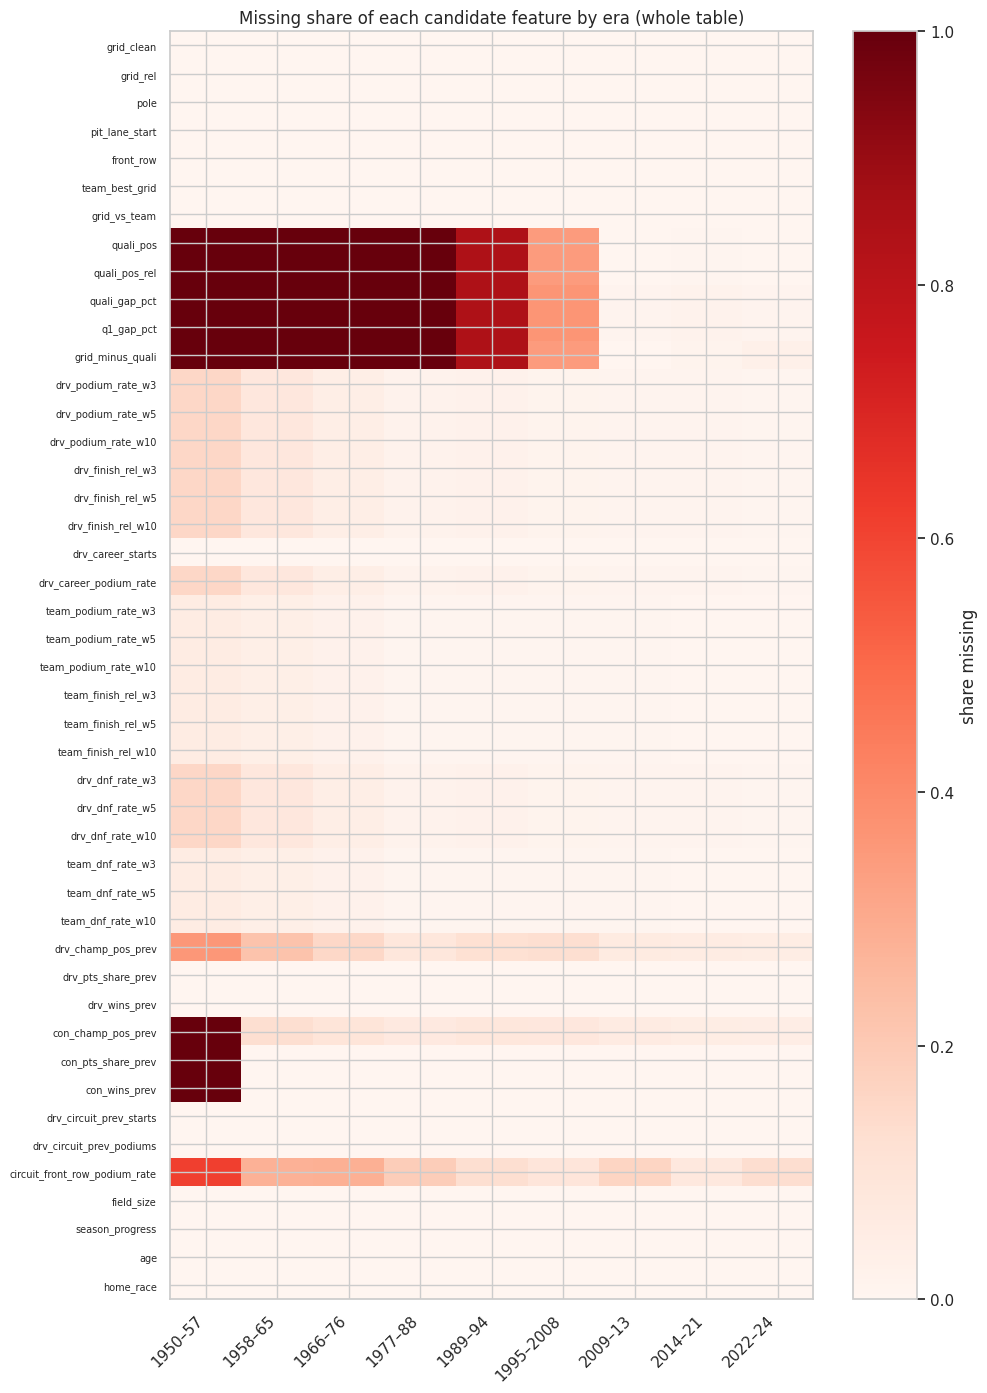

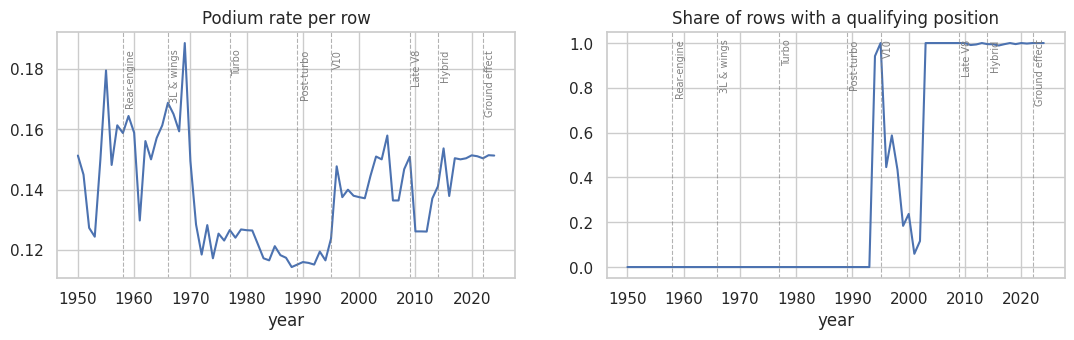

In [ ]:
# EDA of the modeling table: how much of each feature exists, per era and per group
ERA_B = ERA_BINS if "ERA_BINS" in globals() else [1949, 1957, 1965, 1976, 1988, 1994, 2008, 2013, 2021, 2100]
ERA_L = ERA_LABELS if "ERA_LABELS" in globals() else ["1950-57", "1958-65", "1966-76", "1977-88", "1989-94", "1995-2008", "2009-13", "2014-21", "2022-24"]
df["era"] = pd.cut(df["year"], bins=ERA_B, labels=ERA_L)

miss = df.groupby("era", observed=True)[ALL_CANDIDATES].apply(lambda g: g.isna().mean()).T
fig, ax = plt.subplots(figsize=(10, 0.28 * len(miss) + 1.5))
im = ax.imshow(miss.to_numpy(dtype=float), aspect="auto", cmap="Reds", vmin=0, vmax=1)
ax.set_yticks(range(len(miss))); ax.set_yticklabels(miss.index, fontsize=7)
ax.set_xticks(range(miss.shape[1])); ax.set_xticklabels(miss.columns, rotation=45, ha="right")
plt.colorbar(im, label="share missing"); ax.set_title("Missing share of each candidate feature by era (whole table)")
plt.tight_layout(); plt.show()

by_year = df.groupby("year").agg(rows=("podium", "size"), podium_rate=("podium", "mean"),
                                 quali_cov=("quali_pos", lambda s: s.notna().mean()))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
by_year["podium_rate"].plot(ax=axes[0], title="Podium rate per row"); by_year["quali_cov"].plot(ax=axes[1], title="Share of rows with a qualifying position")
for ax in axes: add_eras(ax) if "add_eras" in globals() else None
plt.show()

**What this shows.** Qualifying features are missing for whole early eras because the data does not exist. Form and standings are missing only for debutants and season openers.
This missingness carries information, so Part 4 keeps missing-value indicators.

## 3.2 Train / validation / test split
Split by whole seasons, in time order

| Split | Seasons | Use |
|---|---|---|
| **train** | up to 2019 (from the chosen start year) | fit models |
| **validation** | 2020–2021 | choose features, models, thresholds |
| **test** | 2022 onwards | opened once, for the final score |

Validation is small (about 40 races), so only trust differences that are clearly large. The test seasons are a new rule era, which makes the test harder than a random split. For hyperparameter search inside train, use the walk-forward folds below, not shuffled folds.

> **Split definition and shared helpers**
>
> **Purpose:** assigns each row to train (to 2019), validation (2020-2021) or test (2022 onwards) by whole seasons, and defines the helpers used for the rest of the notebook: `assert_no_test` (a guard against touching test data), `evaluate` (ROC-AUC, PR-AUC, top-3 precision per race), `make_estimator` / `fit_eval` (quick logistic-regression and gradient-boosting models for comparing feature sets), `make_lr` / `make_median_imputer` (the single definitions of the logistic regression and the imputer reused later), and `season_walk_forward` (time-ordered folds for later tuning).
>
> **Why it is needed:** rows within a race and consecutive seasons are strongly dependent, so a random split would leak. A chronological split mimics real use (predict the future from the past). The guard enforces the rule that thresholds and hyperparameters are chosen on train and validation only.

In [ ]:
#   train <= 2019 | validation 2020-2021 | test >= 2022
LAST_YEAR = int(df["year"].max())
VAL_YEARS = [2020, 2021]      # train = every earlier season (up to 2019)
TEST_YEARS = list(range(2022, LAST_YEAR + 1))
df["split"] = np.where(df["year"].isin(TEST_YEARS), "test", np.where(df["year"].isin(VAL_YEARS), "val", "train"))

def assert_no_test(*frames):
    for f in frames:
        assert "test" not in set(f["split"]), "test rows leaked into a model-selection step"

def evaluate(d, p):
    # threshold-free metrics + a race-aware one: of the 3 drivers ranked highest in each race, how many really podiumed?
    p = np.asarray(p, float)
    top3 = d.assign(_p=p).sort_values(["raceId", "_p"], ascending=[True, False]).groupby("raceId").head(3)
    return dict(roc_auc=roc_auc_score(d[TARGET], p), pr_auc=average_precision_score(d[TARGET], p),
                top3_precision=top3[TARGET].mean())

def make_lr():
    # the one logistic-regression configuration used for all exploratory comparisons in this notebook
    return LogisticRegression(C=1.0, class_weight="balanced", max_iter=3000)

def make_median_imputer(indicator=True):
    # median imputation (+ missing-indicator columns); shared by make_estimator, make_preprocessor and the P2 experiment
    return SimpleImputer(strategy="median", add_indicator=indicator, keep_empty_features=True)

def make_estimator(kind, features, cat_cols=()):
    # exploratory estimators used ONLY to compare feature sets / windows on validation data
    if kind == "lr":
        num = Pipeline([("imp", make_median_imputer()), ("sc", StandardScaler())])
        parts = [("num", num, list(features))]
        if cat_cols:
            parts.append(("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=30), list(cat_cols)))
        return Pipeline([("pre", ColumnTransformer(parts)),
                         ("clf", make_lr())])
    return Pipeline([("pre", ColumnTransformer([("num", "passthrough", list(features))])),
                     ("clf", HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150,
                                                           min_samples_leaf=40, l2_regularization=1.0,
                                                           early_stopping=False, random_state=SEED))])

def fit_eval(train_df, val_df, features, kind, cat_cols=()):
    assert_no_test(train_df, val_df)
    cols = list(features) + list(cat_cols)
    est = make_estimator(kind, features, cat_cols).fit(train_df[cols], train_df[TARGET])
    return evaluate(val_df, est.predict_proba(val_df[cols])[:, 1])

def season_walk_forward(d, n_folds=3):
    # expanding-window folds: train on seasons < s, validate on season s (for hyper-parameter search later)
    yrs = sorted(d["year"].unique())[-n_folds:]
    return [(d.index[d["year"] < s], d.index[d["year"] == s]) for s in yrs]

print("Test seasons:", TEST_YEARS, "| validation seasons:", VAL_YEARS)

Test seasons: [2022, 2023, 2024] | validation seasons: [2020, 2021]


### 3.2.1 Experiment: where should the training window start?
Form features always use the full history, but training rows can start later. Candidate start years follow rule changes (1996, 2003, 2006 knockout qualifying, 2011 DRS, 2014 hybrid). The start with the best mean validation PR-AUC (two quick models) is used.

> **Experiment: where should the training window start?**
>
> **Purpose:** trains the two quick models on training data that begins at different years (first season, 1996, 2003, 2006, 2011, 2014), scores each on validation, and picks the start year with the best mean PR-AUC (`WINDOW_START`).
>
> **Why it is needed:** qualifying data is patchy early on and the sport has changed a lot, so the oldest rows may hurt more than they help. This is the empirical, trial-and-error justification the brief accepts, with every attempt visible in a table and plot.

,window_start,model,train_rows,roc_auc,pr_auc,top3_precision
0,1950,lr,22441,0.9347,0.7430,0.6838
1,1950,hgb,22441,0.9320,0.7087,0.6923
2,1996,lr,9264,0.9330,0.7153,0.6838
3,1996,hgb,9264,0.9324,0.7180,0.6838
4,2003,lr,6781,0.9314,0.7227,0.6838
5,2003,hgb,6781,0.9383,0.7254,0.7009
6,2006,lr,5742,0.9323,0.7201,0.6923
7,2006,hgb,5742,0.9303,0.7157,0.6838
8,2011,lr,3814,0.9296,0.7261,0.6667
9,2011,hgb,3814,0.9298,0.7163,0.6838


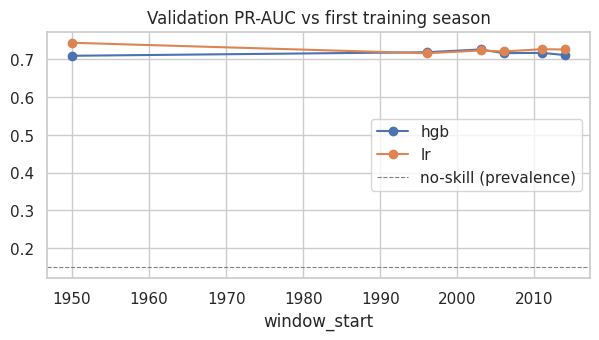

WINDOW_START = 1950 (highest mean validation PR-AUC over the two models)


In [ ]:
all_train = df[df["split"] == "train"]; val_all = df[df["split"] == "val"]
# era-motivated candidates (reference document): 1996 qualifying data and lap-time era, 2003 single-lap qualifying,
# 2006 knockout qualifying (Q1/Q2/Q3 times), 2011 DRS + single tyre supplier, 2014 hybrid era
starts = sorted({s for s in [int(df["year"].min()), 1996, 2003, 2006, 2011, 2014] if s <= VAL_YEARS[0] - 4})
rows = []
for s in starts:
    tr = all_train[all_train["year"] >= s]
    for kind in ["lr", "hgb"]:
        rows.append(dict(window_start=s, model=kind, train_rows=len(tr), **fit_eval(tr, val_all, CORE_CANDIDATES, kind)))
win = pd.DataFrame(rows)
display(win.round(4))

piv = win.pivot(index="window_start", columns="model", values="pr_auc")
ax = piv.plot(marker="o", figsize=(7, 3.2), title="Validation PR-AUC vs first training season")
ax.axhline(val_all[TARGET].mean(), color="grey", ls="--", lw=0.8, label="no-skill (prevalence)"); ax.legend(); plt.show()

WINDOW_START = int(piv.mean(axis=1).idxmax())
print(f"WINDOW_START = {WINDOW_START} (highest mean validation PR-AUC over the two models)")

> **Apply the window and create the final splits**
>
> **Purpose:** filters the table to `WINDOW_START` onwards, creates `train`, `val` and `test` frames, summarises each split (rows, races, seasons, podium rate), asserts they are disjoint and strictly ordered in time, plots the split on a timeline, and lists the walk-forward folds inside train.
>
> **Why it is needed:** this fixes the three frames used by every later section. The summary and assertions document and prove the split, and the podium-rate column shows whether the classes are balanced similarly across splits.

,rows,races,first_season,last_season,podiums,podium_rate
split,,,,,,
train,22441,1007,1950,2019,3021,0.135
val,774,39,2020,2021,117,0.151
test,1351,68,2022,2024,204,0.151


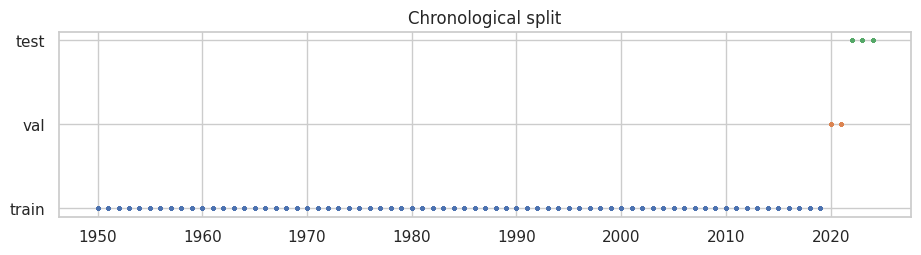

Walk-forward folds inside train (for hyper-parameter search):
  fold 0: train rows 21,203 -> validate on season 2017 (399 rows)
  fold 1: train rows 21,602 -> validate on season 2018 (420 rows)
  fold 2: train rows 22,022 -> validate on season 2019 (419 rows)


In [ ]:
mdl = df[df["year"] >= WINDOW_START].reset_index(drop=True)
train = mdl[mdl["split"] == "train"].copy()
val = mdl[mdl["split"] == "val"].copy()
test = mdl[mdl["split"] == "test"].copy()          # NOT used by anything until the final evaluation

summary = (mdl.groupby("split").agg(rows=(TARGET, "size"), races=("raceId", "nunique"),
                                    first_season=("year", "min"), last_season=("year", "max"),
                                    podiums=(TARGET, "sum"), podium_rate=(TARGET, "mean"))
              .loc[["train", "val", "test"]])
display(summary.round(3))

# the three splits are strictly ordered in time (hence disjoint in races)
assert train["race_order"].max() < val["race_order"].min() <= val["race_order"].max() < test["race_order"].min()   # strict time order also means no race is shared

fig, ax = plt.subplots(figsize=(11, 2.4))
for name, d in [("train", train), ("val", val), ("test", test)]:
    ax.scatter(d["year"], np.full(len(d), {"train": 0, "val": 1, "test": 2}[name]), s=3, alpha=0.3, label=name)
ax.set_yticks([0, 1, 2]); ax.set_yticklabels(["train", "val", "test"]); ax.set_title("Chronological split"); plt.show()

print("Walk-forward folds inside train (for hyper-parameter search):")
for i, (a, b) in enumerate(season_walk_forward(train)):
    print(f"  fold {i}: train rows {len(a):,} -> validate on season {int(train.loc[b, 'year'].iloc[0])} ({len(b)} rows)")

## 3.3 Feature selection
This part uses **training rows only** (plus validation for the group trials). The test seasons are never opened.

### 3.3.1 Single-feature signal
ROC-AUC and PR-AUC of each feature alone, with its coverage. The cell after the table checks the document's claim that pole is the strongest single predictor.

> **3.1 Single-feature signal**
>
> **Purpose:** scores every candidate feature on its own (ROC-AUC and PR-AUC on training rows, plus coverage and sign of the relationship), ranks them, checks where `pole`, `grid_clean` and `quali_pos` land, and plots the ranking coloured by group.
>
> **Why it is needed:** the first piece of evidence for feature selection. It shows which features carry signal alone and how much data backs each one. The ranking is also reused later to decide which of two correlated features to keep and to choose the form windows.

,feature,group,coverage,roc_auc,pr_auc,direction
0,quali_pos,qualifying,0.369,0.905,0.594,-
1,quali_pos_rel,qualifying,0.369,0.903,0.599,-
2,grid_clean,grid,1.000,0.883,0.497,-
3,quali_gap_pct,qualifying,0.363,0.881,0.584,-
4,grid_rel,grid,1.000,0.878,0.499,-
5,team_best_grid,grid,1.000,0.858,0.409,-
6,team_podium_rate_w10,constructor_form,0.989,0.840,0.439,+
7,drv_champ_pos_prev,standings,0.876,0.839,0.446,-
8,drv_podium_rate_w10,driver_form,0.970,0.833,0.431,+
9,q1_gap_pct,qualifying,0.363,0.830,0.453,-


Top 5 single features by ROC-AUC: ['quali_pos', 'quali_pos_rel', 'grid_clean', 'quali_gap_pct', 'grid_rel']
  pole        rank 38 of 45 | ROC-AUC 0.595 | PR-AUC 0.238
  grid_clean  rank 3 of 45 | ROC-AUC 0.883 | PR-AUC 0.497
  quali_pos   rank 1 of 45 | ROC-AUC 0.905 | PR-AUC 0.594


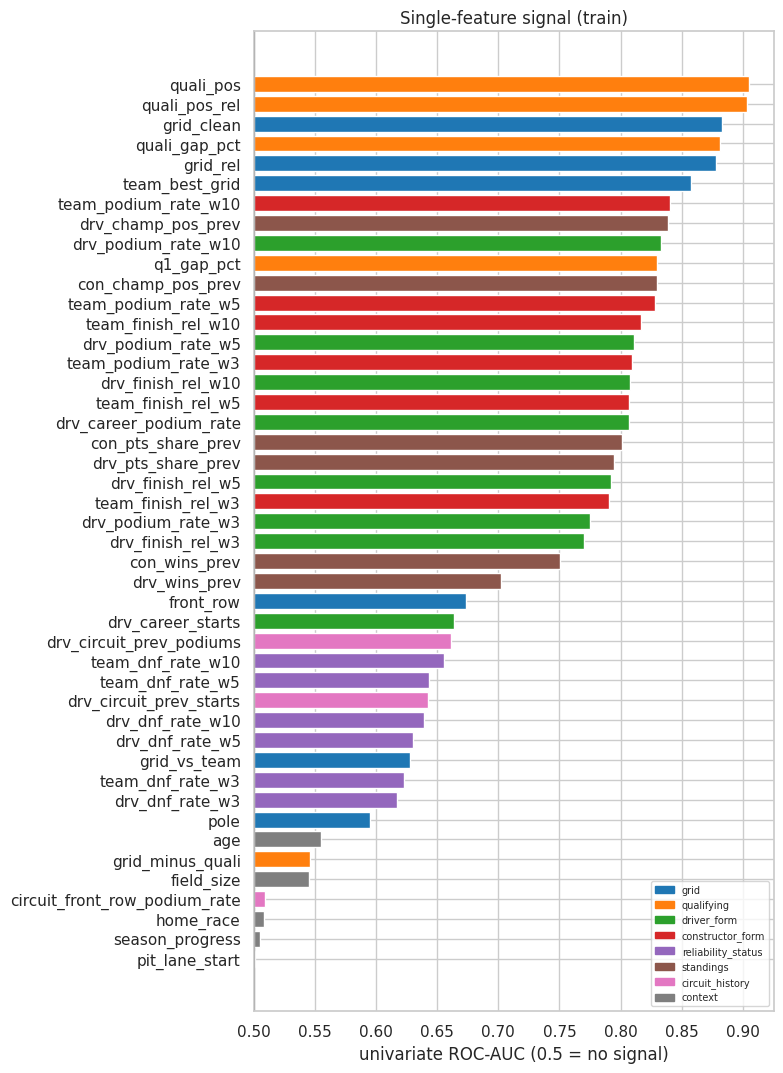

In [ ]:
group_of = {f: g for g, fs in CANDIDATE_GROUPS.items() for f in fs}

def uni_auc(d, f):
    m = d[f].notna(); y = d.loc[m, TARGET]
    out = dict(feature=f, group=group_of[f], coverage=m.mean(), roc_auc=np.nan, pr_auc=np.nan, direction="")
    if m.sum() < 50 or y.nunique() < 2 or d.loc[m, f].nunique() < 2:
        return out
    a = roc_auc_score(y, d.loc[m, f]); sgn = 1 if a >= 0.5 else -1
    out.update(roc_auc=max(a, 1 - a), pr_auc=average_precision_score(y, sgn * d.loc[m, f]), direction="+" if sgn > 0 else "-")
    return out

uni = pd.DataFrame([uni_auc(train, f) for f in ALL_CANDIDATES]).sort_values("roc_auc", ascending=False).reset_index(drop=True)
display(uni.round(3))

ranked = uni.dropna(subset=["roc_auc"]).reset_index(drop=True)
print("Top 5 single features by ROC-AUC:", ranked["feature"].head(5).tolist())
_r = ranked.set_index("feature")
for f in ["pole", "grid_clean", "quali_pos"]:
    print(f"  {f:11s} rank {int(ranked.index[ranked['feature'] == f][0]) + 1} of {len(ranked)} | ROC-AUC {_r.loc[f, 'roc_auc']:.3f} "
          f"| PR-AUC {_r.loc[f, 'pr_auc']:.3f}")
colors = dict(zip(CANDIDATE_GROUPS, plt.cm.tab10.colors))
u = ranked.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 0.22 * len(u) + 1))
ax.barh(u["feature"], u["roc_auc"] - 0.5, left=0.5, color=[colors[g] for g in u["group"]])
ax.axvline(0.5, color="k", lw=0.8); ax.set_xlabel("univariate ROC-AUC (0.5 = no signal)"); ax.set_title("Single-feature signal (train)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()], labels=list(colors), fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

### 3.3.2 Podium rate against each feature
Each panel shows the podium rate in 8 equal-count bins of the feature (dashed line = overall rate). A useful feature moves the rate away from the line; a flat panel is evidence against it.

> **3.2 Podium rate against each feature (grid and qualifying)**
>
> **Purpose:** defines `effect_plot` (podium rate in equal-count bins of a feature) and uses it for the grid and qualifying groups. Also plots podium rate per grid slot, and the same curve split by regulation era.
>
> **Why it is needed:** univariate AUC hides the shape of a relationship. These plots show whether a feature moves the podium rate monotonically, and the era split checks whether grid position means the same thing across rule changes, which supports the training-window choice.

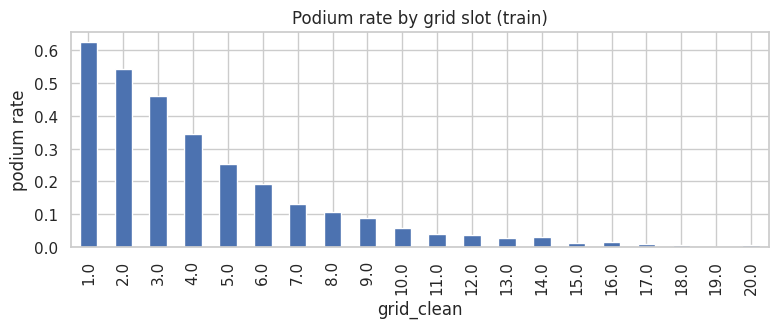

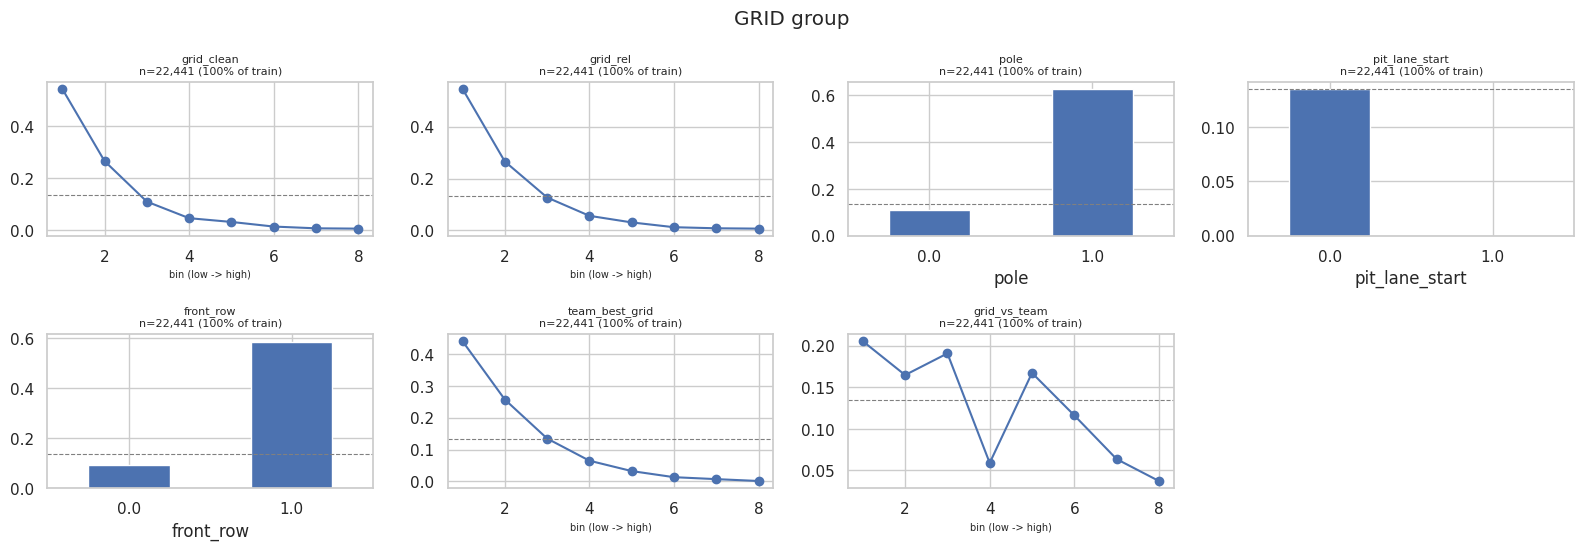

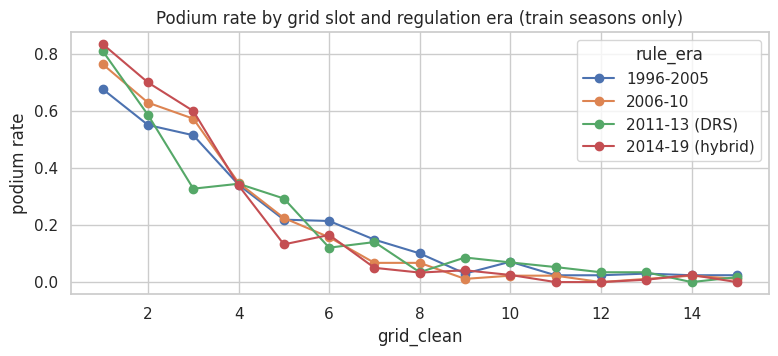

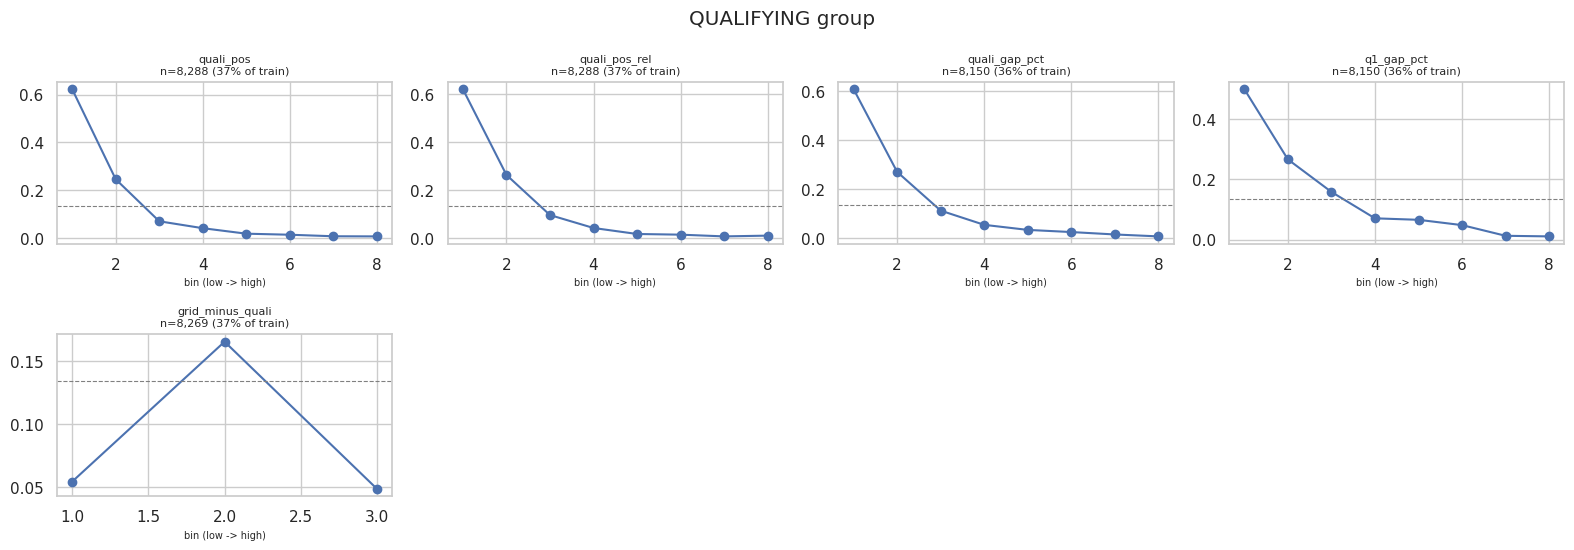

In [ ]:
def effect_plot(features, title, q=8, ncols=4):
    features = list(features)
    nrows = math.ceil(len(features) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.8 * nrows)); axes = np.atleast_1d(axes).ravel()
    base = train[TARGET].mean()
    for ax, f in zip(axes, features):
        s = train[[f, TARGET]].dropna()
        if s[f].nunique() <= 2:
            s.groupby(f)[TARGET].mean().plot(kind="bar", ax=ax, rot=0)
        else:
            g = s.groupby(pd.qcut(s[f], q=min(q, s[f].nunique()), duplicates="drop"), observed=True)[TARGET].mean()
            ax.plot(range(1, len(g) + 1), g.values, marker="o"); ax.set_xlabel("bin (low -> high)", fontsize=7)
        ax.axhline(base, color="grey", ls="--", lw=0.8)
        ax.set_title(f"{f}\nn={len(s):,} ({len(s)/len(train):.0%} of train)", fontsize=8)
    for ax in axes[len(features):]: ax.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

# starting slot: the classic picture, one bar per grid slot
slot = train[train["grid_clean"].between(1, 20)].groupby("grid_clean")[TARGET].mean()
ax = slot.plot(kind="bar", figsize=(9, 2.8), title="Podium rate by grid slot (train)"); ax.set_ylabel("podium rate"); plt.show()
effect_plot(CANDIDATE_GROUPS["grid"], "GRID group")

# Reference document: DRS (2011) made grid slightly less decisive and early reliability was far lower. Does the grid->podium curve differ by era?
tt = all_train.copy()                      # all training seasons (defined in 2.1)
tt["rule_era"] = pd.cut(tt["year"], [1995, 2005, 2010, 2013, 2019], labels=["1996-2005", "2006-10", "2011-13 (DRS)", "2014-19 (hybrid)"])
curve = tt[tt["grid_clean"].between(1, 15)].groupby(["rule_era", "grid_clean"], observed=True)[TARGET].mean().unstack(0)
ax = curve.plot(marker="o", figsize=(9, 3.4), title="Podium rate by grid slot and regulation era (train seasons only)")
ax.set_ylabel("podium rate"); plt.show()
effect_plot(CANDIDATE_GROUPS["qualifying"], "QUALIFYING group")

> **3.2 continued: form, standings, circuit history, context**
>
> **Purpose:** applies `effect_plot` to the remaining groups (window-5 form features, standings, circuit history, context).
>
> **Why it is needed:** completes the visual evidence for each group. A flat panel is evidence against keeping a feature.

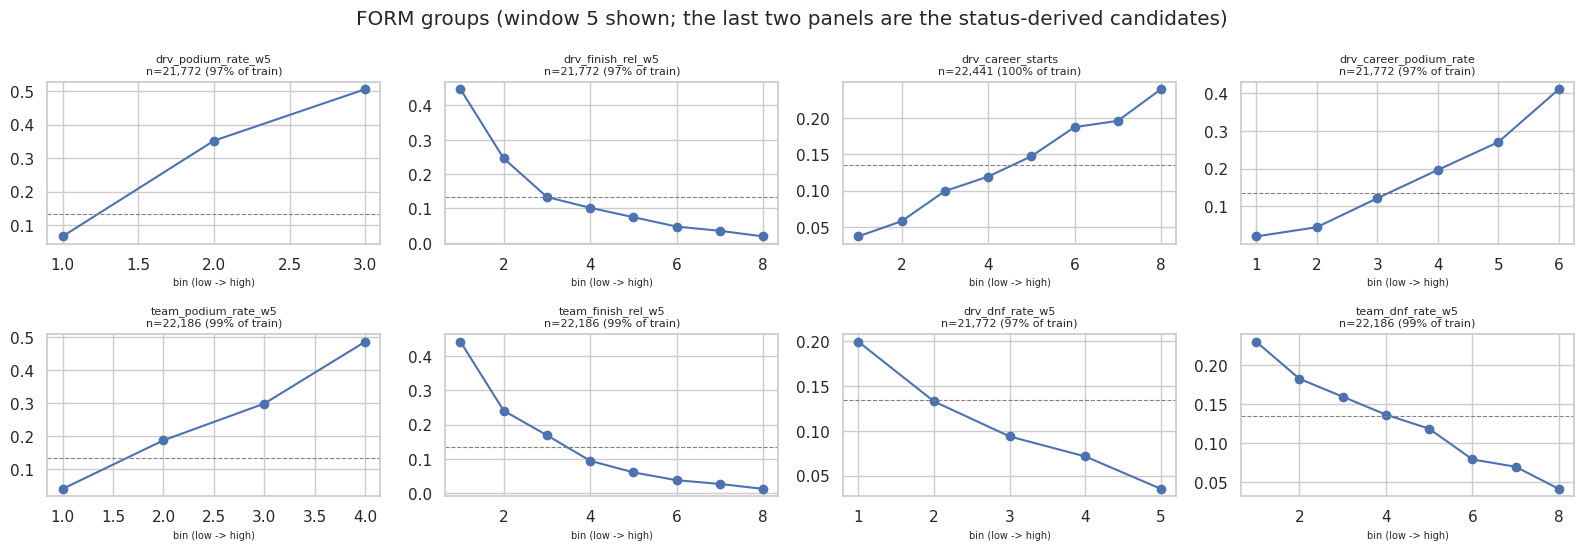

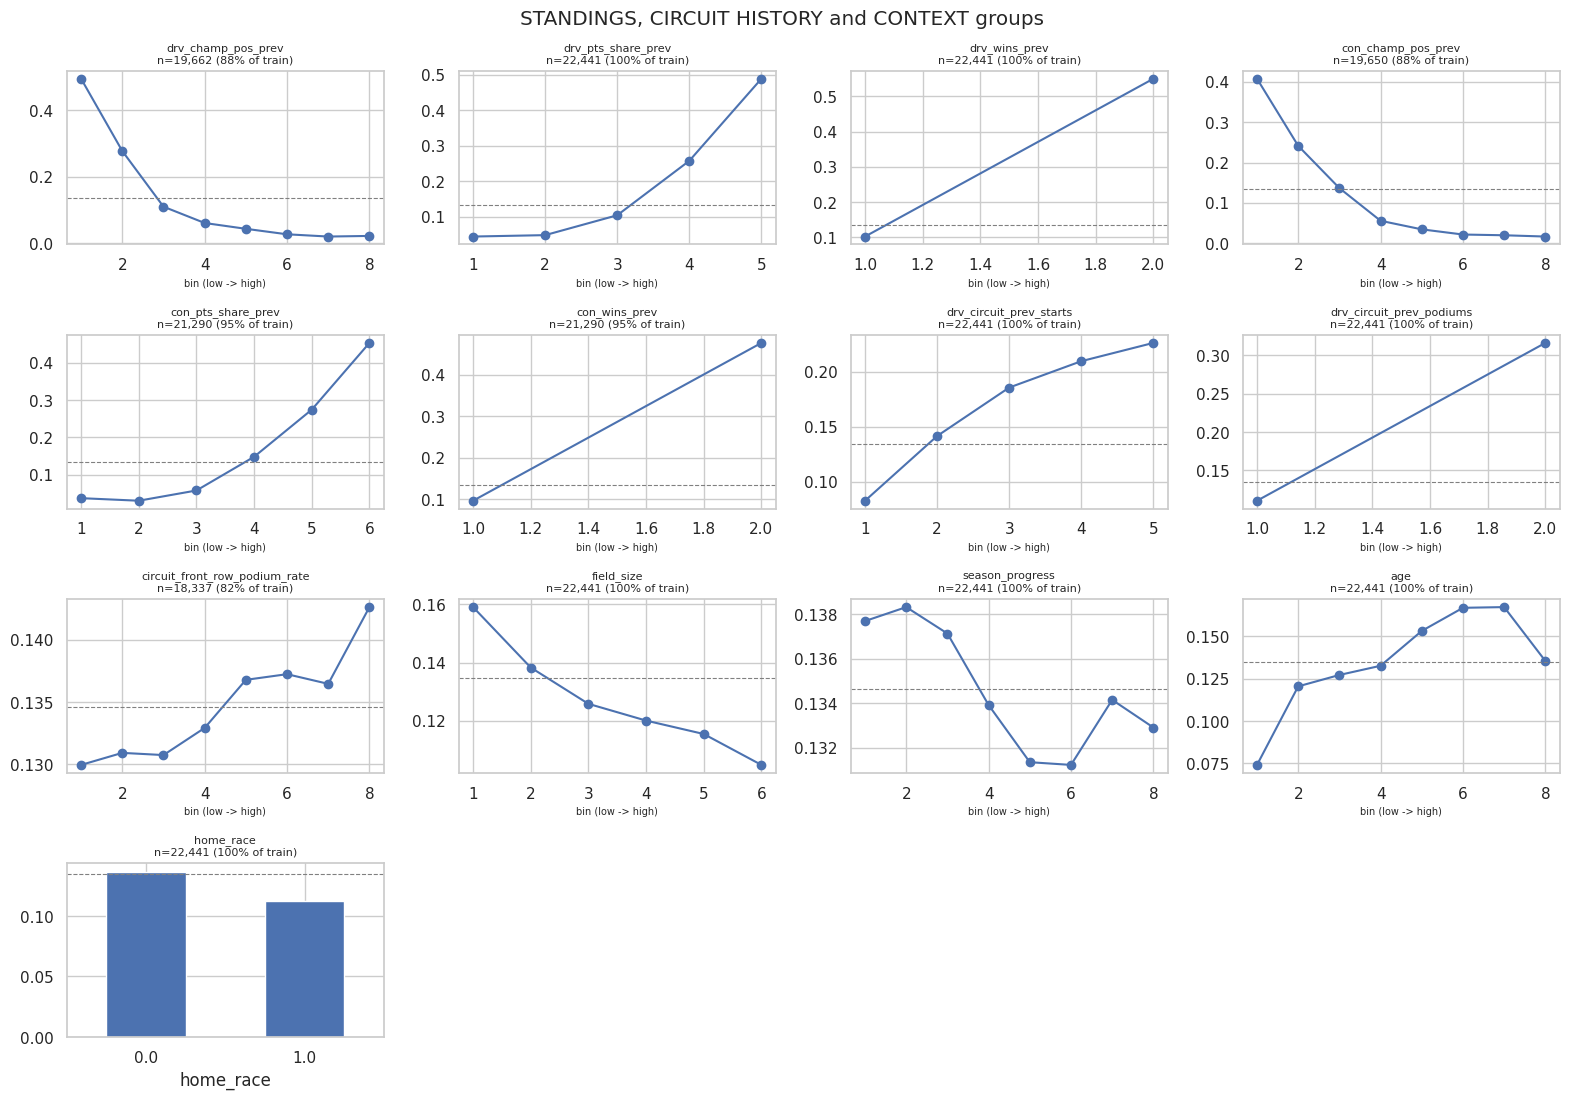

In [ ]:
effect_plot([f for g in ["driver_form", "constructor_form", "reliability_status"] for f in CANDIDATE_GROUPS[g]
             if f.endswith("_w5") or "career" in f], "FORM groups (window 5 shown; the last two panels are the status-derived candidates)")
effect_plot(CANDIDATE_GROUPS["standings"] + CANDIDATE_GROUPS["circuit_history"] + CANDIDATE_GROUPS["context"],
            "STANDINGS, CIRCUIT HISTORY and CONTEXT groups")

> **Home race, controlled for starting position**
>
> **Purpose:** compares podium rate for home and away starts inside grid bands (1-3, 4-6, 7-10, 11+).
>
> **Why it is needed:** home drivers may simply qualify better, so a raw comparison would be confounded. Comparing within similar grid bands is the control the brief asks for in Data-Engineering Question 2, and it tells you whether `home_race` deserves to be a feature.

mean          size      
home_race    0.0    1.0    0.0   1.0
grid_band                           
1-3        0.544  0.544   2801   215
4-6        0.265  0.269   2800   212
7-10       0.098  0.071   3681   322
11+        0.017  0.011  11286  1111

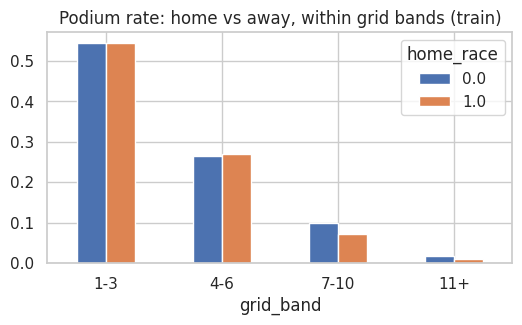

In [ ]:
# Home race (brief Q2) controlled for starting position: compare podium rates within grid bands
t = train.copy(); t["grid_band"] = pd.cut(t["grid_clean"], [0, 3, 6, 10, 30], labels=["1-3", "4-6", "7-10", "11+"])
hb = t.groupby(["grid_band", "home_race"], observed=True)[TARGET].agg(["mean", "size"]).unstack("home_race")
display(hb.round(3))
hb["mean"].plot(kind="bar", figsize=(6, 3), rot=0, title="Podium rate: home vs away, within grid bands (train)"); plt.show()


### 3.3.3 Choosing the form window (3, 5 or 10 races)
For each form feature we take the longest window within 0.003 AUC of the best, using training data.

> **3.3 Choosing the form window**
>
> **Purpose:** tabulates and plots univariate ROC-AUC for windows 3, 5 and 10 for each form family, then picks the longest window within 0.003 AUC of the best (`BEST_W`). Builds `ACTIVE_GROUPS` using the chosen windows, and removes the status-derived group unless the switch is on.
>
> **Why it is needed:** the table has three versions of each form feature that are almost the same signal. Keeping all of them adds redundancy, so one window per family is chosen with evidence. Preferring the longest near-tie gives a smoother, less noisy estimate.

,w3,w5,w10
drv_podium_rate,0.7754,0.8108,0.8335
drv_finish_rel,0.7698,0.7919,0.8075
team_podium_rate,0.8096,0.8285,0.8404
team_finish_rel,0.7907,0.8073,0.8168
drv_dnf_rate,0.6169,0.6304,0.6395
team_dnf_rate,0.6224,0.6429,0.6558


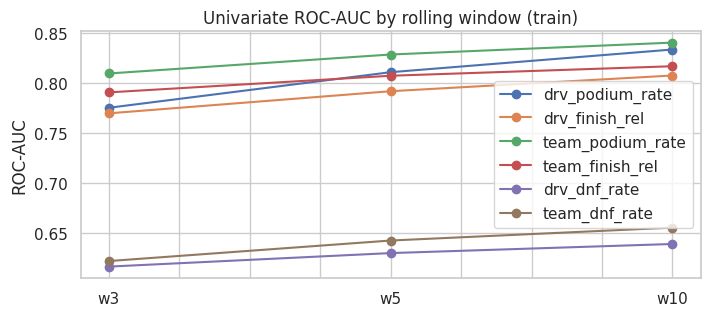

Chosen windows: {'drv_podium_rate': 10, 'drv_finish_rel': 10, 'team_podium_rate': 10, 'team_finish_rel': 10, 'drv_dnf_rate': 10, 'team_dnf_rate': 10}


In [ ]:
fam_auc = pd.DataFrame({fam: {w: uni.set_index("feature").loc[f"{fam}_w{w}", "roc_auc"] for w in FORM_WINDOWS} for fam in ALL_FAMILIES}).T
fam_auc.columns = [f"w{w}" for w in FORM_WINDOWS]
display(fam_auc.round(4))
ax = fam_auc.T.plot(marker="o", figsize=(8, 3.2), title="Univariate ROC-AUC by rolling window (train)"); ax.set_ylabel("ROC-AUC"); plt.show()

BEST_W = {}
for fam in ALL_FAMILIES:
    s = fam_auc.loc[fam]
    BEST_W[fam] = max(w for w in FORM_WINDOWS if s[f"w{w}"] >= s.max() - 0.003)
print("Chosen windows:", BEST_W)

ACTIVE_GROUPS = {g: list(fs) for g, fs in CANDIDATE_GROUPS.items()}
pick = lambda fams: [f"{fam}_w{BEST_W[fam]}" for fam in fams]
ACTIVE_GROUPS["driver_form"] = pick(["drv_podium_rate", "drv_finish_rel"]) + ["drv_career_starts", "drv_career_podium_rate"]
ACTIVE_GROUPS["constructor_form"] = pick(["team_podium_rate", "team_finish_rel"])
STATUS_CANDIDATES = pick(STATUS_FAMILIES)                                # kept for the 3.7 trial
if INCLUDE_STATUS_FORM:
    ACTIVE_GROUPS["reliability_status"] = STATUS_CANDIDATES
else:
    ACTIVE_GROUPS.pop("reliability_status")                              # reference document: status is not a feature

### 3.3.4 Redundant features
Spearman correlation between features. For pairs with |ρ| ≥ 0.95 the weaker feature is dropped. `grid_clean` and `quali_pos` are protected: the project needs grid and qualifying position as separate variables.

> **3.4 Redundant features**
>
> **Purpose:** plots the Spearman correlation matrix of the active features and, for every pair with |rho| >= 0.95, drops the weaker feature (by univariate AUC). `grid_clean` and `quali_pos` are protected.
>
> **Why it is needed:** near-duplicate features add no information, inflate the feature count and make linear coefficients and importance scores unstable. The protection rule keeps grid and qualifying position as separate variables, which the brief and Question 1 require.

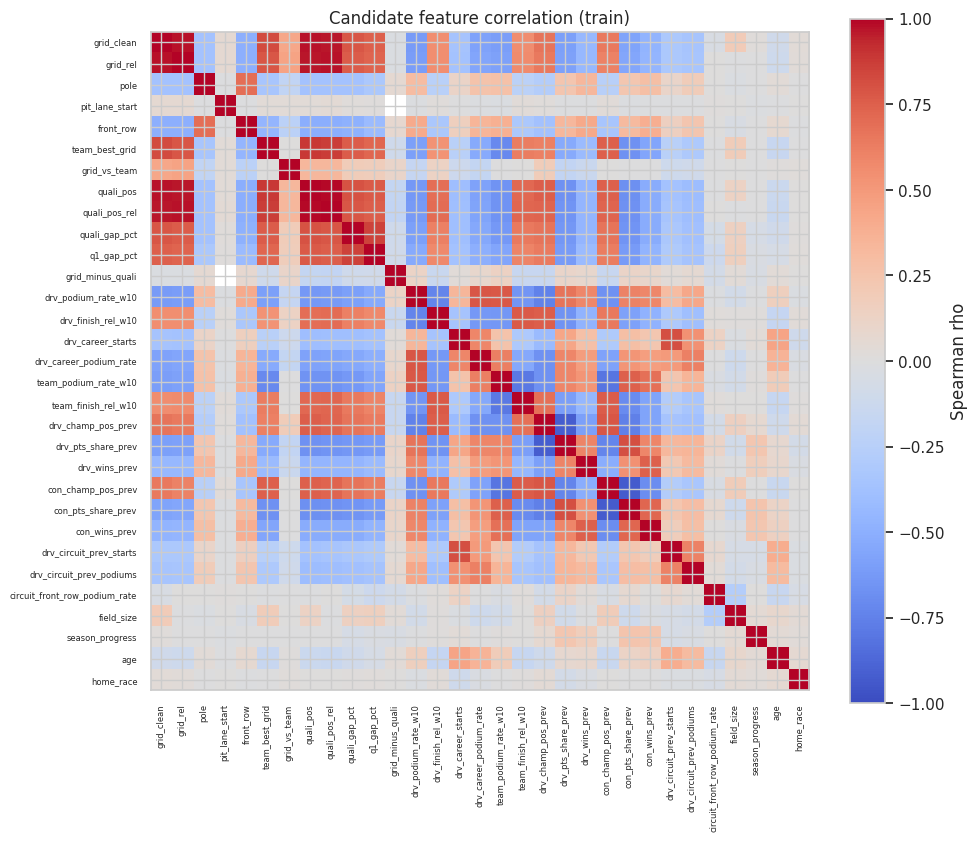

rho(grid_clean, grid_rel) = +0.970  -> drop grid_rel
rho(grid_clean, quali_pos) = +0.976  -> both protected, both kept
rho(grid_clean, quali_pos_rel) = +0.962  -> drop quali_pos_rel
Dropped as redundant: ['grid_rel', 'quali_pos_rel']


In [ ]:
cand = [f for fs in ACTIVE_GROUPS.values() for f in fs]
corr = train[cand].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cand))); ax.set_xticklabels(cand, rotation=90, fontsize=6)
ax.set_yticks(range(len(cand))); ax.set_yticklabels(cand, fontsize=6)
plt.colorbar(im, label="Spearman rho"); ax.set_title("Candidate feature correlation (train)"); plt.tight_layout(); plt.show()

auc_of = uni.set_index("feature")["roc_auc"]
PROTECTED = {"grid_clean", "quali_pos"}      # the two core signals: Q1 needs grid and qualifying kept as DIFFERENT variables
dropped, THR = [], 0.95
for i, a in enumerate(cand):
    for b in cand[i + 1:]:
        if a in dropped or b in dropped: continue
        if abs(corr.loc[a, b]) >= THR:
            if a in PROTECTED and b in PROTECTED:
                print(f"rho({a}, {b}) = {corr.loc[a, b]:+.3f}  -> both protected, both kept"); continue
            loser = b if a in PROTECTED else a if b in PROTECTED else (a if auc_of.get(a, 0) < auc_of.get(b, 0) else b)
            dropped.append(loser)
            print(f"rho({a}, {b}) = {corr.loc[a, b]:+.3f}  -> drop {loser}")
print("Dropped as redundant:", dropped or "none")
ACTIVE_GROUPS = {g: [f for f in fs if f not in dropped] for g, fs in ACTIVE_GROUPS.items()}

### 3.3.5 Mutual information
Also detects non-straight-line relationships with the target (training data).

> **3.5 Mutual information**
>
> **Purpose:** computes the mutual information between each remaining feature and the target on training data and plots it.
>
> **Why it is needed:** unlike correlation or AUC it detects non-monotonic relationships, so it is a second, different view of feature usefulness. Here it serves as supporting evidence (it does not drop any feature).

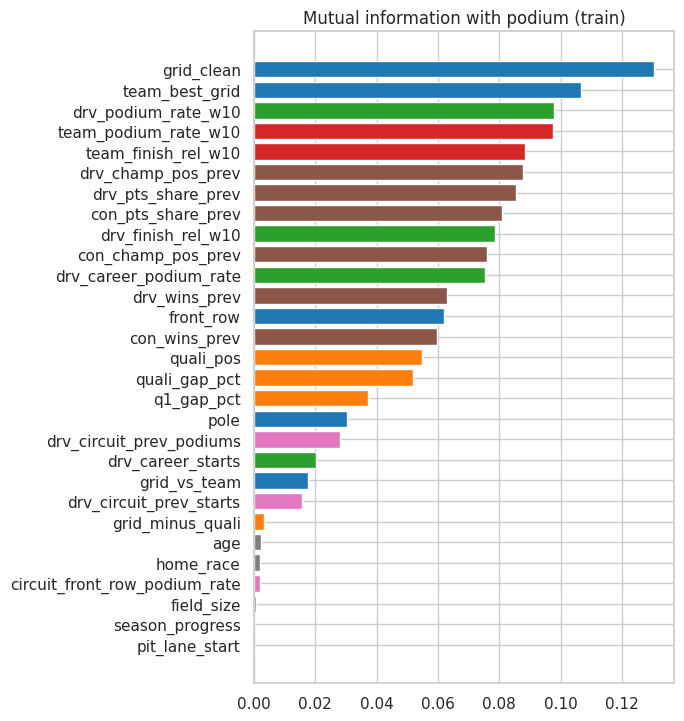

In [ ]:
feats_now = [f for fs in ACTIVE_GROUPS.values() for f in fs]
Xi = SimpleImputer(strategy="median", keep_empty_features=True).fit_transform(train[feats_now])
mi = pd.Series(mutual_info_classif(Xi, train[TARGET], random_state=SEED), index=feats_now).sort_values()
fig, ax = plt.subplots(figsize=(7, 0.22 * len(mi) + 1))
ax.barh(mi.index, mi.values, color=[colors[group_of[f]] for f in mi.index]); ax.set_title("Mutual information with podium (train)")
plt.tight_layout(); plt.show()

### 3.3.6 Add one feature group at a time (validation)
Starts from a baseline (logistic regression on the starting slot alone). Each row adds one group and scores it with a linear model and a gradient-boosting model.

> **3.6 Add one feature group at a time**
>
> **Purpose:** starts from a one-feature baseline (`grid_clean`) and adds each group cumulatively, fitting logistic regression and gradient boosting on train and scoring on validation, with the change in PR-AUC at each step.
>
> **Why it is needed:** this is the empirical justification of each group, with a clear before/after baseline as the brief requires. It tells you which groups earn their place and what the simplest reasonable baseline scores.

,step,model,n_features,roc_auc,pr_auc,top3_precision,d_pr_auc
0,baseline: grid_clean only,lr,1,0.9101,0.6478,0.7009,NaN
1,baseline: grid_clean only,hgb,1,0.9096,0.6477,0.7009,NaN
2,+ grid,lr,6,0.9167,0.6654,0.7009,0.0176
3,+ grid,hgb,6,0.9135,0.6613,0.7094,0.0136
4,+ qualifying,lr,10,0.9270,0.6660,0.7094,0.0006
5,+ qualifying,hgb,10,0.9274,0.6766,0.7009,0.0153
6,+ driver_form,lr,14,0.9333,0.7376,0.6923,0.0716
7,+ driver_form,hgb,14,0.9308,0.7182,0.7094,0.0415
8,+ constructor_form,lr,16,0.9334,0.7259,0.6838,-0.0117
9,+ constructor_form,hgb,16,0.9310,0.7186,0.6923,0.0004


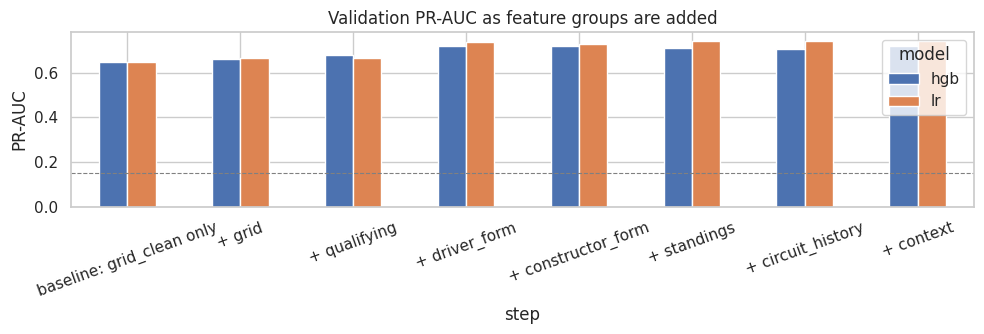

In [ ]:
order = ["grid", "qualifying", "driver_form", "constructor_form", "standings", "circuit_history", "context"]
order = [g for g in order if g in ACTIVE_GROUPS]
steps = [("baseline: grid_clean only", ["grid_clean"])]
cum = []
for g in order:
    cum = cum + ACTIVE_GROUPS[g]
    steps.append((f"+ {g}", list(cum)))

rows = []
for name, fs in steps:
    for kind in ["lr", "hgb"]:
        rows.append(dict(step=name, model=kind, n_features=len(fs), **fit_eval(train, val, fs, kind)))
inc = pd.DataFrame(rows)
for m in ["lr", "hgb"]:
    inc.loc[inc["model"] == m, "d_pr_auc"] = inc.loc[inc["model"] == m, "pr_auc"].diff()
display(inc.round(4))

piv = inc.pivot(index="step", columns="model", values="pr_auc").loc[[s for s, _ in steps]]
ax = piv.plot(kind="bar", figsize=(10, 3.5), rot=20, title="Validation PR-AUC as feature groups are added")
ax.axhline(val[TARGET].mean(), color="grey", ls="--", lw=0.8); ax.set_ylabel("PR-AUC"); plt.tight_layout(); plt.show()

**How to read it.** A group is justified if PR-AUC and top-3 precision rise when it is added. Quote these numbers in the report.

### 3.3.7 Candidates left out, and what that costs
Each excluded candidate is tested against the final set on validation; the last column is the PR-AUC change versus the reference row.

> **3.7 Candidates left out, and what it costs**
>
> **Purpose:** tests the features deliberately excluded (raw year, era flags, status-derived retirement rates, `constructorId` one-hot) against the final set on validation, and reports how much of the data other sources (sprint, lap times, pit stops) cover.
>
> **Why it is needed:** excluding a feature should be a measured decision. This shows the cost or gain of each exclusion so you can defend it at the evaluation.

In [ ]:
fs_all = [f for g in order for f in ACTIVE_GROUPS[g]]
tr_c, va_c = train.copy(), val.copy()
for d in (tr_c, va_c):
    d["year_num"] = d["year"].astype(float)
    d["drs_era"] = (d["year"] >= 2011).astype(float)          # regulation-era flags from the reference document
    d["hybrid_era"] = (d["year"] >= 2014).astype(float)
variants = [("final feature set (reference)", fs_all, ()),
            ("+ raw year (numeric)", fs_all + ["year_num"], ()),
            ("+ regulation-era flags (DRS 2011, hybrid 2014)", fs_all + ["drs_era", "hybrid_era"], ()),
            ("+ status-derived retirement rates (reliability_status)", fs_all + [f for f in STATUS_CANDIDATES if f not in fs_all], ()),
            ("+ constructorId one-hot (LR only)", fs_all, ("constructorId",))]
# the last step of 3.6 IS the final feature set: reuse its validation scores instead of refitting the same models
assert steps[-1][1] == fs_all
_ref = inc[inc["step"] == steps[-1][0]].set_index("model")[["roc_auc", "pr_auc", "top3_precision"]]
rows = []
for name, fs, cat in variants:
    for kind in (["lr"] if cat else ["lr", "hgb"]):
        sc = _ref.loc[kind].to_dict() if name.startswith("final") else fit_eval(tr_c, va_c, fs, kind, cat_cols=cat)
        rows.append(dict(variant=name, model=kind, **sc))
rej = pd.DataFrame(rows)
for m in ["lr", "hgb"]:
    ref = rej[(rej["model"] == m) & rej["variant"].str.startswith("final")]["pr_auc"].iloc[0]
    rej.loc[rej["model"] == m, "d_pr_auc_vs_final"] = rej.loc[rej["model"] == m, "pr_auc"] - ref
display(rej.round(4))

# coverage of the data sources we did not turn into features (share of rows whose race exists in the table: train, validation)
cov = {t: (train["raceId"].isin(tables[t]["raceId"].astype(int)).mean(), val["raceId"].isin(tables[t]["raceId"].astype(int)).mean())
       for t in ["sprint_results", "lap_times", "pit_stops"] if t in tables}
print("Share of rows whose race exists in the source table (train, validation):", {k: (round(a, 3), round(b, 3)) for k, (a, b) in cov.items()})

,variant,model,roc_auc,pr_auc,top3_precision,d_pr_auc_vs_final
0,final feature set (reference),lr,0.9351,0.7428,0.6838,0.0000
1,final feature set (reference),hgb,0.9313,0.7192,0.6838,0.0000
2,+ raw year (numeric),lr,0.9363,0.7485,0.6838,0.0058
3,+ raw year (numeric),hgb,0.9315,0.7142,0.6923,-0.0050
4,"+ regulation-era flags (DRS 2011, hybrid 2014)",lr,0.9353,0.7437,0.6838,0.0010
5,"+ regulation-era flags (DRS 2011, hybrid 2014)",hgb,0.9312,0.7142,0.6838,-0.0050
6,+ status-derived retirement rates (reliability...,lr,0.9350,0.7396,0.6838,-0.0031
7,+ status-derived retirement rates (reliability...,hgb,0.9317,0.7142,0.6923,-0.0050
8,+ constructorId one-hot (LR only),lr,0.9316,0.7366,0.6923,-0.0062


Share of rows whose race exists in the source table (train, validation): {'sprint_results': (np.float64(0.0), np.float64(0.076)), 'lap_times': (np.float64(0.413), np.float64(1.0)), 'pit_stops': (np.float64(0.17), np.float64(0.974))}
Circuit latitude/longitude: static labels of a circuit, redundant with the circuit-history features and easy to memorise.


**Why each is excluded**
- **Raw `year`:** test seasons lie outside the training range, so models would have to extrapolate.
- **Era flags (DRS 2011, hybrid 2014):** only worth adding if the gain clearly exceeds validation noise; by default the training window handles era effects.
- **Status-derived retirement rates:** the document says status is post-race and for Q3 only, and it mixes mechanical failures with accidents. If the cost above is large, discuss switching `INCLUDE_STATUS_FORM = True` (it only uses earlier races).
- **`constructorId` one-hot:** team ids change and unseen teams appear in test; team level is already in constructor form.
- **Sprint:** only from 2021, after the training period.
- **Lap times, pit stops, fastest lap, safety car, tyres:** post-race; never features.

### 3.3.8 Final feature list and dictionary
The dictionary below (definition, source tables, why valid at the cutoff) goes into the report.

> **3.8 Final feature list and feature dictionary**
>
> **Purpose:** freezes the final feature set (`FEATURE_GROUPS`, `FEATURES`, `BINARY`, `CONTINUOUS`), and builds a dictionary giving each feature's definition, the reason it is valid at the prediction cutoff, its source tables and its training coverage. An assertion fails if a feature has no dictionary entry.
>
> **Why it is needed:** the brief requires a justification of why each feature is valid at the pre-race cutoff. The dictionary goes straight into the report, and the frozen lists are the contract with the modeling section.

In [ ]:
FEATURE_GROUPS = {g: list(fs) for g, fs in ACTIVE_GROUPS.items() if fs}
FEATURES = [f for fs in FEATURE_GROUPS.values() for f in fs]
BINARY = [f for f in BINARY_FEATURES if f in FEATURES]
CONTINUOUS = [f for f in FEATURES if f not in BINARY]

DEFS = {  # base name -> (definition, why it is known at the cutoff, source tables)
 "grid_clean": ("Starting slot; pit-lane start (grid 0) mapped to the back row", "grid is set after qualifying (incl. penalties)", "results"),
 "grid_rel": ("grid_clean / number of starters", "grid and starters list known at the start", "results"),
 "pit_lane_start": ("1 if the driver starts from the pit lane / no slot recorded", "known when the grid is set", "results"),
 "front_row": ("1 if grid_clean <= 2", "derived from the grid", "results"),
 "team_best_grid": ("Best grid slot of the driver's team in this race", "grid of both cars known", "results"),
 "grid_vs_team": ("grid_clean minus the team's mean grid in this race", "grid known", "results"),
 "quali_pos": ("Qualifying classification", "qualifying ends before the cutoff", "qualifying"),
 "quali_pos_rel": ("quali_pos / number of starters", "qualifying known", "qualifying, results"),
 "q1_gap_pct": ("% slower than the fastest Q1 time of the session", "Q1 times known after qualifying", "qualifying"),
 "quali_gap_pct": ("% slower than the fastest time of the LAST qualifying session the driver reached (Q3, else Q2, else Q1)", "qualifying times known after qualifying", "qualifying"),
 "pole": ("1 if the driver starts from pole (grid_clean == 1)", "grid known", "results"),
 "grid_minus_quali": ("grid - qualifying position (penalty signal)", "both known at the cutoff", "results, qualifying"),
 "drv_podium_rate": ("Driver's podium rate in his previous w races", "past races only: shift(1) then rolling", "results"),
 "drv_finish_rel": ("Driver's mean finishing position / field size, previous w races", "past races only", "results"),
 "drv_dnf_rate": ("Driver's retirement rate (status not Finished / +n Laps / Lapped; DSQ excluded), previous w races", "previous races only; status-derived (candidate, off by default)", "results, status"),
 "team_podium_rate": ("Team's podium rate per car, previous w races of the constructor", "past races only", "results"),
 "team_finish_rel": ("Team's mean relative finish, previous w races", "past races only", "results"),
 "team_dnf_rate": ("Team's retirement rate, previous w races", "previous races only; status-derived (candidate, off by default)", "results, status"),
 "drv_career_starts": ("Number of earlier races of the driver in the table", "count of past rows", "results"),
 "drv_career_podium_rate": ("Podium rate over all earlier races of the driver", "expanding mean, current race excluded", "results"),
 "drv_champ_pos_prev": ("Driver championship position after the previous round", "strictly earlier round of the same season", "driver_standings, races"),
 "drv_pts_share_prev": ("Driver points / leader's points after the previous round", "strictly earlier round", "driver_standings, races"),
 "drv_wins_prev": ("Driver wins after the previous round", "strictly earlier round", "driver_standings, races"),
 "con_champ_pos_prev": ("Constructor championship position after the previous round", "strictly earlier round", "constructor_standings, races"),
 "con_pts_share_prev": ("Constructor points / leader's points after the previous round", "strictly earlier round", "constructor_standings, races"),
 "con_wins_prev": ("Constructor wins after the previous round", "strictly earlier round", "constructor_standings, races"),
 "drv_circuit_prev_starts": ("Driver's earlier starts at this circuit", "count of past rows", "results, races"),
 "drv_circuit_prev_podiums": ("Driver's earlier podiums at this circuit", "cumulative sum minus current row", "results, races"),
 "circuit_front_row_podium_rate": ("Share of front-row starts in the last 8 races at this circuit that ended on the podium (>= 3 past races)", "past races only", "results, races"),
 "field_size": ("Number of starters", "starters known on the grid", "results"),
 "season_progress": ("round / rounds in the season", "calendar is published in advance", "races"),
 "age": ("Driver age in years on race day", "date of birth and race date known", "drivers, races"),
 "home_race": ("1 if the driver's nationality maps to the circuit's country", "static", "drivers, circuits, nationality_country"),
}
def base_name(f): return f.rsplit("_w", 1)[0] if f.rsplit("_w", 1)[-1].isdigit() else f
missing_defs = [f for f in FEATURES if base_name(f) not in DEFS]
assert not missing_defs, f"add dictionary entries for {missing_defs}"
feature_dictionary = pd.DataFrame([dict(feature=f, group=group_of[f], definition=DEFS[base_name(f)][0],
                                        valid_at_cutoff_because=DEFS[base_name(f)][1], sources=DEFS[base_name(f)][2],
                                        coverage_train=train[f].notna().mean()) for f in FEATURES])
print(f"{len(FEATURES)} features selected ({len(BINARY)} binary, {len(CONTINUOUS)} continuous)")
feature_dictionary.round(3)

29 features selected (4 binary, 25 continuous)


,feature,group,definition,valid_at_cutoff_because,sources,coverage_train
0,grid_clean,grid,Starting slot; pit-lane start (grid 0) mapped ...,grid is set after qualifying (incl. penalties),results,1.000
1,pole,grid,1 if the driver starts from pole (grid_clean =...,grid known,results,1.000
2,pit_lane_start,grid,1 if the driver starts from the pit lane / no ...,known when the grid is set,results,1.000
3,front_row,grid,1 if grid_clean <= 2,derived from the grid,results,1.000
4,team_best_grid,grid,Best grid slot of the driver's team in this race,grid of both cars known,results,1.000
5,grid_vs_team,grid,grid_clean minus the team's mean grid in this ...,grid known,results,1.000
6,quali_pos,qualifying,Qualifying classification,qualifying ends before the cutoff,qualifying,0.369
7,quali_gap_pct,qualifying,% slower than the fastest time of the LAST qua...,qualifying times known after qualifying,qualifying,0.363
8,q1_gap_pct,qualifying,% slower than the fastest Q1 time of the session,Q1 times known after qualifying,qualifying,0.363
9,grid_minus_quali,qualifying,grid - qualifying position (penalty signal),both known at the cutoff,"results, qualifying",0.368


## 3.4 Preprocessing
### 3.4.1 Missing values
Missing data is structural (no data, or no earlier race yet). Rules, all learned on training rows only:
- continuous features: median imputation plus a missing-indicator column
- binary flags: most frequent value
- linear model and neural network only: standardise (clipping was tested in 4.3 and did not help)
- no categorical features remain, so no encoding is needed

> **4.1 Missingness in the selected features**
>
> **Purpose:** shows the share missing for each selected feature in train, overall and by era.
>
> **Why it is needed:** the imputation strategy must be motivated by the actual pattern of missing data. It shows the gaps are structural (no qualifying data in early eras, no previous race for debutants), which justifies median imputation plus indicator columns.

In [ ]:
miss_tr = train[FEATURES].isna().mean().sort_values(ascending=False)
display(miss_tr[miss_tr > 0].round(3).to_frame("share missing (train)").T)
tr_era = pd.cut(train["year"], ERA_B, labels=ERA_L)
m_era = train.groupby(tr_era, observed=True)[[f for f in FEATURES if miss_tr[f] > 0]].apply(lambda g: g.isna().mean()).T
display(m_era.round(2))

,q1_gap_pct,quali_gap_pct,grid_minus_quali,quali_pos,circuit_front_row_podium_rate,con_champ_pos_prev,drv_champ_pos_prev,con_pts_share_prev,con_wins_prev,drv_podium_rate_w10,drv_finish_rel_w10,drv_career_podium_rate,team_finish_rel_w10,team_podium_rate_w10
share missing (train),0.637,0.637,0.632,0.631,0.183,0.124,0.124,0.051,0.051,0.03,0.03,0.03,0.011,0.011


year,1950–57,1958–65,1966–76,1977–88,1989–94,1995–2008,2009–13,2014–21
quali_pos,1.00,1.00,1.00,1.00,0.84,0.35,0.00,0.01
quali_gap_pct,1.00,1.00,1.00,1.00,0.84,0.36,0.01,0.02
q1_gap_pct,1.00,1.00,1.00,1.00,0.84,0.36,0.01,0.02
grid_minus_quali,1.00,1.00,1.00,1.00,0.84,0.35,0.00,0.01
drv_podium_rate_w10,0.15,0.08,0.04,0.02,0.02,0.01,0.01,0.01
drv_finish_rel_w10,0.15,0.08,0.04,0.02,0.02,0.01,0.01,0.01
drv_career_podium_rate,0.15,0.08,0.04,0.02,0.02,0.01,0.01,0.01
team_podium_rate_w10,0.05,0.04,0.02,0.00,0.00,0.01,0.01,0.00
team_finish_rel_w10,0.05,0.04,0.02,0.00,0.00,0.01,0.01,0.00
drv_champ_pos_prev,0.36,0.22,0.15,0.08,0.12,0.13,0.06,0.05


> **Preprocessing components**
>
> **Purpose:** defines `QuantileClipper` (winsorising at quantiles learned on train) and `make_preprocessor`, which returns a `ColumnTransformer` for three model families: `linear` (impute with indicators, then scale), `tree` (impute only) and `native` (pass-through for models that handle NaN). It then fits the linear version and reports the output shape.
>
> **Why it is needed:** all learned statistics (medians, means, quantiles) must be fitted on training rows only and applied unchanged to validation and test. Packaging them in a scikit-learn transformer enforces that, and it is the object handed to the modeling section.

In [ ]:
class QuantileClipper(BaseEstimator, TransformerMixin):
    """Winsorise each column at quantiles LEARNED ON THE TRAINING DATA (NaN stays NaN)."""
    def __init__(self, lower=0.01, upper=0.99): self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = np.asarray(X, float)
        self.lo_ = np.nanquantile(X, self.lower, axis=0); self.hi_ = np.nanquantile(X, self.upper, axis=0); return self
    def transform(self, X): return np.clip(np.asarray(X, float), self.lo_, self.hi_)
    def get_feature_names_out(self, input_features=None): return np.asarray(input_features, dtype=object)

def make_preprocessor(kind="linear", continuous=None, binary=None):
    """kind='linear' (logistic regression, NN): impute(+indicator) -> scale
       kind='tree'   (random forest, ...):       impute(+indicator) only
       kind='native' (HistGradientBoosting, XGBoost, LightGBM): pass through, NaN handled natively"""
    continuous = CONTINUOUS if continuous is None else continuous
    binary = BINARY if binary is None else binary
    if kind == "native":
        return ColumnTransformer([("all", "passthrough", continuous + binary)], verbose_feature_names_out=False)
    imp = make_median_imputer
    cont = [("imp", imp())] + ([("sc", StandardScaler())] if kind == "linear" else [])
    return ColumnTransformer([("cont", Pipeline(cont), continuous),
                              ("bin", SimpleImputer(strategy="most_frequent", keep_empty_features=True), binary)])

pre_demo = make_preprocessor("linear").fit(train[FEATURES])
Xt = pre_demo.transform(train[FEATURES])
print(f"linear preprocessor: {len(FEATURES)} input columns -> {Xt.shape[1]} output columns "
      f"(continuous + missing indicators + binary); NaN left: {int(np.isnan(Xt).sum())}")

linear preprocessor: 29 input columns -> 43 output columns (continuous + missing indicators + binary); NaN left: 0


### 3.4.2 Effect on the data
Left: raw training values. Right: after imputing and scaling. The table gives range, skew and missing share before and after.

> **4.2 Effect of preprocessing on the data**
>
> **Purpose:** plots raw versus preprocessed histograms for six features and tabulates mean, std, range, skew and missing share before and after.
>
> **Why it is needed:** the checklist requires showing the effect of preprocessing on distribution, range and values. It confirms scaling and imputation behaved as intended (zero mean, unit variance, no NaN left) and shows which features stay skewed.

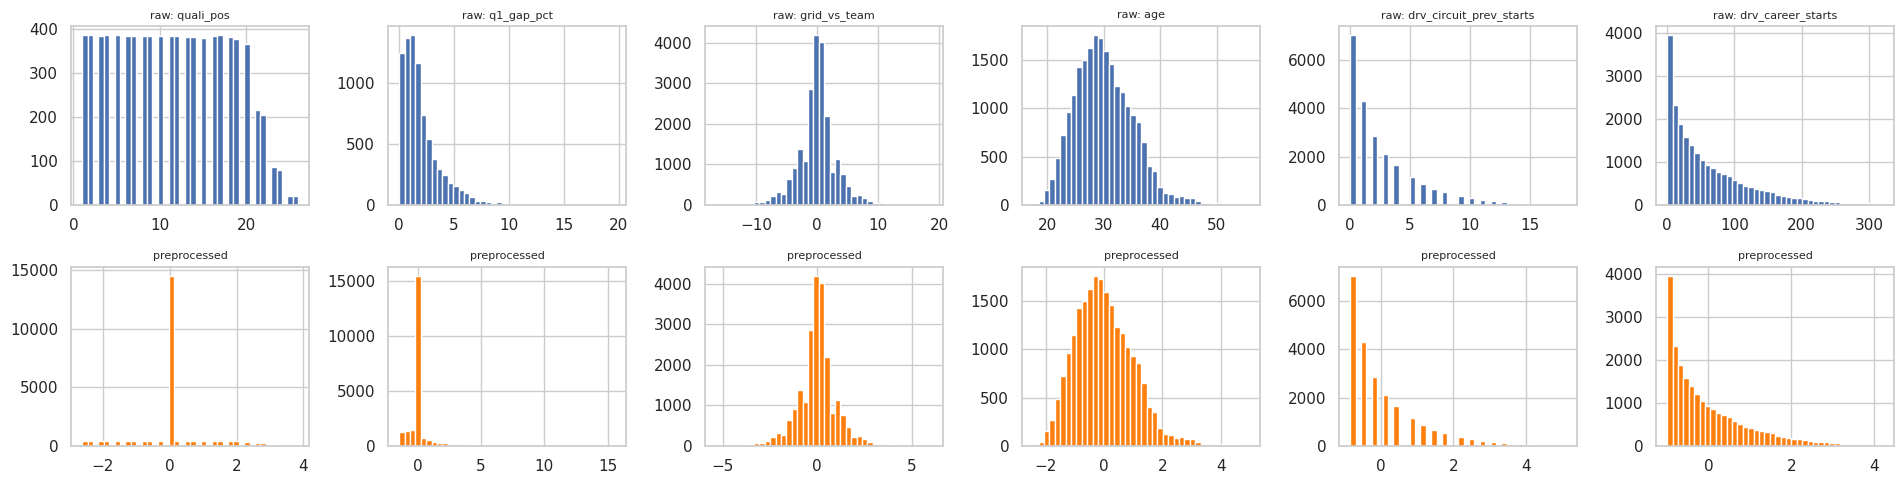

mean     std     min      max   skew  missing
quali_pos               before  11.345   6.359   1.000   26.000  0.082    0.631
                        after   -0.000   1.000  -2.618    3.845  0.302    0.000
q1_gap_pct              before   1.999   1.871   0.000   19.667  2.346    0.637
                        after   -0.000   1.000  -1.455   15.601  4.440    0.000
grid_vs_team            before  -0.000   3.091 -16.545   18.833  0.054    0.000
                        after   -0.000   1.000  -5.353    6.093  0.054    0.000
age                     before  30.044   5.184  17.454   55.797  0.639    0.000
                        after    0.000   1.000  -2.429    4.968  0.639    0.000
drv_circuit_prev_starts before   2.537   3.030   0.000   18.000  1.647    0.000
                        after    0.000   1.000  -0.837    5.103  1.647    0.000
drv_career_starts       before  61.425  61.577   0.000  321.000  1.419    0.000
                        after    0.000   1.000  -0.998    4.216  1.419    0.000

In [ ]:
show = [f for f in ["quali_pos", "q1_gap_pct", "grid_vs_team", "age", "drv_circuit_prev_starts", "drv_career_starts",
                    "drv_podium_rate_w%d" % BEST_W["drv_podium_rate"], "con_pts_share_prev"] if f in CONTINUOUS][:6]
Xs = pd.DataFrame(Xt[:, :len(CONTINUOUS)], columns=CONTINUOUS)      # Xt: training data through the linear preprocessor (from 4.1)
fig, axes = plt.subplots(2, len(show), figsize=(3.2 * len(show), 5))
for j, f in enumerate(show):
    axes[0, j].hist(train[f].dropna(), bins=40); axes[0, j].set_title(f"raw: {f}", fontsize=8)
    axes[1, j].hist(Xs[f], bins=40, color="tab:orange"); axes[1, j].set_title("preprocessed", fontsize=8)
plt.tight_layout(); plt.show()

stat = lambda s: pd.Series(dict(mean=s.mean(), std=s.std(), min=s.min(), max=s.max(), skew=s.skew(), missing=s.isna().mean()))
effect = pd.concat({f: pd.concat({"before": stat(train[f]), "after": stat(Xs[f])}, axis=1).T for f in show})
display(effect.round(3))

### 3.4.3 Preprocessing-order experiments (logistic regression, validation)
**P1:** statistics fitted on train only (correct) versus train + validation (leaky). Shows how far the learned medians move.
**P2:** five step orders: impute→scale, scale→impute, impute with indicators→scale, impute→clip→scale, clip→impute→scale.

> **4.3 Preprocessing-order experiments**
>
> **Purpose:** P1 compares fitting the preprocessor on train only (correct) with train plus validation (leaky), and measures how far the learned medians move. P2 compares five orders of imputing, scaling and clipping, each scored with logistic regression on validation.
>
> **Why it is needed:** the brief requires at least two preprocessing-order experiments. P1 shows why fit-on-train matters, and P2 shows whether the order changes performance or not.

,fit_on,roc_auc,pr_auc,top3_precision
0,train only (correct),0.9351,0.7427,0.6838
1,train + validation (leaky),0.9352,0.7427,0.6838


Largest shift in a learned median (in train standard deviations):


,median_train,median_train+val,std_train,std_train+val,median_shift
quali_gap_pct,1.826,1.780,1.120,1.129,0.041
q1_gap_pct,1.495,1.457,1.153,1.165,0.033
season_progress,0.556,0.550,0.288,0.288,0.019
drv_career_starts,41.000,42.000,61.575,63.962,0.016
age,29.544,29.481,5.184,5.216,0.012


,roc_auc,pr_auc,top3_precision
order,,,
A impute -> scale,0.9316,0.7333,0.6838
B scale -> impute,0.9316,0.7333,0.6838
C impute+indicator -> scale,0.9351,0.7428,0.6838
D impute -> clip -> scale,0.9301,0.7235,0.6838
E clip -> impute -> scale,0.9304,0.7249,0.6838


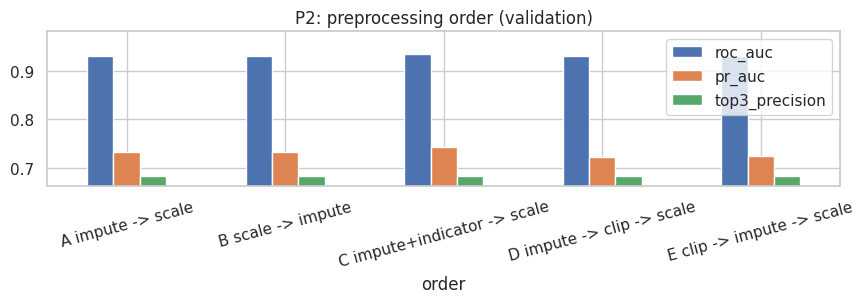

Best order by validation PR-AUC: C impute+indicator -> scale


In [ ]:
def lr_score(pre, fit_frame, train_df, val_df, feats):
    assert_no_test(fit_frame, train_df, val_df)
    p = clone(pre).fit(fit_frame[feats])
    clf = make_lr().fit(p.transform(train_df[feats]), train_df[TARGET])
    return evaluate(val_df, clf.predict_proba(p.transform(val_df[feats]))[:, 1]), p

# ---- P1 -------------------------------------------------------------------------------------
pre = make_preprocessor("linear")
s_correct, p_c = lr_score(pre, train, train, val, FEATURES)
s_leaky, p_l = lr_score(pre, pd.concat([train, val]), train, val, FEATURES)
med_c = p_c.named_transformers_["cont"].named_steps["imp"].statistics_
med_l = p_l.named_transformers_["cont"].named_steps["imp"].statistics_
sd_c = p_c.named_transformers_["cont"].named_steps["sc"].scale_
sd_l = p_l.named_transformers_["cont"].named_steps["sc"].scale_
p1 = pd.DataFrame([dict(fit_on="train only (correct)", **s_correct), dict(fit_on="train + validation (leaky)", **s_leaky)])
display(p1.round(4))
shift = pd.DataFrame({"median_train": med_c, "median_train+val": med_l, "std_train": sd_c[:len(med_c)], "std_train+val": sd_l[:len(med_c)]}, index=CONTINUOUS)
shift["median_shift"] = (shift["median_train+val"] - shift["median_train"]).abs() / (shift["std_train"] + 1e-9)
print("Largest shift in a learned median (in train standard deviations):")
display(shift.sort_values("median_shift", ascending=False).head(5).round(3))

# ---- P2 -------------------------------------------------------------------------------------
def variant(name):
    imp = make_median_imputer
    steps = {"A impute -> scale": [("imp", imp(False)), ("sc", StandardScaler())],
             "B scale -> impute": [("sc", StandardScaler()), ("imp", imp(False))],
             "C impute+indicator -> scale": [("imp", imp(True)), ("sc", StandardScaler())],
             "D impute -> clip -> scale": [("imp", imp(False)), ("clip", QuantileClipper()), ("sc", StandardScaler())],
             "E clip -> impute -> scale": [("clip", QuantileClipper()), ("imp", imp(False)), ("sc", StandardScaler())]}[name]
    return Pipeline(steps)

rows = []
for name in ["A impute -> scale", "B scale -> impute", "C impute+indicator -> scale", "D impute -> clip -> scale", "E clip -> impute -> scale"]:
    sc, _ = lr_score(variant(name), train, train, val, FEATURES)
    rows.append(dict(order=name, **sc))
p2 = pd.DataFrame(rows).set_index("order"); display(p2.round(4))
ax = p2[["roc_auc", "pr_auc", "top3_precision"]].plot(kind="bar", figsize=(9, 3.2), rot=15, title="P2: preprocessing order (validation)")
ax.set_ylim(p2[["roc_auc", "pr_auc", "top3_precision"]].min().min() - 0.02, None); plt.tight_layout(); plt.show()
print("Best order by validation PR-AUC:", p2["pr_auc"].idxmax())

**Reading P1/P2.** P1 usually shifts statistics only slightly, but it is wrong in principle because validation data influences the transformation. For P2, small differences are expected for a regularised linear model; report the printed numbers.
`make_preprocessor("linear")` is handed to the modeling section.

## 3.5 Final checks, saving and hand-off

> **Final checks, saving and hand-off**
>
> **Purpose:** asserts the final invariants (features exist and are unique, no overlap between features and IDs or target, unique grain, splits ordered in time, preprocessing runs on unseen rows). Then saves the modeling table, `feature_config.json` and `feature_dictionary.csv` to `clean/`.
>
> **Why it is needed:** acts as a gate before modeling and writes the artefacts that teammates and later sections load, so the modeling, ablation and XAI work all start from identical rows and features.

In [ ]:
# ---- final assertions ---------------------------------------------------------------------------------
assert set(FEATURES) <= set(mdl.columns) and len(FEATURES) == len(set(FEATURES))
assert not set(FEATURES) & set(ID_COLS + [TARGET, "split"])
assert not mdl.duplicated(["raceId", "driverId"]).any()
assert set(train["year"]) & set(TEST_YEARS) == set() and set(val["year"]) & set(TEST_YEARS) == set()
assert train["race_order"].max() < val["race_order"].min() and val["race_order"].max() < test["race_order"].min()
assert not train[FEATURES].isna().all().any(), "a selected feature is empty in training data"
assert np.isfinite(make_preprocessor("linear").fit(train[FEATURES]).transform(test[FEATURES])).all()   # the pipeline runs on unseen rows (features only)
print(f"OK: {len(FEATURES)} features | train {len(train):,} | val {len(val):,} | test {len(test):,} | "
      f"window {WINDOW_START}-{LAST_YEAR} | test seasons {TEST_YEARS}")

# ---- save for teammates / the modeling section ---------------------------------------------------------
OUT_FE = OUT if "OUT" in globals() else "clean/"
os.makedirs(OUT_FE, exist_ok=True)
config = dict(features=FEATURES, binary=BINARY, continuous=CONTINUOUS, groups=FEATURE_GROUPS, target=TARGET,
              window_start=WINDOW_START, include_status_form=INCLUDE_STATUS_FORM, train_years=sorted(map(int, train["year"].unique())),
              val_years=VAL_YEARS, test_years=TEST_YEARS, form_windows=BEST_W, seed=SEED)
with open(OUT_FE + "feature_config.json", "w") as fh:
    json.dump(config, fh, indent=2)
feature_dictionary.to_csv(OUT_FE + "feature_dictionary.csv", index=False)
mdl.drop(columns=["era"], errors="ignore").to_parquet(OUT_FE + "modeling_table.parquet", index=False)
print("Saved modeling table, feature_config.json and feature_dictionary.csv to", OUT_FE)

OK: 29 features | train 22,441 | val 774 | test 1,351 | window 1950-2024 | test seasons [2022, 2023, 2024]
Saved modeling table, feature_config.json and feature_dictionary.csv to /kaggle/working/clean/


### Handed to the modeling, ablation and XAI sections
| Object | What it is |
|---|---|
| `train`, `val`, `test` | chronological splits (`test` stays closed until the end) |
| `FEATURES`, `CONTINUOUS`, `BINARY` | final feature list and types |
| `FEATURE_GROUPS` | `{group: [features]}`, for the ablation |
| `make_preprocessor(kind)` | `"linear"` (logistic regression, NN), `"tree"`, `"native"` (HistGradientBoosting etc.) |
| `evaluate(df, p)` | ROC-AUC, PR-AUC, top-3 precision per race (add F1 at a threshold chosen on train/val) |
| `season_walk_forward(train)` | time-ordered folds for hyperparameter search |
| `feature_dictionary` | feature definitions for the report |
| `build_modeling_table(tables)` | reuse for the inference function |


# Task 4a: Predictive Modeling (statistical models)
Trains and compares three statistical models on the modeling table built in Task 3. The shallow neural network is a separate section and plugs into the same comparison (see Part 9).

| Part | What it does |
|---|---|
| 1 | Loads the modeling table, features and splits from the feature-engineering notebook |
| 2 | Metrics, primary/secondary choice, how the threshold is chosen |
| 3 | Baselines (no-skill, grid-only logistic regression) |
| 4 | The three models: how each works, limits, and why it is here |
| 5 | Hyperparameter search with walk-forward folds **inside train** |
| 6 | Initial vs tuned settings on validation, final model per family |
| 7 | Thresholds (validation only) and train / validation results |
| 8 | Unseen test results, plots, stability checks |
| 9 | Hand-off to ablation, XAI, inference and the neural network |

**Same rows, same features for every model.** Only the preprocessing differs, because the model families need different inputs (scaling for the linear model, none for trees).
**Test seasons stay closed** until Part 8. Hyperparameters, settings and thresholds are chosen on train and validation only.

In [68]:
# Setup: install any missing library (XGBoost is not preinstalled everywhere), then continue. Safe to re-run.
import importlib.util, subprocess, sys
for _mod, _pip in [("xgboost", "xgboost"), ("pyarrow", "pyarrow"), ("joblib", "joblib")]:
    if importlib.util.find_spec(_mod) is None:
        print(f"installing {_pip} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pip])
print("xgboost, pyarrow, joblib available")

xgboost, pyarrow, joblib available


In [69]:
import os, glob, json, math, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             roc_curve, precision_recall_curve, confusion_matrix)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 160)
SEED = 42
np.random.seed(SEED)
N_JOBS = max(1, min(os.cpu_count() or 2, 4))      # explicit thread count (n_jobs=-1 can oversubscribe shared notebook machines)
print("CPU threads used by the models:", N_JOBS)

CPU threads used by the models: 4


## 4a.1 Load the modeling table, features and splits
Reads the files saved at the end of Task 3 (Part 5) (`modeling_table`, `feature_config.json`). On Kaggle, attach the output of the feature-engineering notebook as an input. The split column was set there (train ≤ 2019, validation 2020–21, test ≥ 2022), so the split rule is not re-decided here.

In [70]:
def find_artifacts():
    cands = [os.environ.get("F1_CLEAN_DIR", ""), "/kaggle/working/clean/", "clean/", "../clean/"]
    cands += [os.path.dirname(p) + "/" for p in glob.glob("/kaggle/input/**/feature_config.json", recursive=True)]
    for c in cands:
        if c and os.path.exists(c + "feature_config.json") and (os.path.exists(c + "modeling_table.parquet") or os.path.exists(c + "modeling_table.csv")):
            return c
    raise FileNotFoundError("feature_config.json / modeling_table not found. Run the feature-engineering notebook (Task 3, Part 5 saves them) "
                            "or attach its output, or set F1_CLEAN_DIR.")

OUT = find_artifacts()
cfg = json.load(open(OUT + "feature_config.json"))
mdl = pd.read_parquet(OUT + "modeling_table.parquet") if os.path.exists(OUT + "modeling_table.parquet") else pd.read_csv(OUT + "modeling_table.csv")

TARGET, FEATURES = cfg["target"], list(cfg["features"])
BINARY, CONTINUOUS = list(cfg["binary"]), list(cfg["continuous"])
FEATURE_GROUPS = {g: list(f) for g, f in cfg["groups"].items()}
VAL_YEARS, TEST_YEARS = cfg["val_years"], cfg["test_years"]
mdl = mdl.sort_values(["race_order", "driverId"]).reset_index(drop=True)

train = mdl[mdl["split"] == "train"].copy()
val = mdl[mdl["split"] == "val"].copy()
test = mdl[mdl["split"] == "test"].copy()          # not touched until Part 8
SPLITS = {"train": train, "val": val}              # test is added to this dict only in Part 8

# structural checks
assert set(FEATURES) <= set(mdl.columns) and len(FEATURES) == len(set(FEATURES))
assert set(BINARY) | set(CONTINUOUS) == set(FEATURES)
assert not mdl.duplicated(["raceId", "driverId"]).any(), "grain broken"
assert not (set(train["raceId"]) & set(val["raceId"])) and not (set(val["raceId"]) & set(test["raceId"]))
assert train["race_order"].max() < val["race_order"].min() and val["race_order"].max() < test["race_order"].min()

print(f"Artifacts from: {OUT}")
print(f"{len(FEATURES)} features ({len(BINARY)} binary, {len(CONTINUOUS)} continuous) in groups {list(FEATURE_GROUPS)}")
summary = (mdl.groupby("split").agg(rows=(TARGET, "size"), races=("raceId", "nunique"), first=("year", "min"), last=("year", "max"),
                                    podiums=(TARGET, "sum"), podium_rate=(TARGET, "mean")).loc[["train", "val", "test"]])
display(summary.round(3))

Artifacts from: /kaggle/working/clean/
29 features (4 binary, 25 continuous) in groups ['grid', 'qualifying', 'driver_form', 'constructor_form', 'standings', 'circuit_history', 'context']


,rows,races,first,last,podiums,podium_rate
split,,,,,,
train,22441,1007,1950,2019,3021,0.135
val,774,39,2020,2021,117,0.151
test,1351,68,2022,2024,204,0.151


**Why it is done this way**
- The split is read from `feature_config.json` and the `split` column, not recomputed, so Tasks 4a, 4b, 5 and 6 all use exactly the same train / validation / test rows.
- The asserts stop the run early if the table is broken: a duplicated driver-race row, a feature listed twice, or seasons overlapping between splits. A silent overlap would let future races into training.
- `test` is created here but only added to `SPLITS` in Part 8, so no table or plot before that can score it by accident.
- Rows are sorted by `race_order`, so the walk-forward folds in Part 5 follow time order.

In [71]:
# Preprocessing from Task 3, Part 4 (copied so this notebook runs on its own; same logic, fitted on training rows only)
# linear: impute (+missing indicator) -> scale | tree: impute (+indicator) | native: pass through, NaN handled by the model
# (clipping was tested in Task 3, Part 4.3 and did not help, so the final linear preprocessor has no clipping step)
def make_preprocessor(kind="linear", continuous=None, binary=None):
    continuous = CONTINUOUS if continuous is None else continuous
    binary = BINARY if binary is None else binary
    if kind == "native":
        return ColumnTransformer([("all", "passthrough", continuous + binary)], verbose_feature_names_out=False)
    imp = lambda: SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)
    cont = [("imp", imp())] + ([("sc", StandardScaler())] if kind == "linear" else [])
    return ColumnTransformer([("cont", Pipeline(cont), continuous),
                              ("bin", SimpleImputer(strategy="most_frequent", keep_empty_features=True), binary)])

def season_walk_forward(d, n_folds=3):
    # expanding-window folds: train on seasons < s, validate on season s
    yrs = sorted(d["year"].unique())[-n_folds:]
    return [(d.index[d["year"] < s], d.index[d["year"] == s]) for s in yrs]

def assert_no_test(*frames):
    for f in frames:
        assert "test" not in set(f["split"]), "test rows leaked into a model-selection step"

**Why it is done this way**
- Preprocessing sits inside a `Pipeline` with the model, so `fit` learns medians and scaling only from the rows it is fitted on (train, or the earlier seasons of a fold). Validation and test rows are only transformed.
- Three kinds because the models need different inputs: logistic regression needs scaled numbers and no NaN; the random forest needs no NaN, but scaling would change nothing (a split only depends on the order of values); XGBoost learns its own direction for missing values, so the data is passed through.
- `add_indicator=True` adds a 0/1 column for every feature that had missing values in train, so the model can tell an imputed median from a real one (for example, no qualifying data before 1994). This is why 29 features become 43 model inputs.
- `keep_empty_features=True` keeps the number of columns fixed even if a feature is completely empty in a small fold.
- `season_walk_forward` builds expanding-window folds (fit on all seasons before *s*, score season *s*): the time-ordered version of k-fold.
- `assert_no_test` is called inside the search, so a test row reaching tuning would crash the run instead of silently inflating the scores.

## 4a.2 Metrics and how they are used
| Metric | Role here |
|---|---|
| **PR-AUC** | **Primary.** Only about 15% of rows are podiums (3 of ~20 starters), and PR-AUC only rewards ranking the true podium drivers above the rest. It does not depend on a threshold. |
| **ROC-AUC** | **Secondary.** Threshold-free and easy to compare, but the many easy negatives (back of the grid) make it look high even for weak models. |
| **F1** | Reported at one threshold per model. It depends on that threshold, so it is not used to pick models. |
| Precision / recall | Reported next to F1 to show what the threshold trades off. |
| Top-3 precision per race | Extra, race-aware: of the 3 drivers the model ranks highest in a race, how many really podiumed. |

**Threshold rule.** For each model, the F1-optimal threshold is searched on **validation** predictions (the model was fitted on train only) and then frozen for train and test. Training predictions are not used to choose it because flexible models are over-confident on rows they have seen.

**Uncertainty.** Validation is two seasons and test is three, so differences are small relative to noise. A race-level bootstrap (resample whole races) gives a 95% interval for PR-AUC. Only trust gaps that are clearly outside it.

In [72]:
def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return float(thr[int(np.nanargmax(f1[:-1]))])

def metrics_at(d, p, thr):
    y = d[TARGET].to_numpy(); p = np.asarray(p, float); pred = (p >= thr).astype(int)
    top3 = d.assign(_p=p).sort_values(["raceId", "_p"], ascending=[True, False]).groupby("raceId").head(3)
    return dict(roc_auc=float(roc_auc_score(y, p)), pr_auc=float(average_precision_score(y, p)), f1=f1_score(y, pred, zero_division=0),
                precision=precision_score(y, pred, zero_division=0), recall=recall_score(y, pred, zero_division=0),
                top3_precision=float(top3[TARGET].mean()))

def pr_auc_ci(d, p, n_boot=300, seed=SEED):
    # bootstrap over RACES (rows in a race are not independent)
    rng = np.random.default_rng(seed); p = np.asarray(p, float)
    y = d[TARGET].to_numpy(); race = d["raceId"].to_numpy()
    idx_by_race = pd.Series(np.arange(len(d))).groupby(race).apply(lambda s: s.to_numpy()).tolist()
    vals = []
    for _ in range(n_boot):
        pick = np.concatenate([idx_by_race[i] for i in rng.integers(0, len(idx_by_race), len(idx_by_race))])
        vals.append(average_precision_score(y[pick], p[pick]))
    return tuple(np.percentile(vals, [2.5, 97.5]))

**Why it is done this way**
- `average_precision_score` is scikit-learn's PR-AUC (area under the precision-recall curve as a step sum). It is primary because with about 15% positives, ROC-AUC is pulled up by the many easy back-of-grid negatives.
- `best_f1_threshold` takes the threshold with the highest F1 on the precision-recall curve (`f1[:-1]` drops the last curve point, which has no threshold). It is only ever called on **validation** predictions; the value is then frozen.
- The F1-best threshold is used instead of 0.5 because class weighting pushes predicted probabilities up (the chosen thresholds end up between 0.67 and 0.79), so 0.5 has no special meaning here.
- `pr_auc_ci` resamples whole **races**, not rows: drivers in the same race share track, weather and the fact that exactly three of them podium, so they are not independent. Resampling rows would give intervals that are too narrow.
- `top3_precision` sorts each race by predicted probability and keeps the top three: the "pick the podium" rule a user would actually apply.

## 4a.3 Baselines
A baseline is the simplest reasonable reference, so we can tell whether a bigger model earns its complexity.
- **No-skill:** predict the same probability for everyone. PR-AUC then equals the podium rate.
- **Grid-only logistic regression:** the starting slot alone, the strongest single pre-race signal found in Task 3, Part 3.1. This is the statistical-model baseline every full model must beat.
Both are reference rows, not part of the three-model comparison (they use one feature, the models use all of them).

In [73]:
def fit_predict_grid_baseline(fit_df, *eval_dfs):
    m = LogisticRegression(max_iter=2000, class_weight="balanced").fit(fit_df[["grid_clean"]].fillna(fit_df["grid_clean"].median()), fit_df[TARGET])
    med = fit_df["grid_clean"].median()
    return [m.predict_proba(d[["grid_clean"]].fillna(med))[:, 1] for d in eval_dfs]

p_tr_b, p_va_b = fit_predict_grid_baseline(train, train, val)
thr_base = best_f1_threshold(val[TARGET], p_va_b)
base_rows = {"no-skill (prevalence)": dict(roc_auc=0.5, pr_auc=val[TARGET].mean(), f1=np.nan, precision=np.nan, recall=np.nan, top3_precision=np.nan),
             "grid-only LR": metrics_at(val, p_va_b, thr_base)}
base_val = pd.DataFrame(base_rows).T
print("Baselines on validation (threshold for grid-only LR chosen on validation):")
display(base_val.round(4))

Baselines on validation (threshold for grid-only LR chosen on validation):


,roc_auc,pr_auc,f1,precision,recall,top3_precision
no-skill (prevalence),0.5000,0.1512,NaN,NaN,NaN,NaN
grid-only LR,0.9101,0.6478,0.6953,0.6983,0.6923,0.7009


**Why it is done this way**
- A constant score needs no model: its PR-AUC equals the podium rate (0.151), the floor every model must clear.
- The grid-only model uses one feature, `grid_clean`, with the same class weighting, so the gap to the full models measures what the other 28 features add.
- It follows the same rules as the real models: fitted on train, missing grids filled with the **train** median, threshold chosen on validation.
- Grid alone is already strong (validation PR-AUC 0.648), so the full models are judged against it, not against no skill.

## 4a.4 The three models
All three give a podium probability per driver-race. Preprocessing follows Task 3, Part 4: `linear` for logistic regression (impute + missing flags, scale), `tree` for random forest (impute + missing flags), `native` for XGBoost (it handles missing values itself).

**1. Logistic regression (linear baseline family).**
*How it works:* a weighted sum of the standardised features is squashed to a 0–1 probability; weights are fitted by minimising log-loss with an L2 penalty (`C` controls its strength).
*Why here:* transparent, hard to overfit, and the reference every other model must beat. Class weights are balanced because podiums are rare (all models use the same idea: random forest `balanced_subsample`, XGBoost `scale_pos_weight`, the neural network repeats podium rows).
*Limits:* only straight-line effects in the features (grid 1→2 is treated like grid 15→16 in log-odds), no automatic interactions (e.g. a strong car matters more from the front), sensitive to scaling and outliers.

**2. XGBoost (gradient boosting, sequential trees).**
*How it works:* many small trees added one at a time, each fitted to the mistakes (gradient of the loss) of the trees before it; learning rate, depth and regularisation keep it from memorising.
*Why here:* strong on tabular data, captures non-linear effects and interactions, handles missing values natively (useful: qualifying data is missing for early eras).
*Limits:* more hyperparameters, can overfit a small training set, probabilities are not always well calibrated, and it extrapolates poorly to a new regulation era.

**3. Random forest (bagging, parallel trees) — the extra model.**
*How it works:* a few hundred trees (depth-limited here), each fitted on a bootstrap sample with a random subset of features at each split, then averaged.
*Why this one:* it reduces **variance** by averaging independent trees, while XGBoost reduces **bias** by boosting. That makes it a real alternative to boosting and a different idea from logistic regression. It also handles non-linearity and needs little tuning, so it is a fair check that gains are not just from boosting.
*Limits:* predictions are piecewise-constant and averaged, so probabilities are compressed toward the middle; large models; no extrapolation beyond the training range.

In [74]:
# Initial settings: sensible starting points chosen BEFORE tuning (not the libraries' defaults), shown as the "initial" attempt
INITIAL = {
    "lr":  dict(C=1.0),
    "rf":  dict(n_estimators=300, max_depth=8, min_samples_leaf=20, max_features="sqrt"),
    "xgb": dict(n_estimators=300, learning_rate=0.05, max_depth=4, min_child_weight=5, subsample=0.8, colsample_bytree=0.8),
}
POS_WEIGHT = float((train[TARGET] == 0).sum() / (train[TARGET] == 1).sum())   # about 6.4: same imbalance handling for every model
NAMES = {"lr": "Logistic regression", "xgb": "XGBoost", "rf": "Random forest"}
PREP = {"lr": "linear", "rf": "tree", "xgb": "native"}

def build(kind, **params):
    p = {**INITIAL[kind], **params}
    if kind == "lr":
        est = LogisticRegression(class_weight="balanced", max_iter=5000, **p)
    elif kind == "rf":
        est = RandomForestClassifier(class_weight="balanced_subsample", n_jobs=N_JOBS, random_state=SEED, **p)
    else:
        est = XGBClassifier(tree_method="hist", eval_metric="logloss", scale_pos_weight=POS_WEIGHT,
                            n_jobs=N_JOBS, random_state=SEED, verbosity=0, **p)
    return Pipeline([("pre", make_preprocessor(PREP[kind])), ("clf", est)])

def proba(model, d): return model.predict_proba(d[FEATURES])[:, 1]

# smoke test: every model fits and predicts on the same rows/features
FIT_TIME = {}
for k in NAMES:
    t0 = time.time(); m = build(k).fit(train[FEATURES], train[TARGET]); FIT_TIME[k] = time.time() - t0
    print(f"{NAMES[k]:20s} fit {FIT_TIME[k]:5.1f}s | {len(FEATURES)} features -> {m.named_steps['pre'].transform(train[FEATURES].head(3)).shape[1]} model inputs")

Logistic regression  fit   0.7s | 29 features -> 43 model inputs
XGBoost              fit   0.8s | 29 features -> 29 model inputs
Random forest        fit   4.4s | 29 features -> 43 model inputs


**Why it is done this way**
- Initial settings are hand-picked starting values written down before tuning (not library defaults), so Part 6 can show the trial and error: initial attempt vs tuned attempt.
- Class imbalance: there are about 6.4 non-podium rows per podium row in train (`POS_WEIGHT`). Every model gets the same idea in its own form: `class_weight="balanced"` (logistic regression), `"balanced_subsample"` (random forest, recomputed on each tree's bootstrap sample), `scale_pos_weight` (XGBoost). Without it, the loss is dominated by non-podium rows.
- `max_iter=5000`: with a strong penalty and 43 inputs, the default 100 solver iterations can stop before converging.
- `tree_method="hist"` is XGBoost's fast histogram method and supports NaN natively.
- `random_state=SEED` and a fixed `N_JOBS` make results repeatable and avoid overloading Kaggle's shared CPUs.
- The smoke test fits each model once: it proves the three pipelines run on the same rows and features, and the fit times give the time estimate for Part 5.

## 4a.5 Hyperparameter search (train only)
Each setting is scored on the **walk-forward folds inside train**: fit on all seasons before season *s*, score PR-AUC on season *s*, for the last three training seasons. This respects time order (a shuffled k-fold would let a model see the future). The preprocessor is refitted inside every fold. Validation and test seasons are not used here.
Grids are small on purpose: train has about 22,000 rows but only about 1,000 races, and a large search scored on three folds would mostly fit noise. The setting with the best mean fold PR-AUC wins; the full trial tables are kept below as the record of attempts.

In [75]:
GRIDS = {
    "lr":  dict(C=[0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0]),
    "rf":  dict(max_depth=[4, 8], min_samples_leaf=[10, 30, 60], max_features=["sqrt", 0.5]),
    "xgb": dict(max_depth=[2, 3, 4], learning_rate=[0.03, 0.08], n_estimators=[150, 300], min_child_weight=[5, 20]),
}
FIXED = {"rf": dict(n_estimators=150)}      # fewer trees while searching only
n_set = {k: int(np.prod([len(v) for v in g.values()])) for k, g in GRIDS.items()}
est = sum(FIT_TIME[k] * n_set[k] * 3 * (0.5 if k in FIXED else 1) for k in GRIDS)
print(f"Settings to try: {n_set} x 3 folds. Rough time estimate: {est/60:.1f} min (from the fit times above; progress is printed below).")
folds = season_walk_forward(train, n_folds=3)
for i, (a, b) in enumerate(folds):
    print(f"fold {i}: fit on {len(a):,} rows (seasons < {int(train.loc[b, 'year'].iloc[0])}) -> score season {int(train.loc[b, 'year'].iloc[0])} ({len(b)} rows)")

def cv_pr_auc(kind, params):
    assert_no_test(train)
    s = []
    for a_idx, b_idx in folds:
        a, b = train.loc[a_idx], train.loc[b_idx]
        s.append(average_precision_score(b[TARGET], proba(build(kind, **params).fit(a[FEATURES], a[TARGET]), b)))
    return float(np.mean(s)), float(np.std(s))

TRIALS, BEST_PARAMS = {}, {}
for kind, grid in GRIDS.items():
    t0 = time.time(); rows, plist = [], []
    for combo in itertools.product(*grid.values()):
        params = dict(zip(grid, combo)); m, sd = cv_pr_auc(kind, {**FIXED.get(kind, {}), **params})
        rows.append(dict(**params, cv_pr_auc=m, cv_std=sd)); plist.append(params)
        print(f"\r  {NAMES[kind]}: {len(rows)}/{n_set[kind]} settings, {time.time()-t0:.0f}s elapsed", end="", flush=True)
    print()
    TRIALS[kind] = pd.DataFrame(rows).sort_values("cv_pr_auc", ascending=False)
    BEST_PARAMS[kind] = dict(plist[int(TRIALS[kind].index[0])])     # without FIXED: the final model uses the full number of trees
    TRIALS[kind] = TRIALS[kind].reset_index(drop=True)
    best = TRIALS[kind].iloc[0]
    print(f"{NAMES[kind]:20s} {len(rows):3d} settings in {time.time()-t0:5.1f}s | best CV PR-AUC {best['cv_pr_auc']:.4f} (+/- {best['cv_std']:.4f}) with {BEST_PARAMS[kind]}")

Settings to try: {'lr': 7, 'rf': 12, 'xgb': 24} x 3 folds. Rough time estimate: 2.6 min (from the fit times above; progress is printed below).
fold 0: fit on 21,203 rows (seasons < 2017) -> score season 2017 (399 rows)
fold 1: fit on 21,602 rows (seasons < 2018) -> score season 2018 (420 rows)
fold 2: fit on 22,022 rows (seasons < 2019) -> score season 2019 (419 rows)
  Logistic regression: 7/7 settings, 12s elapsed
Logistic regression    7 settings in  12.1s | best CV PR-AUC 0.7108 (+/- 0.0096) with {'C': 0.01}
  Random forest: 12/12 settings, 104s elapsed
Random forest         12 settings in 103.8s | best CV PR-AUC 0.7402 (+/- 0.0193) with {'max_depth': 8, 'min_samples_leaf': 60, 'max_features': 0.5}
  XGBoost: 24/24 settings, 32s elapsed
XGBoost               24 settings in  32.2s | best CV PR-AUC 0.7335 (+/- 0.0490) with {'max_depth': 4, 'learning_rate': 0.08, 'n_estimators': 150, 'min_child_weight': 5}


**Why it is done this way**
- **Walk-forward, not shuffled k-fold.** A shuffled fold would train on 2019 races to predict 2017, so form and standings from the future would help. Expanding windows copy real use: predict the next season from all earlier ones.
- **Folds = last three training seasons (2017-2019):** closest to the validation and test eras, so tuning targets modern F1. Three folds give a mean and a spread (`cv_std`).
- **Small grids on the knobs that control overfitting:** `C` (penalty strength, log scale) for logistic regression; depth, leaf size and features per split for the forest; depth, learning rate, number of trees and `min_child_weight` for XGBoost. That is 7 + 12 + 24 = 43 settings x 3 folds; a much larger grid scored on three folds would mostly pick noise.
- **`FIXED`:** the forest uses 150 trees during the search only, which halves the time. More trees only lower a forest's variance; they do not change which depth or leaf size is best. `BEST_PARAMS` is stored **without** `FIXED`, so the final forest has 300 trees.
- For XGBoost the number of trees is tuned, not fixed, because in boosting it interacts with the learning rate.
- Validation and test are not used in this cell.

--- Logistic regression: top 5 of 7 settings (mean PR-AUC over 3 walk-forward folds)


,C,cv_pr_auc,cv_std
0,0.010,0.7108,0.0096
1,0.003,0.7095,0.0047
2,0.100,0.7071,0.0148
3,0.300,0.7068,0.0143
4,0.030,0.7067,0.0143


--- Random forest: top 5 of 12 settings (mean PR-AUC over 3 walk-forward folds)


,max_depth,min_samples_leaf,max_features,cv_pr_auc,cv_std
0,8,60,0.5,0.7402,0.0193
1,8,30,sqrt,0.7386,0.0253
2,8,10,sqrt,0.7383,0.0278
3,8,10,0.5,0.7353,0.0340
4,8,60,sqrt,0.7341,0.0255


--- XGBoost: top 5 of 24 settings (mean PR-AUC over 3 walk-forward folds)


,max_depth,learning_rate,n_estimators,min_child_weight,cv_pr_auc,cv_std
0,4,0.08,150,5,0.7335,0.0490
1,3,0.08,150,20,0.7307,0.0505
2,4,0.03,300,20,0.7288,0.0512
3,2,0.08,150,20,0.7277,0.0715
4,2,0.03,300,20,0.7265,0.0658


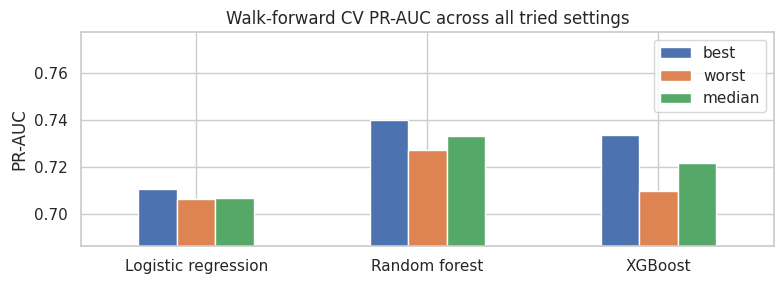

In [76]:
for kind in TRIALS:
    print(f"--- {NAMES[kind]}: top 5 of {len(TRIALS[kind])} settings (mean PR-AUC over 3 walk-forward folds)")
    display(TRIALS[kind].head(5).round(4))

# how sensitive is each model to its settings? spread between best and worst setting
spread = pd.DataFrame({NAMES[k]: dict(best=t["cv_pr_auc"].max(), worst=t["cv_pr_auc"].min(), median=t["cv_pr_auc"].median()) for k, t in TRIALS.items()}).T
ax = spread.plot(kind="bar", figsize=(8, 3), rot=0, title="Walk-forward CV PR-AUC across all tried settings"); ax.set_ylabel("PR-AUC")
ax.set_ylim(spread.min().min() - 0.02, None); plt.tight_layout(); plt.show()

**Why it is done this way**
- The top-5 tables are the record of attempts.
- The best / median / worst bars show how sensitive each family is to its settings. A small spread means the settings matter little, so the differences between families come from the model type, not from tuning luck.

## 4a.6 Initial vs tuned settings (validation)
Trial and error shown side by side: every family is fitted on train twice, once with the initial settings and once with the settings chosen in Part 5, and scored on validation. The tuned setting is the final model of each family: it was picked on three walk-forward seasons of train, which is more evidence than the two validation seasons. Validation is the check that tuning did not hurt and that overfitting went down (compare the train-minus-validation gap).

**Why train PR-AUC is lower than validation.** The training rows go back to 1950: larger fields, no qualifying data before 1994 and less reliable cars make those seasons much harder to predict than 2020-21. A negative gap therefore does not mean the models underfit; compare the gap between models (a larger gap = more memorising), not its sign.

,model,attempt,train_pr_auc,val_pr_auc,val_roc_auc,gap_train_minus_val
0,Logistic regression,initial,0.5707,0.7427,0.9351,-0.1720
1,Logistic regression,tuned,0.5734,0.7369,0.9329,-0.1635
2,XGBoost,initial,0.6581,0.6865,0.9295,-0.0283
3,XGBoost,tuned,0.6392,0.6960,0.9282,-0.0567
4,Random forest,initial,0.6390,0.7224,0.9305,-0.0833
5,Random forest,tuned,0.6295,0.7214,0.9285,-0.0918


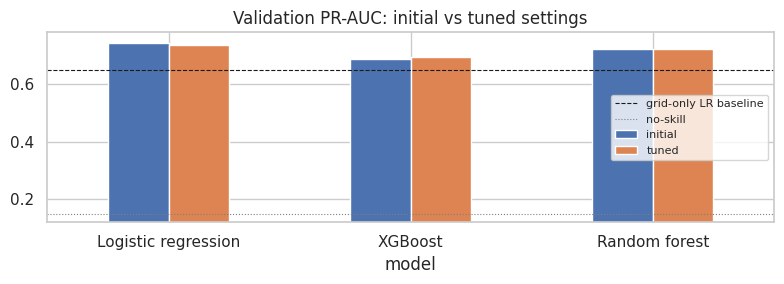

Logistic regression  tuned vs initial on validation: PR-AUC -0.0058, train-val gap +0.0085
XGBoost              tuned vs initial on validation: PR-AUC +0.0095, train-val gap -0.0284
Random forest        tuned vs initial on validation: PR-AUC -0.0010, train-val gap -0.0085
Final settings per family (chosen on train walk-forward CV; validation used as a check): {'Logistic regression': {'C': 0.01}, 'XGBoost': {'max_depth': 4, 'learning_rate': 0.08, 'n_estimators': 150, 'min_child_weight': 5}, 'Random forest': {'max_depth': 8, 'min_samples_leaf': 60, 'max_features': 0.5}}


In [77]:
cmp_rows, fitted = [], {}
for kind in NAMES:
    for tag, params in [("initial", {}), ("tuned", BEST_PARAMS[kind])]:
        m = build(kind, **params).fit(train[FEATURES], train[TARGET]); fitted[(kind, tag)] = m
        pv, pt = proba(m, val), proba(m, train)
        cmp_rows.append(dict(model=NAMES[kind], attempt=tag, train_pr_auc=average_precision_score(train[TARGET], pt),
                             val_pr_auc=average_precision_score(val[TARGET], pv), val_roc_auc=roc_auc_score(val[TARGET], pv),
                             params={**INITIAL[kind], **params}))
attempts = pd.DataFrame(cmp_rows)
attempts["gap_train_minus_val"] = attempts["train_pr_auc"] - attempts["val_pr_auc"]
display(attempts.drop(columns="params").round(4))

pv = attempts.pivot(index="model", columns="attempt", values="val_pr_auc").loc[list(NAMES.values())]
ax = pv.plot(kind="bar", figsize=(8, 3), rot=0, title="Validation PR-AUC: initial vs tuned settings")
ax.axhline(base_val.loc["grid-only LR", "pr_auc"], color="k", ls="--", lw=0.8, label="grid-only LR baseline")
ax.axhline(val[TARGET].mean(), color="grey", ls=":", lw=0.8, label="no-skill"); ax.set_ylim(val[TARGET].mean() * 0.8, None); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

FINAL_TAG = {k: "tuned" for k in NAMES}
FINAL = {NAMES[k]: fitted[(k, FINAL_TAG[k])] for k in NAMES}                # fitted on train only
FINAL_PARAMS = {NAMES[k]: {**INITIAL[k], **(BEST_PARAMS[k] if FINAL_TAG[k] == "tuned" else {})} for k in NAMES}
for k in NAMES:
    a = attempts[attempts["model"] == NAMES[k]].set_index("attempt")
    print(f"{NAMES[k]:20s} tuned vs initial on validation: PR-AUC {a.loc['tuned','val_pr_auc'] - a.loc['initial','val_pr_auc']:+.4f}, "
          f"train-val gap {a.loc['tuned','gap_train_minus_val'] - a.loc['initial','gap_train_minus_val']:+.4f}")
print("Final settings per family (chosen on train walk-forward CV; validation used as a check):", {NAMES[k]: BEST_PARAMS[k] for k in NAMES})

**Why it is done this way**
- Both attempts are fitted on all of train and scored on validation, which documents the trial and error.
- The tuned setting is kept as final even where validation is a little lower (in the Kaggle run: logistic regression -0.006, random forest -0.001). Those differences are far smaller than the validation interval (about +/-0.10, Part 8), while the tuned setting won on three seasons of walk-forward CV. Switching back because of the validation score would turn validation into a selection set and make its score optimistic.
- What tuning picked: logistic regression `C=0.01` is a strong penalty (many correlated form and standings features, so smaller weights are more stable); the forest picked depth 8 with at least 60 rows per leaf; XGBoost picked 150 trees of depth 4. All three prefer simpler models, consistent with little signal beyond grid position.

## 4a.7 Thresholds and train / validation results
`REGISTRY` maps a model name to a function that returns podium probabilities for a dataframe. Everything below (tables, curves) loops over it, so another model, such as the neural network, can be added with one line (see Part 9).

In [78]:
REGISTRY = {name: (lambda d, m=m: proba(m, d)) for name, m in FINAL.items()}
THRESHOLDS = {}

def score_table(splits):
    rows = []
    for name, predict in REGISTRY.items():
        for sp, d in splits.items():
            rows.append(dict(model=name, split=sp, threshold=THRESHOLDS[name], **metrics_at(d, predict(d), THRESHOLDS[name])))
    return pd.DataFrame(rows)

# threshold per model: F1-optimal on VALIDATION predictions
for name, predict in REGISTRY.items():
    THRESHOLDS[name] = best_f1_threshold(val[TARGET], predict(val))
print("F1-optimal thresholds (validation):", {k: round(v, 3) for k, v in THRESHOLDS.items()})

res_trval = score_table(SPLITS)
display(res_trval.pivot(index="model", columns="split", values=["roc_auc", "pr_auc", "f1"]).round(4).loc[list(REGISTRY)])

F1-optimal thresholds (validation): {'Logistic regression': 0.671, 'XGBoost': 0.741, 'Random forest': 0.733}


roc_auc          pr_auc              f1        
split                 train     val   train     val   train     val
model                                                              
Logistic regression  0.9025  0.9329  0.5734  0.7369  0.5842  0.7109
XGBoost              0.9299  0.9282  0.6392  0.6960  0.6195  0.7113
Random forest        0.9213  0.9285  0.6295  0.7214  0.6076  0.7078

split,train,val,gap
model,,,
Logistic regression,0.5734,0.7369,-0.1635
XGBoost,0.6392,0.6960,-0.0567
Random forest,0.6295,0.7214,-0.0918


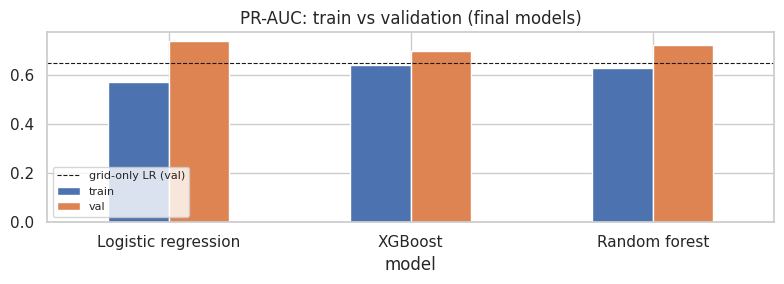

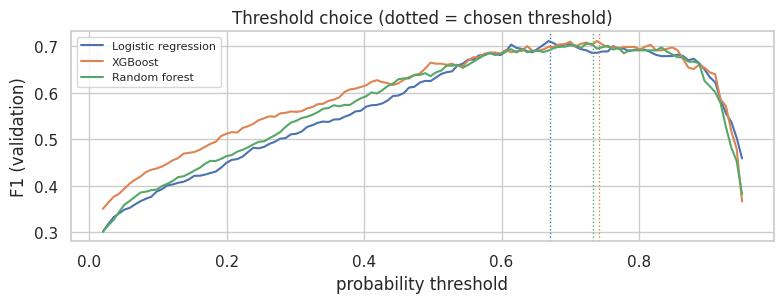

In [79]:
# overfitting check: train vs validation gap (large gap = memorising training seasons)
gap_tbl = res_trval.pivot(index="model", columns="split", values="pr_auc").loc[list(REGISTRY)]
gap_tbl["gap"] = gap_tbl["train"] - gap_tbl["val"]
display(gap_tbl.round(4))
ax = gap_tbl[["train", "val"]].plot(kind="bar", figsize=(8, 3), rot=0, title="PR-AUC: train vs validation (final models)")
ax.axhline(base_val.loc["grid-only LR", "pr_auc"], color="k", ls="--", lw=0.8, label="grid-only LR (val)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

# F1 against threshold on validation: where each threshold was picked
fig, ax = plt.subplots(figsize=(8, 3.2)); ts = np.linspace(0.02, 0.95, 120)
for name, predict in REGISTRY.items():
    p = predict(val); l, = ax.plot(ts, [f1_score(val[TARGET], (p >= t).astype(int), zero_division=0) for t in ts], label=name)
    ax.axvline(THRESHOLDS[name], color=l.get_color(), ls=":", lw=1)
ax.set(xlabel="probability threshold", ylabel="F1 (validation)", title="Threshold choice (dotted = chosen threshold)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Why it is done this way**
- `REGISTRY` holds one predict function per model, so every table and plot below loops over the same dictionary: no model gets special treatment, and adding one is one line. `lambda d, m=m:` binds each model when the entry is created (a plain `lambda d: proba(m, d)` would make every entry use the last model).
- Thresholds use the same rule for every model: F1-optimal on validation. The F1 vs threshold plot shows how flat the curve is around the chosen point (a flat top means the exact threshold matters little).
- The train vs validation table is the overfitting check. Compare the gaps **between** models (the forest and XGBoost fit train more closely than logistic regression), not their sign; the 4a.6 note explains why train scores are lower.

## 4a.8 Unseen test results
The test seasons (new ground-effect regulations) are used here for the first and only time. Models, settings and thresholds are frozen; this cell only scores them.

In [80]:
SPLITS["test"] = test
res_all = score_table(SPLITS)
test_base = metrics_at(test, fit_predict_grid_baseline(train, test)[0], thr_base)

order_models = list(REGISTRY)
full = res_all.set_index(["model", "split"])
table = pd.concat({sp: full.xs(sp, level="split")[["roc_auc", "pr_auc", "f1", "precision", "recall", "top3_precision"]].loc[order_models] for sp in ["train", "val", "test"]}, axis=1)
print("MODEL COMPARISON (threshold per model fixed on validation)")
display(table.round(4))
print("Reference: grid-only LR on test:", {k: round(v, 4) for k, v in test_base.items()}, "| no-skill PR-AUC (test prevalence):", round(test[TARGET].mean(), 4))

MODEL COMPARISON (threshold per model fixed on validation)


train                                                      val                                                     test                  \
                    roc_auc  pr_auc      f1 precision  recall top3_precision roc_auc  pr_auc      f1 precision  recall top3_precision roc_auc  pr_auc      f1   
model                                                                                                                                                           
Logistic regression  0.9025  0.5734  0.5842    0.4867  0.7306         0.5588  0.9329  0.7369  0.7109    0.6547  0.7778         0.6838  0.9361  0.7218  0.6654   
XGBoost              0.9299  0.6392  0.6195    0.5519  0.7061         0.5935  0.9282  0.6960  0.7113    0.6967  0.7265         0.6923  0.9354  0.7060  0.6711   
Random forest        0.9213  0.6295  0.6076    0.5547  0.6716         0.5846  0.9285  0.7214  0.7078    0.6825  0.7350         0.6838  0.9394  0.7182  0.6667   

                                                      
                    precision  recall top3_precision  
model                                                 
Logistic regression    0.5415  0.8627         0.6618  
XGBoost                0.6138  0.7402         0.6422  
Random forest          0.6098  0.7353         0.6569

Reference: grid-only LR on test: {'roc_auc': 0.9134, 'pr_auc': 0.6474, 'f1': 0.6486, 'precision': 0.6502, 'recall': 0.6471, 'top3_precision': 0.652} | no-skill PR-AUC (test prevalence): 0.151


**Why it is done this way**
- This is the first time any model sees the test rows. Models, settings and thresholds were all fixed in earlier cells and are not changed afterwards, so the test score is an honest estimate for unseen seasons.
- The test era (2022-24, new ground-effect cars) differs from training, so this also checks robustness to a regulation change.
- The grid-only baseline is scored on test with its own validation threshold, under the same rules as the models.

pr_auc          ci_low         ci_high        
split                  test     val    test     val    test     val
model                                                              
Logistic regression  0.7218  0.7369  0.6719  0.6349  0.7786  0.8402
XGBoost              0.7060  0.6960  0.6550  0.5879  0.7668  0.8129
Random forest        0.7182  0.7214  0.6608  0.6014  0.7757  0.8346

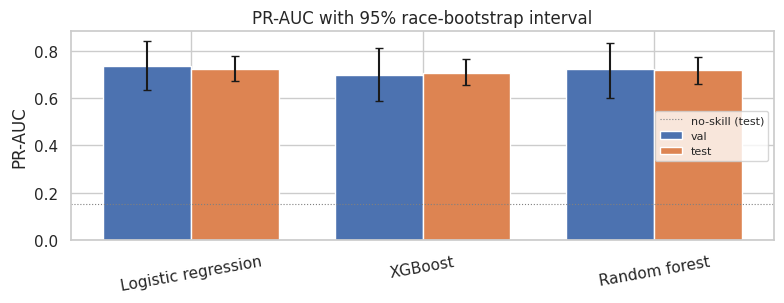

In [81]:
# PR-AUC with 95% race-bootstrap intervals, validation and test
ci_rows = []
for name, predict in REGISTRY.items():
    for sp in ["val", "test"]:
        d = SPLITS[sp]; p = predict(d); lo, hi = pr_auc_ci(d, p)
        ci_rows.append(dict(model=name, split=sp, pr_auc=average_precision_score(d[TARGET], p), ci_low=lo, ci_high=hi))
ci = pd.DataFrame(ci_rows); display(ci.pivot(index="model", columns="split", values=["pr_auc", "ci_low", "ci_high"]).round(4).loc[order_models])

fig, ax = plt.subplots(figsize=(8, 3.2)); w = 0.38
for j, sp in enumerate(["val", "test"]):
    c = ci[ci["split"] == sp].set_index("model").loc[order_models]
    ax.bar(np.arange(len(c)) + (j - 0.5) * w, c["pr_auc"], w, yerr=[c["pr_auc"] - c["ci_low"], c["ci_high"] - c["pr_auc"]], capsize=3, label=sp)
ax.set_xticks(range(len(order_models))); ax.set_xticklabels(order_models, rotation=10); ax.axhline(test[TARGET].mean(), color="grey", ls=":", lw=0.8, label="no-skill (test)")
ax.set_ylabel("PR-AUC"); ax.set_title("PR-AUC with 95% race-bootstrap interval"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

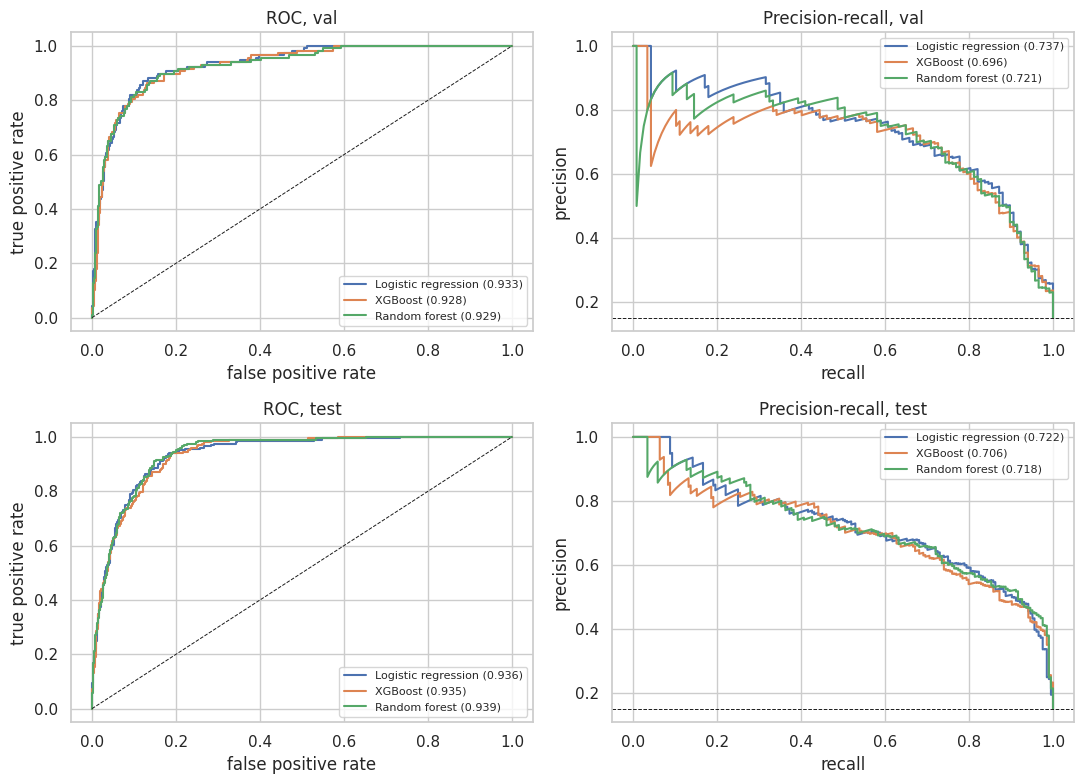

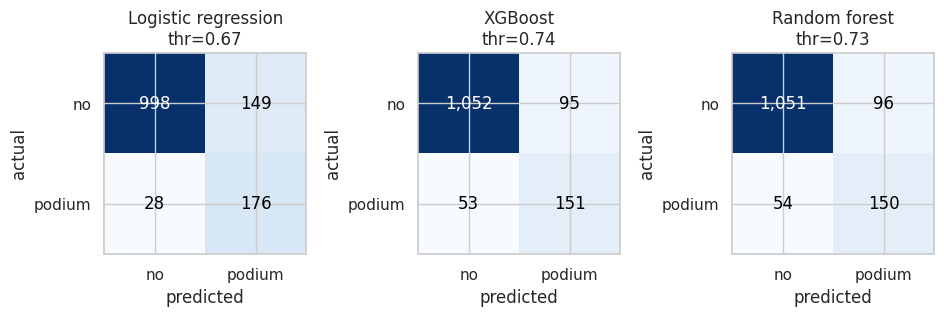

In [82]:
# ROC and precision-recall curves, validation (top) and test (bottom)
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for r, sp in enumerate(["val", "test"]):
    d = SPLITS[sp]
    for name, predict in REGISTRY.items():
        p = predict(d); fpr, tpr, _ = roc_curve(d[TARGET], p); pr, rc, _ = precision_recall_curve(d[TARGET], p)
        axes[r, 0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(d[TARGET], p):.3f})")
        axes[r, 1].plot(rc, pr, label=f"{name} ({average_precision_score(d[TARGET], p):.3f})")
    axes[r, 0].plot([0, 1], [0, 1], "k--", lw=0.7); axes[r, 1].axhline(d[TARGET].mean(), color="k", ls="--", lw=0.7)
    axes[r, 0].set(title=f"ROC, {sp}", xlabel="false positive rate", ylabel="true positive rate")
    axes[r, 1].set(title=f"Precision-recall, {sp}", xlabel="recall", ylabel="precision")
    for a in axes[r]: a.legend(fontsize=8)
plt.tight_layout(); plt.show()

# confusion matrices on test at each model's validation-chosen threshold
fig, axes = plt.subplots(1, len(REGISTRY), figsize=(3.2 * len(REGISTRY), 3.2))
for ax, (name, predict) in zip(np.atleast_1d(axes), REGISTRY.items()):
    cm = confusion_matrix(test[TARGET], (predict(test) >= THRESHOLDS[name]).astype(int))
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm): ax.text(j, i, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["no", "podium"], yticklabels=["no", "podium"], title=f"{name}\nthr={THRESHOLDS[name]:.2f}", xlabel="predicted", ylabel="actual")
plt.tight_layout(); plt.show()

year,2020,2021,2022,2023,2024
model,,,,,
Logistic regression,0.732,0.740,0.702,0.782,0.649
XGBoost,0.637,0.739,0.687,0.748,0.687
Random forest,0.699,0.757,0.688,0.763,0.684


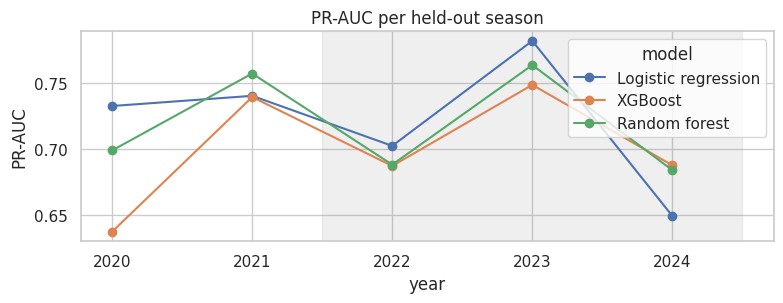

In [83]:
# stability: PR-AUC per held-out season (era sensitivity), validation + test seasons
per_season = []
for sp in ["val", "test"]:
    d = SPLITS[sp]
    for name, predict in REGISTRY.items():
        p = pd.Series(predict(d), index=d.index)
        for y, gy in d.groupby("year"):
            per_season.append(dict(model=name, year=int(y), split=sp, pr_auc=average_precision_score(gy[TARGET], p.loc[gy.index]), top3_precision=gy.assign(_p=p.loc[gy.index]).sort_values(["raceId", "_p"], ascending=[True, False]).groupby("raceId").head(3)[TARGET].mean()))
ps = pd.DataFrame(per_season)
display(ps.pivot(index="model", columns="year", values="pr_auc").loc[order_models].round(3))
ax = ps.pivot(index="year", columns="model", values="pr_auc")[order_models].plot(marker="o", figsize=(8, 3.2), title="PR-AUC per held-out season")
ax.axvspan(min(TEST_YEARS) - 0.5, max(TEST_YEARS) + 0.5, color="grey", alpha=0.12); ax.set_ylabel("PR-AUC"); ax.set_xticks(sorted(ps["year"].unique())); plt.tight_layout(); plt.show()

**Why it is done this way**
- **Intervals:** all three test PR-AUCs (0.706-0.722) lie inside each other's 95% interval, so the data cannot separate the three models. The lower ends of all three intervals are above the grid-only score (0.647). Task 5 adds a paired bootstrap for a sharper comparison.
- **ROC and PR curves together:** ROC-AUC is about 0.93 for every model, while the PR curves separate them more. This is why PR-AUC is the primary metric.
- **Confusion matrices** use each model's validation threshold, so they show the real decision trade-off. For example, logistic regression at 0.671 has high recall (0.863) but lower precision (0.542) on test.
- **Per-season PR-AUC** shows whether a validation-to-test change comes from one odd season or is a general drop.

In [84]:
# Auto-written conclusions: every sentence below is computed from the tables above
v = table["val"]; t = table["test"]
best_v, best_t = v["pr_auc"].idxmax(), t["pr_auc"].idxmax()
print(f"Primary metric (PR-AUC): best on validation = {best_v} ({v['pr_auc'].max():.3f}); best on test = {best_t} ({t['pr_auc'].max():.3f}).")
print(f"Grid-only baseline: validation {base_val.loc['grid-only LR','pr_auc']:.3f}, test {test_base['pr_auc']:.3f}; no-skill test {test[TARGET].mean():.3f}.")
for name in order_models:
    lo, hi = ci[(ci.model == name) & (ci.split == "test")][["ci_low", "ci_high"]].iloc[0]
    gain = t.loc[name, "pr_auc"] - test_base["pr_auc"]
    print(f"- {name}: test PR-AUC {t.loc[name,'pr_auc']:.3f} [{lo:.3f}, {hi:.3f}] ({gain:+.3f} vs grid-only), ROC-AUC {t.loc[name,'roc_auc']:.3f}, F1 {t.loc[name,'f1']:.3f}; "
          f"train-val PR-AUC gap {gap_tbl.loc[name,'gap']:+.3f}; val->test PR-AUC change {t.loc[name,'pr_auc'] - v.loc[name,'pr_auc']:+.3f}.")
tops = ci[ci.split == "test"].set_index("model").loc[order_models]
best_row = tops.loc[best_t]
not_sep = [m for m in order_models if m != best_t and tops.loc[m, "pr_auc"] >= best_row["ci_low"]]
clear = [m for m in order_models if m != best_t and m not in not_sep]
print(f"Models whose test PR-AUC lies inside {best_t}'s 95% interval (not clearly different): {not_sep or 'none'}; clearly below: {clear or 'none'}.")
print("All models vs grid-only baseline, test PR-AUC point estimate above baseline:", {m: bool(tops.loc[m, 'pr_auc'] > test_base['pr_auc']) for m in order_models})

Primary metric (PR-AUC): best on validation = Logistic regression (0.737); best on test = Logistic regression (0.722).
Grid-only baseline: validation 0.648, test 0.647; no-skill test 0.151.
- Logistic regression: test PR-AUC 0.722 [0.672, 0.779] (+0.074 vs grid-only), ROC-AUC 0.936, F1 0.665; train-val PR-AUC gap -0.164; val->test PR-AUC change -0.015.
- XGBoost: test PR-AUC 0.706 [0.655, 0.767] (+0.059 vs grid-only), ROC-AUC 0.935, F1 0.671; train-val PR-AUC gap -0.057; val->test PR-AUC change +0.010.
- Random forest: test PR-AUC 0.718 [0.661, 0.776] (+0.071 vs grid-only), ROC-AUC 0.939, F1 0.667; train-val PR-AUC gap -0.092; val->test PR-AUC change -0.003.
Models whose test PR-AUC lies inside Logistic regression's 95% interval (not clearly different): ['XGBoost', 'Random forest']; clearly below: none.
All models vs grid-only baseline, test PR-AUC point estimate above baseline: {'Logistic regression': True, 'XGBoost': True, 'Random forest': True}


### Reading the results (what to say in the report)
- **Metric choice.** PR-AUC is primary because podiums are rare and ranking matters; ROC-AUC is secondary; F1 depends on a threshold that was picked on validation and is reported for completeness.
- **Against the baseline.** A full model is only worth its complexity if its PR-AUC is clearly above the grid-only logistic regression (compare the intervals above, not just the point values). If a model is within the interval of the baseline, say so: grid position already carries most of the signal.
- **Linear vs trees.** If logistic regression is close to the tree models, the signal is mostly monotone (better grid, better car, better form → more podiums) and interactions add little. If the tree models are clearly ahead, interactions or non-linear effects matter.
- **Boosting vs bagging.** If random forest and XGBoost agree, the result does not depend on how the trees are combined.
- **Era shift.** Test seasons follow new regulations, so a drop from validation to test is expected. The per-season plot shows whether it is a single odd season or a level shift.

**Limitations (report).**
1. Validation (2 seasons, ~40 races) and test (3 seasons) are small; interval widths show how noisy the scores are.
2. The test era (2022–24) has different cars than most of the training years; form and standings features learned in earlier eras may transfer imperfectly.
3. Qualifying data is missing for early eras; models rely on missing-value handling (flags / native NaN) for those rows.
4. Team renames reset constructor form; retirements (reliability) are not modelled, so a podium-level car that breaks down is a miss no pre-race feature can predict.
5. Exactly three drivers podium per race, but the models score drivers independently; top-3 precision per race is reported to show the effect.
6. F1 at one global threshold treats every race alike; a per-race "pick the top 3" rule is a different decision rule.
7. Feature importance in later sections describes what the model uses, not what causes podiums.

## 4a.9 Save and hand-off
Fitted models (trained on train only), thresholds, settings and the result tables are saved for the ablation, XAI and inference sections. The models are also saved in the **shared format** read by the neural-network notebook (`results/<name>.json`, `<name>_preds.parquet`, `<name>_model.joblib`), so the final comparison of all four models and the final-model choice happen there, on validation. The pipelines contain only scikit-learn / XGBoost objects, so `joblib.load` works in any notebook with the same library versions. Inside one merged notebook, the neural network can also add itself with
```python
REGISTRY["Shallow NN"] = lambda d: nn_predict_proba(d[FEATURES])   # returns P(podium) per row
THRESHOLDS["Shallow NN"] = best_f1_threshold(val[TARGET], REGISTRY["Shallow NN"](val))
res_all = score_table(SPLITS)                                       # same metrics, same splits
```

In [85]:
MODEL_DIR = OUT + "models/"; os.makedirs(MODEL_DIR, exist_ok=True)
for name, m in FINAL.items():
    joblib.dump(m, MODEL_DIR + name.lower().replace(" ", "_") + ".joblib")
json.dump(dict(thresholds=THRESHOLDS, params={k: {a: (b if isinstance(b, (int, float, str)) else str(b)) for a, b in v.items()} for k, v in FINAL_PARAMS.items()},
               final_attempt=FINAL_TAG, features=FEATURES, primary_metric="pr_auc", secondary_metric="roc_auc"),
          open(MODEL_DIR + "model_config.json", "w"), indent=2)
table.round(5).to_csv(MODEL_DIR + "model_comparison.csv")
pd.concat({k: v.drop(columns=[c for c in v.columns if c in ("cv_std",)]) for k, v in TRIALS.items()}).to_csv(MODEL_DIR + "tuning_trials.csv")

assert test[TARGET].notna().all() and set(res_all["split"]) == {"train", "val", "test"}
print("Saved to", MODEL_DIR, "->", sorted(os.listdir(MODEL_DIR)))
print("Handed on: FINAL (fitted pipelines), REGISTRY, THRESHOLDS, FINAL_PARAMS, table, TRIALS, metrics_at, best_f1_threshold, score_table")

Saved to /kaggle/working/clean/models/ -> ['logistic_regression.joblib', 'model_comparison.csv', 'model_config.json', 'random_forest.joblib', 'tuning_trials.csv', 'xgboost.joblib']
Handed on: FINAL (fitted pipelines), REGISTRY, THRESHOLDS, FINAL_PARAMS, table, TRIALS, metrics_at, best_f1_threshold, score_table


In [86]:
# shared format for the model comparison (same files the neural-network notebook writes)
RESULTS = os.path.join(os.path.dirname(os.path.abspath(OUT.rstrip("/"))), "results")
os.makedirs(RESULTS, exist_ok=True)
SHORT = {"Logistic regression": "logreg", "Random forest": "rf", "XGBoost": "xgb"}
for name, m in FINAL.items():
    key = SHORT[name]
    preds = pd.concat([d[["resultId", "raceId", "split", TARGET]].assign(p=proba(m, d)) for d in (val, test)])
    preds.to_parquet(os.path.join(RESULTS, f"{key}_preds.parquet"), index=False)
    joblib.dump(m, os.path.join(RESULTS, f"{key}_model.joblib"))
    val_m = metrics_at(val, proba(m, val), THRESHOLDS[name])
    json.dump(dict(model=name, params={a: (b if isinstance(b, (int, float, str)) else str(b)) for a, b in FINAL_PARAMS[name].items()},
                   threshold=float(THRESHOLDS[name]), val={**val_m, "threshold": float(THRESHOLDS[name])}),
              open(os.path.join(RESULTS, f"{key}.json"), "w"), indent=2)
print("Shared-format files in", RESULTS, "->", sorted(f for f in os.listdir(RESULTS) if f.split("_")[0].split(".")[0] in SHORT.values()))

Shared-format files in /kaggle/working/results -> ['logreg.json', 'logreg_model.joblib', 'logreg_preds.parquet', 'rf.json', 'rf_model.joblib', 'rf_preds.parquet', 'xgb.json', 'xgb_model.joblib', 'xgb_preds.parquet']


**Why it is done this way**
- Two copies: `clean/models/` keeps this task's full record (settings, trial tables, comparison); `results/` uses the shared format, so 4b, 5 and 6 load every model the same way, whoever trained it.
- `<name>_preds.parquet` stores validation and test probabilities keyed by `resultId`, so the comparison in 4b uses exactly these predictions without refitting. Refitting the forest or XGBoost on another machine or library version can change the numbers slightly.
- The json stores the validation threshold, so every later task uses the threshold chosen here.

# Task 4b: Shallow Neural Network, Model Comparison and Inference
Uses the modeling table, features and time split from the feature engineering notebook.

| Part | Content |
|---|---|
| 1 | Load the modeling table and the train / validation / test split |
| 2 | Shared helpers: preprocessor, threshold, metrics |
| 3 | Shallow neural network: training loop with class weighting and early stopping |
| 4 | Hyperparameter search on validation, seed stability, learning curves |
| 5 | Save the NN results in the shared format |
| 6 | Comparison of all models on validation, final model choice, one-time test evaluation |
| 7 | Inference function: full record and record with missing values |

## 4b.1 Setup

In [87]:
import os, sys, glob, json, copy, time, warnings, subprocess, importlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, precision_recall_curve, roc_curve)
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

try:
    import pyarrow
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--user", "--quiet", "pyarrow"])
    importlib.invalidate_caches()
    import pyarrow

def find_clean_dir():
    if os.path.exists("/kaggle/working/clean/modeling_table.parquet"):
        return "/kaggle/working/clean"
    here = os.path.abspath(os.getcwd())
    for _ in range(4):
        hits = sorted(glob.glob(os.path.join(here, "**", "clean", "modeling_table.parquet"), recursive=True))
        if hits:
            return os.path.dirname(hits[0])
        here = os.path.dirname(here)
    raise FileNotFoundError("clean/modeling_table.parquet not found: run the feature engineering notebook first.")

CLEAN = find_clean_dir()
RESULTS = os.path.join(os.path.dirname(os.path.abspath(CLEAN)), "results")
os.makedirs(RESULTS, exist_ok=True)

cfg = json.load(open(os.path.join(CLEAN, "feature_config.json")))
mdl = pd.read_parquet(os.path.join(CLEAN, "modeling_table.parquet"))
FEATURES, TARGET = cfg["features"], cfg["target"]
BINARY, CONTINUOUS = cfg["binary"], cfg["continuous"]
SEED = cfg.get("seed", 42)

train = mdl[mdl["split"] == "train"].reset_index(drop=True)
val = mdl[mdl["split"] == "val"].reset_index(drop=True)
test = mdl[mdl["split"] == "test"].reset_index(drop=True)
assert train["race_order"].max() < val["race_order"].min() and val["race_order"].max() < test["race_order"].min()

print(f"data: {CLEAN} | results folder: {RESULTS}")
print(f"{len(FEATURES)} features | train {len(train):,} ({train['year'].min()}-{train['year'].max()}) | "
      f"val {len(val):,} ({val['year'].min()}-{val['year'].max()}) | test {len(test):,} ({test['year'].min()}-{test['year'].max()})")
print(f"podium rate: train {train[TARGET].mean():.3f} | val {val[TARGET].mean():.3f} | test {test[TARGET].mean():.3f}")

data: /kaggle/working/clean | results folder: /kaggle/working/results
29 features | train 22,441 (1950-2019) | val 774 (2020-2021) | test 1,351 (2022-2024)
podium rate: train 0.135 | val 0.151 | test 0.151


**Why it is done this way**
- `find_clean_dir` checks the Kaggle working folder and then searches parent folders, so the notebook runs on Kaggle and locally without editing paths.
- The split and seed come from `feature_config.json`, the same as in 4a; the assert re-checks that the three splits are in time order.
- pyarrow (needed to read parquet) is installed only if it is missing.

## 4b.2 Shared helpers
Same preprocessing as the feature engineering notebook (`make_preprocessor("linear")`): median imputation with missing indicators, then scaling; binary flags use the most frequent value. Fitted on training rows only.

The threshold is chosen on validation (maximum F1) and then reused unchanged on test.

In [88]:
def make_preprocessor():
    cont = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
                     ("sc", StandardScaler())])
    return ColumnTransformer([("cont", cont, CONTINUOUS),
                              ("bin", SimpleImputer(strategy="most_frequent", keep_empty_features=True), BINARY)])

def pick_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    return float(thr[np.argmax(f1[:-1])])

def all_metrics(d, p, thr):
    y, p = d[TARGET].to_numpy(), np.asarray(p, float)
    yhat = (p >= thr).astype(int)
    top3 = d.assign(_p=p).sort_values(["raceId", "_p"], ascending=[True, False]).groupby("raceId").head(3)
    return dict(roc_auc=float(roc_auc_score(y, p)), pr_auc=float(average_precision_score(y, p)), f1=float(f1_score(y, yhat)),
                precision=float(precision_score(y, yhat, zero_division=0)), recall=float(recall_score(y, yhat)),
                top3_precision=float(top3[TARGET].mean()), threshold=thr)

pre = make_preprocessor().fit(train[FEATURES])
X_tr, X_va, X_te = (pre.transform(d[FEATURES]) for d in (train, val, test))
y_tr, y_va = train[TARGET].to_numpy(), val[TARGET].to_numpy()
print(f"preprocessed: {len(FEATURES)} features -> {X_tr.shape[1]} inputs (incl. missing indicators) | NaN left: {int(np.isnan(X_tr).sum())}")

preprocessed: 29 features -> 43 inputs (incl. missing indicators) | NaN left: 0


**Why it is done this way**
- The network uses the `linear` preprocessing. Gradient steps depend on the size of the inputs, so they must be on similar scales, and the network cannot take NaN.
- The preprocessor is fitted once on train, and the transformed arrays `X_tr`, `X_va`, `X_te` are reused, because the training loop calls the network every epoch. The printed `NaN left: 0` confirms imputation worked.
- `pick_threshold` and `all_metrics` follow the same rules as 4a (`best_f1_threshold`, `metrics_at`), so all four models are scored identically.

## 4b.3 Shallow neural network
- 1 or 2 hidden layers with ReLU, sigmoid output, cross-entropy loss, Adam optimiser.
- **Class imbalance:** podium rows are about 14 %. scikit-learn's MLP has no `class_weight`, so every training epoch uses all non-podium rows plus the podium rows repeated `w ≈ (non-podium / podium)` times. This gives the same loss weighting as `class_weight={0: 1, 1: w}`. Validation and test are never resampled.
- **Regularisation:** L2 penalty (`alpha`) and early stopping.
- **Early stopping:** after each epoch the model is scored on the validation seasons (PR-AUC). Training stops after `patience` epochs without improvement and the best epoch is restored.

In [89]:
POS_WEIGHT = (y_tr == 0).sum() / (y_tr == 1).sum()
print(f"podium weight (non-podium / podium): {POS_WEIGHT:.2f}")

def weighted_epoch(X, y, rng):
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    reps = int(np.floor(POS_WEIGHT)); extra = rng.random(len(pos)) < (POS_WEIGHT - reps)
    idx = np.concatenate([neg, np.repeat(pos, reps), pos[extra]])
    rng.shuffle(idx)
    return X[idx], y[idx]

def train_nn(hidden=(64,), alpha=1e-3, lr=1e-3, batch=256, max_epochs=200, patience=15, seed=SEED):
    rng = np.random.default_rng(seed)
    net = MLPClassifier(hidden_layer_sizes=hidden, activation="relu", solver="adam", alpha=alpha,
                        learning_rate_init=lr, batch_size=batch, random_state=seed)
    hist, best, best_score, wait = [], None, -np.inf, 0
    for epoch in range(1, max_epochs + 1):
        Xe, ye = weighted_epoch(X_tr, y_tr, rng)
        net.partial_fit(Xe, ye, classes=[0, 1])
        p_va = net.predict_proba(X_va)[:, 1]
        score = average_precision_score(y_va, p_va)
        hist.append(dict(epoch=epoch, train_loss=net.loss_, val_pr_auc=score,
                         val_roc_auc=roc_auc_score(y_va, p_va)))
        if score > best_score + 1e-4:
            best, best_score, wait = copy.deepcopy(net), score, 0
        else:
            wait += 1
            if wait >= patience:
                break
    return best, pd.DataFrame(hist)

podium weight (non-podium / podium): 6.43


**Why it is done this way**
- **Repeating podium rows:** `MLPClassifier` has no `class_weight`. Each podium row is repeated 6 times, plus a 7th time for a random 43% of them, so on average it counts 6.43 times. That gives the same expected loss as a class weight of 6.43, the same weighting as the other three models.
- A new random resample is drawn every epoch, so the random 7th copies average out and the row order changes.
- **`partial_fit`** trains one epoch at a time, so validation can be scored after each epoch. scikit-learn's built-in `early_stopping=True` would instead hold out a random 10% of training rows (ignoring time order) and watch a loss-based score, not PR-AUC.
- **Early stopping on validation PR-AUC:** with `patience=15`, training stops after 15 epochs without an improvement of more than 1e-4, and `copy.deepcopy` keeps the best epoch. Small networks on noisy data peak early, so this is the main guard against overfitting, together with the L2 penalty `alpha`.
- Adam, ReLU, batch 256 and learning rate 1e-3 are standard settings for small tabular networks; only the size and `alpha` are searched.

## 4b.4 Hyperparameter search (validation only)
Six settings: network size (one or two layers) and L2 strength. Each is trained with the early-stopping loop above and ranked by validation PR-AUC. The test seasons are not used.

In [90]:
GRID = [dict(hidden=(32,), alpha=1e-3), dict(hidden=(64,), alpha=1e-3), dict(hidden=(64,), alpha=1e-2),
        dict(hidden=(64, 32), alpha=1e-3), dict(hidden=(64, 32), alpha=1e-2), dict(hidden=(128, 64), alpha=1e-2)]
rows, runs = [], {}
for g in GRID:
    t0 = time.time()
    net, hist = train_nn(**g)
    p = net.predict_proba(X_va)[:, 1]
    key = f"{g['hidden']} alpha={g['alpha']}"
    runs[key] = (net, hist, g)
    rows.append(dict(setting=key, best_epoch=int(hist["val_pr_auc"].idxmax()) + 1, epochs_run=len(hist),
                     val_pr_auc=average_precision_score(y_va, p), val_roc_auc=roc_auc_score(y_va, p),
                     seconds=round(time.time() - t0, 1)))
search = pd.DataFrame(rows).sort_values("val_pr_auc", ascending=False).reset_index(drop=True)
display(search.round(4))
BEST_KEY = search.loc[0, "setting"]; BEST_CFG = runs[BEST_KEY][2]
print("best setting:", BEST_KEY)

,setting,best_epoch,epochs_run,val_pr_auc,val_roc_auc,seconds
0,"(64, 32) alpha=0.001",8,23,0.7494,0.9272,4.7
1,"(64,) alpha=0.01",8,23,0.7443,0.9285,3.6
2,"(64,) alpha=0.001",4,19,0.7397,0.9315,2.9
3,"(64, 32) alpha=0.01",8,23,0.7379,0.9270,4.6
4,"(32,) alpha=0.001",17,32,0.7317,0.9308,4.2
5,"(128, 64) alpha=0.01",1,16,0.7285,0.9325,5.7


best setting: (64, 32) alpha=0.001


**Why it is done this way**
- The six settings vary the two things that control capacity: size (one or two layers, 32-128 units) and L2 strength. All networks stay shallow, as the task asks.
- Each setting is ranked by validation PR-AUC at its best epoch; test is not used.
- In the Kaggle run the best was (64, 32) with alpha 0.001 (0.749). The largest network (128, 64) peaked at epoch 1 and came last, which suggests extra capacity only overfits here.

### 4b.4.1 Seed stability
A neural network depends on its random start. The best setting is retrained with three seeds; the spread shows how much of a difference between models is just noise.

In [91]:
seed_rows, seed_models = [], {}
for s in [SEED, SEED + 1, SEED + 2]:
    net, hist = train_nn(**BEST_CFG, seed=s)
    p = net.predict_proba(X_va)[:, 1]
    seed_models[s] = (net, hist)
    seed_rows.append(dict(seed=s, val_pr_auc=average_precision_score(y_va, p), val_roc_auc=roc_auc_score(y_va, p),
                          best_epoch=int(hist["val_pr_auc"].idxmax()) + 1))
seeds = pd.DataFrame(seed_rows); display(seeds.round(4))
print(f"val PR-AUC {seeds['val_pr_auc'].mean():.4f} ± {seeds['val_pr_auc'].std():.4f} | "
      f"val ROC-AUC {seeds['val_roc_auc'].mean():.4f} ± {seeds['val_roc_auc'].std():.4f}")
nn_net, nn_hist = seed_models[SEED]          # the reported model: first seed (fixed in advance, not cherry-picked)

,seed,val_pr_auc,val_roc_auc,best_epoch
0,42,0.7494,0.9272,8
1,43,0.7342,0.9248,14
2,44,0.7342,0.9305,3


val PR-AUC 0.7393 ± 0.0088 | val ROC-AUC 0.9275 ± 0.0029


**Why it is done this way**
- The three seeds (42, 43, 44) are fixed in advance. Their spread (0.734-0.749, std 0.009) is as large as the gaps between models, so single-run differences of about 0.01 are not meaningful.
- The reported model is seed 42, fixed in advance and not chosen as the best seed, which avoids cherry-picking. Seed 42 did score highest, so its validation score is optimistic; that is why Part 6 uses the seed mean (0.739) for the model choice.

### 4b.4.2 Learning curves

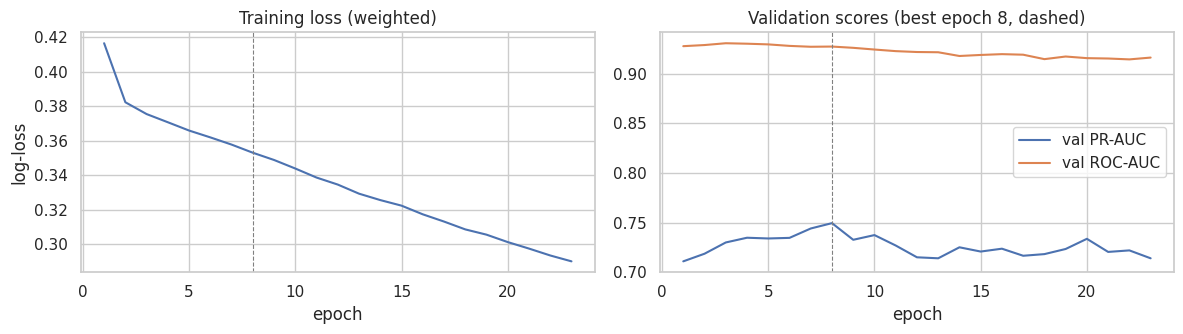

In [92]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(nn_hist["epoch"], nn_hist["train_loss"]); axes[0].set(title="Training loss (weighted)", xlabel="epoch", ylabel="log-loss")
axes[1].plot(nn_hist["epoch"], nn_hist["val_pr_auc"], label="val PR-AUC")
axes[1].plot(nn_hist["epoch"], nn_hist["val_roc_auc"], label="val ROC-AUC")
best_ep = int(nn_hist["val_pr_auc"].idxmax()) + 1
for ax in axes: ax.axvline(best_ep, color="grey", ls="--", lw=0.8)
axes[1].set(title=f"Validation scores (best epoch {best_ep}, dashed)", xlabel="epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

**Why it is done this way**
- The curves show why early stopping is needed. The dashed line is the epoch early stopping restored; the epochs after it are the patience window, where validation PR-AUC no longer improved even though training loss kept going down, a sign the network had started to memorise training seasons.

## 4b.5 Save the NN in the shared format
Every model (also the teammate's logistic regression, random forest and gradient boosting) saves three files in `results/`:
- `<name>.json`: model name, settings, validation threshold and validation metrics
- `<name>_preds.parquet`: `resultId, raceId, split, podium, p` for validation **and** test rows
- `<name>_model.joblib`: the fitted pipeline (preprocessor + model), with `predict_proba`

The comparison in Part 6 reads every model saved this way.

In [93]:
nn_model = Pipeline([("pre", pre), ("clf", nn_net)])          # already fitted: preprocessor on train, network above
p_va = nn_model.predict_proba(val[FEATURES])[:, 1]
nn_thr = pick_threshold(y_va, p_va)
nn_val = all_metrics(val, p_va, nn_thr)

def save_model(name, label, model, params, thr, val_metrics):
    preds = pd.concat([d[["resultId", "raceId", "split", TARGET]].assign(p=model.predict_proba(d[FEATURES])[:, 1])
                       for d in (val, test)])
    preds.to_parquet(os.path.join(RESULTS, f"{name}_preds.parquet"), index=False)
    joblib.dump(model, os.path.join(RESULTS, f"{name}_model.joblib"))
    json.dump(dict(model=label, params=params, threshold=thr, val=val_metrics),
              open(os.path.join(RESULTS, f"{name}.json"), "w"), indent=2, default=float)

save_model("nn", "Shallow NN", nn_model, dict(hidden=list(BEST_CFG["hidden"]), alpha=BEST_CFG["alpha"],
           lr=1e-3, epochs=best_ep, seed=SEED, seed_pr_auc_mean=float(seeds["val_pr_auc"].mean()),
           seed_pr_auc_std=float(seeds["val_pr_auc"].std())), nn_thr, nn_val)
print({k: round(v, 4) for k, v in nn_val.items()})

{'roc_auc': 0.9272, 'pr_auc': 0.7494, 'f1': 0.7179, 'precision': 0.7179, 'recall': 0.7179, 'top3_precision': 0.7009, 'threshold': 0.7932}


**Why it is done this way**
- The network is wrapped in the same kind of `Pipeline` (preprocessor + model) as the other models, so `predict_podium`, Task 5 and Task 6 can call `predict_proba` on raw features for any model.
- The json also stores `seed_pr_auc_mean` and `seed_pr_auc_std`, which the fair selection rule in Part 6 needs.
- Test probabilities are written to the parquet here, but no test metric is computed until Part 6.1, after the final model has been chosen.

## 4b.6 Comparison of all models
Two reference points are added:
- **No skill:** a model that ranks randomly; its PR-AUC equals the podium rate.
- **Grid rule:** predict a podium when the starting slot is 1-3; the score is `-grid`. Every real model should beat it.

The final model is chosen on **validation PR-AUC**. If two models are within 0.01, the simpler one is preferred.

**Fair comparison for the network.** The network's validation score was used three times (early stopping, choosing the setting, and it is the best of three seeds), so its single-run score is optimistic. The statistical models were tuned on folds inside train, so their validation score was not used for selection. For the choice, the network is therefore represented by its **average over the three seeds**, its honest validation estimate. The test seasons are scored only after the choice, once, with each model's validation threshold.

In [94]:
models = {}
for f in sorted(glob.glob(os.path.join(RESULTS, "*.json"))):
    name = os.path.basename(f)[:-5]
    if os.path.exists(os.path.join(RESULTS, f"{name}_preds.parquet")):
        models[name] = dict(meta=json.load(open(f)), preds=pd.read_parquet(os.path.join(RESULTS, f"{name}_preds.parquet")))
print("models found:", {k: v["meta"]["model"] for k, v in models.items()})
if len(models) == 1:
    print("Only the NN is saved so far: run the teammate's notebook (LR / RF / boosting) first, then re-run this part.")

def preds_for(name, d):
    pr = models[name]["preds"].set_index("resultId")["p"]
    return pr.reindex(d["resultId"]).to_numpy()

grid_score = lambda d: -d["grid_clean"].to_numpy()
grid_thr = -3.0                                     # rule: grid 1-3 -> podium

rows = [dict(model="Grid rule (grid <= 3)", **all_metrics(val, grid_score(val), grid_thr))]
for name, m in models.items():
    rows.append(dict(model=m["meta"]["model"], **all_metrics(val, preds_for(name, val), m["meta"]["threshold"])))
cmp_val = pd.DataFrame(rows).set_index("model").sort_values("pr_auc", ascending=False)
print(f"no-skill PR-AUC on validation = podium rate = {val[TARGET].mean():.3f}")
display(cmp_val.round(4))

models found: {'logreg': 'Logistic regression', 'nn': 'Shallow NN', 'rf': 'Random forest', 'xgb': 'XGBoost'}
no-skill PR-AUC on validation = podium rate = 0.151


,roc_auc,pr_auc,f1,precision,recall,top3_precision,threshold
model,,,,,,,
Shallow NN,0.9272,0.7494,0.7179,0.7179,0.7179,0.7009,0.7932
Logistic regression,0.9329,0.7369,0.7109,0.6547,0.7778,0.6838,0.6710
Random forest,0.9285,0.7214,0.7078,0.6825,0.7350,0.6838,0.7329
XGBoost,0.9282,0.6960,0.7113,0.6967,0.7265,0.6923,0.7413
Grid rule (grid <= 3),0.9101,0.6478,0.6953,0.6983,0.6923,0.7009,-3.0000


**Why it is done this way**
- Models are loaded from `results/`, not refitted, so the comparison uses exactly the predictions saved by 4a and 4b. `preds_for` aligns them by `resultId`, which protects against different row orders.
- The grid rule (score `-grid`, threshold -3, meaning "grid 1-3 is a podium") ranks drivers exactly like the grid-only logistic regression of 4a, because a higher grid number always lowers the score. That is why both have validation PR-AUC 0.648, a consistency check between the two parts.
- Every model uses its own validation threshold, read from its json.

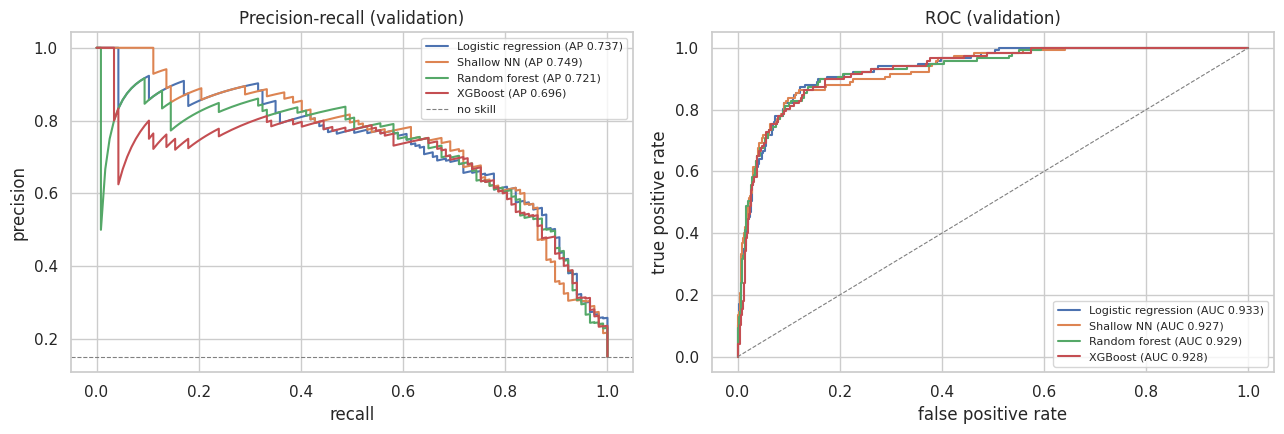

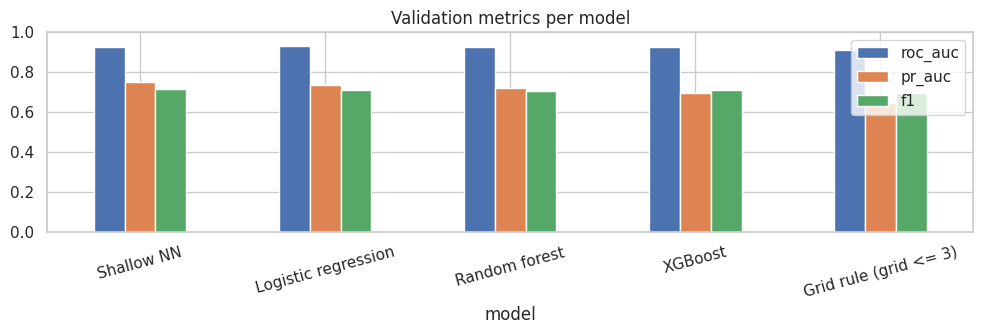

In [95]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, m in models.items():
    p = preds_for(name, val)
    pr, rc, _ = precision_recall_curve(y_va, p); fpr, tpr, _ = roc_curve(y_va, p)
    lab = m["meta"]["model"]
    axes[0].plot(rc, pr, label=f"{lab} (AP {average_precision_score(y_va, p):.3f})")
    axes[1].plot(fpr, tpr, label=f"{lab} (AUC {roc_auc_score(y_va, p):.3f})")
axes[0].axhline(val[TARGET].mean(), color="grey", ls="--", lw=0.8, label="no skill")
axes[1].plot([0, 1], [0, 1], color="grey", ls="--", lw=0.8)
axes[0].set(title="Precision-recall (validation)", xlabel="recall", ylabel="precision"); axes[0].legend(fontsize=8)
axes[1].set(title="ROC (validation)", xlabel="false positive rate", ylabel="true positive rate"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

cmp_val[["roc_auc", "pr_auc", "f1"]].plot(kind="bar", figsize=(10, 3.5), rot=15, title="Validation metrics per model")
plt.ylim(0, 1); plt.tight_layout(); plt.show()

### 4b.6.1 Final model choice and one-time test evaluation

In [96]:
COMPLEXITY = {"logreg": 0, "lr": 0, "rf": 1, "hgb": 1, "xgb": 1, "lgbm": 1, "nn": 2}   # lower = simpler
def selection_score(n, m):
    # network: seed-average validation PR-AUC (its single run was selected on validation); other models: their validation PR-AUC
    return m["meta"].get("params", {}).get("seed_pr_auc_mean",
                                           all_metrics(val, preds_for(n, val), m["meta"]["threshold"])["pr_auc"])
val_rank = pd.DataFrame([dict(name=n, label=m["meta"]["model"], pr_auc=selection_score(n, m)) for n, m in models.items()])
display(val_rank.sort_values("pr_auc", ascending=False).round(4))
top = val_rank["pr_auc"].max()
near = val_rank[val_rank["pr_auc"] >= top - 0.01].copy()
near["complexity"] = near["name"].map(lambda n: COMPLEXITY.get(n, 1))
FINAL = near.sort_values(["complexity", "pr_auc"], ascending=[True, False]).iloc[0]["name"]
print(f"final model: {models[FINAL]['meta']['model']} (best validation PR-AUC {top:.4f}; "
      f"models within 0.01: {near['label'].tolist()})")

# ---- the test seasons are scored here, once, with thresholds fixed on validation ----
rows = [dict(model="Grid rule (grid <= 3)", split="val", **all_metrics(val, grid_score(val), grid_thr)),
        dict(model="Grid rule (grid <= 3)", split="test", **all_metrics(test, grid_score(test), grid_thr))]
for name, m in models.items():
    for split, d in (("val", val), ("test", test)):
        rows.append(dict(model=m["meta"]["model"], split=split, **all_metrics(d, preds_for(name, d), m["meta"]["threshold"])))
final_table = pd.DataFrame(rows).pivot(index="model", columns="split",
                                       values=["roc_auc", "pr_auc", "f1", "precision", "recall", "top3_precision"])
display(final_table.round(3))
print(f"no-skill PR-AUC: val {val[TARGET].mean():.3f} | test {test[TARGET].mean():.3f}")

final_model = joblib.load(os.path.join(RESULTS, f"{FINAL}_model.joblib"))
final_threshold = float(models[FINAL]["meta"]["threshold"])
json.dump(dict(final_model=FINAL, label=models[FINAL]["meta"]["model"], threshold=final_threshold),
          open(os.path.join(RESULTS, "final_model.json"), "w"), indent=2)
print("saved results/final_model.json for the ablation and XAI sections")

,name,label,pr_auc
1,nn,Shallow NN,0.7393
0,logreg,Logistic regression,0.7369
2,rf,Random forest,0.7214
3,xgb,XGBoost,0.6960


final model: Logistic regression (best validation PR-AUC 0.7393; models within 0.01: ['Logistic regression', 'Shallow NN'])


roc_auc        pr_auc            f1        precision        recall        top3_precision       
split                    test    val   test    val   test    val      test    val   test    val           test    val
model                                                                                                                
Grid rule (grid <= 3)   0.913  0.910  0.647  0.648  0.649  0.695     0.650  0.698  0.647  0.692          0.652  0.701
Logistic regression     0.936  0.933  0.722  0.737  0.665  0.711     0.542  0.655  0.863  0.778          0.662  0.684
Random forest           0.939  0.929  0.718  0.721  0.667  0.708     0.610  0.683  0.735  0.735          0.657  0.684
Shallow NN              0.923  0.927  0.690  0.749  0.652  0.718     0.647  0.718  0.657  0.718          0.652  0.701
XGBoost                 0.935  0.928  0.706  0.696  0.671  0.711     0.614  0.697  0.740  0.726          0.642  0.692

no-skill PR-AUC: val 0.151 | test 0.151
saved results/final_model.json for the ablation and XAI sections


**Why it is done this way**
- The choice uses validation only. Test is scored in the same cell, but only after `FINAL` is set, and the result does not feed back into anything.
- **`selection_score`:** the network is represented by `seed_pr_auc_mean` (0.739), because its single score (0.749) was optimised on validation three times (stopping epoch, setting, and it is the best seed). Logistic regression, the forest and XGBoost use their plain validation PR-AUC, because their settings were chosen on train folds.
- **0.01 tolerance:** about the size of the network's seed spread and far inside the validation interval, so models within it count as tied. Among tied models the simplest wins (`COMPLEXITY`: logistic regression 0, trees 1, network 2), because it is easier to explain, more stable and cheaper.
- Result: network 0.739 and logistic regression 0.737 are tied, so logistic regression is chosen. The test seasons agree: the network drops to 0.690, while logistic regression keeps 0.722.
- `final_model.json` records the model and its threshold, so Tasks 5 and 6 explain the same model.

## 4b.7 Inference function
`predict_podium(...)` takes the pre-race facts of one driver in one race and returns the podium probability of the final model.

It reuses `build_modeling_table` from the feature engineering notebook (copied below unchanged): the new entry is added to the clean tables and the features are rebuilt, so form, standings and circuit history come from earlier races exactly as in training. The entry's outcome is unknown, so a placeholder is stored; the leakage test in feature engineering showed that a row's own outcome never changes its own features.

In [97]:
FORM_WINDOWS = [3, 5, 10]
FAMILIES = ["drv_podium_rate", "drv_finish_rel", "team_podium_rate", "team_finish_rel"]   # core form (finishing positions)
STATUS_FAMILIES = ["drv_dnf_rate", "team_dnf_rate"]                                        # status-derived: candidate only
ALL_FAMILIES = FAMILIES + STATUS_FAMILIES
ID_COLS = ["resultId", "raceId", "driverId", "constructorId", "circuitId", "year", "round", "race_order"]
TARGET = "podium"
BINARY_FEATURES = ["pole", "pit_lane_start", "front_row", "home_race"]
MAX_GAP_PCT = 20      # qualifying times slower than this (% off the session's fastest) are treated as not representative

def _roll_past(df, keys, col, w):
    # mean of the PREVIOUS w values within each group: shift(1) removes the current row.
    # Needs `df` sorted chronologically (it is: sorted by race_order).
    return df.groupby(keys)[col].transform(lambda s: s.shift(1).rolling(w, min_periods=1).mean())

def build_modeling_table(tbls, windows=FORM_WINDOWS):
    # ---- calendar: a strict chronological order of races (year, round) ----------------------
    races = tbls["races"][["raceId", "year", "round", "circuitId", "date"]].copy()
    races = races.sort_values(["year", "round"]).reset_index(drop=True)
    races["race_order"] = np.arange(len(races))
    for c in ["raceId", "year", "round", "circuitId"]:
        races[c] = races[c].astype("int64")
    races["n_rounds"] = races.groupby("year")["round"].transform("max")

    r = tbls["results"][["resultId", "raceId", "driverId", "constructorId", "grid",
                         "positionOrder", "statusId"]].copy()
    for c in ["resultId", "raceId", "driverId", "constructorId", "grid", "positionOrder", "statusId"]:
        r[c] = r[c].astype("int64")
    stt = tbls["status"][["statusId", "status"]].copy(); stt["statusId"] = stt["statusId"].astype("int64")
    r["status_name"] = r["statusId"].map(stt.set_index("statusId")["status"]).fillna("")
    circ = tbls["circuits"][["circuitId", "country"]].rename(columns={"country": "circuit_country"}).copy()
    circ["circuitId"] = circ["circuitId"].astype("int64")
    drv = tbls["drivers"][["driverId", "dob", "nationality"]].copy()
    drv["driverId"] = drv["driverId"].astype("int64")

    df = (r.merge(races, on="raceId", how="left", validate="m:1")
           .merge(circ, on="circuitId", how="left", validate="m:1")
           .merge(drv, on="driverId", how="left", validate="m:1"))
    df = df.sort_values(["race_order", "driverId"]).reset_index(drop=True)

    # ---- target and the outcome helpers (outcomes are only ever used through shift) ------------
    df[TARGET] = (df["positionOrder"] <= 3).astype(int)
    df["field_size"] = df.groupby("raceId")["driverId"].transform("size").astype(float)
    df["_podium"] = df[TARGET].astype(float)
    df["_finish_rel"] = df["positionOrder"] / df["field_size"]     # era-independent finishing position
    # retirement = the car stopped: status other than "Finished" / "+n Laps" / "Lapped" (reference document), DSQ excluded.
    # NOT positionText == "R": a driver who retired after 90% of the distance is classified and has a numeric position.
    _fin = df["status_name"].isin(["Finished", "Lapped"]) | df["status_name"].str.startswith("+")
    df["_dnf"] = (~_fin & (df["status_name"] != "Disqualified")).astype(float)

    # ---- GRID group (known when the grid is set) -----------------------------------------------
    max_grid = df.groupby("raceId")["grid"].transform("max")
    back = max_grid + 1
    df["pit_lane_start"] = (df["grid"] == 0).astype(float)
    df["grid_clean"] = np.where(df["grid"] > 0, df["grid"], np.where(max_grid > 0, back, np.nan)).astype(float)
    df["grid_rel"] = df["grid_clean"] / df["field_size"]
    df["front_row"] = (df["grid_clean"] <= 2).astype(float).where(df["grid_clean"].notna())
    df["pole"] = (df["grid_clean"] == 1).astype(float).where(df["grid_clean"].notna())
    gt = df.groupby(["raceId", "constructorId"])["grid_clean"]
    df["team_best_grid"] = gt.transform("min")
    df["grid_vs_team"] = df["grid_clean"] - gt.transform("mean")

    # ---- QUALIFYING group ----------------------------------------------------------------------
    q = tbls["qualifying"][["raceId", "driverId", "position", "q1", "q2", "q3"]].copy()
    q["raceId"] = q["raceId"].astype("int64"); q["driverId"] = q["driverId"].astype("int64")
    q["quali_pos"] = q["position"].astype(float)
    for c in ["q1", "q2", "q3"]:
        q[c] = q[c].astype(float)
        # a time more than MAX_GAP_PCT % slower than the session's fastest is not a representative lap (deleted, aborted or
        # mistimed lap, e.g. a 126.7 s Q2 "lap" at the 2023 Austrian GP): it is ignored, so the gap falls back to an earlier session
        q.loc[q[c] > q.groupby("raceId")[c].transform("min") * (1 + MAX_GAP_PCT / 100), c] = np.nan
        q[f"_gap_{c}"] = 100 * (q[c] / q.groupby("raceId")[c].transform("min") - 1)   # % slower than the session's fastest
    q["q1_gap_pct"] = q["_gap_q1"]
    # gap in the LAST session the driver reached (Q3 -> Q2 -> Q1): comparable across the single-lap (2003-05) and knockout (2006+) formats
    q["quali_gap_pct"] = q["_gap_q3"].fillna(q["_gap_q2"]).fillna(q["_gap_q1"])
    df = df.merge(q[["raceId", "driverId", "quali_pos", "q1_gap_pct", "quali_gap_pct"]],
                  on=["raceId", "driverId"], how="left", validate="1:1")
    df["quali_pos_rel"] = df["quali_pos"] / df["field_size"]
    df["grid_minus_quali"] = np.where((df["grid"] > 0) & df["quali_pos"].notna(), df["grid"] - df["quali_pos"], np.nan)

    # ---- FORM group: only previous races ---------------------------------------------------------
    drv_src = {"drv_podium_rate": "_podium", "drv_finish_rel": "_finish_rel", "drv_dnf_rate": "_dnf"}
    team_src = {"team_podium_rate": "_podium", "team_finish_rel": "_finish_rel", "team_dnf_rate": "_dnf"}
    for fam, col in drv_src.items():
        for w in windows:
            df[f"{fam}_w{w}"] = _roll_past(df, "driverId", col, w)
    team = (df.groupby(["constructorId", "raceId", "race_order"], as_index=False)[["_podium", "_finish_rel", "_dnf"]].mean()
              .sort_values(["constructorId", "race_order"]).reset_index(drop=True))
    tcols = []
    for fam, col in team_src.items():
        for w in windows:
            team[f"{fam}_w{w}"] = _roll_past(team, "constructorId", col, w); tcols.append(f"{fam}_w{w}")
    df = df.merge(team[["constructorId", "raceId"] + tcols], on=["constructorId", "raceId"], how="left", validate="m:1")
    g = df.groupby("driverId")
    df["drv_career_starts"] = g.cumcount().astype(float)
    prev_pod = g["_podium"].cumsum() - df["_podium"]
    df["drv_career_podium_rate"] = prev_pod / df["drv_career_starts"].replace(0, np.nan)

    # ---- STANDINGS group: championship table after the previous round of the same season ---------
    def prior_standing(kind, ent, prefix):
        st = tbls[f"{kind}_standings"][["raceId", ent, "position", "points", "wins"]].copy()
        st = st.merge(races[["raceId", "year", "round"]], on="raceId", how="inner")
        for c in ["raceId", ent]: st[c] = st[c].astype("int64")
        lead = st.groupby("raceId")["points"].transform("max").astype(float)
        st[f"{prefix}_pts_share_prev"] = np.where(lead > 0, st["points"].astype(float) / lead, 0.0)
        st[f"{prefix}_champ_pos_prev"] = st["position"].astype(float)
        st[f"{prefix}_wins_prev"] = st["wins"].astype(float)
        cols = [f"{prefix}_champ_pos_prev", f"{prefix}_pts_share_prev", f"{prefix}_wins_prev"]
        st = st.sort_values("round")
        left = df[["resultId", ent, "year", "round"]].sort_values("round")
        # allow_exact_matches=False => strictly EARLIER rounds: the standing after this race is never used
        m = pd.merge_asof(left, st[[ent, "year", "round"] + cols], on="round", by=[ent, "year"],
                          allow_exact_matches=False, direction="backward")
        has_table = m["year"].isin(set(st["year"]))
        for c in cols[1:]:                       # nothing scored yet this season => 0 (position stays NaN)
            m.loc[has_table & m[c].isna(), c] = 0.0
        return m[["resultId"] + cols]
    df = df.merge(prior_standing("driver", "driverId", "drv"), on="resultId", how="left", validate="1:1")
    df = df.merge(prior_standing("constructor", "constructorId", "con"), on="resultId", how="left", validate="1:1")

    # ---- CIRCUIT HISTORY group: previous races only ----------------------------------------------
    gdc = df.groupby(["driverId", "circuitId"])
    df["drv_circuit_prev_starts"] = gdc.cumcount().astype(float)
    df["drv_circuit_prev_podiums"] = gdc["_podium"].cumsum() - df["_podium"]
    df["_front"] = (df["grid_clean"] <= 2).astype(float)
    df["_front_pod"] = df["_front"] * df["_podium"]
    cr = (df.groupby(["circuitId", "raceId", "race_order"], as_index=False)[["_front", "_front_pod"]].sum()
            .sort_values(["circuitId", "race_order"]).reset_index(drop=True))
    for c in ["_front", "_front_pod"]:     # only the last 8 races at the circuit: early-era reliability was far lower (reference document)
        cr["past" + c] = cr.groupby("circuitId")[c].transform(lambda s: s.shift(1).rolling(8, min_periods=3).sum())
    cr["circuit_front_row_podium_rate"] = np.where(cr["past_front"] >= 6, cr["past_front_pod"] / cr["past_front"], np.nan)
    df = df.merge(cr[["circuitId", "raceId", "circuit_front_row_podium_rate"]],
                  on=["circuitId", "raceId"], how="left", validate="m:1")

    # ---- CONTEXT group ---------------------------------------------------------------------------
    df["season_progress"] = df["round"] / df["n_rounds"]
    df["age"] = (df["date"] - df["dob"]).dt.days / 365.25
    nm = tbls["nationality_country"][["nationality", "country"]].drop_duplicates().assign(home_race=1.0)
    df = df.merge(nm, left_on=["nationality", "circuit_country"], right_on=["nationality", "country"],
                  how="left", validate="m:1").drop(columns="country")
    df["home_race"] = df["home_race"].fillna(0.0)

    groups = {
        "grid": ["grid_clean", "grid_rel", "pole", "pit_lane_start", "front_row", "team_best_grid", "grid_vs_team"],
        "qualifying": ["quali_pos", "quali_pos_rel", "quali_gap_pct", "q1_gap_pct", "grid_minus_quali"],
        "driver_form": [f"{fam}_w{w}" for fam in ["drv_podium_rate", "drv_finish_rel"] for w in windows]
                       + ["drv_career_starts", "drv_career_podium_rate"],
        "constructor_form": [f"{fam}_w{w}" for fam in ["team_podium_rate", "team_finish_rel"] for w in windows],
        "reliability_status": [f"{fam}_w{w}" for fam in STATUS_FAMILIES for w in windows],
        "standings": ["drv_champ_pos_prev", "drv_pts_share_prev", "drv_wins_prev",
                      "con_champ_pos_prev", "con_pts_share_prev", "con_wins_prev"],
        "circuit_history": ["drv_circuit_prev_starts", "drv_circuit_prev_podiums", "circuit_front_row_podium_rate"],
        "context": ["field_size", "season_progress", "age", "home_race"],
    }
    feats = [f for fs in groups.values() for f in fs]
    out = df[ID_COLS + [TARGET] + feats].copy()
    out[feats] = out[feats].astype(float)
    return out.reset_index(drop=True), groups

In [98]:
names = ["circuits","constructors","constructor_results","constructor_standings","drivers","driver_standings","races",
         "results","qualifying","lap_times","pit_stops","sprint_results","seasons","status","nationality_country"]
tables = {n: pd.read_parquet(os.path.join(CLEAN, f"{n}.parquet")) for n in names}

def predict_podium(raceId, driverId, constructorId, grid, quali_pos=None, q1=None, q2=None, q3=None,
                   model=None, threshold=None):
    model = final_model if model is None else model
    threshold = final_threshold if threshold is None else threshold
    t = dict(tables)
    res = t["results"]
    # the entry being predicted replaces any stored row of this driver in this race
    res = res[~((res["raceId"].astype(int) == raceId) & (res["driverId"].astype(int) == driverId))]
    new_id = int(t["results"]["resultId"].max()) + 1
    finished = int(t["status"].loc[t["status"]["status"] == "Finished", "statusId"].iloc[0])
    row = pd.DataFrame([dict(resultId=new_id, raceId=raceId, driverId=driverId, constructorId=constructorId,
                             grid=grid, positionOrder=99, statusId=finished)])     # placeholder outcome
    t["results"] = pd.concat([res, row.astype({c: res[c].dtype for c in row.columns if c in res})], ignore_index=True)
    q = t["qualifying"]
    q = q[~((q["raceId"].astype(int) == raceId) & (q["driverId"].astype(int) == driverId))]
    if quali_pos is not None:
        q = pd.concat([q, pd.DataFrame([dict(raceId=raceId, driverId=driverId, position=quali_pos,
                                             q1=q1, q2=q2, q3=q3)])], ignore_index=True)
    t["qualifying"] = q
    feats, _ = build_modeling_table(t)
    x = feats.loc[feats["resultId"] == new_id, FEATURES]
    p = float(model.predict_proba(x)[:, 1][0])
    return dict(podium_probability=round(p, 3), predicted_podium=bool(p >= threshold), threshold=round(threshold, 3),
                missing_features=[f for f in FEATURES if x[f].isna().iloc[0]])

**Why it is done this way**
- Features are rebuilt with the same `build_modeling_table` that made the training table, so form, standings and circuit history are computed from earlier races exactly as in training. There is no second feature implementation that could drift out of sync.
- The new entry gets a placeholder result (`positionOrder=99`, status Finished). Every feature uses earlier races only (`shift(1)`, `merge_asof(allow_exact_matches=False)`), and the Task 3 leakage test showed a row's own outcome never changes its own features, so the placeholder cannot affect the prediction.
- Any stored row for the same driver and race is removed first, so the real result cannot leak into the demo.
- Missing inputs (no qualifying, or a new `driverId` with no history) stay NaN. The saved pipeline fills them with the **train** medians and sets the missing indicators, exactly as for historical rows with missing data. `missing_features` lists what was filled in.
- The decision uses the validation threshold saved in `final_model.json`.

### 4b.7.1 Demonstration
A real race from the test seasons: the last race in the data. The inputs are the pre-race facts (grid and qualifying); the real result is shown next to the prediction only for comparison.

In [99]:
r = tables["results"].astype({"raceId": int, "driverId": int})
demo_race = int(test.sort_values("race_order")["raceId"].iloc[-1])
race_info = tables["races"].loc[tables["races"]["raceId"].astype(int) == demo_race, ["year", "round", "name"]].iloc[0]
q_all = tables["qualifying"].astype({"raceId": int, "driverId": int})
drivers = tables["drivers"].assign(driverId=lambda d: d["driverId"].astype(int)).set_index("driverId")
entries = r[r["raceId"] == demo_race].sort_values("grid").head(6)
print(f"Race: {race_info['year']} round {race_info['round']} - {race_info['name']}")

rows = []
for e in entries.itertuples():
    qq = q_all[(q_all["raceId"] == demo_race) & (q_all["driverId"] == e.driverId)]
    qd = qq.iloc[0] if len(qq) else None
    out = predict_podium(demo_race, int(e.driverId), int(e.constructorId), int(e.grid),
                         quali_pos=None if qd is None else int(qd["position"]),
                         q1=None if qd is None else qd["q1"], q2=None if qd is None else qd["q2"], q3=None if qd is None else qd["q3"])
    rows.append(dict(driver=f"{drivers.loc[e.driverId, 'forename']} {drivers.loc[e.driverId, 'surname']}", grid=int(e.grid),
                     **{k: v for k, v in out.items() if k != "missing_features"}, actual_finish=int(e.positionOrder)))
print("1) Full records (grid + qualifying known):")
display(pd.DataFrame(rows))

Race: 2024 round 24 - Abu Dhabi Grand Prix
1) Full records (grid + qualifying known):


,driver,grid,podium_probability,predicted_podium,threshold,actual_finish
0,Lando Norris,1,0.926,True,0.671,1
1,Oscar Piastri,2,0.905,True,0.671,10
2,Carlos Sainz,3,0.842,True,0.671,2
3,Max Verstappen,4,0.869,True,0.671,6
4,Pierre Gasly,5,0.364,False,0.671,7
5,George Russell,6,0.540,False,0.671,5


In [100]:
e = entries.iloc[0]
qd = q_all[(q_all["raceId"] == demo_race) & (q_all["driverId"] == int(e["driverId"]))].iloc[0]
args = (demo_race, int(e["driverId"]), int(e["constructorId"]), int(e["grid"]))
full = predict_podium(*args, quali_pos=int(qd["position"]), q1=qd["q1"], q2=qd["q2"], q3=qd["q3"])
no_quali = predict_podium(*args)                                                         # qualifying unknown
debut = predict_podium(demo_race, int(drivers.index.max()) + 1, int(e["constructorId"]), 10)   # unknown driver, no history

show = lambda d: {k: v for k, v in d.items() if k != "missing_features"}
print("2) Full record (grid + qualifying)         :", show(full))
print("3) Same driver, qualifying MISSING         :", show(no_quali))
print("   missing features:", no_quali["missing_features"])
print("4) New driver (no history), grid 10        :", show(debut))
print("   missing features:", debut["missing_features"])

2) Full record (grid + qualifying)         : {'podium_probability': 0.926, 'predicted_podium': True, 'threshold': 0.671}
3) Same driver, qualifying MISSING         : {'podium_probability': 0.929, 'predicted_podium': True, 'threshold': 0.671}
   missing features: ['quali_pos', 'quali_gap_pct', 'q1_gap_pct', 'grid_minus_quali']
4) New driver (no history), grid 10        : {'podium_probability': 0.45, 'predicted_podium': False, 'threshold': 0.671}
   missing features: ['quali_pos', 'quali_gap_pct', 'q1_gap_pct', 'grid_minus_quali', 'drv_podium_rate_w10', 'drv_finish_rel_w10', 'drv_career_podium_rate', 'drv_champ_pos_prev', 'age']


**Why it is done this way**
- The demo race is the last race in the data (2024 Abu Dhabi), from the test seasons, so the model never trained on it.
- **Qualifying missing:** the probability barely moves (0.926 to 0.929) because grid position carries most of the same information, and the missing indicators tell the model the qualifying values were filled in.
- **New driver at grid 10:** nine features are missing, and the result is a mid-range 0.45, below the 0.671 threshold. That is a sensible answer for a debutant starting mid-field, and it shows the function never crashes on missing data.

### Summary
- Shallow NN: best setting, epochs and validation scores are in Part 4; seed spread in 4.1.
- Comparison: validation table and curves in Part 6; final model chosen on validation PR-AUC; test scored once (6.1).
- Saved for Tasks 5-6: `results/final_model.json` and every model's `results/<name>_model.joblib`.
- Inference: `predict_podium(...)` works with full records and with missing qualifying data or no driver history; missing values are filled by the training-fitted preprocessor and flagged by the missing indicators.

# Task 5: Experiments (ablation and preprocessing order)
Uses the modeling table and the **final model** chosen in the model comparison (`results/final_model.json`).
Existing files are only read; outputs go to `results_exp/` and `figures_exp/`.

| Part | Content |
|---|---|
| 1 | Load data, final model and settings; reproduce the saved validation score |
| 2 | Feature-group ablation: remove one group at a time, and each group alone |
| 3 | Paired race-bootstrap intervals for the ablation changes |
| 4 | Preprocessing experiment P1: fit on train only vs fit on all rows (leaky) |
| 5 | Preprocessing experiment P2: impute then scale vs scale then impute |
| 6 | Conclusions |

## 5.1 Setup and baseline reproduction

In [101]:
import os, glob, json, copy, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score, precision_recall_curve
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 180)

def find_clean_dir():
    if os.path.exists("/kaggle/working/clean/modeling_table.parquet"):
        return "/kaggle/working/clean"
    here = os.path.abspath(os.getcwd())
    for _ in range(4):
        hits = sorted(glob.glob(os.path.join(here, "**", "clean", "modeling_table.parquet"), recursive=True))
        if hits:
            return os.path.dirname(hits[0])
        here = os.path.dirname(here)
    raise FileNotFoundError("clean/modeling_table.parquet not found: run feature engineering first.")

CLEAN = find_clean_dir()
ROOT = os.path.dirname(os.path.abspath(CLEAN))
RESULTS = os.path.join(ROOT, "results")
OUT_RES, OUT_FIG = os.path.join(ROOT, "results_exp"), os.path.join(ROOT, "figures_exp")
os.makedirs(OUT_RES, exist_ok=True); os.makedirs(OUT_FIG, exist_ok=True)

cfg = json.load(open(os.path.join(CLEAN, "feature_config.json")))
mdl = pd.read_parquet(os.path.join(CLEAN, "modeling_table.parquet")).sort_values(["race_order", "driverId"]).reset_index(drop=True)
TARGET, FEATURES = cfg["target"], list(cfg["features"])
BINARY, CONTINUOUS = list(cfg["binary"]), list(cfg["continuous"])
GROUPS = {g: [f for f in fs if f in FEATURES] for g, fs in cfg["groups"].items()}
SEED = int(cfg.get("seed", 42))
train, val, test = (mdl[mdl["split"] == s].copy() for s in ("train", "val", "test"))
assert train["race_order"].max() < val["race_order"].min() and val["race_order"].max() < test["race_order"].min()

final = json.load(open(os.path.join(RESULTS, "final_model.json")))
FINAL = final["final_model"]
saved = json.load(open(os.path.join(RESULTS, f"{FINAL}.json")))
print(f"final model: {final['label']} ({FINAL}) | settings: {saved['params']}")
print(f"{len(FEATURES)} features in {len(GROUPS)} groups:", {g: len(f) for g, f in GROUPS.items()})
print(f"train {len(train):,} | val {len(val):,} | test {len(test):,}")

final model: Logistic regression (logreg) | settings: {'C': 0.01}
29 features in 7 groups: {'grid': 6, 'qualifying': 4, 'driver_form': 4, 'constructor_form': 2, 'standings': 6, 'circuit_history': 3, 'context': 4}
train 22,441 | val 774 | test 1,351


**Same preprocessing, metrics and threshold rule as the modeling notebooks:** median imputation with missing indicators then scaling (linear models and the network), imputation only (random forest), no change (XGBoost); threshold = best F1 on validation, reused on test. Every run refits the preprocessor on the training rows of the features it uses.

In [102]:
def make_preprocessor(cont, binary, kind="linear", order="impute_then_scale"):
    imp = lambda: SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)
    if kind == "native":
        return ColumnTransformer([("all", "passthrough", cont + binary)])
    if kind == "tree":
        steps = [("imp", imp())]
    elif order == "impute_then_scale":
        steps = [("imp", imp()), ("sc", StandardScaler())]
    elif order == "scale_then_impute":
        steps = [("sc", StandardScaler()), ("imp", imp())]
    else:
        raise ValueError(order)
    parts = [("cont", Pipeline(steps), cont)] if cont else []
    if binary:
        parts.append(("bin", SimpleImputer(strategy="most_frequent", keep_empty_features=True), binary))
    return ColumnTransformer(parts)

class WeightedMLP(BaseEstimator, ClassifierMixin):
    """The shallow network as trained in nn_models: podium rows repeated ~6.4x per epoch, fixed number of epochs."""
    def __init__(self, hidden=(64, 32), alpha=1e-2, lr=1e-3, epochs=8, batch=256, seed=42):
        self.hidden, self.alpha, self.lr, self.epochs, self.batch, self.seed = hidden, alpha, lr, epochs, batch, seed
    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y); rng = np.random.default_rng(self.seed)
        w = (y == 0).sum() / (y == 1).sum(); pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
        self.net_ = MLPClassifier(hidden_layer_sizes=tuple(self.hidden), alpha=self.alpha, learning_rate_init=self.lr,
                                  batch_size=self.batch, random_state=self.seed)
        for _ in range(int(self.epochs)):
            idx = np.concatenate([neg, np.repeat(pos, int(w)), pos[rng.random(len(pos)) < w - int(w)]]); rng.shuffle(idx)
            self.net_.partial_fit(X[idx], y[idx], classes=[0, 1])
        self.classes_ = self.net_.classes_; return self
    def predict_proba(self, X): return self.net_.predict_proba(np.asarray(X, float))

def make_model(name, seed=SEED):
    p = saved["params"] if name == FINAL else {}
    if name in ("logreg", "lr"):
        return LogisticRegression(class_weight="balanced", max_iter=5000, C=p.get("C", 0.01)), "linear"
    if name == "rf":
        keep = {k: v for k, v in p.items() if k in ("n_estimators", "max_depth", "min_samples_leaf", "max_features")}
        return RandomForestClassifier(class_weight="balanced_subsample", random_state=seed, n_jobs=4, **{"n_estimators": 300, **keep}), "tree"
    if name == "xgb":
        from xgboost import XGBClassifier
        keep = {k: v for k, v in p.items() if k in ("n_estimators", "max_depth", "learning_rate", "min_child_weight", "subsample", "colsample_bytree")}
        w = float((train[TARGET] == 0).sum() / (train[TARGET] == 1).sum())
        return XGBClassifier(tree_method="hist", scale_pos_weight=w, random_state=seed, n_jobs=4, verbosity=0, **keep), "native"
    if name == "nn":
        return WeightedMLP(hidden=tuple(p.get("hidden", (64, 32))), alpha=p.get("alpha", 1e-2), lr=p.get("lr", 1e-3),
                           epochs=p.get("epochs", 8), seed=seed), "linear"
    raise ValueError(name)

STOCHASTIC = {"rf", "xgb", "nn"}
SEEDS = [SEED + i for i in range(5)] if FINAL in STOCHASTIC else [SEED]     # deterministic models need one run

def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return float(thr[int(np.nanargmax(f1[:-1]))])

def metrics_at(d, p, thr):
    y, p = d[TARGET].to_numpy(), np.asarray(p, float); yhat = (p >= thr).astype(int)
    top3 = d.assign(_p=p).sort_values(["raceId", "_p"], ascending=[True, False]).groupby("raceId").head(3)
    return dict(roc_auc=float(roc_auc_score(y, p)), pr_auc=float(average_precision_score(y, p)), f1=float(f1_score(y, yhat, zero_division=0)),
                precision=float(precision_score(y, yhat, zero_division=0)), recall=float(recall_score(y, yhat, zero_division=0)),
                top3_precision=float(top3[TARGET].mean()), threshold=float(thr))

def fit_eval(feats, name=FINAL, seed=SEED, order="impute_then_scale", fit_pre_on=None):
    """Fit preprocessing (on train, or on `fit_pre_on` for the leaky experiment) + model on train; threshold from validation."""
    cont, binary = [f for f in feats if f in CONTINUOUS], [f for f in feats if f in BINARY]
    model, kind = make_model(name, seed)
    pre = make_preprocessor(cont, binary, kind, order).fit((train if fit_pre_on is None else fit_pre_on)[feats])
    model.fit(pre.transform(train[feats]), train[TARGET])
    p = {s: model.predict_proba(pre.transform(d[feats]))[:, 1] for s, d in (("train", train), ("val", val), ("test", test))}
    thr = best_f1_threshold(val[TARGET], p["val"])
    return dict(metrics={s: metrics_at(d, p[s], thr) for s, d in (("train", train), ("val", val), ("test", test))}, p=p, thr=thr)

base = fit_eval(FEATURES)
check = pd.DataFrame({"reproduced": base["metrics"]["val"], "saved": saved["val"]}).dropna()
check["abs_diff"] = (check["reproduced"] - check["saved"]).abs()
display(check.round(4))
print("Reproduction OK" if check.loc["pr_auc", "abs_diff"] < 0.01 else
      "Note: reproduced validation PR-AUC differs from the saved run (stochastic model); ablation compares runs made here, so it stays consistent.")

,reproduced,saved,abs_diff
roc_auc,0.9329,0.9329,0.0
pr_auc,0.7369,0.7369,0.0
f1,0.7109,0.7109,0.0
precision,0.6547,0.6547,0.0
recall,0.7778,0.7778,0.0
top3_precision,0.6838,0.6838,0.0
threshold,0.6710,0.6710,0.0


Reproduction OK


## 5.2 Feature-group ablation
Two views, both scored on **validation** (test also reported):
- **Leave one group out:** all features except one group. The change vs the full model shows how much the model *relies* on that group, given the others.
- **Only this group:** one group alone. Shows how much signal the group carries *on its own*.

Grid and qualifying carry overlapping information (both reflect starting pace), so removing one can look small because the other stands in for it; the "only this group" view shows that.

In [103]:
runs = [("full", "full", FEATURES)]
for g, fs in GROUPS.items():
    runs += [("leave_one_group_out", g, [f for f in FEATURES if f not in fs]), ("only_this_group", g, fs)]

rows, preds = [], {}
for run_type, g, feats in runs:
    for s in SEEDS:
        r = fit_eval(feats, seed=s)
        preds[(run_type, g, s)] = r["p"]["val"]
        for split, m in r["metrics"].items():
            rows.append(dict(run_type=run_type, group=g, n_features=len(feats), seed=s, split=split, **m))
abl = pd.DataFrame(rows)
abl.to_csv(os.path.join(OUT_RES, "ablation_all_runs.csv"), index=False)

summ = abl.groupby(["run_type", "group", "n_features", "split"])[["pr_auc", "roc_auc", "f1", "top3_precision"]].mean().reset_index()
full_val = summ[(summ.run_type == "full") & (summ.split == "val")].iloc[0]
view = summ[summ.split.isin(["val", "test"])].pivot_table(index=["run_type", "group", "n_features"], columns="split", values=["pr_auc", "roc_auc", "f1"])
display(view.round(4))

f1          pr_auc         roc_auc        
split                                              test     val    test     val    test     val
run_type            group            n_features                                                
full                full             29          0.6654  0.7109  0.7218  0.7369  0.9361  0.9329
leave_one_group_out circuit_history  26          0.6617  0.7109  0.7225  0.7342  0.9362  0.9331
                    constructor_form 27          0.6778  0.7094  0.7171  0.7402  0.9348  0.9334
                    context          25          0.6641  0.7063  0.7216  0.7363  0.9365  0.9324
                    driver_form      25          0.6855  0.7115  0.7210  0.7267  0.9367  0.9312
                    grid             23          0.5455  0.6964  0.6913  0.7270  0.9258  0.9279
                    qualifying       25          0.6747  0.7063  0.7199  0.7201  0.9382  0.9273
                    standings        23          0.6516  0.7082  0.7200  0.7313  0.9362  0.9321
only_this_group     circuit_history  3           0.3516  0.4076  0.2691  0.3246  0.6742  0.7142
                    constructor_form 2           0.5352  0.6452  0.5145  0.5819  0.8843  0.8923
                    context          4           0.1803  0.3427  0.1438  0.1901  0.4868  0.5972
                    driver_form      4           0.5322  0.7029  0.5468  0.6328  0.8823  0.8867
                    grid             6           0.6634  0.7043  0.6812  0.6664  0.9266  0.9170
                    qualifying       4           0.6427  0.7009  0.6482  0.6675  0.9098  0.9232
                    standings        6           0.5367  0.6582  0.5675  0.6557  0.8848  0.8837

## 5.3 How big is each change? Paired race-bootstrap interval
The same resampled races are used for the full model and the ablated model, so the interval is for the **difference**. An interval that excludes 0 means the change is larger than validation noise.

Full model validation PR-AUC: 0.7369 (no-skill = 0.151)


,group,n_features,delta_pr_auc,ci_low,ci_high,clearly_needed,pr_auc_group_alone
0,qualifying,4,-0.0168,-0.0329,-0.0013,True,0.6675
1,driver_form,4,-0.0103,-0.0265,0.0091,False,0.6328
2,grid,6,-0.0100,-0.0262,0.0042,False,0.6664
3,standings,6,-0.0057,-0.0209,0.0096,False,0.6557
4,circuit_history,3,-0.0027,-0.0096,0.0020,False,0.3246
5,context,4,-0.0007,-0.0072,0.0085,False,0.1901
6,constructor_form,2,0.0032,-0.0058,0.0116,False,0.5819


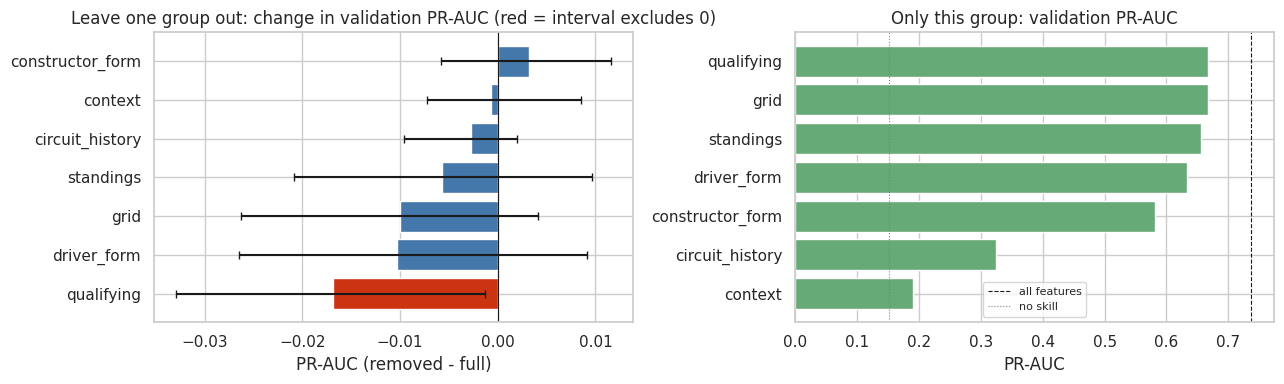

In [104]:
def paired_delta_ci(p_full, p_alt, d=val, metric=average_precision_score, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed); y = d[TARGET].to_numpy()
    races = d["raceId"].to_numpy(); idx_by_race = [np.where(races == r)[0] for r in np.unique(races)]
    deltas = []
    for _ in range(n_boot):
        idx = np.concatenate([idx_by_race[i] for i in rng.integers(0, len(idx_by_race), len(idx_by_race))])
        if y[idx].min() == y[idx].max(): continue
        deltas.append(metric(y[idx], p_alt[idx]) - metric(y[idx], p_full[idx]))
    return np.percentile(deltas, [2.5, 97.5])

ci_rows = []
for g in GROUPS:
    d_pr = [average_precision_score(val[TARGET], preds[("leave_one_group_out", g, s)]) - average_precision_score(val[TARGET], preds[("full", "full", s)]) for s in SEEDS]
    lo, hi = paired_delta_ci(preds[("full", "full", SEEDS[0])], preds[("leave_one_group_out", g, SEEDS[0])])
    only = summ[(summ.run_type == "only_this_group") & (summ.group == g) & (summ.split == "val")]["pr_auc"].iloc[0]
    ci_rows.append(dict(group=g, n_features=len(GROUPS[g]), delta_pr_auc=np.mean(d_pr), ci_low=lo, ci_high=hi,
                        clearly_needed=bool(hi < 0), pr_auc_group_alone=only))
ci = pd.DataFrame(ci_rows).sort_values("delta_pr_auc").reset_index(drop=True)
ci.to_csv(os.path.join(OUT_RES, "ablation_delta_ci.csv"), index=False)
print(f"Full model validation PR-AUC: {full_val['pr_auc']:.4f} (no-skill = {val[TARGET].mean():.3f})")
display(ci.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
y = np.arange(len(ci))
axes[0].barh(y, ci["delta_pr_auc"], color=np.where(ci["clearly_needed"], "#CC3311", "#4477AA"))
axes[0].errorbar(ci["delta_pr_auc"], y, xerr=[ci["delta_pr_auc"] - ci["ci_low"], ci["ci_high"] - ci["delta_pr_auc"]], fmt="none", ecolor="k", capsize=3)
axes[0].axvline(0, color="k", lw=0.8); axes[0].set_yticks(y); axes[0].set_yticklabels(ci["group"])
axes[0].set(title="Leave one group out: change in validation PR-AUC (red = interval excludes 0)", xlabel="PR-AUC (removed - full)")
alone = ci.sort_values("pr_auc_group_alone")
axes[1].barh(alone["group"], alone["pr_auc_group_alone"], color="#66AA77")
axes[1].axvline(full_val["pr_auc"], color="k", ls="--", lw=0.8, label="all features")
axes[1].axvline(val[TARGET].mean(), color="grey", ls=":", lw=0.8, label="no skill")
axes[1].set(title="Only this group: validation PR-AUC", xlabel="PR-AUC"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT_FIG, "ablation.png"), dpi=150); plt.show()

## 5.4 Preprocessing experiment P1: when are the preprocessing statistics learned?
- **Correct:** split first, then fit the imputer and scaler on training rows only.
- **Leaky:** fit them on all rows (train + validation + test) before splitting, so medians and standard deviations have seen the evaluation seasons.

Same model and features; only the rows used to fit preprocessing change.

In [105]:
p1_rows = []
for label, fit_rows in [("correct: fit on train only", None), ("leaky: fit on all rows", mdl)]:
    r = fit_eval(FEATURES, fit_pre_on=fit_rows)
    for split in ("val", "test"):
        p1_rows.append(dict(pipeline=label, split=split, **r["metrics"][split]))
p1 = pd.DataFrame(p1_rows); p1.to_csv(os.path.join(OUT_RES, "p1_fit_scope.csv"), index=False)
display(p1.pivot(index="pipeline", columns="split", values=["pr_auc", "roc_auc", "f1", "threshold"]).round(4))

cont = make_preprocessor(CONTINUOUS, [], "linear").fit(train[FEATURES])
leak = make_preprocessor(CONTINUOUS, [], "linear").fit(mdl[FEATURES])
imp_c, imp_l = cont.named_transformers_["cont"]["imp"], leak.named_transformers_["cont"]["imp"]
sc_c, sc_l = cont.named_transformers_["cont"]["sc"], leak.named_transformers_["cont"]["sc"]
shift = pd.DataFrame({"median_train": imp_c.statistics_, "median_all_rows": imp_l.statistics_,
                      "std_train": sc_c.scale_[:len(CONTINUOUS)], "std_all_rows": sc_l.scale_[:len(CONTINUOUS)]}, index=CONTINUOUS)
shift["median_shift_in_std"] = (shift["median_all_rows"] - shift["median_train"]).abs() / shift["std_train"]
print("Largest changes in the learned statistics when evaluation rows leak into fitting:")
display(shift.sort_values("median_shift_in_std", ascending=False).head(5).round(3))

pr_auc         roc_auc              f1         threshold        
split                         test     val    test     val    test     val      test     val
pipeline                                                                                    
correct: fit on train only  0.7218  0.7369  0.9361  0.9329  0.6654  0.7109    0.6710  0.6710
leaky: fit on all rows      0.7218  0.7372  0.9361  0.9330  0.6654  0.7109    0.6702  0.6702

Largest changes in the learned statistics when evaluation rows leak into fitting:


,median_train,median_all_rows,std_train,std_all_rows,median_shift_in_std
drv_circuit_prev_starts,1.000,2.000,3.030,3.211,0.330
quali_gap_pct,1.826,1.657,1.120,1.148,0.151
q1_gap_pct,1.495,1.340,1.153,1.167,0.135
drv_career_starts,41.000,45.000,61.575,68.780,0.065
circuit_front_row_podium_rate,0.562,0.571,0.142,0.147,0.063


## 5.5 Preprocessing experiment P2: impute then scale vs scale then impute
- **Impute then scale (used):** missing values get the median, then everything is standardised.
- **Scale then impute:** standardise first (missing values ignored), then fill gaps with the median of the *scaled* column.

The difference shows on features with many gaps (qualifying is missing for about 60% of training rows).

pr_auc         roc_auc              f1        
split                test     val    test     val    test     val
order                                                            
impute_then_scale  0.7218  0.7369  0.9361  0.9329  0.6654  0.7109
scale_then_impute  0.7223  0.7335  0.9372  0.9317  0.6705  0.7115

,order,feature,missing_share,mean,std,min,max
0,impute_then_scale,quali_pos,0.631,-0.000,1.000,-2.618,3.845
1,impute_then_scale,quali_gap_pct,0.637,0.000,1.000,-1.751,14.930
2,scale_then_impute,quali_pos,0.631,-0.034,0.608,-1.627,2.305
3,scale_then_impute,quali_gap_pct,0.637,-0.129,0.610,-1.198,8.985


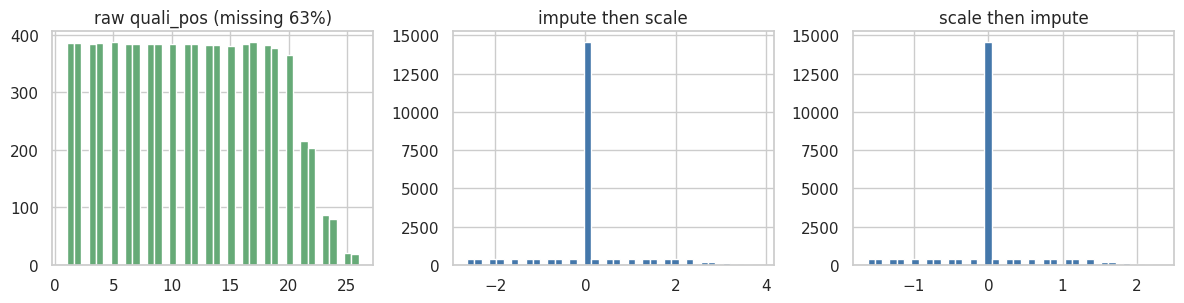

In [106]:
p2_rows = []
for order in ["impute_then_scale", "scale_then_impute"]:
    r = fit_eval(FEATURES, order=order)
    for split in ("val", "test"):
        p2_rows.append(dict(order=order, split=split, **r["metrics"][split]))
p2 = pd.DataFrame(p2_rows); p2.to_csv(os.path.join(OUT_RES, "p2_order.csv"), index=False)
display(p2.pivot(index="order", columns="split", values=["pr_auc", "roc_auc", "f1"]).round(4))

cols = [c for c in ["quali_pos", "quali_gap_pct", "grid_clean"] if c in CONTINUOUS][:2]
stat_rows = []
for order in ["impute_then_scale", "scale_then_impute"]:
    pre = make_preprocessor(CONTINUOUS, [], "linear", order).fit(train[FEATURES])
    X = pd.DataFrame(pre.transform(train[FEATURES])[:, :len(CONTINUOUS)], columns=CONTINUOUS)
    for c in cols:
        stat_rows.append(dict(order=order, feature=c, missing_share=train[c].isna().mean(), mean=X[c].mean(), std=X[c].std(), min=X[c].min(), max=X[c].max()))
display(pd.DataFrame(stat_rows).round(3))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
c = cols[0]
axes[0].hist(train[c].dropna(), bins=40, color="#66AA77"); axes[0].set_title(f"raw {c} (missing {train[c].isna().mean():.0%})")
for ax, order in zip(axes[1:], ["impute_then_scale", "scale_then_impute"]):
    pre = make_preprocessor(CONTINUOUS, [], "linear", order).fit(train[FEATURES])
    ax.hist(pd.DataFrame(pre.transform(train[FEATURES])[:, :len(CONTINUOUS)], columns=CONTINUOUS)[c], bins=40, color="#4477AA")
    ax.set_title(order.replace("_", " "))
plt.tight_layout(); plt.savefig(os.path.join(OUT_FIG, "p2_order_hist.png"), dpi=150); plt.show()

## 5.6 Conclusions (computed from the tables above)

In [107]:
needed = ci[ci["clearly_needed"]]["group"].tolist()
print(f"Final model: {final['label']}. Full model validation PR-AUC {full_val['pr_auc']:.3f}.")
print(f"Largest drop when removed: {ci.iloc[0]['group']} ({ci.iloc[0]['delta_pr_auc']:+.4f}); "
      f"groups whose removal clearly hurts (interval below 0): {needed or 'none'}.")
best_alone = ci.sort_values("pr_auc_group_alone", ascending=False).iloc[0]
print(f"Strongest group on its own: {best_alone['group']} (PR-AUC {best_alone['pr_auc_group_alone']:.3f}).")
pv = p1[p1.split == "val"].set_index("pipeline")["pr_auc"]
print(f"P1: validation PR-AUC correct {pv.iloc[0]:.4f} vs leaky {pv.iloc[1]:.4f} "
      f"(largest median shift {shift['median_shift_in_std'].max():.3f} train SDs).")
qv = p2[p2.split == "val"].set_index("order")["pr_auc"]
print(f"P2: validation PR-AUC impute->scale {qv['impute_then_scale']:.4f} vs scale->impute {qv['scale_then_impute']:.4f}.")

Final model: Logistic regression. Full model validation PR-AUC 0.737.
Largest drop when removed: qualifying (-0.0168); groups whose removal clearly hurts (interval below 0): ['qualifying'].
Strongest group on its own: qualifying (PR-AUC 0.667).
P1: validation PR-AUC correct 0.7369 vs leaky 0.7372 (largest median shift 0.330 train SDs).
P2: validation PR-AUC impute->scale 0.7369 vs scale->impute 0.7335.


**Reading the results**
- **Ablation:** a group matters when removing it lowers PR-AUC with an interval below 0. Small changes with intervals crossing 0 mean the other groups cover for it (grid and qualifying overlap strongly). "Only this group" shows which groups carry signal by themselves. This is reliance of *this model* on the features, not proof that a feature *causes* podiums.
- **P1:** with 22k training rows the leaked statistics move only slightly, so the score barely changes; it is still invalid, because evaluation seasons influenced the transformation. With smaller training sets or drifting eras the gap would be larger.
- **P2:** scaling first makes the filled-in value the median of the scaled column; the column then no longer has standard deviation 1 (see the table), which is why impute-then-scale is used.

**Limitations:** one chronological split; validation has only 39 races; correlated groups make leave-one-out understate shared information.

# Task 6: Model Explainability (XAI)
Explains the trained models from the model-comparison section, using the saved modeling table, splits and fitted pipelines. The **final model** (read from `results/final_model.json`) gets the full treatment; the other saved models are analysed with the same protocol so conclusions do not hang on one model. Nothing is re-tuned here and no model selection decision depends on anything in this notebook.

**Guarantee about which models are analysed.** A model is only analysed if its predictions on the validation and test rows reproduce, to numerical precision, the predictions that were saved in `results/<name>_preds.parquet` when that model was evaluated. Each model is obtained by the first method that passes this check: (1) load the saved `.joblib`, (2) load it with a compatibility shim, (3) refit it from its saved recipe on the training rows. Part 1 prints which method was used for each model and the size of the prediction difference. A model that cannot pass is excluded and named, never silently analysed.

| Part | What it does |
|---|---|
| 1 | Finds the artifacts, obtains every model and **verifies** it against its saved predictions |
| 2 | What is being explained, on which rows, against which reference data, and how to read the results |
| 3 | **Global 1: permutation importance** (single features, feature groups, every verified model) |
| 4 | Does the explanation depend on the random seed of the network? |
| 5 | **Global 2: SHAP** for the explained model (bar, beeswarm, group SHAP, dependence plots) and agreement with permutation importance |
| 6 | Sensitivity of SHAP to its reference data; **exact SHAP for every other verified model** |
| 7 | **Local explanations**: SHAP waterfall and LIME for individual driver-race rows, plus the same rows across models |
| 8 | Written conclusions (computed from the tables above), limitations, saved files |

**Read this before quoting any result.** Every explanation below describes *what a fitted model relies on to produce its scores*. None of it shows what causes a podium. A feature can be important to a model because it is correlated with something that matters (a fast car, a strong qualifying lap) without having any effect of its own. This distinction is repeated where the results are interpreted.

## 6.1 Setup, artifacts and model verification

Inputs (all written by the earlier notebooks):

| File | Written by | Used for |
|---|---|---|
| `clean/modeling_table.parquet`, `clean/feature_config.json` | feature engineering (Task 3) | rows, features, groups, time split |
| `results/final_model.json`, `results/<name>_model.joblib`, `results/<name>.json`, `results/<name>_preds.parquet` | statistical models and neural network notebooks | the fitted pipelines, their settings, thresholds and saved predictions |
| `clean/drivers.parquet`, `races.parquet`, `constructors.parquet`, `results.parquet`, `status.parquet` | cleaning notebook | readable names for the local explanations (display only, never features) |

Outputs: figures in `figures_xai/`, tables in `xai_outputs/`.

In [1]:
# Install any third-party library that is missing, before anything is imported.
import importlib.util, subprocess, sys
for _mod, _pip in [("shap", "shap"), ("lime", "lime"), ("xgboost", "xgboost"), ("pyarrow", "pyarrow"), ("joblib", "joblib")]:
    if importlib.util.find_spec(_mod) is None:
        print(f"installing {_pip} ...")
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pip])
        except Exception as e:
            print(f"  could not install {_pip}: {e}")
print("setup done")

setup done


In [2]:
# Report which scikit-learn version wrote each saved model and whether this kernel can unpickle it. Also defines
#          locate(), the single file-search routine shared with section 15.1.
# Saved models are pickles tied to library versions, and a version mismatch is the most common
#   reason they fail to load. Diagnosing it up front (in a subprocess, so a failed load cannot damage
#   this kernel) explains later messages. This cell only reports; section 15.1 acts.
# --------------------------------------------------------------------------------------------------------------------
import os, glob, re, sys, subprocess
from importlib.metadata import version as _v, PackageNotFoundError
# one search routine for the whole notebook (needs only os and glob, so it can run before scikit-learn is imported).
# Section 15.1 reuses it, so this cell and the loader always look at the same copy of every file.
def locate(name, subdirs=("", "clean", "results", "models")):
    # looks next to the notebook, one level up, in /kaggle/working, then searches /kaggle/input and the working directory
    bases = [b for b in [os.environ.get("F1_ROOT"), os.getcwd(), os.path.dirname(os.getcwd()), "/kaggle/working"] if b]
    for b in bases:
        for s in subdirs:
            p = os.path.join(b, s, name)
            if os.path.exists(p): return p
    for b in [os.getcwd(), "/kaggle/working", "/kaggle/input"]:
        if os.path.isdir(b):
            hits = sorted(glob.glob(os.path.join(b, "**", name), recursive=True))
            if hits: return hits[0]
    return None

def _ver(p):
    try: return _v(p)
    except PackageNotFoundError: return "not installed"
# versions installed in this kernel, printed so the run is documented
_inst = {p: _ver(p) for p in ["scikit-learn", "xgboost", "shap", "lime", "numpy", "pandas", "joblib"]}
print(f"python {sys.version.split()[0]} | installed here: {_inst}")
# inspect exactly the folder section 15.1 loads from: the one holding final_model.json, found by the shared locate()
_p_final = locate("final_model")
_files = sorted(glob.glob(os.path.join(os.path.dirname(_p_final), "*_model.joblib"))) if _p_final else []
print("saved models inspected in:", os.path.dirname(_p_final) if _p_final else "not found (final_model.json is missing)")
_trained = set()
for _f in _files:
    # every scikit-learn pickle stores the version that wrote it; read it straight from the file bytes
    _vs = sorted({x.decode() for x in re.findall(rb"_sklearn_version[^0-9]{1,8}(\d+\.\d+(?:\.\d+)?)", open(_f, "rb").read())})
    _trained.update(_vs)
    # try the load in a separate process so a failure cannot damage this kernel
    _r = subprocess.run([sys.executable, "-c", "import joblib,sys; m=joblib.load(sys.argv[1]); print('ok')", _f], capture_output=True, text=True)
    _msg = "unpickles here" if _r.returncode == 0 else "does NOT unpickle here: " + (_r.stderr.strip().splitlines() or ["?"])[-1][:110]
    print(f"  {os.path.basename(_f):24s} written by scikit-learn {', '.join(_vs) or '(not readable)'} | {_msg}")
# warn when the writing and the installed versions differ
if _trained and _inst["scikit-learn"] not in _trained:
    print(f"\nThe saved models were written by scikit-learn {sorted(_trained)} but this kernel has {_inst['scikit-learn']}.\n"
          "That is fine for this notebook (models are refitted and verified in 15.1). To load the ORIGINAL files instead, recreate the training environment:\n"
          f"  a Python version that supports scikit-learn=={sorted(_trained)[-1]} (3.9 to 3.12 for 1.6.x) plus the other pinned versions from the training machine's `pip freeze`.")

python 3.13.9 | installed here: {'scikit-learn': '1.6.1', 'xgboost': '3.4.1', 'shap': '0.53.0', 'lime': '0.2.0.1', 'numpy': '2.5.4', 'pandas': '2.3.3', 'joblib': '1.6.0'}
saved models inspected in: not found (final_model.json is missing)


In [3]:
import os, glob, json, time, copy, itertools, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score
import shap
try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except Exception as _e:
    HAVE_XGB = False; print("xgboost not importable, the XGBoost model cannot be analysed:", _e)
try:
    from lime.lime_tabular import LimeTabularExplainer
    HAVE_LIME = True
except Exception as _e:
    HAVE_LIME = False
    print("LIME not available, the LIME parts will be skipped:", _e)

# hide library deprecation noise only; other warnings (e.g. pickle version warnings) stay visible
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 170)
# same seed as the training notebooks, so refits and resampling are reproducible
SEED = 42
N_JOBS = max(1, min(os.cpu_count() or 2, 4))     
np.random.seed(SEED)

# ------------------------------- settings -----------------------------
MODEL_TO_EXPLAIN = "logreg"   # "final" = whatever results/final_model.json says; or a key such as "nn", "xgb", "logreg", "rf"
N_REPEATS = 30               # permutation repeats for the explained model (validation and test)
N_REPEATS_CROSS = 20         # permutation repeats for the other models and the seed check
BACKGROUND_FROM_YEAR = 2014  # SHAP/LIME reference data = training rows from this season on (hybrid era, full qualifying data)
BACKGROUND_SIZE = 100        # rows in the SHAP background
N_PERMUTATIONS = 6           # SHAP permutation passes per row for the network (each pass visits every feature twice)
N_EXPLAIN = None             # None = explain every test row; an int = random subset of that many rows
TOP_K = 15                   # features shown in bar charts
LIME_SAMPLES = 5000          # perturbed samples per LIME explanation
LIME_SEEDS = 5               # repeats of LIME per case, for the stability check
RUN_SEED_CHECK = True        # retrain the network with 3 seeds (needs the NN recipe, ~10 s)
# thresholds for the verification gate in 15.1
PASS_TOL, CLOSE_TOL = 1e-6, 1e-3   # max |prediction difference| vs the saved predictions: PASS if below PASS_TOL, CLOSE (flagged) if below CLOSE_TOL

In [4]:
# Find the artifacts written by the earlier notebooks, load the modeling table, and rebuild the train /
# validation / test split.
# Explanations are only meaningful on the same rows, features and chronological split the models
#    were trained and evaluated on. The assertions turn a silent mismatch (duplicate driver-race rows,
#    overlapping seasons, a feature missing from the table) into an immediate error.
# --------------------------------------------------------------------------------------------------------------------
# locate() is defined in the pre-flight cell above (one shared search routine)
def need(name):
    p = locate(name)
    if p is None:
        raise FileNotFoundError(f"{name} not found. Run the earlier notebooks (they write it) or attach their output, or set the F1_ROOT environment variable.")
    return p

p_cfg, p_final = need("feature_config.json"), need("final_model.json")
p_table = locate("modeling_table.parquet") or need("modeling_table.csv")
RESULTS = os.path.dirname(p_final)
# Kaggle input folders are read-only, so outputs go to /kaggle/working there
OUT_ROOT = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.dirname(os.path.abspath(RESULTS))
FIG_DIR, TAB_DIR = os.path.join(OUT_ROOT, "figures_xai"), os.path.join(OUT_ROOT, "xai_outputs")
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(TAB_DIR, exist_ok=True)

cfg = json.load(open(p_cfg))
mdl = pd.read_parquet(p_table) if p_table.endswith(".parquet") else pd.read_csv(p_table)
TARGET, FEATURES = cfg["target"], list(cfg["features"])
BINARY, CONTINUOUS = list(cfg["binary"]), list(cfg["continuous"])
FEATURE_GROUPS = {g: list(f) for g, f in cfg["groups"].items()}
group_of = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}
# same row order as the training notebooks (a refit must see rows in the same order)
mdl = mdl.sort_values(["race_order", "driverId"]).reset_index(drop=True)
# chronological split recorded by feature engineering: no shuffling, so no future information leaks into training
train, val, test = (mdl[mdl["split"] == s].reset_index(drop=True) for s in ("train", "val", "test"))

# the feature config and the table must agree
assert set(FEATURES) <= set(mdl.columns) and set(BINARY) | set(CONTINUOUS) == set(FEATURES) and set(group_of) == set(FEATURES)
# grain check: exactly one row per (raceId, driverId)
assert not mdl.duplicated(["raceId", "driverId"]).any(), "grain broken"
# time-order check: every train race precedes validation, which precedes test
assert train["race_order"].max() < val["race_order"].min() and val["race_order"].max() < test["race_order"].min()
group_colors = dict(zip(FEATURE_GROUPS, plt.cm.tab10.colors))

print(f"modeling table: {p_table}\nresults folder: {RESULTS}\noutputs: {FIG_DIR} , {TAB_DIR}")
print(f"{len(FEATURES)} features ({len(BINARY)} binary) in groups { {g: len(f) for g, f in FEATURE_GROUPS.items()} }")
print(f"train {len(train):,} ({train['year'].min()}-{train['year'].max()}) | val {len(val):,} ({val['year'].min()}-{val['year'].max()}) | "
      f"test {len(test):,} ({test['year'].min()}-{test['year'].max()}) | podium rate train/val/test = "
      f"{train[TARGET].mean():.3f}/{val[TARGET].mean():.3f}/{test[TARGET].mean():.3f}")

modeling table: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\clean\modeling_table.parquet
results folder: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\results
outputs: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai , a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\xai_outputs
29 features (4 binary) in groups {'grid': 6, 'qualifying': 4, 'driver_form': 4, 'constructor_form': 2, 'standings': 6, 'circuit_history': 3, 'context': 4}
train 22,441 (1950-2019) | val 774 (2020-2021) | test 1,351 (2022-2024) | podium rate train/val/test = 0.135/0.151/0.151


In [5]:
# Define the scoring helpers shared by verification, permutation importance and the result tables.
# A single definition guarantees every section computes metrics identically, including the race-
# aware top-3 precision that mirrors the real task (three podium places per race).
# ---- small helpers used everywhere ------------------------------------------------------------------------------
def predict_p(m, d): return m.predict_proba(d[FEATURES])[:, 1]

# per race, take the 3 highest-scored drivers and count how many really finished on the podium
def top3_precision_arr(y, p, race):
    dd = pd.DataFrame(dict(y=y, p=p, r=race)).sort_values(["r", "p"], ascending=[True, False])
    return float(dd.groupby("r").head(3)["y"].mean())

# threshold-free (ROC-AUC, PR-AUC) and thresholded (F1, precision, recall) metrics in one place
def metrics_at(d, p, thr):
    y = d[TARGET].to_numpy(); yhat = (np.asarray(p) >= thr).astype(int)
    return dict(roc_auc=roc_auc_score(y, p), pr_auc=average_precision_score(y, p), f1=f1_score(y, yhat, zero_division=0),
                precision=precision_score(y, yhat, zero_division=0), recall=recall_score(y, yhat, zero_division=0),
                top3_precision=top3_precision_arr(y, np.asarray(p), d["raceId"].to_numpy()))

In [6]:
# Hold exact copies of the training recipes (preprocessing, the three statistical models, the network) and a
#     compatibility shim.
# If a saved model cannot be loaded, the last resort is to refit it with the identical recipe on the
#    identical training rows. Neither the recipes nor the shim are trusted on their own: the
#     verification gate in the next cell checks what they produce.
# --------------------------------------------------------------------------------------------------------------------
# ---- training recipes, copied unchanged from the modeling notebooks ----------------------------------------------
# Used only if a saved .joblib cannot be loaded, to refit the SAME model on the SAME training rows with the SAME settings
# (settings come from results/<name>.json). The result is accepted only if it reproduces the saved predictions (15.1 gate).
# training2.ipynb: preprocessing and the three statistical models (fit on train rows only)
# three variants: linear/network (impute + scale), tree (impute only), native (XGBoost handles NaN itself)
def make_preprocessor(kind="linear", continuous=None, binary=None):
    continuous = CONTINUOUS if continuous is None else continuous
    binary = BINARY if binary is None else binary
    if kind == "native":
        return ColumnTransformer([("all", "passthrough", continuous + binary)], verbose_feature_names_out=False)
    # median imputation plus a 0/1 'was missing' column for each feature that has gaps in training
    imp = lambda: SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)
    cont = [("imp", imp())] + ([("sc", StandardScaler())] if kind == "linear" else [])
    return ColumnTransformer([("cont", Pipeline(cont), continuous),
                              ("bin", SimpleImputer(strategy="most_frequent", keep_empty_features=True), binary)])

# non-podium to podium ratio; used to up-weight the rare podium class
POS_WEIGHT = float((train[TARGET] == 0).sum() / (train[TARGET] == 1).sum())
KIND = {"logreg": "lr", "rf": "rf", "xgb": "xgb"}          # results/ key -> recipe
PREP = {"lr": "linear", "rf": "tree", "xgb": "native"}
# same estimator settings as training2.ipynb; tuned values arrive from results/<name>.json
def build_stat_model(kind, **p):
    if kind == "lr":
        est = LogisticRegression(class_weight="balanced", max_iter=5000, **p)
    elif kind == "rf":
        est = RandomForestClassifier(class_weight="balanced_subsample", n_jobs=N_JOBS, random_state=SEED, **p)
    else:
        est = XGBClassifier(tree_method="hist", eval_metric="logloss", scale_pos_weight=POS_WEIGHT, n_jobs=N_JOBS, random_state=SEED, verbosity=0, **p)
    return Pipeline([("pre", make_preprocessor(PREP[kind])), ("clf", est)])

# nn_models.ipynb: shallow network (class-weighted epochs, early stopping on validation PR-AUC, train rows only)
# replicates nn_models.ipynb: class-balanced epochs, early stopping on validation PR-AUC
def train_nn_pipeline(hidden=(64,), alpha=1e-3, lr=1e-3, batch=256, max_epochs=200, patience=15, seed=SEED):
    pre = make_preprocessor("linear").fit(train[FEATURES])
    X_tr, X_va = pre.transform(train[FEATURES]), pre.transform(val[FEATURES])
    y_tr, y_va = train[TARGET].to_numpy(), val[TARGET].to_numpy()
    pos_w = (y_tr == 0).sum() / (y_tr == 1).sum()
    rng = np.random.default_rng(seed)
    # each epoch repeats podium rows about pos_w times so the network sees balanced classes
    def weighted_epoch():
        pos, neg = np.where(y_tr == 1)[0], np.where(y_tr == 0)[0]
        reps = int(np.floor(pos_w)); extra = rng.random(len(pos)) < (pos_w - reps)
        idx = np.concatenate([neg, np.repeat(pos, reps), pos[extra]]); rng.shuffle(idx)
        return X_tr[idx], y_tr[idx]
    net = MLPClassifier(hidden_layer_sizes=tuple(hidden), activation="relu", solver="adam", alpha=alpha,
                        learning_rate_init=lr, batch_size=batch, random_state=seed)
    best, best_score, wait = None, -np.inf, 0
    for epoch in range(1, max_epochs + 1):
        Xe, ye = weighted_epoch(); net.partial_fit(Xe, ye, classes=[0, 1])
        score = average_precision_score(y_va, net.predict_proba(X_va)[:, 1])
        # keep the best epoch by validation PR-AUC; stop after `patience` epochs without improvement
        if score > best_score + 1e-4: best, best_score, wait = copy.deepcopy(net), score, 0
        else:
            wait += 1
            if wait >= patience: break
    return Pipeline([("pre", pre), ("clf", best)]), float(best_score)

# ---- compatibility shim for pickles written by a newer scikit-learn --------------------------------------------------
# Newer scikit-learn stores a small helper class (_RemainderColsList) inside fitted ColumnTransformers. Older versions do not
# have it, so unpickling fails with "Can't get attribute". The helper only carries the list of unused columns (empty here),
# so a plain stand-in class is enough. Whether the loaded model is RIGHT is decided by the verification gate, not by this shim.
# stand-in for a helper class that scikit-learn 1.7 removed but older pickles reference
import collections, sklearn.compose._column_transformer as _ct
_SHIM_INSTALLED = False
def shim_on():
    global _SHIM_INSTALLED
    if not hasattr(_ct, "_RemainderColsList"):
        class _RemainderColsList(collections.UserList): pass
        _RemainderColsList.__module__ = _ct.__name__
        _ct._RemainderColsList = _RemainderColsList; _SHIM_INSTALLED = True
def shim_off():
    global _SHIM_INSTALLED
    if _SHIM_INSTALLED and hasattr(_ct, "_RemainderColsList"): del _ct._RemainderColsList
    _SHIM_INSTALLED = False

In [7]:
# Obtain one model per saved result and accept it only if it reproduces the predictions that were saved when
# it was evaluated.
# This is the guarantee that the explanations describe the trained models and not look-alikes. A
#     model that loads but behaves differently (library drift) is rejected here, and the notebook stops
#     if the model to be explained cannot be verified.
# --------------------------------------------------------------------------------------------------------------------
# ---- find every saved model and obtain a VERIFIED copy of each --------------------------------------------------------
final_meta = json.load(open(p_final))
FINAL_KEY = final_meta["final_model"]
EXPLAIN_KEY = FINAL_KEY if MODEL_TO_EXPLAIN == "final" else MODEL_TO_EXPLAIN

META, PREDS, FILES = {}, {}, {}
# discover models in results/ and pair each with its settings (.json) and saved predictions (_preds.parquet)
for f in sorted(glob.glob(os.path.join(RESULTS, "*_model.joblib"))):
    key = os.path.basename(f)[:-len("_model.joblib")]
    if os.path.exists(os.path.join(RESULTS, f"{key}.json")) and os.path.exists(os.path.join(RESULTS, f"{key}_preds.parquet")):
        META[key] = json.load(open(os.path.join(RESULTS, f"{key}.json")))
        PREDS[key] = pd.read_parquet(os.path.join(RESULTS, f"{key}_preds.parquet")).drop_duplicates("resultId").set_index("resultId")["p"]
        FILES[key] = f
print(f"saved models found in {RESULTS}: {sorted(META)}")
if EXPLAIN_KEY not in META: raise KeyError(f"model '{EXPLAIN_KEY}' not found in {RESULTS}; available: {sorted(META)}")

# compare the model's predictions with the saved ones on every validation and test row
def verify(key, m):
    """compare the model's predictions on the val and test rows with the predictions saved when it was evaluated"""
    out = dict(grade="FAIL", val_diff=np.nan, test_diff=np.nan, error="", preds={})
    try:
        diffs = {}
        for sp, d in (("val", val), ("test", test)):
            saved = PREDS[key].reindex(d["resultId"]).to_numpy()
            if np.isnan(saved).any(): raise ValueError(f"saved predictions missing for some {sp} rows")
            # keep the predictions: the accepted model's copy is reused by every later cell instead of predicting again
            out["preds"][sp] = predict_p(m, d)
            diffs[sp] = float(np.max(np.abs(out["preds"][sp] - saved)))
        out.update(val_diff=diffs["val"], test_diff=diffs["test"])
        worst = max(diffs.values())
        # PASS = identical to float precision, CLOSE = tiny drift (usable, flagged), FAIL = a different model
        out["grade"] = "PASS" if worst <= PASS_TOL else "CLOSE" if worst <= CLOSE_TOL else "FAIL"
    except Exception as e:
        out["error"] = f"{type(e).__name__}: {str(e)[:100]}"
    return out

# rung 3: refit from the saved settings on the training rows only
def rebuild(key):
    prm = META[key]["params"]
    if key == "nn":
        return train_nn_pipeline(hidden=tuple(prm["hidden"]), alpha=prm["alpha"], lr=prm.get("lr", 1e-3), seed=prm.get("seed", SEED))[0]
    if key in KIND:
        if KIND[key] == "xgb" and not HAVE_XGB: raise RuntimeError("xgboost is not importable")
        return build_stat_model(KIND[key], **prm).fit(train[FEATURES], train[TARGET])
    raise RuntimeError(f"no refit recipe for model '{key}'")

def load_file(key, shim):
    shim_off()
    if shim: shim_on()
    try:
        # loading is not enough: the model must also be able to predict
        m = joblib.load(FILES[key]); m.predict_proba(val[FEATURES].head(5))     # must also be able to predict
        return m
    finally:
        shim_off()

# try (1) the file as saved, (2) with the shim, (3) a refit; return the first that passes the gate, with a log of every attempt
def acquire(key):
    log, best = [], None
    for how, fn in [("saved .joblib", lambda: load_file(key, False)), ("saved .joblib + shim", lambda: load_file(key, True)), ("refit from saved recipe", lambda: rebuild(key))]:
        try:
            m = fn()
        except Exception as e:
            log.append(f"{how}: not possible ({type(e).__name__}: {str(e)[:70]})"); continue
        v = verify(key, m)
        log.append(f"{how}: {v['grade']}" + (f" (max diff val {v['val_diff']:.1e}, test {v['test_diff']:.1e})" if v["error"] == "" else f" ({v['error']})"))
        if v["grade"] == "PASS": return m, how, v, log
        if v["grade"] == "CLOSE" and best is None: best = (m, how, v)
    if best: return best + (log,)
    return None, "none", dict(grade="FAIL", val_diff=np.nan, test_diff=np.nan, error="", preds={}), log

MODELS, PRED, STATUS, t0 = {}, {}, [], time.time()      # PRED[key] = {"val": scores, "test": scores} of the accepted model
for key in sorted(META):
    m, how, v, log = acquire(key)
    if m is not None: MODELS[key] = m; PRED[key] = v["preds"]
    STATUS.append(dict(key=key, model=META[key]["model"], obtained_by=how, verdict=v["grade"], val_max_diff=v["val_diff"], test_max_diff=v["test_diff"], attempts=" | ".join(log)))
STATUS = pd.DataFrame(STATUS)
LABEL = {k: m["model"] for k, m in META.items()}
THRESHOLD = {k: float(m["threshold"]) for k, m in META.items()}
pd.set_option("display.max_colwidth", 400)
print(f"model verification took {time.time()-t0:.0f}s")
display(STATUS.drop(columns="attempts"))
for r in STATUS.itertuples(): print(f"  {r.key:7s} {r.verdict:5s} via {r.obtained_by:24s} <- {r.attempts}")

bad = STATUS[STATUS["verdict"] == "FAIL"]["key"].tolist()
# hard stop: never explain a model that could not be verified
if EXPLAIN_KEY not in MODELS or STATUS.set_index("key").loc[EXPLAIN_KEY, "verdict"] != "PASS":
    raise RuntimeError(f"The model to explain ('{EXPLAIN_KEY}') could not be reproduced to within {PASS_TOL:g} of its saved predictions by any method, "
                       f"so it will NOT be analysed. Details above. Most likely cause: the library versions here differ from the training environment "
                       f"(install matching scikit-learn/xgboost, or re-run the modeling notebooks in this environment).")
print(f"\nVERIFIED: {len(MODELS)} of {len(META)} saved models reproduce their saved predictions and are analysed below: {[LABEL[k] for k in MODELS]}"
      + (f"\nEXCLUDED (could not be reproduced, NOT analysed): {[LABEL[k] for k in bad]}" if bad else ""))
if "xgb" in bad and HAVE_XGB:
    import xgboost as _xgb
    print(f"HINT (XGBoost {_xgb.__version__} installed): XGBoost 1.x and 2.x build different models from identical settings (2.0 changed how the starting score, base_score, is estimated), "
          "and a pickle written by 2.x cannot be read by 1.x. Run `pip install -U xgboost`, restart the kernel and Run All, or re-run the training notebook in this environment.")
close = STATUS[STATUS["verdict"] == "CLOSE"]["key"].tolist()
if close: print(f"NOTE: {close} reproduce their saved predictions only to within {CLOSE_TOL:g} (not {PASS_TOL:g}); treat their results as approximate.")
# from here on `model` is the verified model that receives the full analysis
model = MODELS[EXPLAIN_KEY]
print(f"Explained model: {LABEL[EXPLAIN_KEY]} ('{EXPLAIN_KEY}'), validation-chosen threshold {THRESHOLD[EXPLAIN_KEY]:.3f} | final model per final_model.json: {LABEL.get(FINAL_KEY, FINAL_KEY)}")

saved models found in a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\results: ['logreg', 'nn', 'rf', 'xgb']
model verification took 0s


A:\Anaconda\Lib\pickle.py:1760: UserWarning: [20:50:43] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\gbm\../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


,key,model,obtained_by,verdict,val_max_diff,test_max_diff
0,logreg,Logistic regression,saved .joblib,PASS,5.551115e-16,5.551115e-16
1,nn,Shallow NN,saved .joblib,PASS,3.330669e-16,2.220446e-16
2,rf,Random forest,saved .joblib,PASS,3.330669e-16,4.440892e-16
3,xgb,XGBoost,saved .joblib,PASS,9.313226e-10,1.862645e-09


  logreg  PASS  via saved .joblib            <- saved .joblib: PASS (max diff val 5.6e-16, test 5.6e-16)
  nn      PASS  via saved .joblib            <- saved .joblib: PASS (max diff val 3.3e-16, test 2.2e-16)
  rf      PASS  via saved .joblib            <- saved .joblib: PASS (max diff val 3.3e-16, test 4.4e-16)
  xgb     PASS  via saved .joblib            <- saved .joblib: PASS (max diff val 9.3e-10, test 1.9e-09)

VERIFIED: 4 of 4 saved models reproduce their saved predictions and are analysed below: ['Logistic regression', 'Shallow NN', 'Random forest', 'XGBoost']
Explained model: Logistic regression ('logreg'), validation-chosen threshold 0.671 | final model per final_model.json: Logistic regression


In [8]:
# Recompute validation and test scores from the verified models and compare them with the numbers recorded at
#          evaluation time.
# An independent second confirmation (besides prediction matching) that these are the same models.
#    It also shows where the explained model ranks on test versus validation, which is context for how
#    far to trust its explanations.

# ---- scores of every verified model, from the predictions the verification gate computed with the models themselves ----
rows = []
for key in MODELS:
    for sp, d in (("val", val), ("test", test)):
        rows.append(dict(model=LABEL[key], key=key, split=sp, **metrics_at(d, PRED[key][sp], THRESHOLD[key])))
check = pd.DataFrame(rows)
EXPL_SCORE = check[check["key"] == EXPLAIN_KEY].set_index("split")      # the explained model's val/test scores, reused below
display(check.pivot(index="model", columns="split", values=["pr_auc", "roc_auc", "f1"]).round(4))
for key in MODELS:        # also compare with the validation PR-AUC recorded in results/<name>.json when the model was evaluated
    saved_pr = META[key].get("val", {}).get("pr_auc")
    if saved_pr is not None:
        now = check[(check["key"] == key) & (check["split"] == "val")]["pr_auc"].iloc[0]
        print(f"  {LABEL[key]:20s} validation PR-AUC now {now:.4f} vs recorded {saved_pr:.4f}" + ("" if abs(now - saved_pr) < 1e-4 else "   <-- MISMATCH"))
test_rank = check[check["split"] == "test"].sort_values("pr_auc", ascending=False)["key"].tolist()
val_rank = check[check["split"] == "val"].sort_values("pr_auc", ascending=False)["key"].tolist()
print(f"\nRank of the explained model by PR-AUC: test {test_rank.index(EXPLAIN_KEY) + 1} of {len(test_rank)}, validation {val_rank.index(EXPLAIN_KEY) + 1} of {len(val_rank)}.")

pr_auc         roc_auc              f1        
split                  test     val    test     val    test     val
model                                                              
Logistic regression  0.7218  0.7369  0.9361  0.9329  0.6654  0.7109
Random forest        0.7184  0.7220  0.9395  0.9286  0.6667  0.7078
Shallow NN           0.6897  0.7494  0.9234  0.9272  0.6521  0.7179
XGBoost              0.7208  0.7120  0.9395  0.9335  0.6792  0.7100

  Logistic regression  validation PR-AUC now 0.7369 vs recorded 0.7369
  Shallow NN           validation PR-AUC now 0.7494 vs recorded 0.7494
  Random forest        validation PR-AUC now 0.7220 vs recorded 0.7220
  XGBoost              validation PR-AUC now 0.7120 vs recorded 0.7120

Rank of the explained model by PR-AUC: test 1 of 4, validation 2 of 4.


## 6.2 What is explained, on which rows, and how to read it

**Rows explained.** The test seasons (2022 onwards). Explaining is not model selection: no threshold, hyperparameter or feature choice is revisited, so using the test rows here does not break the rule that selection uses train and validation only. Validation rows are used as a second, independent look at permutation importance, to see whether the picture is stable.

**Reference ("background") data.** SHAP and LIME describe a prediction *relative to a reference population*. The reference here is a random sample of **training rows from the hybrid era (2014 to the end of train)**. Reasons: qualifying data is complete in these seasons, the cars and field size are closest to the test seasons, and nothing from validation or test is used. A reference drawn from the whole training history (1950 onward) would be dominated by early-era rows where qualifying features are missing, which would change what the baseline means. Part 6 measures how much this choice matters.

**What the model's output is.** The networks and linear/forest models were trained with the podium class up-weighted (about 6.4 to 1), so their probabilities are **not calibrated**: they are scores that rank drivers, and they average well above the true podium rate. SHAP values below are in units of this model score (a "probability-like" scale from 0 to 1), so a bar of +0.2 means "raises the score by 0.2", not "raises the chance of a podium by 20 points".

**Methods.**

| Method | Question it answers | Main weakness |
|---|---|---|
| Permutation importance | How much does test performance drop if one feature (or group) is scrambled across rows? | Correlated features share credit and each looks less important than the pair; scrambling creates unrealistic rows |
| SHAP (permutation explainer) | How much does each feature move this prediction away from the reference average? Averaged over rows = global importance | Depends on the reference data; also creates unrealistic feature combinations; credit split among correlated features |
| LIME | What does a simple model fitted around this one point say? | Random sampling: explanations can change between runs; only valid very close to the point |

**Correlated features.** The feature-engineering notebook found `grid_clean` and `quali_pos` almost perfectly rank-correlated (rho about 0.98) and kept both on purpose. For such pairs, single-feature methods split or hide the credit. Two remedies are used below: **grouped** permutation importance and **group SHAP** (sum of SHAP values inside a feature group), which are not affected by credit-splitting inside a group.

## 6.3 Global explanation 1: permutation importance

For each feature, the column is shuffled across rows of the evaluation set (the whole pipeline is applied afterwards, so missing indicators and scaling stay consistent) and the score is recomputed. The **drop in score** is the importance. Repeating the shuffle `N_REPEATS` times gives a spread: a feature is called reliably used when `mean drop - 2 x std > 0`.

The primary metric of the project is **PR-AUC**, so it is the headline here. ROC-AUC and the race-aware top-3 precision are computed in the same pass and saved.

Agreement between two importance rankings is reported two ways, because a plain Spearman correlation over all features is dominated by the many features with almost no importance (their order is noise). `spearman_all` uses every feature; `spearman_top` uses only the features in the top 10 of either ranking; `overlap_top` counts how many of the top 10 are shared.

In [9]:
# Define a rank-agreement measure between two importance vectors.
# Spearman correlation over all features is dominated by the many near-zero features whose order is
#      noise. The measure therefore also reports Spearman on the union of each ranking's top-10 and the
#      number of shared top-10 features.
# --------------------------------------------------------------------------------------------------------------------
def agreement(a, b, k=10):
    a, b = pd.Series(a), pd.Series(b).reindex(pd.Series(a).index)
    ta, tb = a.sort_values(ascending=False).head(k).index, b.sort_values(ascending=False).head(k).index
    # union of both top-10 lists (order kept, duplicates removed)
    top = list(dict.fromkeys(list(ta) + list(tb)))
    # spearman_all = every feature, spearman_top = top-10 union only, overlap_top = shared top-10 features
    return dict(spearman_all=float(spearmanr(a, b).statistic), spearman_top=float(spearmanr(a[top], b[top]).statistic) if len(top) > 2 else np.nan,
                overlap_top=len(set(ta) & set(tb)), k=k, n_union=len(top))

In [10]:
# Compute permutation importance (the performance lost when a feature is scrambled) for one model, then run
# it for the explained model on validation and test.
# It measures what each feature contributes to accuracy, the performance-based counterpart of SHAP.
#    Repeating the shuffle gives a spread, and running on both validation and test shows whether the
#    ranking is stable or specific to one dataset.

def perm_importance(m, d, n_repeats=N_REPEATS, seed=SEED):
    # one feature at a time: shuffle its column across rows, score once, repeat. One model call per shuffle.
    y = d[TARGET].to_numpy(); race = d["raceId"].to_numpy(); X0 = d[FEATURES].reset_index(drop=True)
    # three metrics per call: PR-AUC (primary), ROC-AUC, race-aware top-3 precision
    def scores(X):
        p = m.predict_proba(X)[:, 1]
        return np.array([average_precision_score(y, p), roc_auc_score(y, p), top3_precision_arr(y, p, race)])
    # reference score with nothing shuffled
    base = scores(X0); rng = np.random.default_rng(seed); drops = np.zeros((len(FEATURES), n_repeats, 3))
    for j, f in enumerate(FEATURES):
        Xp = X0.copy(); col = X0[f].to_numpy()
        for r in range(n_repeats):
            # break the link between this feature and the target by shuffling it across rows
            Xp[f] = col[rng.permutation(len(col))]
            # importance = how much the score falls
            drops[j, r] = base - scores(Xp)
    out = pd.DataFrame({"feature": FEATURES, "group": [group_of[f] for f in FEATURES]})
    for k, name in enumerate(["pr_auc", "roc_auc", "top3_precision"]):
        out[f"{name}_drop"], out[f"{name}_std"] = drops[:, :, k].mean(1), drops[:, :, k].std(1)
    # rough rule: mean drop more than 2 std above zero (std is over shuffles only, not over races)
    out["reliable"] = (out["pr_auc_drop"] - 2 * out["pr_auc_std"]) > 0
    return out

t0 = time.time()
# validation is an independent second look at stability; test is the unseen seasons
PI = {"validation": perm_importance(model, val), "test": perm_importance(model, test)}
print(f"permutation importance ({N_REPEATS} repeats x {len(FEATURES)} features x 2 sets) in {time.time()-t0:.0f}s")
print("unshuffled scores (PR-AUC):", {sp: round(float(EXPL_SCORE.loc[s_, "pr_auc"]), 4) for sp, s_ in (("validation", "val"), ("test", "test"))})
# one table with test and validation drops side by side
PI_TABLE = (PI["test"][["feature", "group", "pr_auc_drop", "pr_auc_std", "roc_auc_drop", "top3_precision_drop", "reliable"]]
       .rename(columns={"pr_auc_drop": "test_pr_auc_drop", "pr_auc_std": "test_pr_auc_std", "roc_auc_drop": "test_roc_auc_drop",
                        "top3_precision_drop": "test_top3_drop", "reliable": "test_reliable"})
       .merge(PI["validation"][["feature", "pr_auc_drop", "pr_auc_std", "reliable"]].rename(columns={"pr_auc_drop": "val_pr_auc_drop", "pr_auc_std": "val_pr_auc_std", "reliable": "val_reliable"}), on="feature")
       .sort_values("test_pr_auc_drop", ascending=False).reset_index(drop=True))
display(PI_TABLE.head(TOP_K).round(4))
print(f"Reliably used (mean - 2 std > 0) on test: {int(PI_TABLE['test_reliable'].sum())} of {len(PI_TABLE)} features | on validation: {int(PI_TABLE['val_reliable'].sum())} of {len(PI_TABLE)}")

permutation importance (30 repeats x 29 features x 2 sets) in 11s
unshuffled scores (PR-AUC): {'validation': 0.7369, 'test': 0.7218}


,feature,group,test_pr_auc_drop,test_pr_auc_std,test_roc_auc_drop,test_top3_drop,test_reliable,val_pr_auc_drop,val_pr_auc_std,val_reliable
0,grid_clean,grid,0.1399,0.0230,0.0467,0.1219,True,0.1018,0.0245,True
1,team_best_grid,grid,0.0411,0.0107,0.0132,0.0410,True,0.0316,0.0186,False
2,quali_pos,qualifying,0.0119,0.0068,0.0027,0.0121,False,0.0083,0.0099,False
3,team_finish_rel_w10,constructor_form,0.0084,0.0054,0.0020,0.0052,False,0.0025,0.0114,False
4,quali_gap_pct,qualifying,0.0039,0.0044,-0.0018,0.0083,False,0.0070,0.0056,False
5,season_progress,context,0.0035,0.0030,0.0002,-0.0018,False,0.0010,0.0051,False
6,age,context,0.0032,0.0030,0.0008,-0.0002,False,-0.0007,0.0052,False
7,drv_career_podium_rate,driver_form,0.0029,0.0061,0.0018,-0.0049,False,0.0136,0.0098,False
8,front_row,grid,0.0027,0.0008,0.0005,-0.0051,True,0.0008,0.0018,False
9,grid_minus_quali,qualifying,0.0024,0.0052,0.0006,0.0062,False,0.0069,0.0069,False


Reliably used (mean - 2 std > 0) on test: 3 of 29 features | on validation: 2 of 29


Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\perm_importance_val_test.png


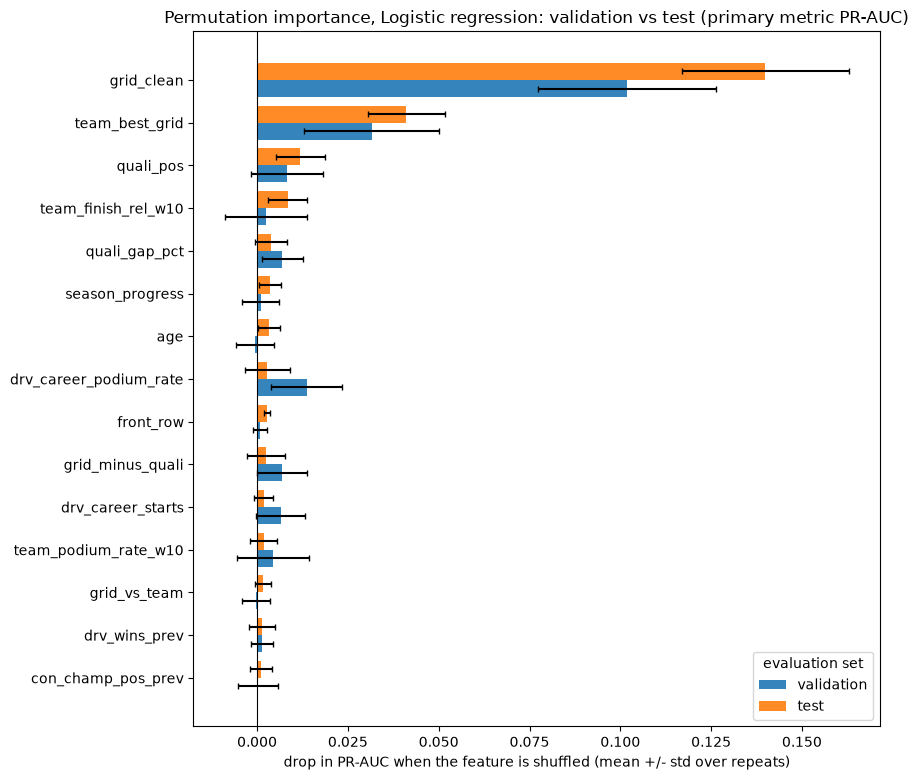

Rank agreement validation vs test: Spearman over all 29 features 0.51 | over the top-10 union (14 features) 0.42 | top-10 overlap 6 of 10
Top-5 shared: ['grid_clean', 'quali_gap_pct', 'quali_pos', 'team_best_grid']


In [11]:
# Figure helpers (save_fig, share_heatmap, plot_perm), then the permutation-importance chart for validation vs test and a ranking-agreement check.
#  Every figure is saved to figures_xai/ and also shown inline. The agreement check
#  quantifies whether the feature ranking is trustworthy rather than leaving that to eyeballing the bars.
def save_fig(fig, name):
    path = os.path.join(FIG_DIR, name); fig.savefig(path, dpi=150, bbox_inches="tight"); print("Saved figure:", path); plt.show()

# heatmap of per-model importance shares (one column per model); used for permutation importance (15.3.2) and exact SHAP (15.6.2)
def share_heatmap(share, rows, cmap, title, cbar_label, fname):
    vals = share.loc[rows].to_numpy()
    fig, ax = plt.subplots(figsize=(1.3 * share.shape[1] + 4, 0.42 * len(rows) + 1.5))
    im = ax.imshow(vals, cmap=cmap, aspect="auto", vmin=0)
    ax.set_xticks(range(share.shape[1])); ax.set_xticklabels(share.columns, rotation=20, ha="right"); ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows)
    for (i, j), v in np.ndenumerate(vals): ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if v > vals.max() * 0.6 else "black")
    ax.set_title(title); plt.colorbar(im, label=cbar_label); fig.tight_layout(); save_fig(fig, fname)

def plot_perm(pi_dict, title, metric="pr_auc", top=TOP_K):
    key = f"{metric}_drop"; ref = list(pi_dict.values())[-1]
    order = ref.sort_values(key, ascending=False).head(top)["feature"].tolist()[::-1]
    fig, ax = plt.subplots(figsize=(9, 0.42 * top + 1.6)); h = 0.8 / len(pi_dict)
    for j, (lab, pi) in enumerate(pi_dict.items()):
        s = pi.set_index("feature").loc[order]
        ax.barh(np.arange(len(order)) + (j - (len(pi_dict) - 1) / 2) * h, s[key], h, xerr=s[f"{metric}_std"], capsize=2, label=lab,
                color=[group_colors[group_of[f]] for f in order] if len(pi_dict) == 1 else None, alpha=0.9)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.axvline(0, color="k", lw=0.8)
    ax.set_xlabel(f"drop in {metric.replace('_', '-').upper()} when the feature is shuffled (mean +/- std over repeats)"); ax.set_title(title)
    if len(pi_dict) > 1: ax.legend(title="evaluation set")
    else:
        ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for g, c in group_colors.items() if g in {group_of[f] for f in order}],
                  labels=[g for g in group_colors if g in {group_of[f] for f in order}], fontsize=8, loc="lower right")
    fig.tight_layout(); return fig

save_fig(plot_perm(PI, f"Permutation importance, {LABEL[EXPLAIN_KEY]}: validation vs test (primary metric PR-AUC)"), "perm_importance_val_test.png")

# do the two evaluation sets agree on the ranking?
# do validation and test agree on which features matter?
AG_VT = agreement(PI["validation"].set_index("feature")["pr_auc_drop"], PI["test"].set_index("feature")["pr_auc_drop"])
print(f"Rank agreement validation vs test: Spearman over all {len(FEATURES)} features {AG_VT['spearman_all']:.2f} | over the top-10 union ({AG_VT['n_union']} features) {AG_VT['spearman_top']:.2f} | top-10 overlap {AG_VT['overlap_top']} of 10")
top_v, top_t = (set(PI[s].sort_values("pr_auc_drop", ascending=False).head(5)["feature"]) for s in ("validation", "test"))
print(f"Top-5 shared: {sorted(top_v & top_t)}")

### 6.3.1 Feature groups (shuffling a whole group at once)

Single-feature importance understates features that have close substitutes. Here every column of a group is shuffled with the **same row permutation** (so the group stays internally consistent but is decoupled from the target and from the other groups). This is the explanation-side counterpart of the feature-group ablation: permutation measures how much the *fitted* model uses a group, ablation measures how much a model *retrained* without the group loses. They can disagree, because a retrained model can compensate with other groups.

,group,n_features,pr_auc_drop,pr_auc_std,roc_auc_drop,roc_auc_std,sum_of_single_feature_drops,group_minus_sum
0,grid,6,0.2807,0.0287,0.1439,0.0144,0.1853,0.0954
1,driver_form,4,0.0327,0.0138,0.0082,0.0028,0.0029,0.0297
2,constructor_form,2,0.0242,0.0081,0.0068,0.0022,0.0102,0.0140
3,standings,6,0.0218,0.0090,0.0048,0.0017,0.0025,0.0193
4,qualifying,4,0.0193,0.0099,0.0019,0.0022,0.0187,0.0006
5,context,4,0.0066,0.0039,0.0013,0.0008,0.0065,0.0002
6,circuit_history,3,-0.0003,0.0013,-0.0000,0.0003,-0.0010,0.0008


group_minus_sum > 0 means the group matters more than its features' separate drops add up to (the features are substitutes for each other).
Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\perm_importance_groups.png


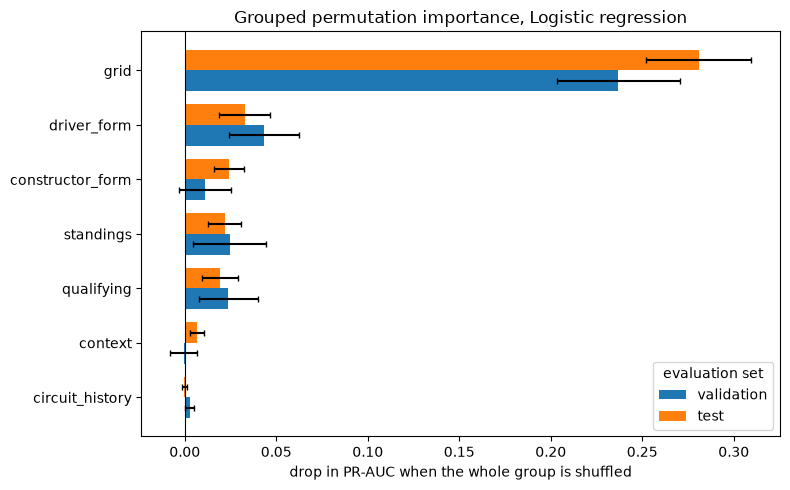

In [12]:
# Permutation importance for whole feature groups (grid, qualifying, standings, ...), compared with the sum
# of single-feature drops.
# Correlated features (e.g. grid_clean and quali_pos) hide each other when shuffled one at a time.
#   Shuffling a whole group measures what the group contributes and matches the grouping used by the
#   ablation experiment.

def grouped_perm(m, d, groups, n_repeats=N_REPEATS, seed=SEED):
    rng = np.random.default_rng(seed); y = d[TARGET].to_numpy()
    X0 = d[FEATURES]
    score = lambda X: (average_precision_score(y, m.predict_proba(X)[:, 1]), roc_auc_score(y, m.predict_proba(X)[:, 1]))
    b_pr, b_roc = score(X0); rows = []
    for g, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            # one shared row permutation for the whole group keeps it internally consistent but decouples it from the target
            Xp = X0.copy(); perm = rng.permutation(len(d)); Xp[cols] = X0[cols].to_numpy()[perm]
            pr, roc = score(Xp); drops.append((b_pr - pr, b_roc - roc))
        drops = np.array(drops)
        rows.append(dict(group=g, n_features=len(cols), pr_auc_drop=drops[:, 0].mean(), pr_auc_std=drops[:, 0].std(),
                         roc_auc_drop=drops[:, 1].mean(), roc_auc_std=drops[:, 1].std()))
    return pd.DataFrame(rows).sort_values("pr_auc_drop", ascending=False).reset_index(drop=True)

GPI = {sp: grouped_perm(model, d, FEATURE_GROUPS) for sp, d in (("validation", val), ("test", test))}
# sum of the single-feature drops, to compare with the group drop
single_sum = PI["test"].groupby("group")["pr_auc_drop"].sum()
GROUP_PI_TABLE = GPI["test"].assign(sum_of_single_feature_drops=lambda t: t["group"].map(single_sum))
# positive = the features in the group substitute for each other (redundancy)
GROUP_PI_TABLE["group_minus_sum"] = GROUP_PI_TABLE["pr_auc_drop"] - GROUP_PI_TABLE["sum_of_single_feature_drops"]
display(GROUP_PI_TABLE.round(4))
print("group_minus_sum > 0 means the group matters more than its features' separate drops add up to (the features are substitutes for each other).")

fig, ax = plt.subplots(figsize=(8, 0.5 * len(FEATURE_GROUPS) + 1.5)); h = 0.38
order = GPI["test"].sort_values("pr_auc_drop")["group"].tolist()
for j, sp in enumerate(["validation", "test"]):
    s = GPI[sp].set_index("group").loc[order]
    ax.barh(np.arange(len(order)) + (j - 0.5) * h, s["pr_auc_drop"], h, xerr=s["pr_auc_std"], capsize=2, label=sp)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.axvline(0, color="k", lw=0.8); ax.legend(title="evaluation set")
ax.set_xlabel("drop in PR-AUC when the whole group is shuffled"); ax.set_title(f"Grouped permutation importance, {LABEL[EXPLAIN_KEY]}")
fig.tight_layout(); save_fig(fig, "perm_importance_groups.png")

### 6.3.2 The same analysis for every verified model

If the same features come out on top for a linear model, a forest, boosting and a network, the finding is about the data and less about one fitted model. The identical permutation protocol is run on **every model that passed the verification in Part 1**, on both validation and test rows (the explained model keeps its full repeat count).

permutation importance for 4 verified models in 86s: ['Logistic regression', 'Shallow NN', 'Random forest', 'XGBoost']
Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\perm_importance_cross_model.png


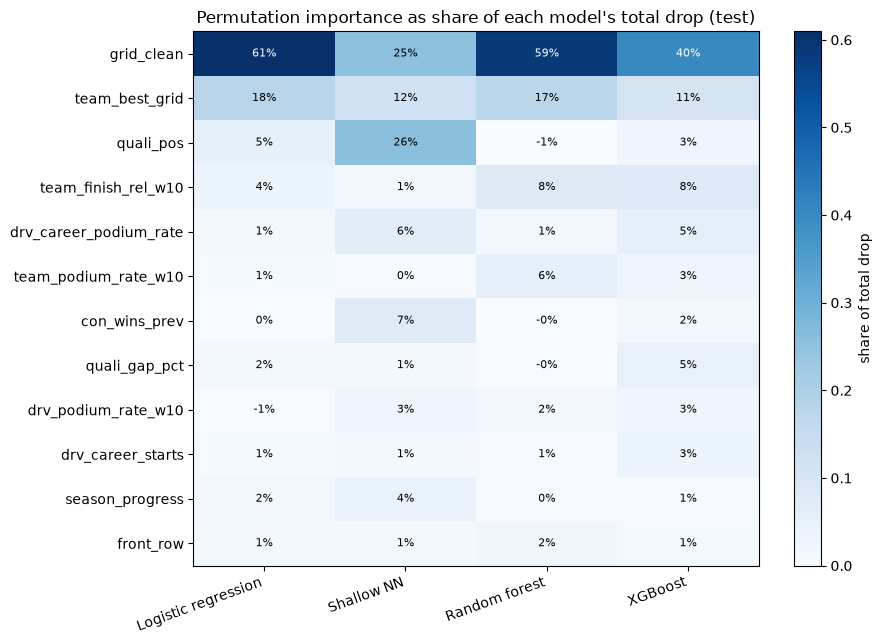

,model,test_pr_auc,reliably_used_features,top3_by_permutation,top_group
0,Logistic regression,0.7218,3,"grid_clean, team_best_grid, quali_pos",grid
1,Shallow NN,0.6897,5,"quali_pos, grid_clean, team_best_grid",grid
2,Random forest,0.7184,2,"grid_clean, team_best_grid, team_finish_rel_w10",grid
3,XGBoost,0.7208,9,"grid_clean, team_best_grid, team_finish_rel_w10",grid


Pairwise rank agreement of the permutation importances (Spearman over the union of each pair's top-10 features):


,Logistic regression,Shallow NN,Random forest,XGBoost
Logistic regression,1.00,0.27,0.10,0.49
Shallow NN,0.27,1.00,-0.10,0.08
Random forest,0.10,-0.10,1.00,0.34
XGBoost,0.49,0.08,0.34,1.00


Pairwise number of shared features in the top 10:


,Logistic regression,Shallow NN,Random forest,XGBoost
Logistic regression,10,5,5,6
Shallow NN,5,10,5,4
Random forest,5,5,10,6
XGBoost,6,4,6,10


Logistic regression vs the other verified models: Shallow NN 0.27 (top-10 overlap 5), Random forest 0.10 (top-10 overlap 5), XGBoost 0.49 (top-10 overlap 6)


In [13]:
# Run the same permutation analysis for every verified model and compare them.
# If only one model is explained, a finding may be a quirk of that model. Agreement across the
#  linear model, forest, boosting and network indicates a property of the data.

PI_ALL = {}                                   # key -> {"validation": table, "test": table}
t0 = time.time()
for key, m in MODELS.items():
    # reuse the full-repeat result for the explained model
    if key == EXPLAIN_KEY: PI_ALL[key] = PI
    else: PI_ALL[key] = {sp: perm_importance(m, d, n_repeats=N_REPEATS_CROSS) for sp, d in (("validation", val), ("test", test))}
print(f"permutation importance for {len(MODELS)} verified models in {time.time()-t0:.0f}s: {[LABEL[k] for k in MODELS]}")

cross_mat = pd.DataFrame({LABEL[k]: v["test"].set_index("feature")["pr_auc_drop"] for k, v in PI_ALL.items()}).loc[FEATURES]
top_feats = cross_mat.mean(axis=1).sort_values(ascending=False).head(12).index.tolist()
# normalise to shares so models with different score scales can be compared
share = cross_mat / cross_mat.clip(lower=0).sum()          # each model's importances as a share of its own total drop
share_heatmap(share, top_feats, "Blues", "Permutation importance as share of each model's total drop (test)", "share of total drop", "perm_importance_cross_model.png")

summ = []
for k in MODELS:
    t = PI_ALL[k]["test"].sort_values("pr_auc_drop", ascending=False)
    summ.append(dict(model=LABEL[k], test_pr_auc=check[(check["key"] == k) & (check["split"] == "test")]["pr_auc"].iloc[0], reliably_used_features=int(t["reliable"].sum()),
                     top3_by_permutation=", ".join(t.head(3)["feature"]), top_group=pd.Series(PI_ALL[k]["test"].groupby("group")["pr_auc_drop"].sum()).idxmax()))
display(pd.DataFrame(summ).round(4))

cols_ = list(cross_mat.columns)
# pairwise rank agreement between models, and the count of shared top-10 features
# agreement() runs once per ordered pair; both tables are read from the same result
pair_agree = {(a, b_): agreement(cross_mat[a], cross_mat[b_]) for a in cols_ for b_ in cols_}
rank_corr = pd.DataFrame([[pair_agree[a, b_]["spearman_top"] for b_ in cols_] for a in cols_], index=cols_, columns=cols_)
overlap = pd.DataFrame([[pair_agree[a, b_]["overlap_top"] for b_ in cols_] for a in cols_], index=cols_, columns=cols_)
print("Pairwise rank agreement of the permutation importances (Spearman over the union of each pair's top-10 features):"); display(rank_corr.round(2))
print("Pairwise number of shared features in the top 10:"); display(overlap)
others = [c for c in rank_corr.columns if c != LABEL[EXPLAIN_KEY]]
if others:
    print(f"{LABEL[EXPLAIN_KEY]} vs the other verified models: " + ", ".join(f"{c} {rank_corr.loc[LABEL[EXPLAIN_KEY], c]:.2f} (top-10 overlap {overlap.loc[LABEL[EXPLAIN_KEY], c]})" for c in others))

## 6.4 Does the explanation depend on the random seed of the network?

The final model (logistic regression) is deterministic, but the shallow network is one of the compared models, and a network started from a different random seed can reach a similar score through different internal weights. The saved network is retrained with three seeds using the identical recipe (train rows only, early stopping on validation), and the permutation importance rankings are compared. High rank agreement means the network's explanation is a property of the data and features; low agreement means a single network's explanation should be reported with that caveat.

In [14]:
# Retrain the network with three random seeds and compare their permutation rankings.
# A network's explanation could depend on its random initialisation. If rankings differ a lot
#   between seeds, one network's explanation must not be over-interpreted. Seed 42 is the saved
#   network's own seed: it serves as the reproduction check and as one of the three compared runs.
SEED_RANK, SEED_AGREE, SEED_REPRODUCED = None, None, None   # SEED_REPRODUCED: did the seed-42 retrain match the saved model?
if RUN_SEED_CHECK and EXPLAIN_KEY == "nn":
    prm = META["nn"]["params"]; seed_pi, seed_rows = {}, []
    t0 = time.time()
    # identical recipe, different random seed
    for s in [SEED, SEED + 1, SEED + 2]:
        net_s, best_val = train_nn_pipeline(hidden=tuple(prm["hidden"]), alpha=prm["alpha"], lr=prm.get("lr", 1e-3), seed=s)
        seed_pi[s] = perm_importance(net_s, test, n_repeats=N_REPEATS_CROSS)
        seed_rows.append(dict(seed=s, val_pr_auc=best_val, test_pr_auc=average_precision_score(test[TARGET], predict_p(net_s, test))))
    print(f"3 retrained networks in {time.time()-t0:.0f}s")
    display(pd.DataFrame(seed_rows).round(4))
    saved_val = META["nn"].get("val", {}).get("pr_auc")
    # seed 42 must reproduce the saved model (same recipe, same seed); if not, this environment differs from the training one
    if saved_val is not None:
        SEED_REPRODUCED = abs(seed_rows[0]['val_pr_auc'] - saved_val) < 1e-4
        print(f"Reproduction check: retraining with seed {SEED} gives validation PR-AUC {seed_rows[0]['val_pr_auc']:.4f}; the saved model's is {saved_val:.4f} "
              f"({'identical' if abs(seed_rows[0]['val_pr_auc'] - saved_val) < 1e-4 else 'different: library versions or row order differ from the training environment'}).")
    SEED_RANK = pd.DataFrame({f"seed {s}": v.set_index("feature")["pr_auc_drop"] for s, v in seed_pi.items()})
    pair_rows = [dict(pair=f"{a} vs {b_}", **agreement(SEED_RANK[a], SEED_RANK[b_])) for a, b_ in itertools.combinations(SEED_RANK.columns, 2)]
    SEED_AGREE = pd.DataFrame(pair_rows); display(SEED_AGREE.round(2))
    tops = {c: set(SEED_RANK[c].sort_values(ascending=False).head(5).index) for c in SEED_RANK.columns}
    # features in the top 5 of every run = the stable core
    common = set.intersection(*tops.values())
    print("Top-5 features per run:", {c: sorted(v) for c, v in tops.items()})
    print(f"Features in the top 5 of every run: {sorted(common)} ({len(common)} of 5)")
    fig, ax = plt.subplots(figsize=(9, 0.38 * TOP_K + 1.5)); order = SEED_RANK[f"seed {SEED}"].sort_values(ascending=False).head(TOP_K).index[::-1]
    cols = list(SEED_RANK.columns); h = 0.8 / len(cols)
    for j, c in enumerate(cols): ax.barh(np.arange(len(order)) + (j - (len(cols) - 1) / 2) * h, SEED_RANK.loc[order, c], h, label=c)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.axvline(0, color="k", lw=0.8); ax.legend(fontsize=8)
    ax.set_xlabel("drop in test PR-AUC"); ax.set_title("Permutation importance across network seeds"); fig.tight_layout(); save_fig(fig, "perm_importance_seeds.png")
else:
    print("Seed check skipped (RUN_SEED_CHECK is off or the explained model is not the shallow network).")

Seed check skipped (RUN_SEED_CHECK is off or the explained model is not the shallow network).


## 6.5 Global explanation 2: SHAP

SHAP assigns each feature a signed contribution to every single prediction, such that **reference average + sum of contributions = the model's score for that row** (checked numerically below). Averaging the absolute contributions over rows gives a global importance; plotting the signed contributions against the feature value shows the direction and shape of the model's reliance.

The explained model sits behind a preprocessing pipeline (imputation, missing indicators, scaling), so the model-agnostic **permutation explainer** is used, applied to the *raw 29 features* (the pipeline's imputation and missing indicators are part of the function being explained). It is run on every test row, with 100 hybrid-era training rows as the reference.

In [15]:
# Choose the SHAP reference data, build the explainer, compute SHAP values for every test row and check that
#          they add up.
#SHAP splits each prediction into a signed contribution per feature, relative to a reference
#    population. The reference choice, and the additivity check (base value + contributions = model
#    score), are what make the numbers interpretable and verifiable.


# ---- reference data, explainer and SHAP values for every test row ------------------------------------------------
# reference population: recent training seasons with full qualifying data; no validation or test rows
bg_pool = train[train["year"] >= BACKGROUND_FROM_YEAR]
if len(bg_pool) < 300:
    print(f"only {len(bg_pool)} training rows from {BACKGROUND_FROM_YEAR}; using validation rows as the reference instead"); bg_pool = val
bg_df = bg_pool.sample(min(BACKGROUND_SIZE, len(bg_pool)), random_state=SEED)[FEATURES]
bg_arr = bg_df.to_numpy(float)
print(f"reference data: {len(bg_df)} rows sampled from {len(bg_pool):,} training rows of seasons {int(bg_pool['year'].min())}-{int(bg_pool['year'].max())}")

# wrapper: SHAP passes numpy arrays but the pipeline needs a DataFrame with named columns
def xai_proba(X): return model.predict_proba(pd.DataFrame(X, columns=FEATURES))
def xai_f(X): return xai_proba(X)[:, 1]

# rows to explain: every test row by default
ex = (test if N_EXPLAIN is None else test.sample(min(N_EXPLAIN, len(test)), random_state=SEED)).reset_index(drop=True)
X_ex = ex[FEATURES].to_numpy(float)

# model-agnostic permutation explainer on the raw 29 features (the pipeline's imputation is part of the explained function)
def run_shap(bg, X, n_perm=N_PERMUTATIONS):
    masker = shap.maskers.Independent(bg, max_samples=len(bg))
    explainer = shap.explainers.Permutation(xai_f, masker, feature_names=FEATURES, seed=SEED)
    # each pass runs forward and backward through a random feature order, which keeps contributions exactly additive
    return explainer(X, max_evals=2 * len(FEATURES) * n_perm + 1, silent=True)

t0 = time.time()
sv = run_shap(bg_arr, X_ex)
sv.feature_names = list(FEATURES)
# model scores of the explained rows: the gate's test predictions when every test row is explained, otherwise scored for the subset
p_ex = PRED[EXPLAIN_KEY]["test"] if N_EXPLAIN is None else xai_f(X_ex)
add_err = float(np.abs(sv.values.sum(1) + sv.base_values - p_ex).max())
print(f"SHAP for {len(ex):,} rows x {len(FEATURES)} features in {time.time()-t0:.0f}s")
print(f"additivity check, max |base + sum(SHAP) - model score| = {add_err:.2e}")
# hard check: base value + sum of contributions must equal the model score
assert add_err < 1e-6, "SHAP values do not add up to the model output"
# the base value is the reference's average score, not the true podium rate (class up-weighting inflates scores)
base_val = float(np.mean(sv.base_values))
print(f"reference average score (SHAP base value) = {base_val:.3f}  vs true podium rate in test = {ex[TARGET].mean():.3f} "
      f"(the model is trained with up-weighted podiums, so its scores average above the true rate: scores are for ranking, not calibrated probabilities)")

# global importance = mean absolute SHAP per feature (size of the push, regardless of direction)
shap_tab = pd.DataFrame({"feature": FEATURES, "group": [group_of[f] for f in FEATURES],
                         "mean_abs_shap": np.abs(sv.values).mean(0), "mean_shap": sv.values.mean(0)}).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
shap_tab["share_of_total"] = shap_tab["mean_abs_shap"] / shap_tab["mean_abs_shap"].sum()
display(shap_tab.head(TOP_K).round(4))

reference data: 100 rows sampled from 2,470 training rows of seasons 2014-2019
SHAP for 1,351 rows x 29 features in 60s
additivity check, max |base + sum(SHAP) - model score| = 1.99e-09
reference average score (SHAP base value) = 0.378  vs true podium rate in test = 0.151 (the model is trained with up-weighted podiums, so its scores average above the true rate: scores are for ranking, not calibrated probabilities)


,feature,group,mean_abs_shap,mean_shap,share_of_total
0,grid_clean,grid,0.1093,-0.0201,0.2644
1,team_best_grid,grid,0.0583,-0.0034,0.1411
2,team_finish_rel_w10,constructor_form,0.0281,-0.0046,0.0681
3,quali_pos,qualifying,0.0250,-0.0037,0.0605
4,drv_podium_rate_w10,driver_form,0.0221,-0.0032,0.0535
5,drv_career_podium_rate,driver_form,0.0196,-0.0039,0.0474
6,team_podium_rate_w10,constructor_form,0.0195,-0.0038,0.0471
7,quali_gap_pct,qualifying,0.0176,0.0081,0.0425
8,con_pts_share_prev,standings,0.0115,-0.0017,0.0279
9,con_champ_pos_prev,standings,0.0113,-0.0012,0.0273


Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_bar.png


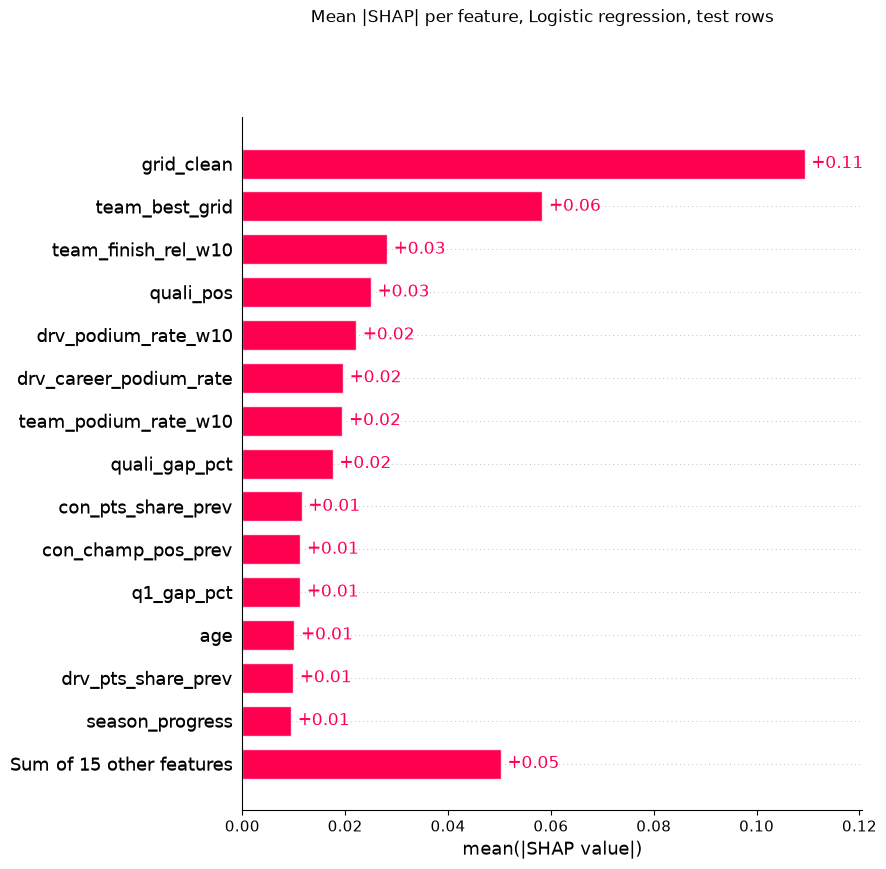

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_beeswarm.png


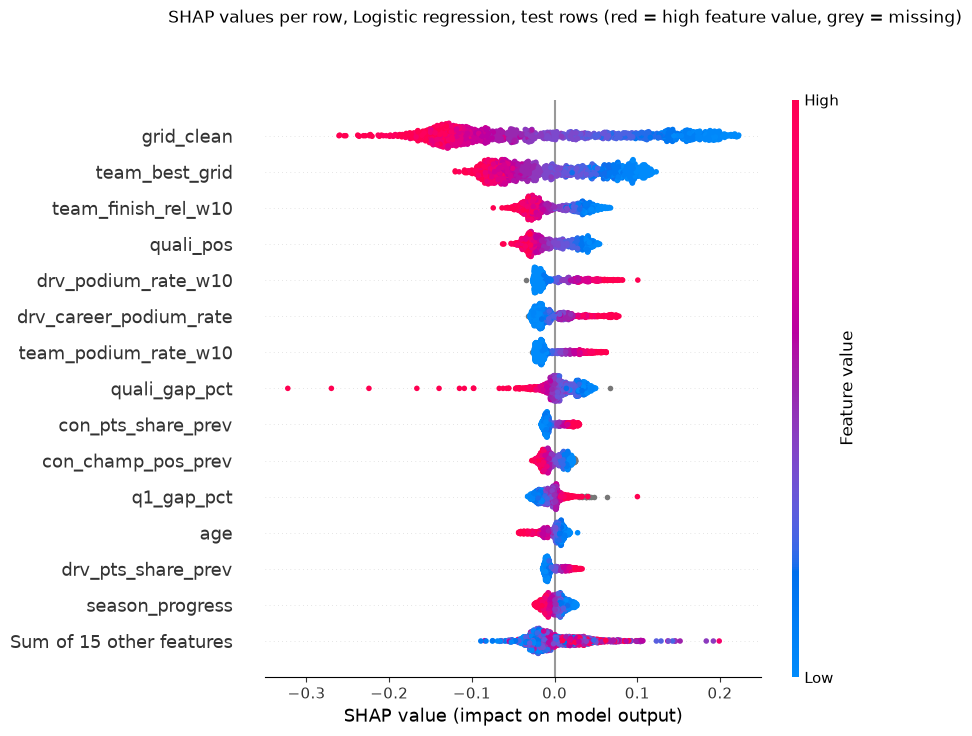

In [16]:
# Draw the two standard global SHAP summaries.
# The bar chart ranks features by average push on the score; the beeswarm adds direction (colour = feature value) and spread per row.
# bar (mean |SHAP|) and beeswarm (signed SHAP coloured by feature value; grey = missing value)
plt.figure(); shap.plots.bar(sv, max_display=TOP_K, show=False); fig = plt.gcf()
fig.suptitle(f"Mean |SHAP| per feature, {LABEL[EXPLAIN_KEY]}, test rows", y=1.0); save_fig(fig, "shap_bar.png")
plt.figure(); shap.plots.beeswarm(sv, max_display=TOP_K, show=False); fig = plt.gcf()
fig.suptitle(f"SHAP values per row, {LABEL[EXPLAIN_KEY]}, test rows (red = high feature value, grey = missing)", y=1.0); save_fig(fig, "shap_beeswarm.png")

### 6.5.1 Group SHAP

SHAP values are additive, so the contribution of a feature group to a row is simply the sum of its members' values. This is immune to the credit-splitting problem between correlated features inside a group, and it matches the grouping used by the ablation.

,group,n_features,mean_abs_group_shap,mean_signed,share_of_total
0,grid,6,0.1662,-0.0241,0.4684
1,constructor_form,2,0.0470,-0.0085,0.1325
2,driver_form,4,0.0459,-0.0046,0.1294
3,standings,6,0.0404,-0.0058,0.1140
4,qualifying,4,0.0368,-0.0016,0.1036
5,context,4,0.0134,-0.0005,0.0379
6,circuit_history,3,0.0050,-0.0006,0.0141


Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_groups.png


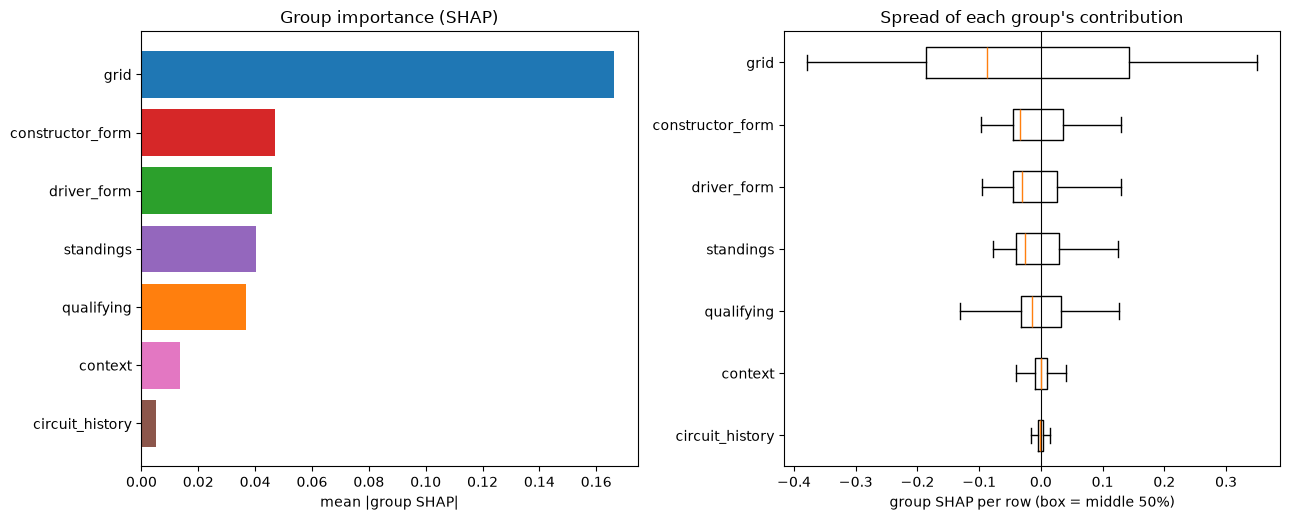

In [17]:
# Sum SHAP values within each feature group and plot group importance and spread.
# SHAP values are additive, so a group's contribution is the sum of its members'. This is immune to
#    the credit-splitting between correlated features and uses the same groups as the ablation.
gidx = {g: [FEATURES.index(f) for f in fs] for g, fs in FEATURE_GROUPS.items()}
# a group's contribution to a row = the sum of its members' SHAP values
G = pd.DataFrame({g: sv.values[:, ix].sum(1) for g, ix in gidx.items()})
group_shap = pd.DataFrame({"group": list(G.columns), "n_features": [len(FEATURE_GROUPS[g]) for g in G.columns],
                           "mean_abs_group_shap": G.abs().mean().values, "mean_signed": G.mean().values}).sort_values("mean_abs_group_shap", ascending=False).reset_index(drop=True)
group_shap["share_of_total"] = group_shap["mean_abs_group_shap"] / group_shap["mean_abs_group_shap"].sum()
display(group_shap.round(4))
order = group_shap.sort_values("mean_abs_group_shap")["group"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 0.5 * len(order) + 1.8))
axes[0].barh(order, group_shap.set_index("group").loc[order, "mean_abs_group_shap"], color=[group_colors[g] for g in order])
axes[0].set_xlabel("mean |group SHAP|"); axes[0].set_title("Group importance (SHAP)")
_bp = [G[g] for g in order]
# matplotlib renamed the boxplot orientation argument across versions: try newest to oldest
for _kw in (dict(orientation="horizontal", tick_labels=order), dict(vert=False, tick_labels=order), dict(vert=False, labels=order)):   # newest to oldest matplotlib
    try: axes[1].boxplot(_bp, showfliers=False, **_kw); break
    except TypeError: continue
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set_xlabel("group SHAP per row (box = middle 50%)"); axes[1].set_title("Spread of each group's contribution")
fig.tight_layout(); save_fig(fig, "shap_groups.png")

### 6.5.2 Dependence plots for the four most important features

Each dot is one test row. The vertical axis is how much the feature moved that row's score; colour is the feature that interacts most with it (chosen automatically). These show the *shape* of the model's reliance, for example whether the effect of the starting slot is a smooth decline or a cliff after the front rows. They describe the model, not the sport.

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_dependence_top4.png


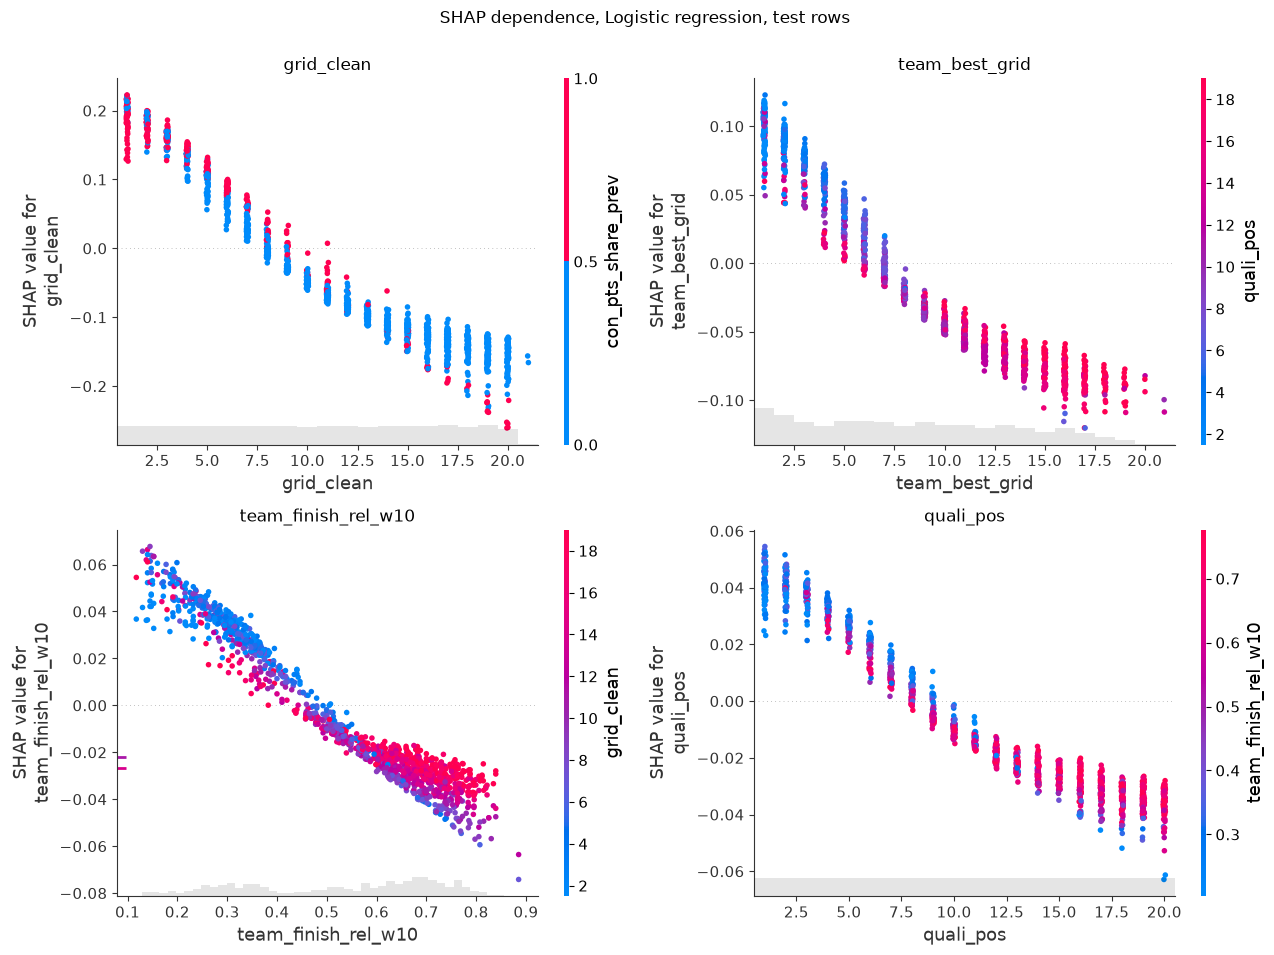

In [18]:
# Dependence plots for the four most important features.
# They show the shape of the model's reliance (smooth decline, cliff, interaction) that a single
# importance number hides. They describe the model, not the sport.
# --------------------------------------------------------------------------------------------------------------------
top4 = shap_tab.head(4)["feature"].tolist()
try:
    fig, axes = plt.subplots(2, 2, figsize=(13, 9.5))
    for ax, f in zip(axes.ravel(), top4):
        # colour = the feature that interacts most with this one (chosen automatically)
        shap.plots.scatter(sv[:, f], color=sv, ax=ax, show=False); ax.set_title(f)
    fig.suptitle(f"SHAP dependence, {LABEL[EXPLAIN_KEY]}, test rows", y=1.0); fig.tight_layout(); save_fig(fig, "shap_dependence_top4.png")
except TypeError:      # older shap versions have no ax= argument: one figure per feature
    plt.close("all")
    for f in top4:
        plt.figure(); shap.plots.scatter(sv[:, f], color=sv, show=False); save_fig(plt.gcf(), f"shap_dependence_{f}.png")

### 6.5.3 Do permutation importance and SHAP tell the same story?

They measure different things: permutation importance is the **loss in performance** from destroying a feature; mean |SHAP| is the **average size of the feature's push** on predictions, whether or not the push is right. A feature can move scores a lot and still add little accuracy (a noisy feature the model leans on), so disagreement is informative, not an error.

Permutation vs SHAP: Spearman over all 29 features 0.63 | over the top-10 union (14 features) 0.52 | top-10 overlap 6 of 10 | top-5 shared: ['grid_clean', 'quali_pos', 'team_best_grid', 'team_finish_rel_w10']


,perm_pr_auc_drop,mean_abs_shap,perm_rank,shap_rank,rank_gap
feature,,,,,
grid_clean,0.1399,0.1093,1,1,0
team_best_grid,0.0411,0.0583,2,2,0
team_finish_rel_w10,0.0084,0.0281,4,3,1
quali_pos,0.0119,0.0250,3,4,-1
drv_podium_rate_w10,-0.0012,0.0221,29,5,24
drv_career_podium_rate,0.0029,0.0196,8,6,2
team_podium_rate_w10,0.0018,0.0195,12,7,5
quali_gap_pct,0.0039,0.0176,5,8,-3
con_pts_share_prev,0.0007,0.0115,16,9,7


Features whose two ranks differ by 8 places or more: {'front_row': (9, 22), 'season_progress': (6, 14), 'drv_pts_share_prev': (28, 13), 'drv_podium_rate_w10': (29, 5)}
Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\perm_vs_shap.png


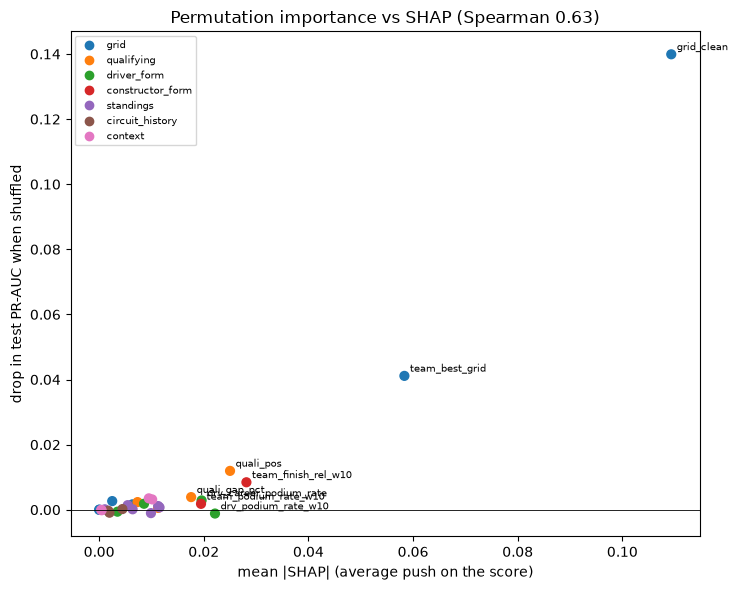

In [19]:
# Compare permutation importance with SHAP importance feature by feature.
# The two measure different things (accuracy lost vs size of push). A feature ranked high by SHAP
#    but low by permutation is one the model pushes on without that push improving test accuracy, a
#    candidate for noise or redundancy.
cmp = pd.DataFrame({"perm_pr_auc_drop": PI["test"].set_index("feature")["pr_auc_drop"],
                    "mean_abs_shap": shap_tab.set_index("feature")["mean_abs_shap"]}).loc[FEATURES]
cmp["perm_rank"] = cmp["perm_pr_auc_drop"].rank(ascending=False, method="min").astype(int)
cmp["shap_rank"] = cmp["mean_abs_shap"].rank(ascending=False, method="min").astype(int)
# positive = SHAP ranks the feature much higher than permutation does
cmp["rank_gap"] = cmp["perm_rank"] - cmp["shap_rank"]
AG_PS = agreement(cmp["perm_pr_auc_drop"], cmp["mean_abs_shap"]); rho_ps = AG_PS["spearman_all"]
tp, ts = (set(cmp.sort_values(c_, ascending=True).head(5).index) for c_ in ("perm_rank", "shap_rank"))
print(f"Permutation vs SHAP: Spearman over all {len(cmp)} features {AG_PS['spearman_all']:.2f} | over the top-10 union ({AG_PS['n_union']} features) {AG_PS['spearman_top']:.2f} | "
      f"top-10 overlap {AG_PS['overlap_top']} of 10 | top-5 shared: {sorted(tp & ts)}")
display(cmp.sort_values("shap_rank").head(TOP_K).round(4))
# list the features on which the two measures disagree strongly
big_gap = cmp[cmp["rank_gap"].abs() >= 8].sort_values("rank_gap")
print("Features whose two ranks differ by 8 places or more:", {f: (int(r.perm_rank), int(r.shap_rank)) for f, r in big_gap.iterrows()} or "none")

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.scatter(cmp["mean_abs_shap"], cmp["perm_pr_auc_drop"], c=[group_colors[group_of[f]] for f in cmp.index], s=40)
for f in cmp.sort_values("shap_rank").head(8).index: ax.annotate(f, (cmp.loc[f, "mean_abs_shap"], cmp.loc[f, "perm_pr_auc_drop"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
ax.axhline(0, color="k", lw=0.6); ax.set_xlabel("mean |SHAP| (average push on the score)"); ax.set_ylabel("drop in test PR-AUC when shuffled")
ax.set_title(f"Permutation importance vs SHAP (Spearman {rho_ps:.2f})")
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=g) for g, c in group_colors.items()], fontsize=7); fig.tight_layout(); save_fig(fig, "perm_vs_shap.png")

## 6.6 Sensitivity checks

### 6.6.1 How much does the SHAP reference data matter?

The same explanation is recomputed on a random 300-row subset of the test rows with three different reference samples: the default (hybrid-era training rows), a random sample of **all** training eras, and the validation rows. If the importance ranking barely moves, the reference choice is not driving the conclusions; the base value will move, because it is the average score of the reference.

In [20]:
# Recompute SHAP on a 300-row subset under three different reference datasets.
# SHAP is relative to its reference. If the importance ranking changes a lot with the reference, the
#     conclusions are artefacts of that choice. A subset keeps the runtime manageable.
# fixed random 300-row subset of the explained rows (reproducible)
sub_pos = np.random.default_rng(SEED).choice(len(ex), size=min(300, len(ex)), replace=False)
X_sub = X_ex[sub_pos]
# three plausible references: the default, the whole training history, the validation rows
BG = {"hybrid-era train (default)": bg_arr,
      "all-era train (random)": train.sample(min(BACKGROUND_SIZE, len(train)), random_state=SEED)[FEATURES].to_numpy(float),
      "validation": val.sample(min(BACKGROUND_SIZE, len(val)), random_state=SEED)[FEATURES].to_numpy(float)}
bg_imp, bg_base = {}, {}
t0 = time.time()
for name, b in BG.items():
    s_ = run_shap(b, X_sub); bg_imp[name] = np.abs(s_.values).mean(0); bg_base[name] = float(s_.base_values.mean())
print(f"3 reference choices on {len(X_sub)} rows in {time.time()-t0:.0f}s")
bg_imp = pd.DataFrame(bg_imp, index=FEATURES)
display(pd.Series(bg_base, name="base value (average score of the reference)").round(3).to_frame())
display(bg_imp.corr(method="spearman").round(3))
bg_tops = {c: set(bg_imp[c].sort_values(ascending=False).head(5).index) for c in bg_imp.columns}
print("Top-5 features per reference:", {c: sorted(v) for c, v in bg_tops.items()})
print(f"In the top 5 under every reference: {sorted(set.intersection(*bg_tops.values()))}")
# worst-case agreement between references; used in the written conclusion
BG_MIN_RHO = float(bg_imp.corr(method="spearman").to_numpy()[np.triu_indices(len(BG), 1)].min())

3 reference choices on 300 rows in 37s


,base value (average score of the reference)
hybrid-era train (default),0.378
all-era train (random),0.336
validation,0.296


,hybrid-era train (default),all-era train (random),validation
hybrid-era train (default),1.000,0.945,0.994
all-era train (random),0.945,1.000,0.949
validation,0.994,0.949,1.000


Top-5 features per reference: {'hybrid-era train (default)': ['drv_podium_rate_w10', 'grid_clean', 'quali_pos', 'team_best_grid', 'team_finish_rel_w10'], 'all-era train (random)': ['grid_clean', 'q1_gap_pct', 'quali_pos', 'team_best_grid', 'team_finish_rel_w10'], 'validation': ['drv_podium_rate_w10', 'grid_clean', 'quali_pos', 'team_best_grid', 'team_finish_rel_w10']}
In the top 5 under every reference: ['grid_clean', 'quali_pos', 'team_best_grid', 'team_finish_rel_w10']


### 6.6.2 SHAP for every other verified model

Logistic regression, random forest and XGBoost have exact SHAP algorithms (linear SHAP and TreeSHAP: no sampling noise). They are applied to the models' **actual inputs** (after imputation, scaling and missing indicators), and the contributions of a feature's missing-indicator column are added back to the feature itself, so the result is again one number per raw feature per row. The network has no exact algorithm, so it gets the same sampled permutation explainer on the raw features. Each result is checked for additivity against the model's own output. Output spaces differ (log-odds for the linear model and XGBoost, probability for the forest and network), so **only rankings and shapes are comparable across models, not magnitudes**.

In [21]:
# Exact SHAP (linear SHAP, TreeSHAP) for the logistic regression, random forest and XGBoost, mapped back to the 29 raw features.
# Every verified model gets analysed, not only the network. Exact algorithms have no sampling noise;
#   mapping imputed and missing-indicator columns back to their raw feature makes the results
#   comparable with the network's.
def transformed_names(pre):
    # raw-feature name of every column the fitted ColumnTransformer outputs (imputed features, then missing indicators, per block)
    names = []
    for nm, trans, cols in pre.transformers_:
        if isinstance(trans, str) and trans == "drop": continue
        cols = list(cols); names += cols
        if isinstance(trans, str): continue                                  # passthrough
        imp = trans.named_steps["imp"] if isinstance(trans, Pipeline) and "imp" in trans.named_steps else trans
        ind = getattr(imp, "indicator_", None)
        # missing-indicator columns belong to the raw feature that had the gap
        if ind is not None: names += [cols[j] for j in ind.features_]
    return names

def exact_shap(m, X_df):
    pre, clf = m.named_steps["pre"], m.named_steps["clf"]
    Xt = np.asarray(pre.transform(X_df), float); names = transformed_names(pre)
    if len(names) != Xt.shape[1]: raise RuntimeError(f"column mapping failed ({len(names)} names for {Xt.shape[1]} columns)")
    # linear SHAP on the standardised inputs (log-odds units)
    if isinstance(clf, LogisticRegression):
        ex_ = shap.LinearExplainer(clf, np.asarray(pre.transform(bg_df), float)); v = ex_.shap_values(Xt)
        ev, ref, space = float(np.ravel(ex_.expected_value)[0]), clf.decision_function(Xt), "log-odds"
    # TreeSHAP in probability units; SHAP versions return a list or a 3-d array per class, both handled
    elif isinstance(clf, RandomForestClassifier):
        ex_ = shap.TreeExplainer(clf); v = ex_.shap_values(Xt, check_additivity=False)
        v = v[1] if isinstance(v, list) else (v[..., 1] if np.ndim(v) == 3 else v)
        ev, ref, space = float(np.ravel(ex_.expected_value)[-1]), clf.predict_proba(Xt)[:, 1], "probability"
    # TreeSHAP in log-odds (margin) units
    elif HAVE_XGB and isinstance(clf, XGBClassifier):
        ex_ = shap.TreeExplainer(clf); v = ex_.shap_values(Xt)
        ev, ref, space = float(np.ravel(ex_.expected_value)[0]), clf.predict(Xt, output_margin=True), "log-odds (margin)"
    else:
        raise NotImplementedError(f"no exact SHAP algorithm wired for {type(clf).__name__}")
    v = np.asarray(v, float)
    # add up columns that share a raw feature name: one number per raw feature (exact, because SHAP is additive)
    raw = pd.DataFrame(v, columns=names).T.groupby(level=0).sum().T[FEATURES]
    # additivity error against the model's own output is returned for checking
    return dict(values=raw, space=space, base=ev, add_err=float(np.max(np.abs(ev + raw.sum(axis=1).to_numpy() - ref))))

OTHER_SHAP, rows = {}, []
for key, m in MODELS.items():
    if key == EXPLAIN_KEY: continue
    t0 = time.time()
    try:
        OTHER_SHAP[key] = exact_shap(m, ex[FEATURES])
        o = OTHER_SHAP[key]; rows.append(dict(model=LABEL[key], algorithm="exact", output_space=o["space"], max_additivity_error=o["add_err"], seconds=round(time.time() - t0, 1),
                                              result="OK" if o["add_err"] < 1e-3 else "ADDITIVITY CHECK FAILED"))
        # reject any explanation that fails its own consistency check
        if o["add_err"] >= 1e-3: del OTHER_SHAP[key]
    except Exception as e:
        rows.append(dict(model=LABEL[key], algorithm="-", output_space="-", max_additivity_error=np.nan, seconds=round(time.time() - t0, 1), result=f"not run: {type(e).__name__}: {str(e)[:80]}"))
OTHER_SHAP_STATUS = pd.DataFrame(rows); display(OTHER_SHAP_STATUS)

,model,algorithm,output_space,max_additivity_error,seconds,result
0,Shallow NN,-,-,NaN,0.0,not run: NotImplementedError: no exact SHAP algorithm wired for MLPClassifier
1,Random forest,exact,probability,8.215650e-15,5.4,OK
2,XGBoost,exact,log-odds (margin),4.573260e-06,0.1,OK


Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_cross_model.png


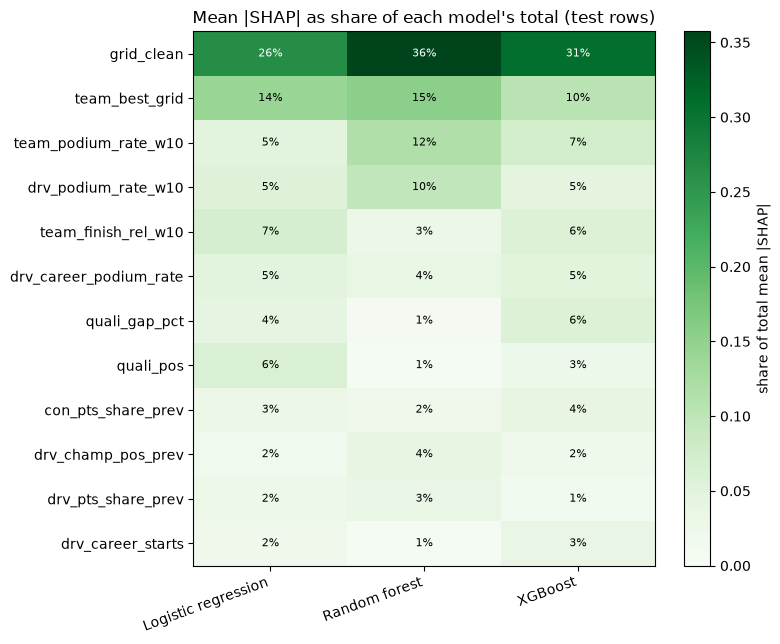

,spearman_all,spearman_top10_union,overlap_top,k,n_union
Random forest,0.73,0.46,7.0,10.0,13.0
XGBoost,0.86,0.64,8.0,10.0,12.0


Permutation importance vs SHAP, within each model:


,model,spearman_top,overlap_top
0,Logistic regression,0.52,6
1,Random forest,0.55,8
2,XGBoost,0.70,8


Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_beeswarm_rf.png


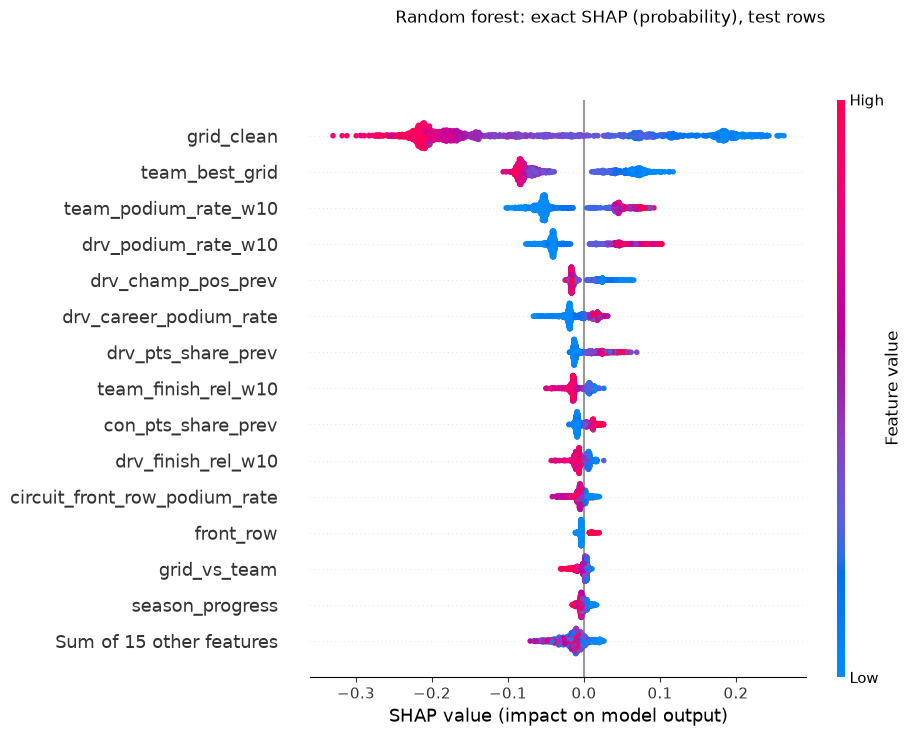

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_beeswarm_xgb.png


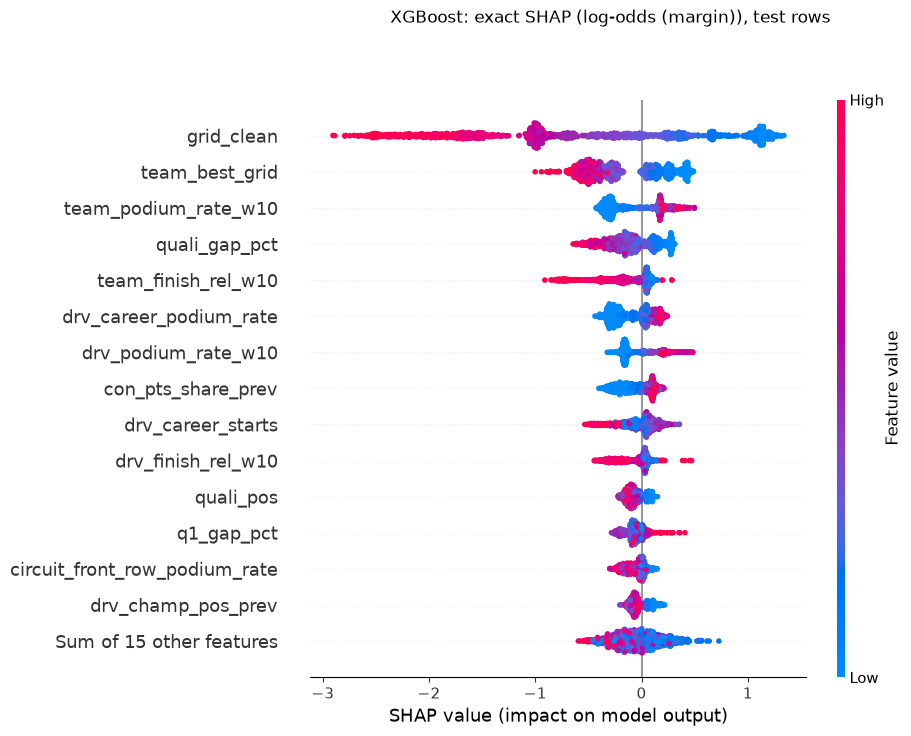

In [22]:
# Compare SHAP importance across models and plot each other model's beeswarm.
#     Output units differ between models (log-odds vs probability), so only rankings and shapes are
#     compared, using shares of each model's total.
SHAP_CROSS = pd.DataFrame({LABEL[EXPLAIN_KEY]: np.abs(sv.values).mean(0)}, index=FEATURES)
for k, o in OTHER_SHAP.items(): SHAP_CROSS[LABEL[k]] = o["values"].abs().mean().reindex(FEATURES)
AG_OTHERS = {}
if len(SHAP_CROSS.columns) > 1:
    # shares remove the unit difference between log-odds and probability models
    shares = SHAP_CROSS / SHAP_CROSS.sum(); top_s = shares.mean(axis=1).sort_values(ascending=False).head(12).index.tolist()
    share_heatmap(shares, top_s, "Greens", "Mean |SHAP| as share of each model's total (test rows)", "share of total mean |SHAP|", "shap_cross_model.png")
    for c_ in [c for c in SHAP_CROSS.columns if c != LABEL[EXPLAIN_KEY]]: AG_OTHERS[c_] = agreement(SHAP_CROSS[LABEL[EXPLAIN_KEY]], SHAP_CROSS[c_])
    display(pd.DataFrame(AG_OTHERS).T.round(2).rename(columns={"spearman_top": "spearman_top10_union"}))
    # does each model's own permutation ranking agree with its own SHAP ranking?
    # within each model: does its permutation ranking agree with its own SHAP ranking?
    ps_rows = [dict(model=c_, **{k: v for k, v in agreement(cross_mat[c_], SHAP_CROSS[c_]).items() if k in ("spearman_top", "overlap_top")}) for c_ in SHAP_CROSS.columns]
    print("Permutation importance vs SHAP, within each model:"); display(pd.DataFrame(ps_rows).round(2))
    for k, o in OTHER_SHAP.items():
        plt.figure(); shap.plots.beeswarm(shap.Explanation(values=o["values"].to_numpy(), data=X_ex, feature_names=FEATURES), max_display=TOP_K, show=False)
        fig = plt.gcf(); fig.suptitle(f"{LABEL[k]}: exact SHAP ({o['space']}), test rows", y=1.0); save_fig(fig, f"shap_beeswarm_{k}.png")
else:
    print("No other verified model with an exact SHAP algorithm: cross-model SHAP comparison skipped.")

## 6.7 Local explanations

Global importance averages over thousands of rows. A local explanation answers "why did the model give *this* driver in *this* race that score?". Four test rows are picked by fixed rules (not by hand), so the selection cannot be accused of cherry-picking flattering cases:

| Case | Rule |
|---|---|
| Confident hit | podium finisher with the highest score (and above the threshold) |
| Missed podium | podium finisher with the lowest score (largest miss) |
| False alarm | non-podium driver with the highest score (largest false alarm) |
| Borderline | the row whose score is closest to the decision threshold |

Each is explained with **local SHAP** (waterfall) and **LIME**. The finishing position and status shown in the table are post-race facts shown only to describe the case; they are never inputs.

In [23]:
# Pick four test rows by fixed rules and attach readable names and post-race results.
# Rule-based selection prevents cherry-picking. Finishing position and status are shown for context
#   only and are never model inputs, so there is no leakage.
thr = THRESHOLD[EXPLAIN_KEY]; y_ex = ex[TARGET].to_numpy()
def pick(mask, how):
    ix = np.where(mask)[0]
    return None if len(ix) == 0 else int(ix[np.argmax(p_ex[ix])] if how == "max" else ix[np.argmin(p_ex[ix])])
# rules: highest-scored true podium; lowest-scored true podium; highest-scored non-podium; row nearest the threshold
CASES = {"Confident hit": pick((y_ex == 1) & (p_ex >= thr), "max"), "Missed podium": pick((y_ex == 1) & (p_ex < thr), "min"),
         "False alarm": pick((y_ex == 0) & (p_ex >= thr), "max"), "Borderline": int(np.argmin(np.abs(p_ex - thr)))}
CASES = {k: v for k, v in CASES.items() if v is not None}

# optional name tables: if absent, ids are shown instead of names
def load_clean(name):
    p = locate(f"{name}.parquet")
    try: return pd.read_parquet(p) if p else None
    except Exception: return None
drivers_t, races_t, cons_t, results_t, status_t = (load_clean(n) for n in ["drivers", "races", "constructors", "results", "status"])
def mapping(t, key, fn):
    if t is None or key not in t.columns: return {}
    return {int(k): v for k, v in zip(pd.to_numeric(t[key], errors="coerce"), t.apply(fn, axis=1)) if not pd.isna(k)}
drv_name = mapping(drivers_t, "driverId", lambda r: f"{r['forename']} {r['surname']}") if drivers_t is not None and "forename" in drivers_t else {}
race_name = mapping(races_t, "raceId", lambda r: f"{int(r['year'])} {r['name']}") if races_t is not None and "name" in races_t else {}
con_name = mapping(cons_t, "constructorId", lambda r: r["name"]) if cons_t is not None and "name" in cons_t else {}
# finishing position and status: context for the reader only, never a feature
res_info = {}
if results_t is not None and {"resultId", "positionOrder"} <= set(results_t.columns):
    st = {} if status_t is None else dict(zip(pd.to_numeric(status_t["statusId"]), status_t["status"]))
    for r in results_t.itertuples():
        res_info[int(r.resultId)] = (r.positionOrder, st.get(int(r.statusId)) if hasattr(r, "statusId") and not pd.isna(r.statusId) else None)

def case_label(i):
    r = ex.iloc[i]
    return (f"{drv_name.get(int(r['driverId']), 'driver ' + str(int(r['driverId'])))}, "
            f"{race_name.get(int(r['raceId']), 'race ' + str(int(r['raceId'])))}, {con_name.get(int(r['constructorId']), 'team ' + str(int(r['constructorId'])))}")

rows = []
for name, i in CASES.items():
    r = ex.iloc[i]; fin = res_info.get(int(r["resultId"]), (None, None))
    rows.append(dict(case=name, row=case_label(i), score=round(float(p_ex[i]), 3), threshold=round(thr, 3), predicted_podium=bool(p_ex[i] >= thr),
                     actual_podium=int(r[TARGET]), grid=r["grid_clean"], quali_pos=r["quali_pos"],
                     finish_position=fin[0], race_status=fin[1], n_missing_features=int(ex.loc[i, FEATURES].isna().sum())))
case_df = pd.DataFrame(rows); display(case_df)

,case,row,score,threshold,predicted_podium,actual_podium,grid,quali_pos,finish_position,race_status,n_missing_features
0,Confident hit,"Max Verstappen, 2023 Qatar Grand Prix, Red Bull",0.985,0.671,True,1,1.0,1.0,1,Finished,1
1,Missed podium,"Pierre Gasly, 2024 São Paulo Grand Prix, Alpine F1 Team",0.038,0.671,False,1,13.0,15.0,3,Finished,0
2,False alarm,"Max Verstappen, 2024 Austrian Grand Prix, Red Bull",0.976,0.671,True,0,1.0,1.0,5,Finished,0
3,Borderline,"George Russell, 2022 Saudi Arabian Grand Prix, Mercedes",0.670,0.671,False,0,6.0,6.0,5,Finished,1


### 6.7.1 Local SHAP (waterfall)

Read each plot from the bottom: it starts at the reference average score `E[f(X)]`, each bar adds or subtracts the push of one feature (red up, blue down; the number in grey is that row's value of the feature), and the top value `f(x)` is the model's score for the row. The score is compared with the decision threshold printed in the title.

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_waterfall_confident_hit.png


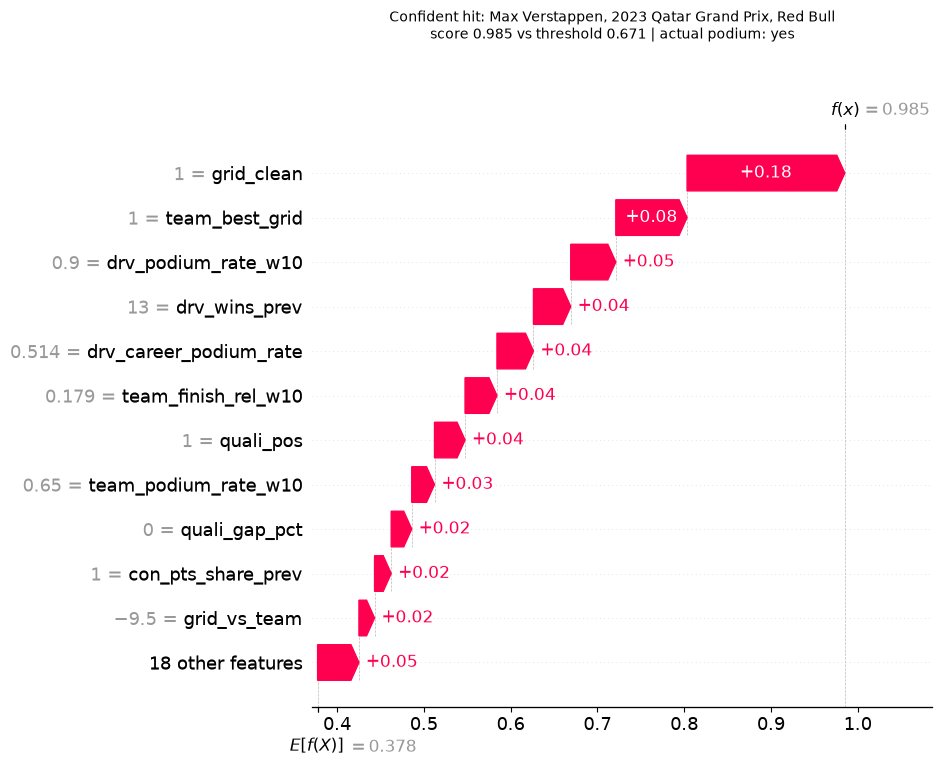

  Confident hit: pushed UP by grid_clean (1: +0.182), team_best_grid (1: +0.082), drv_podium_rate_w10 (0.9: +0.052)
                 pushed DOWN by q1_gap_pct (0: -0.013), season_progress (0.773: -0.006), con_wins_prev (15: -0.004)

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_waterfall_missed_podium.png


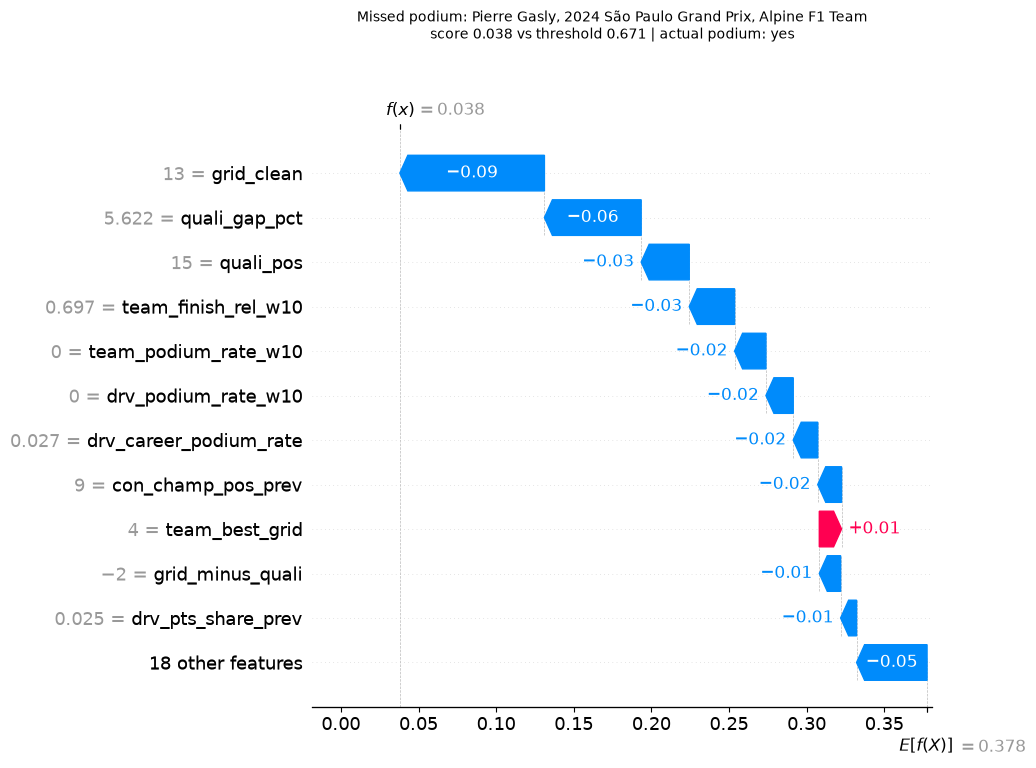

  Missed podium: pushed UP by team_best_grid (4: +0.014), field_size (18: +0.001), drv_career_starts (149: +0.001)
                 pushed DOWN by grid_clean (13: -0.093), quali_gap_pct (5.62: -0.062), quali_pos (15: -0.031)

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_waterfall_false_alarm.png


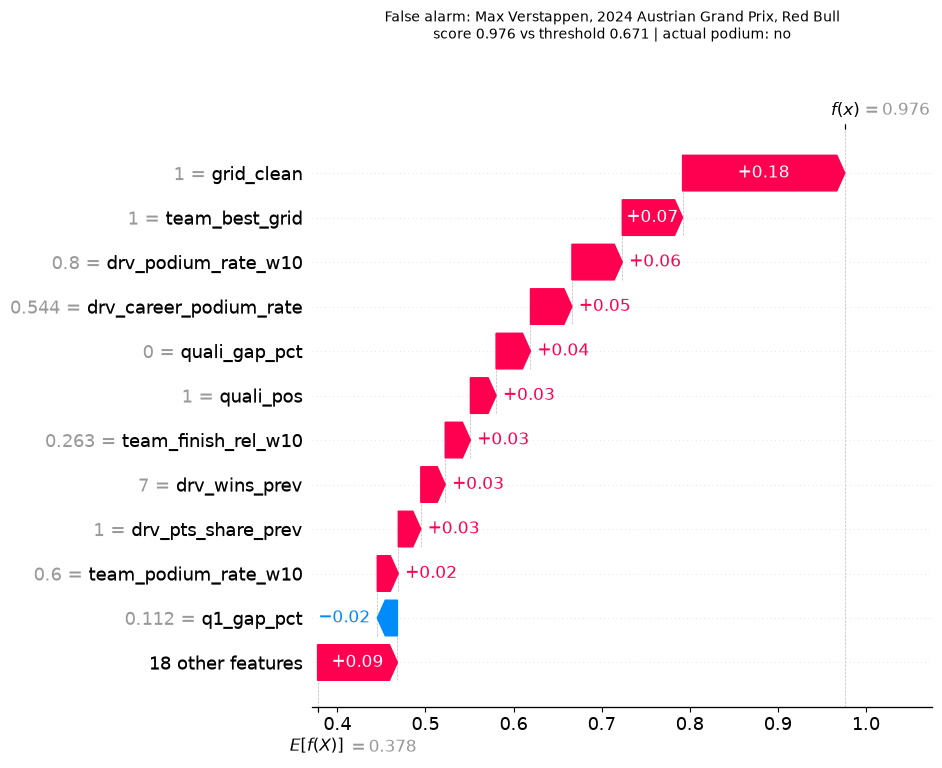

  False alarm: pushed UP by grid_clean (1: +0.184), team_best_grid (1: +0.068), drv_podium_rate_w10 (0.8: +0.057)
               pushed DOWN by q1_gap_pct (0.112: -0.023), circuit_front_row_podium_rate (0.812: -0.003), drv_circuit_prev_starts (11: -0.003)

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_waterfall_borderline.png


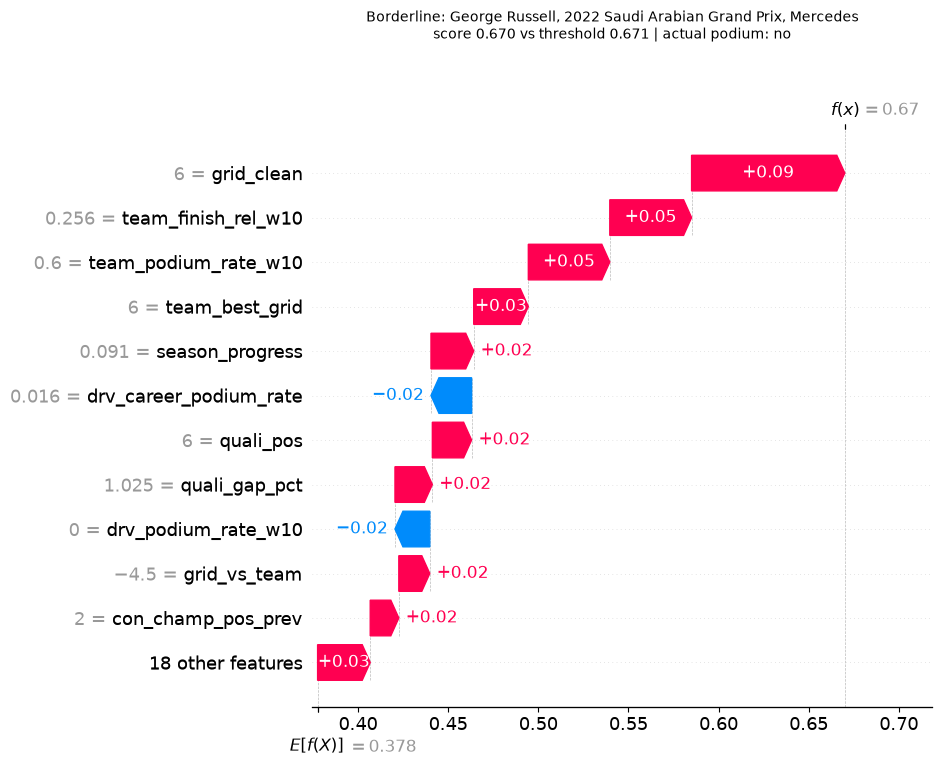

  Borderline: pushed UP by grid_clean (6: +0.085), team_finish_rel_w10 (0.256: +0.045), team_podium_rate_w10 (0.6: +0.045)
              pushed DOWN by drv_career_podium_rate (0.0164: -0.023), drv_podium_rate_w10 (0: -0.019), q1_gap_pct (0.928: -0.013)



In [24]:
# Local SHAP waterfall plot and a text summary for each selected case.
# Shows exactly how one prediction is built from the reference average plus each feature's push,
#    which is the local explanation the task asks for.

# the k largest positive and k most negative contributions of one row (v = SHAP values indexed by feature); also used in 15.7.3
def top_pushes(v, k=3):
    v = pd.Series(v); return v.sort_values(ascending=False).head(k), v.sort_values().head(k)

def shap_top(i, k=3):
    pos, neg = top_pushes(pd.Series(sv.values[i], index=FEATURES), k)
    fmt = lambda s: ", ".join(f"{f} ({ex.loc[i, f]:.3g}: {x:+.3f})" if not pd.isna(ex.loc[i, f]) else f"{f} (missing: {x:+.3f})" for f, x in s.items())
    return fmt(pos), fmt(neg)

for name, i in CASES.items():
    # read bottom-up: reference average, then each feature's push, ending at the model score
    plt.figure(); shap.plots.waterfall(sv[i], max_display=12, show=False); fig = plt.gcf()
    fig.suptitle(f"{name}: {case_label(i)}\nscore {p_ex[i]:.3f} vs threshold {thr:.3f} | actual podium: {'yes' if y_ex[i] else 'no'}", y=1.04, fontsize=10)
    save_fig(fig, f"shap_waterfall_{name.lower().replace(' ', '_')}.png")
    up, down = shap_top(i)
    print(f"  {name}: pushed UP by {up}\n  {' ' * len(name)}  pushed DOWN by {down}\n")

### 6.7.2 LIME

LIME perturbs the row many times (here 5,000), asks the model to score the perturbed rows, and fits a small weighted linear model on *binned* feature values. Its weights say which bins of which features pushed *this* score up or down in the neighbourhood of the row.

Practical differences from SHAP that matter when comparing them:
- LIME cannot take missing values, so the few missing inputs are filled with the training median (binary flags: most frequent value) before it runs. For cases with missing features this slightly changes what is explained; the count is in the case table above.
- LIME is random. The stability check below reruns it with different seeds.
- LIME weights are relative to its own local model, not to the SHAP reference average, so only the **direction and ranking** are compared with SHAP, not the sizes.
- `R2` is the fit of LIME's local model to the explained model around the row. A low value means the model is not well approximated by a simple model there, and the LIME weights should be trusted less.

In [25]:
# Explain the same four cases with LIME and measure its fidelity, stability and agreement with SHAP.
# LIME is the second local method (required by the checklist). Its local R2 and seed stability say
#   how far to trust it, and the comparison with SHAP shows whether the two methods tell the same
#   story.
LIME_RES, LIME_CMP, lime_cmp = {}, [], pd.DataFrame()     # lime_cmp is the one LIME comparison table; the summary and the saved CSV reuse it
if HAVE_LIME:
    # LIME cannot take missing values: fill with the training median (binary flags: most frequent), the pipeline's own imputer rule
    fill = pd.concat([train[CONTINUOUS].median(), train[BINARY].mode().iloc[0]])
    lime_bg = bg_pool[FEATURES].fillna(fill).to_numpy(float)
    # binary flags are categorical for LIME (no binning)
    cat_idx = [FEATURES.index(b) for b in BINARY]
    # discretize_continuous=True makes LIME speak in value bins such as 'quali_pos > 17'
    def lime_run(x, seed):
        le = LimeTabularExplainer(lime_bg, feature_names=FEATURES, categorical_features=cat_idx, class_names=["no podium", "podium"],
                                  mode="classification", discretize_continuous=True, random_state=seed)
        e = le.explain_instance(x, xai_proba, num_features=10, num_samples=LIME_SAMPLES, labels=(1,))
        sc = e.score; sc = sc.get(1) if isinstance(sc, dict) else sc
        return e, float(sc) if sc is not None else np.nan
    t0 = time.time()
    for name, i in CASES.items():
        x = ex.loc[i, FEATURES].fillna(fill).to_numpy(float)
        e, r2 = lime_run(x, SEED)
        m = e.as_map()[1]; desc = dict(zip([a for a, _ in m], [d for d, _ in e.as_list(label=1)]))
        lime_w = pd.Series({FEATURES[a]: w for a, w in m}); lime_desc = {FEATURES[a]: desc[a] for a, _ in m}
        # stability: top-5 features across different LIME seeds
        # stability: repeat LIME with different seeds and compare the top-5 sets (Jaccard overlap)
        tops = [set(lime_w.abs().sort_values(ascending=False).head(5).index)]
        for s in range(1, LIME_SEEDS):
            ws = pd.Series({FEATURES[a]: w for a, w in lime_run(x, SEED + s)[0].as_map()[1]}); tops.append(set(ws.abs().sort_values(ascending=False).head(5).index))
        jac = np.mean([len(a & b) / len(a | b) for a, b in itertools.combinations(tops, 2)])
        shap_v = pd.Series(sv.values[i], index=FEATURES)
        s_top5, l_top5 = set(shap_v.abs().sort_values(ascending=False).head(5).index), set(lime_w.abs().sort_values(ascending=False).head(5).index)
        common = lime_w.index
        LIME_RES[name] = dict(weights=lime_w, desc=lime_desc, r2=r2)
        # fidelity (local R2), overlap with SHAP's top 5, sign agreement and rank correlation on LIME's features
        LIME_CMP.append(dict(case=name, lime_local_R2=r2, top5_overlap_shap_lime=len(s_top5 & l_top5),
                             sign_agreement_on_lime_top10=float(np.mean(np.sign(lime_w[common]) == np.sign(shap_v[common]))),
                             spearman_signed_on_lime_top10=spearmanr(lime_w[common], shap_v[common]).statistic,
                             lime_top5_stability_jaccard=jac))
    print(f"LIME for {len(CASES)} cases x {LIME_SEEDS} seeds in {time.time()-t0:.0f}s")
    lime_cmp = pd.DataFrame(LIME_CMP); display(lime_cmp.round(3))
else:
    print("LIME not installed: skipped. (pip install lime)")

LIME for 4 cases x 5 seeds in 1s


,case,lime_local_R2,top5_overlap_shap_lime,sign_agreement_on_lime_top10,spearman_signed_on_lime_top10,lime_top5_stability_jaccard
0,Confident hit,0.605,3,0.9,0.952,0.867
1,Missed podium,0.268,3,1.0,0.539,0.867
2,False alarm,0.604,3,0.9,0.818,0.867
3,Borderline,0.495,3,0.9,0.855,0.733


Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\local_shap_vs_lime_confident_hit.png


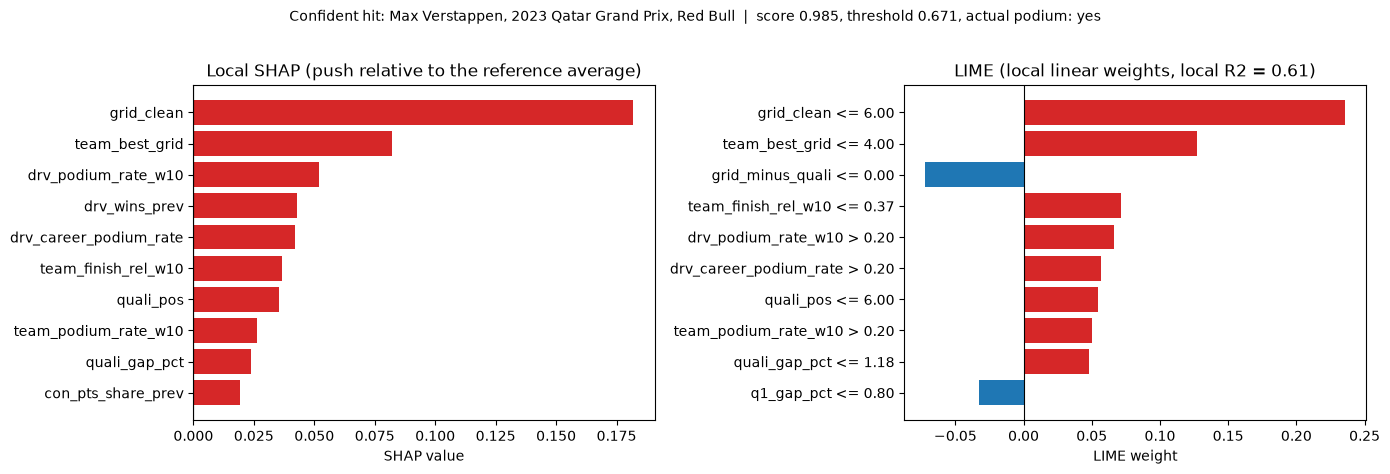

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\local_shap_vs_lime_missed_podium.png


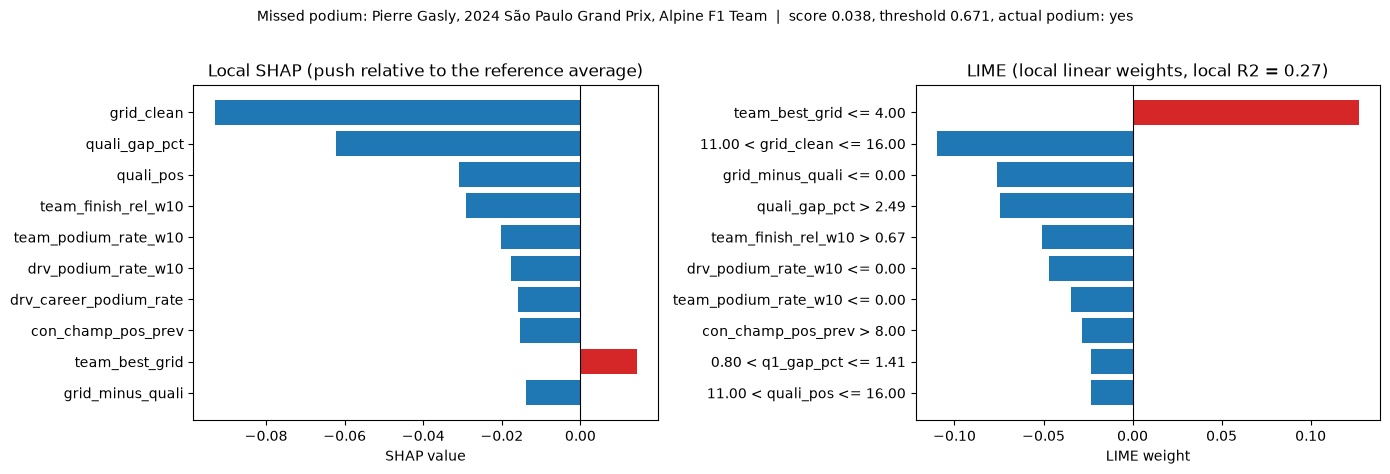

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\local_shap_vs_lime_false_alarm.png


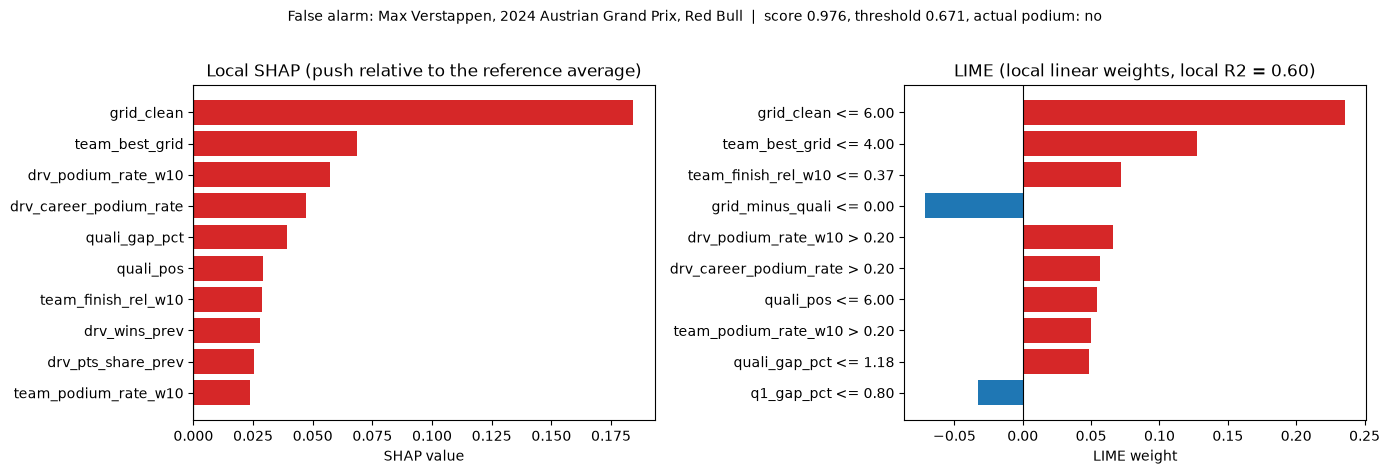

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\local_shap_vs_lime_borderline.png


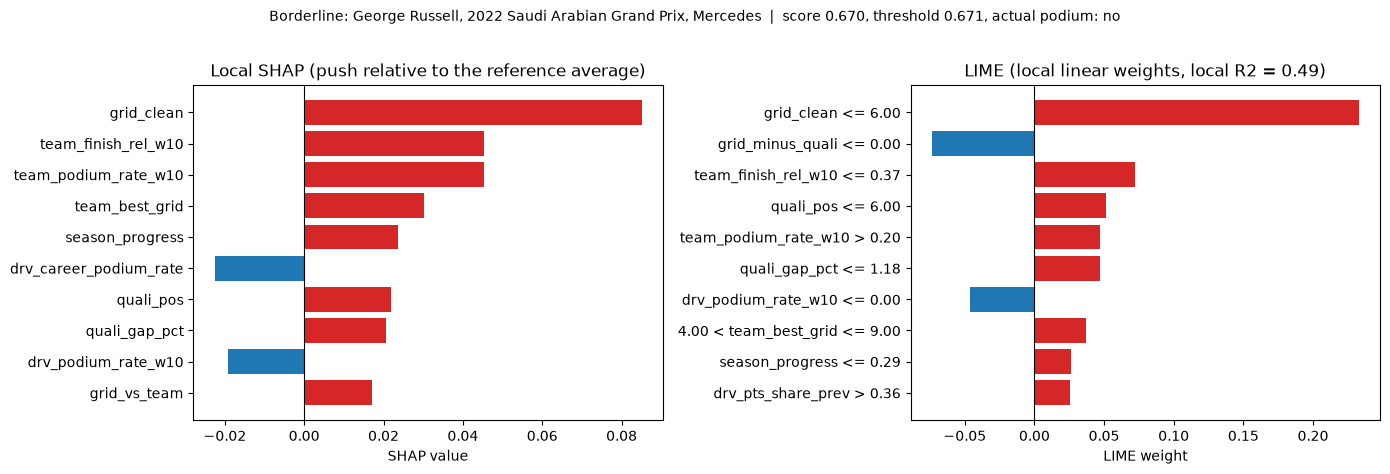

In [26]:
# Plot SHAP and LIME next to each other for each case.
# A visual check of where the two local methods agree and disagree.

# SHAP and LIME side by side for each case (top 10 features of each)
if HAVE_LIME:
    for name, i in CASES.items():
        sv_i = pd.Series(sv.values[i], index=FEATURES); s10 = sv_i.reindex(sv_i.abs().sort_values(ascending=False).head(10).index)[::-1]
        lw = LIME_RES[name]["weights"]; l10 = lw.reindex(lw.abs().sort_values(ascending=False).index)[::-1]
        fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
        axes[0].barh(s10.index, s10.values, color=["tab:red" if v > 0 else "tab:blue" for v in s10.values]); axes[0].axvline(0, color="k", lw=0.8)
        axes[0].set_title("Local SHAP (push relative to the reference average)"); axes[0].set_xlabel("SHAP value")
        axes[1].barh([LIME_RES[name]["desc"][f] for f in l10.index], l10.values, color=["tab:red" if v > 0 else "tab:blue" for v in l10.values]); axes[1].axvline(0, color="k", lw=0.8)
        axes[1].set_title(f"LIME (local linear weights, local R2 = {LIME_RES[name]['r2']:.2f})"); axes[1].set_xlabel("LIME weight")
        fig.suptitle(f"{name}: {case_label(i)}  |  score {p_ex[i]:.3f}, threshold {thr:.3f}, actual podium: {'yes' if y_ex[i] else 'no'}", fontsize=10, y=1.02)
        fig.tight_layout(); save_fig(fig, f"local_shap_vs_lime_{name.lower().replace(' ', '_')}.png")

### 6.7.3 The same four rows under every verified model

Each verified model scores the same driver-race rows. Differences show where models disagree about a row. Pushes are SHAP values in each model's own units, so only the **names and order** of the leading features are comparable.

In [27]:
# Score the same four rows under every verified model and list each model's leading features.
# Shows where models disagree about a row, which is how an input problem (such as an extreme value)
#   shows up: models that standardise inputs react differently from tree models.
rows = []
for name, i in CASES.items():
    for k, m in MODELS.items():
        # the same row scored by every verified model
        sc = float(predict_p(m, ex.iloc[[i]])[0])
        v = pd.Series(sv.values[i], index=FEATURES) if k == EXPLAIN_KEY else (OTHER_SHAP[k]["values"].iloc[i] if k in OTHER_SHAP else None)
        up_s, down_s = top_pushes(v) if v is not None else (None, None)
        up, down = (", ".join(up_s.index), ", ".join(down_s.index)) if v is not None else ("n/a", "n/a")
        rows.append(dict(case=name, row=case_label(i), model=LABEL[k], score=round(sc, 3), threshold=round(THRESHOLD[k], 3), predicts_podium=sc >= THRESHOLD[k],
                         actual_podium=int(y_ex[i]), top3_push_up=up, top3_push_down=down))
CASE_MODELS = pd.DataFrame(rows)
for name in CASES:
    print(f"\n{name}: {case_label(CASES[name])}"); display(CASE_MODELS[CASE_MODELS["case"] == name].drop(columns=["case", "row"]).reset_index(drop=True))


Confident hit: Max Verstappen, 2023 Qatar Grand Prix, Red Bull


,model,score,threshold,predicts_podium,actual_podium,top3_push_up,top3_push_down
0,Logistic regression,0.985,0.671,True,1,"grid_clean, team_best_grid, drv_podium_rate_w10","q1_gap_pct, season_progress, con_wins_prev"
1,Shallow NN,0.984,0.793,True,1,n/a,n/a
2,Random forest,0.972,0.733,True,1,"grid_clean, team_best_grid, drv_podium_rate_w10","season_progress, drv_circuit_prev_starts, grid_minus_quali"
3,XGBoost,0.966,0.798,True,1,"grid_clean, team_best_grid, quali_gap_pct","season_progress, drv_circuit_prev_podiums, pole"



Missed podium: Pierre Gasly, 2024 São Paulo Grand Prix, Alpine F1 Team


,model,score,threshold,predicts_podium,actual_podium,top3_push_up,top3_push_down
0,Logistic regression,0.038,0.671,False,1,"team_best_grid, field_size, drv_career_starts","grid_clean, quali_gap_pct, quali_pos"
1,Shallow NN,0.003,0.793,False,1,n/a,n/a
2,Random forest,0.071,0.733,False,1,"team_best_grid, field_size, drv_career_starts","grid_clean, team_podium_rate_w10, drv_podium_rate_w10"
3,XGBoost,0.031,0.798,False,1,"team_best_grid, field_size, drv_career_starts","grid_clean, team_finish_rel_w10, quali_gap_pct"



False alarm: Max Verstappen, 2024 Austrian Grand Prix, Red Bull


,model,score,threshold,predicts_podium,actual_podium,top3_push_up,top3_push_down
0,Logistic regression,0.976,0.671,True,0,"grid_clean, team_best_grid, drv_podium_rate_w10","q1_gap_pct, circuit_front_row_podium_rate, drv_circuit_prev_starts"
1,Shallow NN,0.983,0.793,True,0,n/a,n/a
2,Random forest,0.974,0.733,True,0,"grid_clean, team_best_grid, drv_podium_rate_w10","circuit_front_row_podium_rate, drv_circuit_prev_starts, season_progress"
3,XGBoost,0.965,0.798,True,0,"grid_clean, team_best_grid, quali_gap_pct","age, drv_circuit_prev_starts, circuit_front_row_podium_rate"



Borderline: George Russell, 2022 Saudi Arabian Grand Prix, Mercedes


,model,score,threshold,predicts_podium,actual_podium,top3_push_up,top3_push_down
0,Logistic regression,0.670,0.671,False,0,"grid_clean, team_finish_rel_w10, team_podium_rate_w10","drv_career_podium_rate, drv_podium_rate_w10, q1_gap_pct"
1,Shallow NN,0.679,0.793,False,0,n/a,n/a
2,Random forest,0.479,0.733,False,0,"grid_clean, team_podium_rate_w10, drv_pts_share_prev","drv_podium_rate_w10, team_best_grid, drv_career_podium_rate"
3,XGBoost,0.517,0.798,False,0,"grid_clean, team_podium_rate_w10, age","drv_career_podium_rate, drv_finish_rel_w10, team_best_grid"


## 6.8 Conclusions (computed from the results above), limitations, saved files

The paragraph printed by the next cell is generated from the tables and checks above, so every number in it matches the figures. Copy it into the report and add the domain reading of the top features yourself (why a front-row start or a strong team record would matter in Formula 1). **It describes the model's behaviour, not causes.**

In [28]:
# Generate the written summary of the results from the computed variables.
# Every number in the text comes from the tables above, so the summary cannot drift from the
#   evidence. Verdict words (agree, robust, stable) come from explicit thresholds shown in the code.

pi_t = PI["test"].sort_values("pr_auc_drop", ascending=False); top3p = pi_t.head(3)
lines = []
ok_models = STATUS[STATUS["verdict"].isin(["PASS", "CLOSE"])]
# provenance line: how each model was obtained and how closely it matched its saved predictions
lines.append("Models analysed (each reproduced its saved validation and test predictions, max difference shown): " + "; ".join(f"{r.model} via {r.obtained_by} ({max(r.val_max_diff, r.test_max_diff):.0e})" for r in ok_models.itertuples())
             + (f". NOT analysed because they could not be reproduced: {', '.join(STATUS[STATUS['verdict'] == 'FAIL']['model'])}." if (STATUS["verdict"] == "FAIL").any() else "."))
lines.append(f"Model explained: {LABEL[EXPLAIN_KEY]} (test PR-AUC {EXPL_SCORE.loc['test', 'pr_auc']:.3f}, validation {EXPL_SCORE.loc['val', 'pr_auc']:.3f}; "
             f"rank {test_rank.index(EXPLAIN_KEY) + 1} of {len(test_rank)} on test PR-AUC among the saved models).")
lines.append("Permutation importance (test): the three features whose shuffling hurts PR-AUC most are "
             + ", ".join(f"{r.feature} ({r.pr_auc_drop:.3f})" for r in top3p.itertuples()) + f". {int(pi_t['reliable'].sum())} of {len(pi_t)} features are reliably used (mean drop above 2 standard deviations); "
             f"the rest could be shuffled without a detectable loss.")
# thresholds: Spearman >= 0.8 close, >= 0.5 partial, otherwise disagree
vt_word = "agree closely" if AG_VT["spearman_top"] >= 0.8 else "agree partly" if AG_VT["spearman_top"] >= 0.5 else "disagree"
lines.append(f"The validation and test rankings {vt_word} (Spearman {AG_VT['spearman_top']:.2f} over the top-10 union, {AG_VT['overlap_top']} of the top 10 shared).")
g1 = GPI["test"].iloc[0]; lines.append(f"By feature group, shuffling '{g1.group}' costs the most PR-AUC ({g1.pr_auc_drop:.3f}); in descending order: " + ", ".join(f"{r.group} ({r.pr_auc_drop:.3f})" for r in GPI["test"].itertuples()) + ".")
lines.append("SHAP (test rows): the largest mean |SHAP| belong to " + ", ".join(f"{r.feature} ({r.mean_abs_shap:.3f}, {r.share_of_total:.0%} of the total)" for r in shap_tab.head(3).itertuples())
             + f". By group the largest is '{group_shap.iloc[0]['group']}' ({group_shap.iloc[0]['share_of_total']:.0%} of total group SHAP).")
ps_word = "rank features similarly" if AG_PS["spearman_top"] >= 0.8 else "agree only partly on the ranking" if AG_PS["spearman_top"] >= 0.5 else "disagree on the ranking"
lines.append(f"Permutation importance and SHAP {ps_word} (Spearman {AG_PS['spearman_top']:.2f} over the top-10 union, {AG_PS['overlap_top']} of the top 10 shared)" + ("." if ps_word == "rank features similarly" else "; a feature ranked much higher by SHAP than by permutation is one the model pushes on without that push improving test accuracy much."))
lines.append(f"The SHAP ranking is {'robust' if BG_MIN_RHO >= 0.85 else 'moderately sensitive' if BG_MIN_RHO >= 0.7 else 'sensitive'} to the reference data (lowest pairwise Spearman across three references: {BG_MIN_RHO:.2f}; robust at 0.85 or above).")
lines.append("Other verified models (permutation importance, test): " + "; ".join(f"{r['model']} top 3 = {r['top3_by_permutation']}" for r in summ) + ".")
if AG_OTHERS:
    lines.append("Exact SHAP on the other models gives rankings that " + "; ".join(f"for {k} {'agree with' if v['spearman_top'] >= 0.8 else 'agree partly with' if v['spearman_top'] >= 0.5 else 'differ from'} {LABEL[EXPLAIN_KEY]} (Spearman {v['spearman_top']:.2f} over the top-10 union, {v['overlap_top']} of the top 10 shared)" for k, v in AG_OTHERS.items()) + ".")
if SEED_AGREE is not None:
    seed42_note = ("(seed 42 reproduces the saved network, so it is not counted twice)" if SEED_REPRODUCED
                   else "(WARNING: the seed-42 retrain did NOT reproduce the saved network in this environment)" if SEED_REPRODUCED is False
                   else "(seed 42 is the saved network's seed; its reproduction could not be checked)")
    lines.append(f"Across the three network seeds 42, 43 and 44 {seed42_note} the permutation rankings have pairwise Spearman between {SEED_AGREE['spearman_top'].min():.2f} and {SEED_AGREE['spearman_top'].max():.2f} over the top-10 union, "
                 f"and share at least {int(SEED_AGREE['overlap_top'].min())} of their top 10 features: a network explanation is {'stable' if SEED_AGREE['spearman_top'].min() >= 0.8 else 'only moderately stable' if SEED_AGREE['spearman_top'].min() >= 0.5 else 'not stable'} across seeds.")
if not lime_cmp.empty:
    lines.append(f"Local: SHAP and LIME share on average {lime_cmp['top5_overlap_shap_lime'].mean():.1f} of their top-5 features across the four cases, agree in sign on {lime_cmp['sign_agreement_on_lime_top10'].mean():.0%} of LIME's top-10 features, "
                 f"LIME's local R2 averages {lime_cmp['lime_local_R2'].mean():.2f} and its top-5 set is {lime_cmp['lime_top5_stability_jaccard'].mean():.0%} stable across seeds (Jaccard).")
# mandatory causal caveat
lines.append("None of these results are causal effects: a feature is important here only in the sense that this fitted model's scores depend on it.")
CONCLUSIONS = "\n\n".join(lines); print(CONCLUSIONS)

Models analysed (each reproduced its saved validation and test predictions, max difference shown): Logistic regression via saved .joblib (6e-16); Shallow NN via saved .joblib (3e-16); Random forest via saved .joblib (4e-16); XGBoost via saved .joblib (2e-09).

Model explained: Logistic regression (test PR-AUC 0.722, validation 0.737; rank 1 of 4 on test PR-AUC among the saved models).

Permutation importance (test): the three features whose shuffling hurts PR-AUC most are grid_clean (0.140), team_best_grid (0.041), quali_pos (0.012). 3 of 29 features are reliably used (mean drop above 2 standard deviations); the rest could be shuffled without a detectable loss.

The validation and test rankings disagree (Spearman 0.42 over the top-10 union, 6 of the top 10 shared).

By feature group, shuffling 'grid' costs the most PR-AUC (0.281); in descending order: grid (0.281), driver_form (0.033), constructor_form (0.024), standings (0.022), qualifying (0.019), context (0.007), circuit_history (-0

### Limitations to state in the report

1. **Not causal.** Importance, SHAP values and LIME weights describe how the fitted model maps inputs to scores. A high-importance feature may be a proxy for something unmeasured (car pace, tyre strategy), and nothing here supports the claim that changing it would change a race result.
2. **Correlated features.** Starting slot, qualifying position, team form and standings carry overlapping information. Single-feature importances split or hide credit; the group-level results are the safer thing to quote.
3. **Unrealistic perturbations.** Permutation importance, permutation SHAP and LIME all evaluate the model on feature combinations that never occur (a pole sitter with an impossible team record). Model behaviour in those regions can be arbitrary, so very small importances should not be over-read.
4. **Reference data and era.** SHAP is relative to a reference population (hybrid-era training rows). The test seasons use new regulations; the model was trained mostly on earlier cars, so explanations describe how an earlier-era model scores new-era rows, not how the new era works.
5. **Scores are not calibrated.** Class up-weighting inflates scores; SHAP magnitudes are in score units.
6. **Seeds.** The final logistic regression is deterministic. The saved network (a compared model) is a single draw; the seed check bounds how much that matters for its explanation, but it is not an interval around the true relationship.
7. **Small test set.** About three seasons of races. Importance differences of a few thousandths of PR-AUC are within the spread shown by the error bars.
8. **LIME** is stochastic, is fitted on binned values, and had its few missing inputs filled; it is shown as a second opinion on individual cases, not as ground truth.
9. **Explaining the final model, not the best test model.** If the final model chosen on validation is not the best on test, say so explicitly; the cross-model analyses in Part 3.2 and Part 6.2 are there so the conclusions do not hang on one model.

### 15.8.1 Data checks suggested by the explanations

The explanations above point at a few specific data questions. They are plain descriptive checks (no model involved) and their output belongs in the limitations section of the report.

1. **Extreme values in `quali_gap_pct`.** Models that standardise inputs (logistic regression, network) can be dominated by one extreme value, tree models cannot. The "missed podium" case is the symptom to check.
2. **Extrapolation.** Cumulative within-season counts (`drv_wins_prev`, `con_wins_prev`) in the test seasons may exceed anything seen in training; a network keeps extrapolating, a tree model flattens.
3. **Rare binary flags.** `home_race` is pushed around in local explanations; check how many rows it rests on.

In [29]:
# Descriptive data checks suggested by the explanations (extreme values, extrapolation, rare flags).
# They test, without any model, whether the oddities seen in the local explanations come from the
#    data. Their output belongs in the limitations section of the report.

print("1) quali_gap_pct by split (percent gap to pole):")
display(mdl.groupby("split")["quali_gap_pct"].describe(percentiles=[.5, .99, .999]).round(3))
# the largest gaps, shown next to q1_gap_pct from the same row so inconsistencies are visible
big = mdl.nlargest(8, "quali_gap_pct")[["raceId", "driverId", "year", "quali_pos", "quali_gap_pct", "q1_gap_pct", "split"]]
print("largest quali_gap_pct values (compare with q1_gap_pct in the same row):"); display(big)
print("2) largest within-season counts per split:")
display(mdl.groupby("split")[["drv_wins_prev", "con_wins_prev", "drv_pts_share_prev"]].max())
# extrapolation check: how much of the test data lies outside the training range
print("   share of test rows above the largest value seen in train:", {c_: round(float((test[c_] > train[c_].max()).mean()), 3) for c_ in ["drv_wins_prev", "con_wins_prev"]})
print("3) home_race support:")
display(mdl.groupby(["split", "home_race"])[TARGET].agg(rows="size", podium_rate="mean").round(3))

1) quali_gap_pct by split (percent gap to pole):


,count,mean,std,min,50%,99%,99.9%,max
split,,,,,,,,
test,1337.0,1.262,1.143,0.0,1.122,4.502,12.322,17.109
train,8150.0,2.198,1.835,0.0,1.826,8.898,15.355,18.681
val,764.0,1.577,1.250,0.0,1.465,5.683,12.161,13.128


largest quali_gap_pct values (compare with q1_gap_pct in the same row):


,raceId,driverId,year,quali_pos,quali_gap_pct,q1_gap_pct,split
20897,955,1,2016,10.0,18.680784,0.553600,train
20984,958,837,2016,22.0,18.099290,18.099290,train
16350,71,27,2005,17.0,17.236050,17.236050,train
24506,1142,1,2024,10.0,17.109368,0.041852,test
16808,57,36,2006,22.0,16.861243,16.861243,train
22194,1018,832,2019,15.0,16.130203,1.012428,train
15761,113,4,2003,19.0,15.853941,15.853941,train
18362,344,812,2010,24.0,15.638630,15.638630,train


2) largest within-season counts per split:


,drv_wins_prev,con_wins_prev,drv_pts_share_prev
split,,,
test,18.0,20.0,1.0
train,13.0,18.0,1.0
val,11.0,13.0,1.0


   share of test rows above the largest value seen in train: {'drv_wins_prev': 0.005, 'con_wins_prev': 0.003}
3) home_race support:


rows  podium_rate
split home_race                    
test  0.0         1309        0.148
      1.0           42        0.238
train 0.0        20576        0.137
      1.0         1865        0.112
val   0.0          749        0.150
      1.0           25        0.200

In [30]:
# Write all tables, SHAP values and the summary.
#
# one helper so every table is written the same way
def save_tab(df, name, index=False):
    p = os.path.join(TAB_DIR, name); df.to_csv(p, index=index); return name
saved = [save_tab(PI_TABLE, "permutation_importance_features.csv"), save_tab(GROUP_PI_TABLE, "permutation_importance_groups.csv"),
         save_tab(cross_mat.reset_index().rename(columns={"index": "feature"}), "permutation_importance_cross_model.csv"),
         save_tab(shap_tab, "shap_global_importance.csv"), save_tab(group_shap, "shap_group_importance.csv"),
         save_tab(cmp.reset_index().rename(columns={"index": "feature"}), "permutation_vs_shap.csv"),
         save_tab(bg_imp.reset_index().rename(columns={"index": "feature"}), "shap_background_sensitivity.csv"),
         save_tab(case_df, "local_cases.csv")]
if SEED_RANK is not None: saved.append(save_tab(SEED_RANK.reset_index().rename(columns={"index": "feature"}), "permutation_importance_seeds.csv"))
if not lime_cmp.empty: saved.append(save_tab(lime_cmp, "local_shap_vs_lime.csv"))
saved += [save_tab(STATUS, "model_verification.csv"), save_tab(OTHER_SHAP_STATUS, "other_models_shap_status.csv"), save_tab(CASE_MODELS, "local_cases_all_models.csv"),
          save_tab(SHAP_CROSS.reset_index().rename(columns={"index": "feature"}), "shap_cross_model.csv")]
# per-model SHAP values for the report appendix
for k_, o_ in OTHER_SHAP.items():
    o_["values"].assign(resultId=ex["resultId"].to_numpy()).to_parquet(os.path.join(TAB_DIR, f"shap_values_test_{k_}.parquet"), index=False); saved.append(f"shap_values_test_{k_}.parquet")
shap_df = pd.DataFrame(sv.values, columns=FEATURES); shap_df.insert(0, "resultId", ex["resultId"].to_numpy()); shap_df["base_value"] = sv.base_values; shap_df["model_score"] = p_ex
shap_df.to_parquet(os.path.join(TAB_DIR, "shap_values_test.parquet"), index=False); saved.append("shap_values_test.parquet")
# machine-readable summary including the model-verification table
json.dump(dict(explained_model=EXPLAIN_KEY, label=LABEL[EXPLAIN_KEY], threshold=thr, reference_rows=len(bg_df), shap_permutations=N_PERMUTATIONS,
               additivity_max_error=add_err, base_value=base_val, model_verification=STATUS.drop(columns="attempts").to_dict("records"), conclusions=CONCLUSIONS.split("\n\n")), open(os.path.join(TAB_DIR, "xai_summary.json"), "w"), indent=2)
saved.append("xai_summary.json")
print("tables saved to", TAB_DIR, "->", saved)
print("figures saved to", FIG_DIR, "->", sorted(os.listdir(FIG_DIR)))

tables saved to a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\xai_outputs -> ['permutation_importance_features.csv', 'permutation_importance_groups.csv', 'permutation_importance_cross_model.csv', 'shap_global_importance.csv', 'shap_group_importance.csv', 'permutation_vs_shap.csv', 'shap_background_sensitivity.csv', 'local_cases.csv', 'local_shap_vs_lime.csv', 'model_verification.csv', 'other_models_shap_status.csv', 'local_cases_all_models.csv', 'shap_cross_model.csv', 'shap_values_test_rf.parquet', 'shap_values_test_xgb.parquet', 'shap_values_test.parquet', 'xai_summary.json']
figures saved to a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai -> ['local_shap_vs_lime_borderline.png', 'local_shap_vs_lime_confident_hit.png', 'local_shap_vs_lime_false_alarm.png', 'local_shap_vs_lime_missed_podium.png', 'perm_importance_cross_model.png', 'perm_importance_groups.png', 'perm_importance_seeds.png', 'perm_importance_val_